# Detecting Kunitz domains with a structure-derived profile HMM

Author: Elham Hadadi · Laboratory of Bioinformatics I




## 1. Aim and biological background

The aim was to build a profile hidden Markov model (HMM) from structural information and use it to identify Kunitz-related domains in Swiss-Prot protein sequences. A domain is a structural unit within a protein; proteins may contain several domains. Bovine pancreatic trypsin inhibitor (BPTI) is a classic Kunitz example. Family membership alone does not establish protease-inhibitory activity.

The introductory structure, 3TGI, contains trypsin in author chain E and BPTI in author chain I. Identifying the correct chain and domain interval prevents using an enzyme or a whole multidomain protein as an interchangeable domain example.



## 2. Data and structural seed selection

PDB entities annotated with Pfam PF00014 supplied structural candidates: 165 entities from 162 entries. Pfam positional annotations defined candidate domain intervals. One missing interval was transferred from identical complete sequences with matching annotated ranges; unresolved intervals were not guessed.

Selection considered coordinate completeness, experimental method, reported mutations and redundancy. The initial length review band was 45–65 residues. X-ray candidates required resolution at most 2.5 Å. NMR coordinate coverage was checked across models, and model 1 represented each selected NMR structure. These are project choices, not universal family definitions. Metadata checks were followed by manual review; absence of a mutation label does not prove a natural sequence.

After sequence redundancy reduction at 90% identity and final manual review, the seed contained 13 domain fragments from 10 UniProt accessions: 10 X-ray and 3 NMR examples. Distinct domains from the same protein could remain. Twelve fragments had 53 residues and one had 52. Extracted annotated segments need not cover every terminal residue of the biological domain.



## 3. Structural alignment and model construction

MUSTANG aligned the coordinate fragments. Removing alignment gaps reproduced each input sequence, supporting correct extraction and conversion. The alignment had 53 columns and was converted to Stockholm format for HMMER `hmmbuild`.

The HMM had 53 match states. A profile HMM describes position-specific amino-acid preferences and insertion/deletion possibilities. Structure guided the training alignment; subsequent searches used amino-acid sequences. All 13 training fragments were retrieved by `hmmsearch`. This was a training consistency check, not independent evidence of accuracy.



## 4. Evaluation design

Evaluation candidates were reviewed, nonfragment Swiss-Prot proteins. PF00014 annotation defined the reference-positive class; its absence defined the operational negative class. Missing annotation does not prove biological absence.

Of 368 initial positives, 15 were excluded by the union of training-accession overlap and exact training-fragment matches. Five more met the close-training rule: at least 90% identity and at least 90% seed coverage in the local comparison. This left 348 positives. From 566,072 negative candidates, 3,480 were sampled with random seed 42, giving a 10:1 negative-to-positive ratio. Sampling was not length-matched and does not represent the full database's class prevalence.

Exact duplicates and local matches at at least 80% identity over at least 40 paired standard-residue positions were connected into groups before splitting. Groups remained intact. Validation and test each contained 174 positives and 1,740 negatives, without shared accessions, exact sequences or defined similarity groups. More distant homologs may still occur across the split.

| Dataset or model | Size |
|---|---:|
| Structural training seed | 13 fragments / 10 accessions |
| HMM | 53 match states |
| Validation | 174 positive + 1,740 negative proteins |
| Held-out test | 174 positive + 1,740 negative proteins |
| Full Swiss-Prot scan | 575,748 proteins |



## 5. Decision rule and held-out results

A protein was predicted positive if its highest reported domain bit score was at least the fixed threshold. Proteins without a reported domain were negative. Domain scores permit detecting a localized match within a longer protein. Search settings, including `--max`, were consistent across validation, test and the full scan; a reported hit was not automatically a positive prediction.

The threshold was chosen using validation only. The highest negative score was 6.1 bits and the lowest positive score was 11.3 bits. The threshold-selection procedure maximized validation MCC and chose the midpoint of the separating optimal interval (6.1, 11.3], yielding 8.7 bits. The threshold remained unchanged for test and full-database prediction.

| Held-out reference class | Predicted negative | Predicted positive |
|---|---:|---:|
| Negative | 1,740 | 0 |
| Positive | 0 | 174 |

Sensitivity (TP/(TP+FN)), specificity (TN/(TN+FP)) and precision (TP/(TP+FP)) were all 1.0 in this test. Other recorded metrics are retained in the computational appendix. The result describes the constructed benchmark, not universal accuracy. Random negatives, annotation-based labels and residual evolutionary relationships limit generalization.



## 6. Full-database predictions and annotation differences

Applying the same model and 8.7-bit rule to Swiss-Prot identified 426 proteins with 514 domains above threshold; 53 proteins had multiple above-threshold domains. This scan included training and evaluation proteins and was an application of the model, not another independent test.

All 398 PF00014-annotated proteins in the complete reference were detected. This reference included 30 fragments excluded from the initial 368-protein evaluation query. Another 28 predictions lacked PF00014. The fraction 398/426 = 93.43% measures annotation agreement, not definitive biological precision.

| Review of the 28 predictions without PF00014 | Count |
|---|---:|
| Kunitz-supported fragments | 12 |
| Other predictions with supporting Kunitz evidence | 9 |
| Suspected false positives | 6 |
| Unresolved fragment | 1 |

Review used score, model-span coverage, sequence length and UniProt evidence. Partial matches can correspond to real fragments or spurious similarities. Supporting annotations are not new experimental confirmation. None of these 28 accessions or exact full sequences occurred in the evaluation set. The review did not change predictions, test labels or the threshold.



## 7. Distribution of predictions

| Descriptive taxonomic bin | Predicted proteins |
|---|---:|
| Vertebrates | 227 |
| Arthropods | 111 |
| Cnidarians | 59 |
| Other metazoans | 17 |
| Nematodes | 7 |
| Fungi | 3 |
| Bacteria | 2 |

These are mutually exclusive descriptive bins, not equal taxonomic ranks. All 398 PF00014-supported predictions were in metazoan bins. Fungal and bacterial predictions were in the annotation-discordant group and do not establish confirmed family expansion. Database sampling and curation affect the counts, which are not natural-prevalence estimates. Of 426 predictions, 43 carried an explicit fragment flag: 30 with PF00014 and 13 without it.



## 8. Conclusion and limits

The structure-derived HMM recovered all positives in the held-out benchmark and all PF00014-annotated entries in the scanned release. Interpretation of additional predictions required further annotation evidence.

The main limits are a small, unevenly sampled structural seed; annotation-dependent reference labels; sampled negatives; a similarity rule that does not remove all homologous relationships; and acceptance of short local matches. The model predicts family similarity, not biochemical activity or experimentally verified domain boundaries. Additional RMSD and similarity diagnostics are preserved in the appendix without making stronger accuracy claims.



## Resources and reproducibility

Sources: [RCSB PDB](https://www.rcsb.org/), [UniProtKB](https://www.uniprot.org/), and the supplied project brief. Software: Biopython, MUSTANG 3.2.4, HMMER 3.4 and MMseqs2 15-6f452+ds-2. MUSTANG reference: Konagurthu AS et al. Proteins. 2006;64(3):559–574.

The notebook appendix retains all original code cells in their original order, saved outputs and detailed decision records. It is the source for exact extraction, grouping and search procedures. This concise report replaces the presentation narrative only. Rerunning the old report-generation cells regenerates their original, more detailed report; use this summary for the simplified presentation.


# Appendix — full reproducible analysis

The concise account above is the main presentation. This appendix preserves the complete computational workflow, recorded outputs, selection history and supplementary diagnostics. Code order and scientific results have not changed. Detailed material is retained for traceability; statements used in the presentation must still be understood.

Use the triangle beside this heading to collapse the appendix. To rerun the analysis, execute its code cells in their existing order. Colab runtime files may need to be restored from the verified Drive backup. The previous report-generation cells produce the original detailed text.


## Structure-based detection of Kunitz domains with a profile HMM

**Author:** Elham Hadadi  
**Course:** Laboratory of Bioinformatics I  
**Database snapshot:** UniProtKB/Swiss-Prot 2026_03

### Research question

Can a profile hidden Markov model built from structurally aligned Kunitz domains identify members of this family in protein sequences and support annotation of Swiss-Prot?

The project starts from experimentally determined structures, selects representative domain fragments, aligns them with MUSTANG, and builds a sequence profile with HMMER. A validation set determines the decision threshold; a held-out test set evaluates the fixed rule. The same model and rule are then applied to the complete Swiss-Prot database.

### Main findings

| Analysis | Recorded result |
|---|---|
| Structural seed | 13 fragments, representing 10 UniProt accessions |
| Structural alignment / HMM | 53 alignment columns / 53 match states |
| Classification rule | Best domain bit score ≥ 8.7 |
| Held-out test | 174 true positives, 1,740 true negatives, 0 false positives, 0 false negatives |
| Complete Swiss-Prot scan | 426 predicted proteins among 575,748 entries |
| PF00014 annotation comparison | All 398 annotated proteins detected; 28 additional predictions |
| Review of the 28 additional predictions | 21 with supporting Kunitz evidence, 6 suspected false positives, 1 unresolved fragment |

The perfect test result describes the sampled benchmark, not universal accuracy. Full-database predictions require biological interpretation: domain-family detection does not establish inhibitory activity, and absence of a Pfam annotation does not by itself establish a false positive.

### Notebook organization

1. Inspect the example structure and curate structural candidates.
2. Select representative fragments and construct a structural alignment.
3. Build the profile HMM and check training consistency.
4. Prepare grouped validation and test data.
5. Select a threshold and evaluate the held-out test set.
6. Scan Swiss-Prot and investigate annotation differences.
7. Examine similarity-related limitations and taxonomic distribution.

Explanatory cells describe the recorded analysis; executable cells and their outputs provide the underlying details. The original STEP identifiers are retained for traceability. Run code cells in notebook order in Google Colab; the Google Drive backup cells require a connected Drive account. Files under `/content` are temporary, so preserve generated artifacts and save the notebook separately. Counts below refer to the recorded database snapshot and may change with a later release.

### 1. Inspecting the example structure: 3TGI

The first example establishes which chain belongs to the target family and how sequence positions map to coordinates. Structure 3TGI contains trypsin (author chain E) and bovine pancreatic trypsin inhibitor, BPTI (author chain I). The registered BPTI entity sequence has 65 residues, while the extracted observed protein coordinates contain 56 residues.

These are different representations of the same deposited entity: registered sequence length is not a guarantee of coordinate coverage. Author chain identifiers and mmCIF label identifiers also differ; for this BPTI entity, author I corresponds to label B. Explicit mapping prevents extracting the enzyme or assigning coordinates to the wrong sequence positions.

The initial PDB and FASTA exports are checked by reading the saved structure back and comparing its sequence. This establishes a validated extraction procedure before processing the larger candidate set.

In [86]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import requests

# Create the project directory
PROJECT_DIR = Path("/content/kunitz_project")
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Select the example structure from the project brief
pdb_id = "3TGI"
url = f"https://files.rcsb.org/download/{pdb_id}.cif"
structure_path = RAW_DIR / f"{pdb_id}.cif"

# Download the structure from RCSB PDB
response = requests.get(url, timeout=60)
response.raise_for_status()

# Check that the response contains the expected mmCIF data block
content = response.content
text = content.decode("utf-8")

if not text.lstrip().lower().startswith(f"data_{pdb_id.lower()}"):
    raise ValueError("The response does not match the expected structure file.")

# Check for atomic coordinate records
if "_atom_site." not in text:
    raise ValueError("No atomic coordinate records were found.")

structure_path.write_bytes(content)

# Record download provenance for reproducibility
metadata = {
    "pdb_id": pdb_id,
    "source_url": url,
    "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
    "format": "mmCIF",
    "size_bytes": len(content),
    "sha256": hashlib.sha256(content).hexdigest(),
}

metadata_path = RAW_DIR / f"{pdb_id}_download.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Download and basic checks: OK")
print(f"File: {structure_path}")
print(f"Size: {len(content):,} bytes")
print(f"Metadata: {metadata_path}")
print("\nFirst 5 lines:")
print("\n".join(text.splitlines()[:5]))

Download and basic checks: OK
File: /content/kunitz_project/data/raw/3TGI.cif
Size: 298,833 bytes
Metadata: /content/kunitz_project/data/raw/3TGI_download.json

First 5 lines:
data_3TGI
# 
_entry.id   3TGI 
# 
_audit_conform.dict_name       mmcif_pdbx.dic 


In [87]:
%pip -q install biopython

In [88]:
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
import Bio
import pandas as pd
from IPython.display import display

# Read the downloaded mmCIF file
cif = MMCIF2Dict(str(structure_path))

# Map entity identifiers to molecule descriptions
entity_descriptions = dict(
    zip(
        cif["_entity.id"],
        cif["_entity.pdbx_description"],
    )
)

# Extract polymer information
entity_ids = cif["_entity_poly.entity_id"]
polymer_types = cif["_entity_poly.type"]
author_chain_ids = cif["_entity_poly.pdbx_strand_id"]
sequences = cif["_entity_poly.pdbx_seq_one_letter_code_can"]

# Build a summary of protein entities
rows = []

for entity_id, polymer_type, chain_ids, sequence in zip(
    entity_ids, polymer_types, author_chain_ids, sequences
):
    if polymer_type != "polypeptide(L)":
        continue

    sequence = "".join(sequence.split())

    rows.append({
        "entity_id": entity_id,
        "author_chain_ids": chain_ids,
        "description": entity_descriptions.get(entity_id, "Unknown"),
        "sequence_length": len(sequence),
        "sequence": sequence,
    })

if not rows:
    raise ValueError("No protein entities were found in the structure file.")

protein_summary = pd.DataFrame(rows)

# Save the summary for later documentation
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

summary_path = PROCESSED_DIR / "3TGI_protein_entities.csv"
protein_summary.to_csv(summary_path, index=False)

print(f"Biopython version: {Bio.__version__}")
print(f"Structure: {cif['_entry.id'][0]}")
print(f"Protein entities: {len(protein_summary)}")
print(f"Summary saved to: {summary_path}")

display(protein_summary.drop(columns="sequence"))

# Print each sequence separately for readability
for row in rows:
    print(
        f"\n>3TGI | Entity {row['entity_id']} "
        f"| Author chains: {row['author_chain_ids']} "
        f"| {row['description']}"
    )
    print(row["sequence"])

Biopython version: 1.88
Structure: 3TGI
Protein entities: 2
Summary saved to: /content/kunitz_project/data/processed/3TGI_protein_entities.csv


,entity_id,author_chain_ids,description,sequence_length
0,1,E,TRYPSIN,223
1,2,I,BOVINE PANCREATIC TRYPSIN INHIBITOR,65



>3TGI | Entity 1 | Author chains: E | TRYPSIN
IVGGYTCQENSVPYQVSLNSGYHFCGGSLINDQWVVSAAHCYKSRIQVRLGEHNINVLEGNEQFVNAAKIIKHPNFDRKTLNNDIMLIKLSSPVKLNARVATVALPSSCAPAGTQCLISGWGNTLSSGVNEPDLLQCLDAPLLPQADCEASYPGKITDNMVCVGFLEGGKDSCQGDSGGPVVCNGELQGIVSWGYGCALPDNPGVYTKVCNYVDWIQDTIAAN

>3TGI | Entity 2 | Author chains: I | BOVINE PANCREATIC TRYPSIN INHIBITOR
RPDFCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNFKSAEDCMRTCGGAIGPWENL


In [89]:
# Select the BPTI entity using its author chain identifier
target_chain = "I"

target_rows = protein_summary[
    protein_summary["author_chain_ids"].apply(
        lambda value: target_chain in [
            chain.strip() for chain in value.split(",")
        ]
    )
]

if len(target_rows) != 1:
    raise ValueError("Expected exactly one protein entity for chain I.")

target_entity_id = str(target_rows.iloc[0]["entity_id"])
registered_sequence = target_rows.iloc[0]["sequence"]

# Read atom-level identifiers
atom_fields = {
    "entity_id": "_atom_site.label_entity_id",
    "author_chain": "_atom_site.auth_asym_id",
    "label_chain": "_atom_site.label_asym_id",
    "sequence_position": "_atom_site.label_seq_id",
    "author_residue_number": "_atom_site.auth_seq_id",
    "insertion_code": "_atom_site.pdbx_PDB_ins_code",
    "residue_name": "_atom_site.label_comp_id",
    "model": "_atom_site.pdbx_PDB_model_num",
}

atoms = pd.DataFrame({
    name: cif[field]
    for name, field in atom_fields.items()
})

# Use the first model and retain residues mapped to the polymer sequence
first_model = atoms["model"].iloc[0]

target_atoms = atoms[
    (atoms["entity_id"] == target_entity_id)
    & (atoms["author_chain"] == target_chain)
    & (atoms["model"] == first_model)
    & (~atoms["sequence_position"].isin([".", "?"]))
].copy()

if target_atoms.empty:
    raise ValueError("No mapped atomic coordinates were found for chain I.")

target_atoms["sequence_position"] = (
    target_atoms["sequence_position"].astype(int)
)

# Collapse atom records into unique residue records
residue_columns = [
    "label_chain",
    "sequence_position",
    "author_residue_number",
    "insertion_code",
    "residue_name",
]

observed_residues = (
    target_atoms[residue_columns]
    .drop_duplicates()
    .sort_values(["sequence_position", "residue_name"])
    .reset_index(drop=True)
)

observed_positions = set(observed_residues["sequence_position"])
expected_positions = set(range(1, len(registered_sequence) + 1))

if not observed_positions.issubset(expected_positions):
    raise ValueError("Observed positions fall outside the registered sequence.")

missing_positions = sorted(expected_positions - observed_positions)

# Report sequence positions without coordinate records
missing_table = pd.DataFrame(
    [
        {
            "sequence_position": position,
            "amino_acid": registered_sequence[position - 1],
        }
        for position in missing_positions
    ],
    columns=["sequence_position", "amino_acid"],
)

print(f"Author chain: {target_chain}")
print(f"Model inspected: {first_model}")
print(f"Registered sequence length: {len(registered_sequence)}")
print(f"Positions with coordinate records: {len(observed_positions)}")
print(f"Positions without coordinate records: {len(missing_positions)}")

print("\nObserved residues:")
display(observed_residues)

print("\nSequence positions without coordinate records:")
display(missing_table)

# Inspect the deposited missing-residue annotation, if available
category = "_pdbx_unobs_or_zero_occ_residues."
annotation_fields = [
    key for key in cif
    if key.startswith(category)
]

if annotation_fields:
    annotations = pd.DataFrame({
        key.removeprefix(category): cif[key]
        for key in annotation_fields
    })

    if "auth_asym_id" in annotations.columns:
        annotations = annotations[
            annotations["auth_asym_id"] == target_chain
        ]

    print("\nDeposited unobserved or zero-occupancy residue annotations:")
    display(annotations)
else:
    print("\nNo unobserved-residue annotation category was found.")

# Save the coordinate coverage tables
observed_residues.to_csv(
    PROCESSED_DIR / "3TGI_chain_I_observed_residues.csv",
    index=False,
)

missing_table.to_csv(
    PROCESSED_DIR / "3TGI_chain_I_positions_without_coordinates.csv",
    index=False,
)

Author chain: I
Model inspected: 1
Registered sequence length: 65
Positions with coordinate records: 56
Positions without coordinate records: 9

Observed residues:


,label_chain,sequence_position,author_residue_number,insertion_code,residue_name
0,B,1,1,?,ARG
1,B,2,2,?,PRO
2,B,3,3,?,ASP
3,B,4,4,?,PHE
4,B,5,5,?,CYS
5,B,6,6,?,LEU
6,B,7,7,?,GLU
7,B,8,8,?,PRO
8,B,9,9,?,PRO
9,B,10,10,?,TYR



Sequence positions without coordinate records:


,sequence_position,amino_acid
0,57,G
1,58,A
2,59,I
3,60,G
4,61,P
5,62,W
6,63,E
7,64,N
8,65,L



Deposited unobserved or zero-occupancy residue annotations:


,id,PDB_model_num,polymer_flag,occupancy_flag,auth_asym_id,auth_comp_id,auth_seq_id,PDB_ins_code,label_asym_id,label_comp_id,label_seq_id
0,1,1,Y,1,I,GLY,57,?,B,GLY,57
1,2,1,Y,1,I,ALA,58,?,B,ALA,58
2,3,1,Y,1,I,ILE,59,?,B,ILE,59
3,4,1,Y,1,I,GLY,60,?,B,GLY,60
4,5,1,Y,1,I,PRO,61,?,B,PRO,61
5,6,1,Y,1,I,TRP,62,?,B,TRP,62
6,7,1,Y,1,I,GLU,63,?,B,GLU,63
7,8,1,Y,1,I,ASN,64,?,B,ASN,64
8,9,1,Y,1,I,LEU,65,?,B,LEU,65


In [90]:
from Bio.PDB import MMCIFParser, PDBIO, Select, PDBParser
from Bio.SeqUtils import seq1

# Read the structure using author chain and residue identifiers
parser = MMCIFParser(
    QUIET=True,
    auth_chains=True,
    auth_residues=True,
)
structure = parser.get_structure("3TGI", str(structure_path))
model = next(structure.get_models())
chain = model["I"]

# Select standard amino acid residues, excluding water and ligands
protein_residues = [
    residue for residue in chain.get_residues()
    if residue.id[0] == " "
]

if not protein_residues:
    raise ValueError("No standard protein residues were found in chain I.")

# Verify residue identities against the registered sequence
expected_residues = {}

for row in observed_residues.itertuples(index=False):
    insertion_code = (
        " " if row.insertion_code in {".", "?"}
        else row.insertion_code
    )
    key = (int(row.author_residue_number), insertion_code)
    expected_residues[key] = registered_sequence[
        int(row.sequence_position) - 1
    ]

if len(expected_residues) != len(observed_residues):
    raise ValueError("Ambiguous residue mapping requires inspection.")

actual_keys = {
    (residue.id[1], residue.id[2])
    for residue in protein_residues
}

if actual_keys != set(expected_residues):
    raise ValueError("Parsed residues do not match the coordinate summary.")

for residue in protein_residues:
    key = (residue.id[1], residue.id[2])
    amino_acid = seq1(residue.resname, undef_code="X")

    if amino_acid != expected_residues[key]:
        raise ValueError(f"Sequence mismatch at residue {key}.")

coordinate_sequence = "".join(
    seq1(residue.resname, undef_code="X")
    for residue in protein_residues
)

# Save only the selected protein residues
selected_ids = {residue.id for residue in protein_residues}

class ProteinResidueSelect(Select):
    def accept_residue(self, residue):
        return int(residue.id in selected_ids)

pdb_path = PROCESSED_DIR / "3TGI_chain_I_observed.pdb"

writer = PDBIO()
writer.set_structure(chain)
writer.save(str(pdb_path), ProteinResidueSelect())

# Save the sequence represented by the extracted coordinates
fasta_path = PROCESSED_DIR / "3TGI_chain_I_observed.fasta"
fasta_path.write_text(
    ">3TGI_chain_I_observed author_residues=1-56\n"
    + coordinate_sequence
    + "\n",
    encoding="utf-8",
)

# Reopen the exported structure and verify its sequence
saved_structure = PDBParser(QUIET=True).get_structure(
    "saved", str(pdb_path)
)
saved_sequence = "".join(
    seq1(residue.resname, undef_code="X")
    for residue in saved_structure.get_residues()
    if residue.id[0] == " "
)

if saved_sequence != coordinate_sequence:
    raise ValueError("The exported structure failed sequence verification.")

print("Residue mapping and export checks: OK")
print(f"Extracted residues: {len(protein_residues)}")
print(f"Sequence: {coordinate_sequence}")
print(f"Structure saved to: {pdb_path}")
print(f"Sequence saved to: {fasta_path}")

Residue mapping and export checks: OK
Extracted residues: 56
Sequence: RPDFCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNFKSAEDCMRTCG
Structure saved to: /content/kunitz_project/data/processed/3TGI_chain_I_observed.pdb
Sequence saved to: /content/kunitz_project/data/processed/3TGI_chain_I_observed.fasta


### 2. Collecting and mapping structural candidates

The structural search uses the Pfam identifier **PF00014** to retrieve candidate Kunitz entities. It returned **165 protein entities from 162 PDB entries**, containing **92 distinct full-length sequence strings**. An entity is a deposited molecular sequence; one entity may occur in several chains, and one protein may contain multiple domains.

Whole protein chains cannot be treated as interchangeable domain examples. Candidate lengths range from 26 to 421 residues. Positional annotations therefore define the segments to inspect, rather than trimming every protein to an arbitrary common length.

For 3TGI_2, the PF00014 interval is **4–56**, giving a 53-residue fragment. Most annotated intervals are of similar length, but truncated segments and multidomain proteins are retained for explicit review rather than silently treated as equivalent.

In [91]:
import requests
import json
import pandas as pd
from datetime import datetime, timezone

# Search experimentally determined PDB entities annotated with PF00014
search_url = "https://search.rcsb.org/rcsbsearch/v2/query"

query = {
    "query": {
        "type": "terminal",
        "service": "text",
        "parameters": {
            "attribute": "rcsb_polymer_entity_annotation.annotation_id",
            "operator": "exact_match",
            "value": "PF00014",
        },
    },
    "return_type": "polymer_entity",
    "request_options": {
        "return_all_hits": True,
        "results_content_type": ["experimental"],
    },
}

# Submit the search request
response = requests.post(
    search_url,
    json=query,
    timeout=120,
)

# Include the server response if the request fails
if not response.ok:
    raise RuntimeError(
        f"RCSB search failed with HTTP {response.status_code}:\n"
        f"{response.text[:2000]}"
    )

if response.status_code == 204:
    raise ValueError("The search returned no matching entities.")

result = response.json()
hits = result.get("result_set", [])

if not hits:
    raise ValueError("No candidate entities were returned.")

# Check that the complete result set was retrieved
reported_total = result.get("total_count")

if reported_total is None or len(hits) != reported_total:
    raise ValueError(
        f"Incomplete results: received {len(hits)}, "
        f"reported total {reported_total}."
    )

# Split each identifier into its PDB ID and entity ID
rows = []

for hit in hits:
    identifier = hit["identifier"]
    entry_id, entity_id = identifier.rsplit("_", 1)

    rows.append({
        "pdb_id": entry_id,
        "entity_id": entity_id,
        "entity_identifier": identifier,
        "selection_basis": "Pfam PF00014",
    })

candidates = (
    pd.DataFrame(rows)
    .sort_values(["pdb_id", "entity_id"])
    .reset_index(drop=True)
)

if candidates["entity_identifier"].duplicated().any():
    raise ValueError("Duplicate entity identifiers were returned.")

# Save the query, original response, and retrieval metadata
search_record = {
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_url": search_url,
    "query": query,
    "response": result,
}

search_path = RAW_DIR / "PF00014_pdb_search.json"
search_path.write_text(
    json.dumps(search_record, indent=2),
    encoding="utf-8",
)

# Save the candidate table
candidate_path = PROCESSED_DIR / "PF00014_candidate_entities.csv"
candidates.to_csv(candidate_path, index=False)

print("Candidate search and completeness check: OK")
print(f"Candidate protein entities: {len(candidates)}")
print(f"Distinct PDB entries: {candidates['pdb_id'].nunique()}")
print(
    "Example entity 3TGI_2 present:",
    "3TGI_2" in set(candidates["entity_identifier"]),
)
print(f"Candidate table saved to: {candidate_path}")
print(f"Search provenance saved to: {search_path}")

print("\nFirst 10 candidates:")
print(candidates.head(10).to_string(index=False))

Candidate search and completeness check: OK
Candidate protein entities: 165
Distinct PDB entries: 162
Example entity 3TGI_2 present: True
Candidate table saved to: /content/kunitz_project/data/processed/PF00014_candidate_entities.csv
Search provenance saved to: /content/kunitz_project/data/raw/PF00014_pdb_search.json

First 10 candidates:
pdb_id entity_id entity_identifier selection_basis
  1AAL         1            1AAL_1    Pfam PF00014
  1AAP         1            1AAP_1    Pfam PF00014
  1ADZ         1            1ADZ_1    Pfam PF00014
  1B0C         1            1B0C_1    Pfam PF00014
  1BHC         1            1BHC_1    Pfam PF00014
  1BIK         1            1BIK_1    Pfam PF00014
  1BPI         1            1BPI_1    Pfam PF00014
  1BPT         1            1BPT_1    Pfam PF00014
  1BRC         2            1BRC_2    Pfam PF00014
  1BTH         3            1BTH_3    Pfam PF00014


In [92]:
import json
import time
import requests
import pandas as pd
from datetime import datetime, timezone
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Store individual API responses for reproducibility and resuming
ENTITY_DIR = RAW_DIR / "entity_metadata"
ENTITY_DIR.mkdir(parents=True, exist_ok=True)

# Retry temporary connection and server failures
session = requests.Session()
retry_policy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)
session.mount("https://", HTTPAdapter(max_retries=retry_policy))

metadata_rows = []
failures = []

for index, candidate in enumerate(
    candidates.itertuples(index=False), start=1
):
    identifier = candidate.entity_identifier
    cache_path = ENTITY_DIR / f"{identifier}.json"

    url = (
        "https://data.rcsb.org/rest/v1/core/polymer_entity/"
        f"{candidate.pdb_id}/{candidate.entity_id}"
    )

    try:
        # Reuse previously downloaded metadata when available
        if cache_path.exists():
            record = json.loads(cache_path.read_text(encoding="utf-8"))
            data = record["data"]
        else:
            response = session.get(url, timeout=60)
            response.raise_for_status()
            data = response.json()

            if data.get("rcsb_id") != identifier:
                raise ValueError("The returned entity identifier does not match.")

            record = {
                "source_url": url,
                "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                "data": data,
            }
            cache_path.write_text(
                json.dumps(record, indent=2),
                encoding="utf-8",
            )
            time.sleep(0.1)

        if data.get("rcsb_id") != identifier:
            raise ValueError("The cached entity identifier does not match.")

        polymer = data.get("entity_poly", {})
        identifiers = data.get(
            "rcsb_polymer_entity_container_identifiers", {}
        )
        description = data.get("rcsb_polymer_entity", {})
        sources = data.get("rcsb_entity_source_organism", [])

        sequence = "".join(
            polymer.get("pdbx_seq_one_letter_code_can", "").split()
        )

        if not sequence:
            raise ValueError("No canonical sequence was returned.")

        organisms = sorted({
            source.get("ncbi_scientific_name")
            or source.get("scientific_name")
            for source in sources
            if source.get("ncbi_scientific_name")
            or source.get("scientific_name")
        })

        pfam_annotations = [
            annotation
            for annotation in data.get(
                "rcsb_polymer_entity_annotation", []
            )
            if annotation.get("annotation_id") == "PF00014"
            and annotation.get("type") == "Pfam"
        ]

        metadata_rows.append({
            "entity_identifier": identifier,
            "pdb_id": candidate.pdb_id,
            "entity_id": str(candidate.entity_id),
            "description": description.get("pdbx_description", ""),
            "author_chains": ";".join(
                identifiers.get("auth_asym_ids", [])
            ),
            "label_chains": ";".join(
                identifiers.get("asym_ids", [])
            ),
            "uniprot_ids": ";".join(
                identifiers.get("uniprot_ids", [])
            ),
            "organisms": ";".join(organisms),
            "sequence_length": len(sequence),
            "reported_mutation_count": polymer.get(
                "rcsb_mutation_count"
            ),
            "pf00014_confirmed": bool(pfam_annotations),
            "sequence": sequence,
        })

    except (requests.RequestException, ValueError, KeyError) as error:
        failures.append({
            "entity_identifier": identifier,
            "error": str(error),
        })

    if index % 20 == 0 or index == len(candidates):
        print(f"Processed {index}/{len(candidates)} entities")

session.close()

# Save successful records and any failures separately
entity_metadata = pd.DataFrame(metadata_rows)
failure_table = pd.DataFrame(
    failures,
    columns=["entity_identifier", "error"],
)

metadata_path = PROCESSED_DIR / "PF00014_entity_metadata.csv"
failure_path = PROCESSED_DIR / "PF00014_metadata_failures.csv"

entity_metadata.to_csv(metadata_path, index=False)
failure_table.to_csv(failure_path, index=False)

print(f"\nSuccessfully processed: {len(entity_metadata)}")
print(f"Failed: {len(failure_table)}")
print(f"Metadata saved to: {metadata_path}")

if not failure_table.empty:
    print("\nFailed entities:")
    print(failure_table.to_string(index=False))
    raise RuntimeError(
        "Metadata retrieval is incomplete. Inspect the failures before continuing."
    )

if len(entity_metadata) != len(candidates):
    raise ValueError("The metadata row count does not match the candidate count.")

print(
    "Entities with confirmed PF00014 annotation:",
    int(entity_metadata["pf00014_confirmed"].sum()),
)
print(
    "Distinct full-length sequence strings:",
    entity_metadata["sequence"].nunique(),
)

print("\nSequence length summary:")
print(entity_metadata["sequence_length"].describe().to_string())

print("\nExample entity 3TGI_2:")
example_columns = [
    "entity_identifier",
    "description",
    "author_chains",
    "label_chains",
    "uniprot_ids",
    "organisms",
    "sequence_length",
]
print(
    entity_metadata.loc[
        entity_metadata["entity_identifier"] == "3TGI_2",
        example_columns,
    ].to_string(index=False)
)

Processed 20/165 entities
Processed 40/165 entities
Processed 60/165 entities
Processed 80/165 entities
Processed 100/165 entities
Processed 120/165 entities
Processed 140/165 entities
Processed 160/165 entities
Processed 165/165 entities

Successfully processed: 165
Failed: 0
Metadata saved to: /content/kunitz_project/data/processed/PF00014_entity_metadata.csv
Entities with confirmed PF00014 annotation: 165
Distinct full-length sequence strings: 92

Sequence length summary:
count    165.000000
mean      64.236364
std       34.476201
min       26.000000
25%       58.000000
50%       58.000000
75%       58.000000
max      421.000000

Example entity 3TGI_2:
entity_identifier                         description author_chains label_chains uniprot_ids  organisms  sequence_length
           3TGI_2 BOVINE PANCREATIC TRYPSIN INHIBITOR             I            B      P00974 Bos taurus               65


In [93]:
import pandas as pd

# Reload the saved metadata without converting empty fields to NaN
metadata_path = PROCESSED_DIR / "PF00014_entity_metadata.csv"

entity_metadata = pd.read_csv(
    metadata_path,
    dtype={
        "entity_identifier": str,
        "pdb_id": str,
        "entity_id": str,
    },
    keep_default_na=False,
)

# Verify sequence lengths before creating the audit
actual_lengths = entity_metadata["sequence"].str.len()

if not actual_lengths.eq(entity_metadata["sequence_length"]).all():
    raise ValueError("Stored sequence lengths do not match the sequences.")

# Group entities by identical complete sequence strings
sequence_groups = (
    entity_metadata.groupby("sequence", sort=True)
    .agg(
        entity_count=("entity_identifier", "size"),
        entity_identifiers=(
            "entity_identifier",
            lambda values: ";".join(sorted(values)),
        ),
    )
    .reset_index()
)

sequence_groups["sequence_group"] = [
    f"SEQ_{number:03d}"
    for number in range(1, len(sequence_groups) + 1)
]

sequence_groups["sequence_length"] = (
    sequence_groups["sequence"].str.len()
)

# Attach exact-sequence group information to every candidate
candidate_audit = entity_metadata.merge(
    sequence_groups[
        ["sequence", "sequence_group", "entity_count"]
    ],
    on="sequence",
    how="left",
    validate="many_to_one",
)

# Flag unusual lengths for inspection, not exclusion
candidate_audit["length_review"] = "within_review_band"
candidate_audit.loc[
    candidate_audit["sequence_length"] < 45,
    "length_review",
] = "short_review"

candidate_audit.loc[
    candidate_audit["sequence_length"] > 80,
    "length_review",
] = "long_review"

# Preserve every candidate at this stage
if len(candidate_audit) != len(entity_metadata):
    raise ValueError("The audit changed the number of candidates.")

audit_path = PROCESSED_DIR / "PF00014_candidate_audit.csv"
groups_path = PROCESSED_DIR / "PF00014_exact_sequence_groups.csv"

candidate_audit.to_csv(audit_path, index=False)
sequence_groups.to_csv(groups_path, index=False)

print(f"Candidates retained: {len(candidate_audit)}")
print(f"Exact sequence groups: {len(sequence_groups)}")
print(
    "Groups containing multiple entities:",
    int((sequence_groups["entity_count"] > 1).sum()),
)

print("\nLength review counts:")
print(candidate_audit["length_review"].value_counts().to_string())

# Display candidates requiring length inspection
review_columns = [
    "entity_identifier",
    "sequence_length",
    "description",
    "uniprot_ids",
    "organisms",
]

unusual_lengths = candidate_audit[
    candidate_audit["length_review"] != "within_review_band"
].sort_values(["sequence_length", "entity_identifier"])

print("\nCandidates requiring length inspection:")
print(unusual_lengths[review_columns].to_string(index=False))

# Display the largest groups of identical sequences
largest_groups = sequence_groups.sort_values(
    ["entity_count", "sequence_group"],
    ascending=[False, True],
).head(5)

print("\nLargest exact-sequence groups:")
print(
    largest_groups[
        [
            "sequence_group",
            "sequence_length",
            "entity_count",
            "entity_identifiers",
        ]
    ].to_string(index=False)
)

print(f"\nAudit saved to: {audit_path}")
print(f"Sequence groups saved to: {groups_path}")

Candidates retained: 165
Exact sequence groups: 92
Groups containing multiple entities: 21

Length review counts:
length_review
within_review_band    150
long_review            11
short_review            4

Candidates requiring length inspection:
entity_identifier  sequence_length                                     description uniprot_ids         organisms
           1K09_1               26                                   Core Module I      P00974        Bos taurus
           1K09_2               26                                  Core Module II      P00974        Bos taurus
           5JBT_3               38                          Amyloid-like protein 2      Q06481      Homo sapiens
           3FP7_3               43                    Pancreatic trypsin inhibitor      P00974        Bos taurus
           5C67_2               81                         Amyloid beta A4 protein      P05067      Homo sapiens
           5NX1_4               81                         Amyloid-beta A4 

In [94]:
import json
import pandas as pd

# Extract PF00014 sequence ranges from cached entity metadata
domain_rows = []
range_issues = []

for candidate in candidates.itertuples(index=False):
    identifier = candidate.entity_identifier
    cache_path = ENTITY_DIR / f"{identifier}.json"

    record = json.loads(cache_path.read_text(encoding="utf-8"))
    data = record["data"]

    if data.get("rcsb_id") != identifier:
        raise ValueError(f"Entity identifier mismatch: {identifier}")

    sequence = "".join(
        data.get("entity_poly", {})
        .get("pdbx_seq_one_letter_code_can", "")
        .split()
    )

    if not sequence:
        raise ValueError(f"No canonical sequence found: {identifier}")

    # Annotation ranges use one-based entity sequence positions
    features = [
        feature
        for feature in data.get("rcsb_polymer_entity_feature", [])
        if feature.get("feature_id") == "PF00014"
        and feature.get("type") == "Pfam"
    ]

    seen_ranges = set()

    for feature in features:
        for position in feature.get("feature_positions", []):
            try:
                start = int(position["beg_seq_id"])
                end = int(position["end_seq_id"])
            except (KeyError, TypeError, ValueError):
                range_issues.append({
                    "entity_identifier": identifier,
                    "issue": "Missing or invalid range endpoints",
                })
                continue

            if not 1 <= start <= end <= len(sequence):
                range_issues.append({
                    "entity_identifier": identifier,
                    "issue": f"Range outside sequence bounds: {start}-{end}",
                })
                continue

            # Avoid recording the same range more than once
            if (start, end) in seen_ranges:
                continue

            seen_ranges.add((start, end))

            domain_rows.append({
                "entity_identifier": identifier,
                "pdb_id": candidate.pdb_id,
                "entity_id": str(candidate.entity_id),
                "pfam_accession": "PF00014",
                "entity_sequence_length": len(sequence),
                "start": start,
                "end": end,
                "range_length": end - start + 1,
                "range_sequence": sequence[start - 1:end],
                "assignment_version": feature.get(
                    "assignment_version", ""
                ),
                "provenance_source": feature.get(
                    "provenance_source", ""
                ),
            })

    if not seen_ranges:
        range_issues.append({
            "entity_identifier": identifier,
            "issue": "No valid PF00014 positional range found",
        })

if not domain_rows:
    raise ValueError("No valid PF00014 ranges were extracted.")

domain_ranges = (
    pd.DataFrame(domain_rows)
    .sort_values(["entity_identifier", "start", "end"])
    .reset_index(drop=True)
)

domain_ranges["range_id"] = (
    domain_ranges["entity_identifier"]
    + "_"
    + domain_ranges["start"].astype(str)
    + "-"
    + domain_ranges["end"].astype(str)
)

issue_table = pd.DataFrame(
    range_issues,
    columns=["entity_identifier", "issue"],
)

# Save all valid ranges and unresolved cases
ranges_path = PROCESSED_DIR / "PF00014_annotated_ranges.csv"
issues_path = PROCESSED_DIR / "PF00014_range_issues.csv"

domain_ranges.to_csv(ranges_path, index=False)
issue_table.to_csv(issues_path, index=False)

range_counts = domain_ranges.groupby("entity_identifier").size()

print(f"Candidate entities: {len(candidates)}")
print(f"Entities with valid ranges: {len(range_counts)}")
print(f"Total unique annotated ranges: {len(domain_ranges)}")
print(f"Entities with multiple ranges: {int((range_counts > 1).sum())}")
print(f"Recorded issues: {len(issue_table)}")

print("\nAnnotated range length summary:")
print(domain_ranges["range_length"].describe().to_string())

print("\nExample entity 3TGI_2:")
print(
    domain_ranges.loc[
        domain_ranges["entity_identifier"] == "3TGI_2",
        ["entity_identifier", "start", "end", "range_length"],
    ].to_string(index=False)
)

# Inspect ranges in previously flagged short and long entities
flagged_ids = set(
    candidate_audit.loc[
        candidate_audit["length_review"] != "within_review_band",
        "entity_identifier",
    ]
)

print("\nAnnotated ranges in length-flagged candidates:")
print(
    domain_ranges.loc[
        domain_ranges["entity_identifier"].isin(flagged_ids),
        [
            "entity_identifier",
            "entity_sequence_length",
            "start",
            "end",
            "range_length",
        ],
    ].to_string(index=False)
)

if not issue_table.empty:
    print("\nCases requiring inspection:")
    print(issue_table.to_string(index=False))

print(f"\nRanges saved to: {ranges_path}")
print(f"Issues saved to: {issues_path}")

Candidate entities: 165
Entities with valid ranges: 162
Total unique annotated ranges: 163
Entities with multiple ranges: 1
Recorded issues: 3

Annotated range length summary:
count    163.000000
mean      52.214724
std        3.760980
min       25.000000
25%       53.000000
50%       53.000000
75%       53.000000
max       54.000000

Example entity 3TGI_2:
entity_identifier  start  end  range_length
           3TGI_2      4   56            53

Annotated ranges in length-flagged candidates:
entity_identifier  entity_sequence_length  start  end  range_length
           1BIK_1                     147     25   77            53
           1BIK_1                     147     81  133            53
           1K09_1                      26      1   25            25
           1K09_2                      26      1   25            25
           3FP7_3                      43      1   41            41
           4BNR_2                     100     39   91            53
           5C67_2           

#### Handling missing positional annotations

Three entities have family annotations without usable PF00014 positional ranges. For **3GYM_2**, 41 entities with exactly identical complete sequences agree on the interval 4–56. This supports a recorded coordinate-range transfer. It is an inferred range with explicit provenance, not a newly retrieved direct annotation.

No annotated identical-sequence donor was found for 5NX3_4 or 6BX8_2. Their unresolved status is preserved instead of guessing domain boundaries. The working collection contains 164 ranges after adding the supported transfer.

In [95]:
import json

# Inspect cached annotations for entities without valid PF00014 ranges
unresolved_ids = sorted(
    issue_table["entity_identifier"].unique().tolist()
)

inspection_records = []

for identifier in unresolved_ids:
    cache_path = ENTITY_DIR / f"{identifier}.json"
    record = json.loads(cache_path.read_text(encoding="utf-8"))
    data = record["data"]

    if data.get("rcsb_id") != identifier:
        raise ValueError(f"Entity identifier mismatch: {identifier}")

    annotations = data.get("rcsb_polymer_entity_annotation", [])
    features = data.get("rcsb_polymer_entity_feature", [])

    # Retain the exact family annotation
    family_annotations = [
        annotation
        for annotation in annotations
        if annotation.get("annotation_id") == "PF00014"
    ]

    # Inspect all Pfam features and any feature mentioning Kunitz
    relevant_features = [
        feature
        for feature in features
        if feature.get("type", "").lower() == "pfam"
        or feature.get("feature_id") == "PF00014"
        or "kunitz" in feature.get("name", "").lower()
    ]

    inspection = {
        "entity_identifier": identifier,
        "description": data.get(
            "rcsb_polymer_entity", {}
        ).get("pdbx_description", ""),
        "sequence_length": len(
            "".join(
                data.get("entity_poly", {})
                .get("pdbx_seq_one_letter_code_can", "")
                .split()
            )
        ),
        "family_annotations": family_annotations,
        "relevant_positional_features": relevant_features,
        "available_feature_types": sorted({
            feature.get("type", "Unknown")
            for feature in features
        }),
    }

    inspection_records.append(inspection)

    print(f"\n{'=' * 60}")
    print(json.dumps(inspection, indent=2))

# Preserve the inspection results
inspection_path = (
    PROCESSED_DIR / "PF00014_unresolved_range_inspection.json"
)

inspection_path.write_text(
    json.dumps(inspection_records, indent=2),
    encoding="utf-8",
)

print(f"\nInspection saved to: {inspection_path}")


{
  "entity_identifier": "3GYM_2",
  "description": "Pancreatic trypsin inhibitor",
  "sequence_length": 58,
  "family_annotations": [
    {
      "annotation_id": "PF00014",
      "assignment_version": "34.0",
      "name": "Kunitz/Bovine pancreatic trypsin inhibitor domain (Kunitz_BPTI)",
      "provenance_source": "Pfam",
      "type": "Pfam"
    }
  ],
  "relevant_positional_features": [],
  "available_feature_types": [
    "disorder",
    "disorder_binding",
    "hydropathy"
  ]
}

{
  "entity_identifier": "5NX3_4",
  "description": "Amyloid-beta A4 protein",
  "sequence_length": 81,
  "family_annotations": [
    {
      "annotation_id": "PF00014",
      "assignment_version": "34.0",
      "name": "Kunitz/Bovine pancreatic trypsin inhibitor domain (Kunitz_BPTI)",
      "provenance_source": "Pfam",
      "type": "Pfam"
    }
  ],
  "relevant_positional_features": [],
  "available_feature_types": [
    "artifact",
    "disorder",
    "disorder_binding",
    "hydropathy"
  ]
}

{
  

In [96]:
import json
import pandas as pd

# Find possible range donors with exactly identical complete sequences
unresolved_ids = sorted(
    issue_table["entity_identifier"].unique().tolist()
)

sequence_lookup = entity_metadata.set_index(
    "entity_identifier"
)["sequence"].to_dict()

proposals = []
transfer_checks = []

for target_id in unresolved_ids:
    target_sequence = sequence_lookup[target_id]

    identical_ids = sorted(
        entity_metadata.loc[
            (entity_metadata["sequence"] == target_sequence)
            & (entity_metadata["entity_identifier"] != target_id),
            "entity_identifier",
        ].tolist()
    )

    # Use only directly annotated ranges as donor evidence
    donor_ranges = domain_ranges[
        domain_ranges["entity_identifier"].isin(identical_ids)
    ]

    # Compare the complete set of annotated ranges across donors
    donor_range_sets = {}

    for donor_id, group in donor_ranges.groupby("entity_identifier"):
        donor_range_sets[donor_id] = tuple(sorted({
            (int(row.start), int(row.end))
            for row in group.itertuples(index=False)
        }))

    distinct_range_sets = set(donor_range_sets.values())

    if not donor_range_sets:
        status = "unresolved_no_annotated_identical_sequence"

    elif len(distinct_range_sets) > 1:
        status = "unresolved_conflicting_donor_ranges"

    else:
        status = "proposed_exact_sequence_transfer"
        agreed_ranges = next(iter(distinct_range_sets))
        donor_ids = sorted(donor_range_sets)

        for start, end in agreed_ranges:
            if not 1 <= start <= end <= len(target_sequence):
                raise ValueError(f"Invalid transferred range for {target_id}")

            proposals.append({
                "entity_identifier": target_id,
                "start": start,
                "end": end,
                "range_length": end - start + 1,
                "range_sequence": target_sequence[start - 1:end],
                "range_source": "exact_full_sequence_transfer",
                "donor_entity_ids": ";".join(donor_ids),
                "status": "proposed",
            })

    transfer_checks.append({
        "entity_identifier": target_id,
        "identical_sequence_matches": identical_ids,
        "annotated_donor_ranges": {
            donor_id: [list(interval) for interval in intervals]
            for donor_id, intervals in donor_range_sets.items()
        },
        "status": status,
    })

    print(f"\nEntity: {target_id}")
    print(f"Identical sequence matches: {len(identical_ids)}")
    print(f"Annotated donors: {len(donor_range_sets)}")
    print(f"Status: {status}")
    print(
        "Donor ranges:",
        json.dumps(
            transfer_checks[-1]["annotated_donor_ranges"],
            sort_keys=True,
        ),
    )

# Save proposals separately from directly annotated ranges
proposal_columns = [
    "entity_identifier",
    "start",
    "end",
    "range_length",
    "range_sequence",
    "range_source",
    "donor_entity_ids",
    "status",
]

range_proposals = pd.DataFrame(
    proposals,
    columns=proposal_columns,
)

proposal_path = (
    PROCESSED_DIR / "PF00014_exact_sequence_range_proposals.csv"
)
checks_path = (
    PROCESSED_DIR / "PF00014_range_transfer_checks.json"
)

range_proposals.to_csv(proposal_path, index=False)
checks_path.write_text(
    json.dumps(transfer_checks, indent=2),
    encoding="utf-8",
)

print("\nProposed ranges:")
if range_proposals.empty:
    print("No unambiguous range transfers were found.")
else:
    print(
        range_proposals[
            ["entity_identifier", "start", "end", "range_length"]
        ].to_string(index=False)
    )

print(f"\nProposals saved to: {proposal_path}")
print(f"Transfer checks saved to: {checks_path}")


Entity: 3GYM_2
Identical sequence matches: 41
Annotated donors: 41
Status: proposed_exact_sequence_transfer
Donor ranges: {"1B0C_1": [[4, 56]], "1BHC_1": [[4, 56]], "1BPI_1": [[4, 56]], "1BTH_3": [[4, 56]], "1BZ5_1": [[4, 56]], "1BZX_2": [[4, 56]], "1CBW_4": [[4, 56]], "1D0D_2": [[4, 56]], "1EAW_2": [[4, 56]], "1FY8_2": [[4, 56]], "1MTN_4": [[4, 56]], "1OA5_1": [[4, 56]], "1OA6_1": [[4, 56]], "1PIT_1": [[4, 56]], "1TPA_2": [[4, 56]], "2FTL_2": [[4, 56]], "2HEX_1": [[4, 56]], "2IJO_3": [[4, 56]], "2KAI_3": [[4, 56]], "2PTC_2": [[4, 56]], "2R9P_2": [[4, 56]], "2RA3_2": [[4, 56]], "2TGP_2": [[4, 56]], "2TPI_2": [[4, 56]], "3BTK_2": [[4, 56]], "3FP6_2": [[4, 56]], "3FP8_2": [[4, 56]], "3LDI_1": [[4, 56]], "3LDJ_1": [[4, 56]], "3LDM_1": [[4, 56]], "3OTJ_2": [[4, 56]], "3TPI_2": [[4, 56]], "3U1J_3": [[4, 56]], "4DG4_2": [[4, 56]], "4PTI_1": [[4, 56]], "4WWY_2": [[4, 56]], "4Y0Y_2": [[4, 56]], "5PTI_1": [[4, 56]], "6F1F_1": [[4, 56]], "6PTI_1": [[4, 56]], "9PTI_1": [[4, 56]]}

Entity: 5NX3_4

In [97]:
import hashlib
import json
import time
import requests
from datetime import datetime, timezone
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Download each PDB entry only once
pdb_ids = sorted(candidates["pdb_id"].unique())

session = requests.Session()
retry_policy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)
session.mount("https://", HTTPAdapter(max_retries=retry_policy))

download_records = []
download_failures = []

def validate_structure_file(content, pdb_id):
    """Check the data block identifier and atomic coordinate category."""
    text = content.decode("utf-8")
    lines = text.lstrip().splitlines()

    if not lines or lines[0].strip().lower() != f"data_{pdb_id.lower()}":
        raise ValueError("Unexpected mmCIF data block identifier.")

    if "_atom_site." not in text:
        raise ValueError("No atomic coordinate category found.")

for index, pdb_id in enumerate(pdb_ids, start=1):
    url = f"https://files.rcsb.org/download/{pdb_id}.cif"
    file_path = RAW_DIR / f"{pdb_id}.cif"
    provenance_path = RAW_DIR / f"{pdb_id}_download.json"

    try:
        downloaded_at = None

        if file_path.exists():
            content = file_path.read_bytes()
            validate_structure_file(content, pdb_id)
            status = "reused"

            # Preserve an existing download timestamp when available
            if provenance_path.exists():
                previous_record = json.loads(
                    provenance_path.read_text(encoding="utf-8")
                )
                downloaded_at = previous_record.get("downloaded_at_utc")

        else:
            response = session.get(url, timeout=90)
            response.raise_for_status()

            content = response.content
            validate_structure_file(content, pdb_id)

            # Write only after the response passes basic validation
            file_path.write_bytes(content)
            downloaded_at = datetime.now(timezone.utc).isoformat()
            status = "downloaded"
            time.sleep(0.1)

        checksum = hashlib.sha256(content).hexdigest()

        # Check cached files against their existing checksum, if recorded
        if status == "reused" and provenance_path.exists():
            previous_checksum = previous_record.get("sha256")
            if previous_checksum and previous_checksum != checksum:
                raise ValueError("Cached file checksum differs from its record.")

        record = {
            "pdb_id": pdb_id,
            "source_url": url,
            "downloaded_at_utc": downloaded_at,
            "validated_at_utc": datetime.now(timezone.utc).isoformat(),
            "format": "mmCIF",
            "size_bytes": len(content),
            "sha256": checksum,
            "status": status,
        }

        provenance_path.write_text(
            json.dumps(record, indent=2),
            encoding="utf-8",
        )
        download_records.append(record)

    except (requests.RequestException, ValueError, OSError) as error:
        download_failures.append({
            "pdb_id": pdb_id,
            "error": str(error),
        })

    if index % 20 == 0 or index == len(pdb_ids):
        print(f"Processed {index}/{len(pdb_ids)} PDB entries")

session.close()

# Save the manifest and any failures
manifest = pd.DataFrame(download_records)
failures = pd.DataFrame(
    download_failures,
    columns=["pdb_id", "error"],
)

manifest_path = PROCESSED_DIR / "structure_download_manifest.csv"
failure_path = PROCESSED_DIR / "structure_download_failures.csv"

manifest.to_csv(manifest_path, index=False)
failures.to_csv(failure_path, index=False)

print(f"\nExpected PDB entries: {len(pdb_ids)}")
print(f"Validated files: {len(manifest)}")
print(f"Failures: {len(failures)}")

if not manifest.empty:
    print("\nFile status:")
    print(manifest["status"].value_counts().to_string())
    print(
        f"\nTotal file size: "
        f"{manifest['size_bytes'].sum() / (1024 ** 2):.2f} MiB"
    )

if not failures.empty:
    print("\nFailed entries:")
    print(failures.to_string(index=False))
    raise RuntimeError(
        "Structure download is incomplete. Inspect failures before continuing."
    )

if set(manifest["pdb_id"]) != set(pdb_ids):
    raise ValueError("The downloaded entry set does not match the candidate set.")

print("\nStructure download and basic validation: OK")
print(f"Manifest saved to: {manifest_path}")

Processed 20/162 PDB entries
Processed 40/162 PDB entries
Processed 60/162 PDB entries
Processed 80/162 PDB entries
Processed 100/162 PDB entries
Processed 120/162 PDB entries
Processed 140/162 PDB entries
Processed 160/162 PDB entries
Processed 162/162 PDB entries

Expected PDB entries: 162
Validated files: 162
Failures: 0

File status:
status
reused    162

Total file size: 86.29 MiB

Structure download and basic validation: OK
Manifest saved to: /content/kunitz_project/data/processed/structure_download_manifest.csv


#### Coordinate coverage and experimental quality

Domain intervals are mapped onto chains and checked for usable Cα atoms. Across **268 chain–range combinations**, 264 have complete Cα coverage; the remaining four have one missing position each. Experimental method and resolution are then associated with these intervals.

Coverage is necessary for comparing corresponding structural positions. Resolution is an additional quality criterion for X-ray structures, whereas NMR ensembles require model-specific inspection. A numerical X-ray resolution cutoff cannot be applied to NMR data in the same way.

In [98]:
import json
import pandas as pd
from Bio.PDB.MMCIF2Dict import MMCIF2Dict

# Combine direct annotations with the supported exact-sequence transfer
direct_ranges = domain_ranges.copy()
direct_ranges["range_source"] = "direct_pfam_annotation"
direct_ranges["donor_entity_ids"] = ""

transferred_ranges = range_proposals.copy()

if not transferred_ranges.empty:
    transferred_ranges[["pdb_id", "entity_id"]] = (
        transferred_ranges["entity_identifier"]
        .str.rsplit("_", n=1, expand=True)
    )

range_columns = [
    "entity_identifier", "pdb_id", "entity_id",
    "start", "end", "range_source", "donor_entity_ids",
]

working_ranges = pd.concat(
    [
        direct_ranges[range_columns],
        transferred_ranges.reindex(columns=range_columns),
    ],
    ignore_index=True,
)

working_ranges["entity_id"] = working_ranges["entity_id"].astype(str)
working_ranges["start"] = working_ranges["start"].astype(int)
working_ranges["end"] = working_ranges["end"].astype(int)

if working_ranges.duplicated(
    ["entity_identifier", "start", "end"]
).any():
    raise ValueError("Duplicate ranges found in the working table.")

working_ranges.to_csv(
    PROCESSED_DIR / "PF00014_working_ranges.csv",
    index=False,
)

coverage_rows = []
coverage_issues = []

# Parse each structure once
for pdb_id, entry_ranges in working_ranges.groupby("pdb_id"):
    cif_data = MMCIF2Dict(str(RAW_DIR / f"{pdb_id}.cif"))

    atom_fields = {
        "entity_id": "_atom_site.label_entity_id",
        "label_chain": "_atom_site.label_asym_id",
        "author_chain": "_atom_site.auth_asym_id",
        "sequence_position": "_atom_site.label_seq_id",
        "atom_name": "_atom_site.label_atom_id",
        "element": "_atom_site.type_symbol",
        "occupancy": "_atom_site.occupancy",
        "model": "_atom_site.pdbx_PDB_model_num",
    }

    atoms = pd.DataFrame({
        name: cif_data[field]
        for name, field in atom_fields.items()
    })

    # Inspect the first listed model consistently
    first_model = atoms["model"].iloc[0]
    atoms = atoms[atoms["model"] == first_model].copy()

    atoms["sequence_position"] = pd.to_numeric(
        atoms["sequence_position"], errors="coerce"
    )
    atoms["occupancy"] = pd.to_numeric(
        atoms["occupancy"], errors="coerce"
    )

    # Include polymer chains even if they lack usable coordinate records
    chain_map = pd.DataFrame({
        "label_chain": cif_data["_struct_asym.id"],
        "entity_id": cif_data["_struct_asym.entity_id"],
    })

    for region in entry_ranges.itertuples(index=False):
        entity_id = str(region.entity_id)
        chains = chain_map.loc[
            chain_map["entity_id"] == entity_id,
            "label_chain",
        ].tolist()

        if not chains:
            coverage_issues.append({
                "entity_identifier": region.entity_identifier,
                "issue": "No chain found for the entity",
            })
            continue

        expected = set(range(region.start, region.end + 1))

        for label_chain in chains:
            chain_atoms = atoms[
                (atoms["entity_id"] == entity_id)
                & (atoms["label_chain"] == label_chain)
            ]

            region_atoms = chain_atoms[
                chain_atoms["sequence_position"].isin(expected)
            ]

            # Count unique positions, not atoms or alternate conformations
            coordinate_positions = set(
                region_atoms["sequence_position"].dropna().astype(int)
            )

            usable_ca = region_atoms[
                (region_atoms["atom_name"] == "CA")
                & (region_atoms["element"] == "C")
                & (region_atoms["occupancy"] > 0)
            ]

            ca_positions = set(
                usable_ca["sequence_position"].dropna().astype(int)
            )

            missing_ca = sorted(expected - ca_positions)

            coverage_rows.append({
                "entity_identifier": region.entity_identifier,
                "pdb_id": pdb_id,
                "label_chain": label_chain,
                "author_chain": ";".join(sorted(
                    chain_atoms["author_chain"].unique()
                )),
                "model": first_model,
                "start": region.start,
                "end": region.end,
                "range_length": len(expected),
                "positions_with_coordinates": len(coordinate_positions),
                "positions_with_usable_ca": len(ca_positions),
                "ca_coverage_percent": round(
                    100 * len(ca_positions) / len(expected), 2
                ),
                "complete_ca_coverage": not missing_ca,
                "missing_ca_positions": ";".join(map(str, missing_ca)),
                "range_source": region.range_source,
            })

coverage_table = pd.DataFrame(coverage_rows)
coverage_issue_table = pd.DataFrame(
    coverage_issues,
    columns=["entity_identifier", "issue"],
)

coverage_path = PROCESSED_DIR / "PF00014_chain_coordinate_coverage.csv"

coverage_table.to_csv(coverage_path, index=False)
coverage_issue_table.to_csv(
    PROCESSED_DIR / "PF00014_coverage_issues.csv",
    index=False,
)

print(f"Working sequence ranges: {len(working_ranges)}")
print(f"Chain-range combinations: {len(coverage_table)}")
print(f"Mapping issues: {len(coverage_issue_table)}")

print("\nComplete C-alpha coverage:")
print(
    coverage_table["complete_ca_coverage"]
    .value_counts()
    .to_string()
)

print("\nC-alpha coverage summary (%):")
print(coverage_table["ca_coverage_percent"].describe().to_string())

print("\nExample entity 3TGI_2:")
print(
    coverage_table.loc[
        coverage_table["entity_identifier"] == "3TGI_2",
        [
            "entity_identifier", "label_chain", "author_chain",
            "start", "end", "positions_with_usable_ca",
            "ca_coverage_percent",
        ],
    ].to_string(index=False)
)

print("\nFirst 15 incomplete chain-range combinations:")
print(
    coverage_table.loc[
        ~coverage_table["complete_ca_coverage"],
        [
            "entity_identifier", "label_chain",
            "start", "end", "ca_coverage_percent",
            "missing_ca_positions",
        ],
    ].head(15).to_string(index=False)
)

if not coverage_issue_table.empty:
    print("\nMapping issues:")
    print(coverage_issue_table.to_string(index=False))

print(f"\nCoverage table saved to: {coverage_path}")

Working sequence ranges: 164
Chain-range combinations: 268
Mapping issues: 0

Complete C-alpha coverage:
complete_ca_coverage
True     264
False      4

C-alpha coverage summary (%):
count    268.000000
mean      99.971231
std        0.234290
min       97.960000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000

Example entity 3TGI_2:
entity_identifier label_chain author_chain  start  end  positions_with_usable_ca  ca_coverage_percent
           3TGI_2           B            I      4   56                        53                100.0

First 15 incomplete chain-range combinations:
entity_identifier label_chain  start  end  ca_coverage_percent missing_ca_positions
           2KAI_3           C      4   56                98.11                   54
           3GYM_2           B      4   56                98.11                   56
           3GYM_2           D      4   56                98.11                   56
           5C67_2           D     18   66     

In [99]:
import pandas as pd
from Bio.PDB.MMCIF2Dict import MMCIF2Dict

# Read experimental metadata from the downloaded mmCIF files
def get_values(cif_data, field):
    """Return non-missing values from an mmCIF field."""
    values = cif_data.get(field, [])
    if isinstance(values, str):
        values = [values]

    return [
        value for value in values
        if value not in {".", "?", ""}
    ]


def get_numeric_values(cif_data, field):
    """Return valid positive numeric values without replacing missing data."""
    numbers = []

    for value in get_values(cif_data, field):
        try:
            number = float(value)
        except ValueError:
            continue

        if number > 0:
            numbers.append(number)

    return sorted(set(numbers))


quality_rows = []

pdb_ids = sorted(candidates["pdb_id"].unique())

for index, pdb_id in enumerate(pdb_ids, start=1):
    cif_data = MMCIF2Dict(str(RAW_DIR / f"{pdb_id}.cif"))

    methods = sorted(set(get_values(cif_data, "_exptl.method")))

    refinement_resolution = get_numeric_values(
        cif_data, "_refine.ls_d_res_high"
    )
    reflection_resolution = get_numeric_values(
        cif_data, "_reflns.d_resolution_high"
    )
    em_resolution = get_numeric_values(
        cif_data, "_em_3d_reconstruction.resolution"
    )

    # Keep resolution sources separate rather than mixing measurement types
    resolution_value = None
    resolution_source = ""

    if methods == ["X-RAY DIFFRACTION"]:
        if len(refinement_resolution) == 1:
            resolution_value = refinement_resolution[0]
            resolution_source = "_refine.ls_d_res_high"
        elif not refinement_resolution and len(reflection_resolution) == 1:
            resolution_value = reflection_resolution[0]
            resolution_source = "_reflns.d_resolution_high"

    elif methods == ["ELECTRON MICROSCOPY"]:
        if len(em_resolution) == 1:
            resolution_value = em_resolution[0]
            resolution_source = "_em_3d_reconstruction.resolution"

    model_ids = get_values(
        cif_data, "_atom_site.pdbx_PDB_model_num"
    )

    quality_rows.append({
        "pdb_id": pdb_id,
        "experimental_method": ";".join(methods),
        "resolution_angstrom": resolution_value,
        "resolution_source": resolution_source,
        "refinement_resolution_values": ";".join(
            map(str, refinement_resolution)
        ),
        "reflection_resolution_values": ";".join(
            map(str, reflection_resolution)
        ),
        "em_resolution_values": ";".join(
            map(str, em_resolution)
        ),
        "coordinate_model_count": len(set(model_ids)),
    })

    if index % 40 == 0 or index == len(pdb_ids):
        print(f"Inspected {index}/{len(pdb_ids)} structures")

structure_quality = pd.DataFrame(quality_rows)

if structure_quality["pdb_id"].duplicated().any():
    raise ValueError("Duplicate PDB entries in the quality table.")

# Attach entry-level metadata to each chain-range combination
coverage_with_quality = coverage_table.merge(
    structure_quality,
    on="pdb_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

if not coverage_with_quality["_merge"].eq("both").all():
    raise ValueError("Some coverage records lack structural metadata.")

coverage_with_quality = coverage_with_quality.drop(columns="_merge")

quality_path = PROCESSED_DIR / "PDB_experimental_metadata.csv"
combined_path = PROCESSED_DIR / "PF00014_coverage_and_quality.csv"

structure_quality.to_csv(quality_path, index=False)
coverage_with_quality.to_csv(combined_path, index=False)

print("\nExperimental methods (unique PDB entries):")
print(
    structure_quality["experimental_method"]
    .value_counts()
    .to_string()
)

print("\nX-ray resolution summary (angstrom):")
xray = structure_quality[
    structure_quality["experimental_method"] == "X-RAY DIFFRACTION"
]
print(xray["resolution_angstrom"].describe().to_string())

print("\nEntries with multiple coordinate models:")
multiple_models = structure_quality[
    structure_quality["coordinate_model_count"] > 1
]
print(
    multiple_models[
        ["pdb_id", "experimental_method", "coordinate_model_count"]
    ].to_string(index=False)
)

print("\nExample structure 3TGI:")
print(
    structure_quality.loc[
        structure_quality["pdb_id"] == "3TGI",
        [
            "pdb_id",
            "experimental_method",
            "resolution_angstrom",
            "coordinate_model_count",
        ],
    ].to_string(index=False)
)

print(f"\nExperimental metadata saved to: {quality_path}")
print(f"Combined table saved to: {combined_path}")

Inspected 40/162 structures
Inspected 80/162 structures
Inspected 120/162 structures
Inspected 160/162 structures
Inspected 162/162 structures

Experimental methods (unique PDB entries):
experimental_method
X-RAY DIFFRACTION                        142
SOLUTION NMR                              16
NEUTRON DIFFRACTION;X-RAY DIFFRACTION      2
ELECTRON MICROSCOPY                        2

X-ray resolution summary (angstrom):
count    142.000000
mean       1.844249
std        0.464772
min        0.860000
25%        1.580000
50%        1.800000
75%        2.100000
max        3.820000

Entries with multiple coordinate models:
pdb_id experimental_method  coordinate_model_count
  1ADZ        SOLUTION NMR                      30
  1IRH        SOLUTION NMR                      20
  1JV8        SOLUTION NMR                      23
  1K09        SOLUTION NMR                      20
  1KUN        SOLUTION NMR                      20
  1LD5        SOLUTION NMR                      10
  1LD6        SO

### 3. Selecting a structural seed

Selection balances coordinate quality, sequence redundancy, and family diversity. The initial screen uses complete Cα coverage, standard amino-acid symbols, a 45–65-residue review band, and X-ray resolution ≤ 2.5 Å. These are project choices, not universal definitions of the Kunitz family.

The first 57 representatives are strongly dominated by BPTI-related sequences. Subsequent cells inspect mutations, consider NMR examples, and compare sequence identity. This history explains why the first eligible set is not immediately used as the final seed.

In [100]:
from pathlib import Path
import pandas as pd

print("STEP 14 — Initial seed selection")

PROCESSED_DIR = Path("/content/kunitz_project/data/processed")

# Load the results from the completed steps
coverage = pd.read_csv(
    PROCESSED_DIR / "PF00014_coverage_and_quality.csv",
    keep_default_na=False,
)

metadata = pd.read_csv(
    PROCESSED_DIR / "PF00014_entity_metadata.csv",
    keep_default_na=False,
)

# Validate and normalize numeric fields
for column in ["start", "end", "range_length"]:
    coverage[column] = pd.to_numeric(
        coverage[column], errors="raise"
    ).astype(int)

coverage["resolution_angstrom"] = pd.to_numeric(
    coverage["resolution_angstrom"], errors="coerce"
)

# Parse the saved Boolean column explicitly
complete_ca = (
    coverage["complete_ca_coverage"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if not complete_ca.isin(["true", "false"]).all():
    raise ValueError("Unexpected values in complete_ca_coverage.")

coverage["complete_ca_coverage"] = complete_ca.eq("true")

# Attach the full entity sequences
seed_audit = coverage.merge(
    metadata[["entity_identifier", "sequence"]].rename(
        columns={"sequence": "entity_sequence"}
    ),
    on="entity_identifier",
    how="left",
    validate="many_to_one",
)

if seed_audit["entity_sequence"].isna().any():
    raise ValueError("Some candidates lack an entity sequence.")

# Extract the annotated segments
segments = []

for row in seed_audit.itertuples(index=False):
    if not 1 <= row.start <= row.end <= len(row.entity_sequence):
        raise ValueError(f"Invalid range: {row.entity_identifier}")

    segments.append(row.entity_sequence[row.start - 1:row.end])

seed_audit["range_sequence"] = segments

if not seed_audit["range_sequence"].str.len().eq(
    seed_audit["range_length"]
).all():
    raise ValueError("Segment lengths do not match the recorded ranges.")

# Apply provisional selection criteria
MAX_XRAY_RESOLUTION = 2.5
MIN_RANGE_LENGTH = 45
MAX_RANGE_LENGTH = 65
standard_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")

hold_reasons = []

for row in seed_audit.itertuples(index=False):
    reasons = []

    if row.experimental_method != "X-RAY DIFFRACTION":
        reasons.append("non_xray_method")
    elif pd.isna(row.resolution_angstrom):
        reasons.append("missing_xray_resolution")
    elif row.resolution_angstrom > MAX_XRAY_RESOLUTION:
        reasons.append("xray_resolution_above_2.5A")

    if not row.complete_ca_coverage:
        reasons.append("incomplete_ca_coverage")

    if not MIN_RANGE_LENGTH <= row.range_length <= MAX_RANGE_LENGTH:
        reasons.append("range_length_outside_initial_band")

    if not set(row.range_sequence).issubset(standard_amino_acids):
        reasons.append("nonstandard_sequence_symbols")

    hold_reasons.append(";".join(reasons))

seed_audit["hold_reasons"] = hold_reasons
seed_audit["initial_seed_eligible"] = seed_audit["hold_reasons"].eq("")

eligible = seed_audit[seed_audit["initial_seed_eligible"]].copy()

if eligible.empty:
    raise ValueError("No candidates satisfy the provisional criteria.")

# Select one representative per identical segment sequence
# Prefer lower X-ray resolution values; resolve ties deterministically
eligible = eligible.sort_values(
    [
        "resolution_angstrom",
        "entity_identifier",
        "label_chain",
        "start",
        "end",
    ],
    kind="stable",
)

representatives = (
    eligible.drop_duplicates("range_sequence")
    .reset_index(drop=True)
    .copy()
)

representatives["seed_id"] = [
    f"SEED_{number:03d}"
    for number in range(1, len(representatives) + 1)
]

# Retain excluded candidates for later diversity review
held = seed_audit[~seed_audit["initial_seed_eligible"]].copy()
held["has_eligible_exact_sequence_match"] = held["range_sequence"].isin(
    representatives["range_sequence"]
)

unrepresented = held[
    ~held["has_eligible_exact_sequence_match"]
]

# Save the audit and provisional selection
seed_audit.to_csv(
    PROCESSED_DIR / "PF00014_initial_seed_audit.csv",
    index=False,
)
representatives.to_csv(
    PROCESSED_DIR / "PF00014_initial_seed_representatives.csv",
    index=False,
)
held.to_csv(
    PROCESSED_DIR / "PF00014_initial_seed_held_candidates.csv",
    index=False,
)

print(f"\nChain-range combinations reviewed: {len(seed_audit)}")
print(f"Eligible chain-range combinations: {len(eligible)}")
print(f"Eligible entities: {eligible['entity_identifier'].nunique()}")
print(f"Provisional representatives: {len(representatives)}")
print(
    "Distinct held sequences without an eligible exact match:",
    unrepresented["range_sequence"].nunique(),
)

print("\nHold reasons (categories can overlap):")
print(
    held["hold_reasons"]
    .str.split(";")
    .explode()
    .value_counts()
    .to_string()
)

print("\nFirst 15 provisional representatives:")
print(
    representatives[
        [
            "seed_id",
            "entity_identifier",
            "label_chain",
            "author_chain",
            "start",
            "end",
            "range_length",
            "resolution_angstrom",
        ]
    ].head(15).to_string(index=False)
)

print("\nSTEP 14 COMPLETE — Audit and representative tables saved.")

STEP 14 — Initial seed selection

Chain-range combinations reviewed: 268
Eligible chain-range combinations: 193
Eligible entities: 118
Provisional representatives: 57
Distinct held sequences without an eligible exact match: 15

Hold reasons (categories can overlap):
hold_reasons
xray_resolution_above_2.5A           39
non_xray_method                      21
nonstandard_sequence_symbols         11
range_length_outside_initial_band     6
incomplete_ca_coverage                4

First 15 provisional representatives:
 seed_id entity_identifier label_chain author_chain  start  end  range_length  resolution_angstrom
SEED_001            1G6X_1           A            A      4   56            53               0.8600
SEED_002            1KTH_1           A            A      4   56            53               0.9500
SEED_003            1BPI_1           A            A      4   56            53               1.0900
SEED_004            2ZJX_1           A            A      4   56            53        

In [101]:
from pathlib import Path
import pandas as pd

print("STEP 15 — Seed diversity and held-candidate review")

PROCESSED_DIR = Path("/content/kunitz_project/data/processed")

# Load the saved selection and entity metadata
representatives = pd.read_csv(
    PROCESSED_DIR / "PF00014_initial_seed_representatives.csv",
    keep_default_na=False,
)

held = pd.read_csv(
    PROCESSED_DIR / "PF00014_initial_seed_held_candidates.csv",
    keep_default_na=False,
)

metadata = pd.read_csv(
    PROCESSED_DIR / "PF00014_entity_metadata.csv",
    keep_default_na=False,
)

annotation_columns = [
    "entity_identifier",
    "description",
    "uniprot_ids",
    "organisms",
    "reported_mutation_count",
]

# Attach biological annotations to the provisional representatives
representative_review = representatives.merge(
    metadata[annotation_columns],
    on="entity_identifier",
    how="left",
    validate="many_to_one",
)

held_review = held.merge(
    metadata[annotation_columns],
    on="entity_identifier",
    how="left",
    validate="many_to_one",
)

# Identify held sequences with no identical eligible representative
represented_sequences = set(representatives["range_sequence"])

unrepresented = held_review[
    ~held_review["range_sequence"].isin(represented_sequences)
].copy()

unrepresented["unexpected_symbols"] = (
    unrepresented["range_sequence"].apply(
        lambda sequence: "".join(
            sorted(set(sequence) - set("ACDEFGHIKLMNPQRSTVWY"))
        )
    )
)

# Summarize each distinct held segment without selecting a representative
def join_unique(values):
    return ";".join(sorted({
        str(value) for value in values
        if pd.notna(value) and str(value) != ""
    }))

held_sequence_review = (
    unrepresented.groupby("range_sequence", sort=True)
    .agg(
        range_length=("range_length", "first"),
        entity_identifiers=("entity_identifier", join_unique),
        descriptions=("description", join_unique),
        uniprot_ids=("uniprot_ids", join_unique),
        organisms=("organisms", join_unique),
        experimental_methods=("experimental_method", join_unique),
        hold_reasons=("hold_reasons", join_unique),
        unexpected_symbols=("unexpected_symbols", join_unique),
    )
    .reset_index()
)

held_sequence_review.insert(
    0,
    "review_id",
    [
        f"HELD_{number:03d}"
        for number in range(1, len(held_sequence_review) + 1)
    ],
)

# Summarize accession annotations without treating them as sequence clusters
accession_summary = (
    representative_review.assign(
        accession_group=representative_review["uniprot_ids"].replace(
            "", "UNMAPPED"
        )
    )
    .groupby("accession_group", sort=True)
    .agg(
        representative_count=("seed_id", "size"),
        organisms=("organisms", join_unique),
    )
    .reset_index()
    .sort_values("representative_count", ascending=False)
)

# Inspect reported mutations; missing annotations remain unknown
mutation_counts = pd.to_numeric(
    representative_review["reported_mutation_count"],
    errors="coerce",
)

# Save detailed review tables
representative_review.to_csv(
    PROCESSED_DIR / "PF00014_representative_review.csv",
    index=False,
)

held_sequence_review.to_csv(
    PROCESSED_DIR / "PF00014_unrepresented_sequence_review.csv",
    index=False,
)

print(f"\nProvisional representatives: {len(representative_review)}")
print(
    "Representatives with reported mutations:",
    int((mutation_counts > 0).sum()),
)
print(
    "Representatives with unavailable mutation counts:",
    int(mutation_counts.isna().sum()),
)

print("\nRepresentative counts by UniProt accession annotation:")
print(accession_summary.to_string(index=False))

print(
    "\nDistinct held sequences without an eligible exact match:",
    len(held_sequence_review),
)

for row in held_sequence_review.itertuples(index=False):
    print(f"\n{row.review_id} | Length: {row.range_length}")
    print(f"Entities: {row.entity_identifiers}")
    print(f"Descriptions: {row.descriptions}")
    print(f"UniProt IDs: {row.uniprot_ids}")
    print(f"Organisms: {row.organisms}")
    print(f"Methods: {row.experimental_methods}")
    print(f"Hold reasons: {row.hold_reasons}")
    print(f"Unexpected symbols: {row.unexpected_symbols or 'None'}")

print("\nSTEP 15 COMPLETE — Review tables saved.")

STEP 15 — Seed diversity and held-candidate review

Provisional representatives: 57
Representatives with reported mutations: 35
Representatives with unavailable mutation counts: 0

Representative counts by UniProt accession annotation:
accession_group  representative_count    organisms
         P00974                    43   Bos taurus
         P05067                     4 Homo sapiens
         P02760                     3 Homo sapiens
         P10646                     2 Homo sapiens
         H7C0V9                     1 Homo sapiens
         O43278                     1 Homo sapiens
         O43291                     1 Homo sapiens
         P12111                     1 Homo sapiens
         P48307                     1 Homo sapiens

Distinct held sequences without an eligible exact match: 15

HELD_001 | Length: 53
Entities: 2DDI_1;2DDJ_1
Descriptions: WAP, follistatin/kazal, immunoglobulin, kunitz and netrin domain containing 1
UniProt IDs: Q96NZ8
Organisms: Homo sapiens
Methods: S

In [102]:
from pathlib import Path
import pandas as pd
from Bio.PDB.MMCIF2Dict import MMCIF2Dict

print("STEP 16 — NMR coordinate coverage across all models")

PROJECT_DIR = Path("/content/kunitz_project")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Load saved ranges, experimental metadata, and entity sequences
ranges = pd.read_csv(
    PROCESSED_DIR / "PF00014_working_ranges.csv",
    dtype={"entity_id": str},
    keep_default_na=False,
)

quality = pd.read_csv(
    PROCESSED_DIR / "PDB_experimental_metadata.csv",
    keep_default_na=False,
)

metadata = pd.read_csv(
    PROCESSED_DIR / "PF00014_entity_metadata.csv",
    keep_default_na=False,
)

sequence_lookup = metadata.set_index(
    "entity_identifier"
)["sequence"].to_dict()

nmr_ids = set(
    quality.loc[
        quality["experimental_method"] == "SOLUTION NMR",
        "pdb_id",
    ]
)

nmr_ranges = ranges[ranges["pdb_id"].isin(nmr_ids)].copy()

standard_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
model_rows = []

for pdb_id, entry_ranges in nmr_ranges.groupby("pdb_id"):
    cif_data = MMCIF2Dict(str(RAW_DIR / f"{pdb_id}.cif"))

    atoms = pd.DataFrame({
        "entity_id": cif_data["_atom_site.label_entity_id"],
        "label_chain": cif_data["_atom_site.label_asym_id"],
        "position": cif_data["_atom_site.label_seq_id"],
        "atom_name": cif_data["_atom_site.label_atom_id"],
        "element": cif_data["_atom_site.type_symbol"],
        "occupancy": cif_data["_atom_site.occupancy"],
        "model": cif_data["_atom_site.pdbx_PDB_model_num"],
    })

    atoms["position"] = pd.to_numeric(
        atoms["position"], errors="coerce"
    )
    atoms["occupancy"] = pd.to_numeric(
        atoms["occupancy"], errors="coerce"
    )

    model_ids = sorted(
        atoms["model"].unique(),
        key=lambda value: int(value),
    )

    chain_map = pd.DataFrame({
        "label_chain": cif_data["_struct_asym.id"],
        "entity_id": cif_data["_struct_asym.entity_id"],
    })

    for region in entry_ranges.itertuples(index=False):
        start, end = int(region.start), int(region.end)
        sequence = sequence_lookup[region.entity_identifier]

        if not 1 <= start <= end <= len(sequence):
            raise ValueError(f"Invalid range: {region.entity_identifier}")

        segment = sequence[start - 1:end]
        expected_positions = set(range(start, end + 1))

        chains = chain_map.loc[
            chain_map["entity_id"] == str(region.entity_id),
            "label_chain",
        ]

        for label_chain in chains:
            for model_id in model_ids:
                selected = atoms[
                    (atoms["entity_id"] == str(region.entity_id))
                    & (atoms["label_chain"] == label_chain)
                    & (atoms["model"] == model_id)
                    & atoms["position"].isin(expected_positions)
                    & (atoms["atom_name"] == "CA")
                    & (atoms["element"] == "C")
                    & (atoms["occupancy"] > 0)
                ]

                observed_positions = set(
                    selected["position"].dropna().astype(int)
                )
                missing = sorted(expected_positions - observed_positions)

                model_rows.append({
                    "entity_identifier": region.entity_identifier,
                    "label_chain": label_chain,
                    "model": model_id,
                    "start": start,
                    "end": end,
                    "range_length": len(segment),
                    "standard_sequence": set(segment).issubset(
                        standard_amino_acids
                    ),
                    "complete_ca": len(missing) == 0,
                    "ca_coverage_percent": (
                        100 * len(observed_positions) / len(expected_positions)
                    ),
                    "missing_ca_positions": ";".join(map(str, missing)),
                })

model_coverage = pd.DataFrame(model_rows)

if model_coverage.empty:
    raise ValueError("No NMR chain-range-model records were produced.")

# Summarize models without treating them as independent training samples
nmr_summary = (
    model_coverage.groupby(
        [
            "entity_identifier", "label_chain",
            "start", "end", "range_length",
        ],
        as_index=False,
    )
    .agg(
        model_count=("model", "size"),
        complete_models=("complete_ca", "sum"),
        minimum_ca_coverage=("ca_coverage_percent", "min"),
        standard_sequence=("standard_sequence", "all"),
    )
)

nmr_summary = nmr_summary.merge(
    metadata[
        ["entity_identifier", "uniprot_ids", "reported_mutation_count"]
    ],
    on="entity_identifier",
    how="left",
    validate="many_to_one",
)

model_coverage.to_csv(
    PROCESSED_DIR / "PF00014_NMR_all_model_coverage.csv",
    index=False,
)
nmr_summary.to_csv(
    PROCESSED_DIR / "PF00014_NMR_coverage_summary.csv",
    index=False,
)

print(f"\nNMR entries inspected: {nmr_ranges['pdb_id'].nunique()}")
print(f"Chain-range-model combinations: {len(model_coverage)}")
print("\nNMR coverage summary:")
print(nmr_summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print("\nSTEP 16 COMPLETE — NMR coverage tables saved.")

STEP 16 — NMR coordinate coverage across all models

NMR entries inspected: 16
Chain-range-model combinations: 269

NMR coverage summary:
entity_identifier label_chain  start  end  range_length  model_count  complete_models  minimum_ca_coverage  standard_sequence uniprot_ids  reported_mutation_count
           1ADZ_1           A     13   65            53           30               30               100.00               True      P10646                        5
           1IRH_1           A      7   59            53           20               20               100.00               True      P10646                        0
           1JV8_1           A      4   56            53           23               23               100.00               True      P00974                        1
           1JV9_1           A      4   56            53            1                1               100.00               True      P00974                        1
           1K09_1           A      1   25      

#### NMR inclusion and mutation screening

NMR coordinate coverage is checked across the available models before admitting suitable examples. The final extracted seed uses model 1 for each selected NMR structure. This is a reproducible choice, but a single model does not describe all ensemble variability.

Filtering reported mutations reduces obvious engineered variation, but a missing mutation annotation is not evidence of a natural sequence. Titles and sequence-difference records are therefore inspected as additional evidence. The revised pool contains 26 representatives before the final redundancy and manual review steps.

In [103]:
from pathlib import Path
import pandas as pd

print("STEP 17 — Revised seed with NMR and mutation screening")

PROCESSED_DIR = Path("/content/kunitz_project/data/processed")

# Load the complete candidate audit, not just the previous representatives
audit = pd.read_csv(
    PROCESSED_DIR / "PF00014_initial_seed_audit.csv",
    keep_default_na=False,
)

metadata = pd.read_csv(
    PROCESSED_DIR / "PF00014_entity_metadata.csv",
    keep_default_na=False,
)

nmr = pd.read_csv(
    PROCESSED_DIR / "PF00014_NMR_coverage_summary.csv",
    keep_default_na=False,
)

# Normalize columns read from CSV files
for column in ["start", "end", "range_length"]:
    audit[column] = pd.to_numeric(audit[column], errors="raise").astype(int)

for column in ["start", "end", "model_count", "complete_models"]:
    nmr[column] = pd.to_numeric(nmr[column], errors="raise").astype(int)

audit["resolution_angstrom"] = pd.to_numeric(
    audit["resolution_angstrom"], errors="coerce"
)

complete_flags = (
    audit["complete_ca_coverage"].astype(str).str.lower().str.strip()
)

if not complete_flags.isin(["true", "false"]).all():
    raise ValueError("Invalid complete_ca_coverage values.")

audit["complete_ca_coverage"] = complete_flags.eq("true")

# Attach entity-level mutation and biological annotations
audit = audit.merge(
    metadata[
        [
            "entity_identifier", "uniprot_ids", "organisms",
            "reported_mutation_count",
        ]
    ],
    on="entity_identifier",
    how="left",
    validate="many_to_one",
)

audit["reported_mutation_count"] = pd.to_numeric(
    audit["reported_mutation_count"], errors="coerce"
)

# Attach all-model coverage evidence for NMR candidates
nmr_keys = ["entity_identifier", "label_chain", "start", "end"]

audit = audit.merge(
    nmr[nmr_keys + ["model_count", "complete_models"]],
    on=nmr_keys,
    how="left",
    validate="many_to_one",
)

standard_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
reasons_by_row = []

for row in audit.itertuples(index=False):
    reasons = []

    if not 45 <= row.range_length <= 65:
        reasons.append("range_length_outside_initial_band")

    if not set(row.range_sequence).issubset(standard_amino_acids):
        reasons.append("nonstandard_sequence_symbols")

    if not row.complete_ca_coverage:
        reasons.append("incomplete_selected_model_ca")

    if pd.isna(row.reported_mutation_count):
        reasons.append("mutation_annotation_unavailable")
    elif row.reported_mutation_count != 0:
        reasons.append("reported_entity_mutations")

    if row.experimental_method == "X-RAY DIFFRACTION":
        if pd.isna(row.resolution_angstrom):
            reasons.append("missing_xray_resolution")
        elif row.resolution_angstrom > 2.5:
            reasons.append("xray_resolution_above_2.5A")

    elif row.experimental_method == "SOLUTION NMR":
        if pd.isna(row.model_count):
            reasons.append("missing_nmr_coverage_audit")
        elif row.complete_models != row.model_count:
            reasons.append("incomplete_nmr_ensemble_ca")

    else:
        reasons.append("method_pending_separate_review")

    reasons_by_row.append(";".join(reasons))

audit["revised_hold_reasons"] = reasons_by_row
audit["revised_eligible"] = audit["revised_hold_reasons"].eq("")

eligible_revised = audit[audit["revised_eligible"]].copy()

if eligible_revised.empty:
    raise ValueError("No candidates satisfy the revised criteria.")

# Prefer eligible X-ray structures for identical sequences.
# This is a selection convention, not a universal quality ranking.
eligible_revised["method_priority"] = (
    eligible_revised["experimental_method"].map({
        "X-RAY DIFFRACTION": 0,
        "SOLUTION NMR": 1,
    })
)

eligible_revised = eligible_revised.sort_values(
    [
        "method_priority",
        "resolution_angstrom",
        "entity_identifier",
        "label_chain",
        "start",
        "end",
    ],
    na_position="last",
    kind="stable",
)

revised_representatives = (
    eligible_revised.drop_duplicates("range_sequence")
    .reset_index(drop=True)
    .copy()
)

revised_representatives["seed_id"] = [
    f"REVISED_{number:03d}"
    for number in range(1, len(revised_representatives) + 1)
]

# Preserve the revised audit separately from earlier selections
audit.to_csv(
    PROCESSED_DIR / "PF00014_revised_seed_audit.csv",
    index=False,
)

revised_representatives.to_csv(
    PROCESSED_DIR / "PF00014_revised_seed_representatives.csv",
    index=False,
)

print(f"\nEligible chain-range combinations: {len(eligible_revised)}")
print(f"Revised representatives: {len(revised_representatives)}")

print("\nRepresentatives by experimental method:")
print(
    revised_representatives["experimental_method"]
    .value_counts()
    .to_string()
)

print("\nRepresentatives by UniProt accession annotation:")
print(
    revised_representatives["uniprot_ids"]
    .replace("", "UNMAPPED")
    .value_counts()
    .to_string()
)

print("\nRevised representatives:")
print(
    revised_representatives[
        [
            "seed_id", "entity_identifier", "label_chain",
            "start", "end", "experimental_method",
            "uniprot_ids", "range_length",
        ]
    ].to_string(index=False)
)

print("\nSTEP 17 COMPLETE — Revised selection saved.")

STEP 17 — Revised seed with NMR and mutation screening

Eligible chain-range combinations: 121
Revised representatives: 26

Representatives by experimental method:
experimental_method
X-RAY DIFFRACTION    23
SOLUTION NMR          3

Representatives by UniProt accession annotation:
uniprot_ids
P00974    12
P10646     3
P02760     3
P05067     2
P12111     1
O43291     1
P48307     1
O43278     1
Q96NZ8     1
Q964Q0     1

Revised representatives:
    seed_id entity_identifier label_chain  start  end experimental_method uniprot_ids  range_length
REVISED_001            1KTH_1           A      4   56   X-RAY DIFFRACTION      P12111            53
REVISED_002            1BPI_1           A      4   56   X-RAY DIFFRACTION      P00974            53
REVISED_003            3WNY_1           A      4   56   X-RAY DIFFRACTION      P00974            53
REVISED_004            1AAP_1           A      4   56   X-RAY DIFFRACTION      P05067            53
REVISED_005            1AAL_1           A      4  

In [104]:
from pathlib import Path
import json
from itertools import combinations

import Bio
import pandas as pd
from Bio.Align import PairwiseAligner
from Bio.Align import substitution_matrices

print("STEP 18 — Pairwise sequence similarity audit")

PROCESSED_DIR = Path("/content/kunitz_project/data/processed")

seeds = pd.read_csv(
    PROCESSED_DIR / "PF00014_revised_seed_representatives.csv",
    keep_default_na=False,
)

if seeds["seed_id"].duplicated().any():
    raise ValueError("Seed identifiers must be unique.")

if seeds["range_sequence"].duplicated().any():
    raise ValueError("Exact duplicate sequences remain in the seed table.")

# Configure global pairwise alignment
aligner = PairwiseAligner()
aligner.mode = "global"
aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10.0
aligner.extend_gap_score = -0.5

pair_rows = []

for first, second in combinations(
    seeds.itertuples(index=False), 2
):
    sequence_a = first.range_sequence
    sequence_b = second.range_sequence

    # Use the first optimal alignment under the declared scoring scheme
    alignment = aligner.align(sequence_a, sequence_b)[0]
    indices = alignment.indices

    matches = 0
    residue_pairs = 0

    for index_a, index_b in zip(indices[0], indices[1]):
        if index_a >= 0 and index_b >= 0:
            residue_pairs += 1

            if sequence_a[index_a] == sequence_b[index_b]:
                matches += 1

    alignment_columns = indices.shape[1]

    pair_rows.append({
        "seed_a": first.seed_id,
        "seed_b": second.seed_id,
        "entity_a": first.entity_identifier,
        "entity_b": second.entity_identifier,
        "uniprot_a": first.uniprot_ids,
        "uniprot_b": second.uniprot_ids,
        "length_a": len(sequence_a),
        "length_b": len(sequence_b),
        "identical_residues": matches,
        "alignment_columns": alignment_columns,
        "gap_columns": alignment_columns - residue_pairs,
        "identity_percent": 100 * matches / alignment_columns,
        "paired_coverage_a_percent": (
            100 * residue_pairs / len(sequence_a)
        ),
        "paired_coverage_b_percent": (
            100 * residue_pairs / len(sequence_b)
        ),
    })

pairwise_identity = pd.DataFrame(pair_rows)

expected_pairs = len(seeds) * (len(seeds) - 1) // 2

if len(pairwise_identity) != expected_pairs:
    raise ValueError("Unexpected number of pairwise comparisons.")

# Save the complete results and alignment settings
pairwise_identity.to_csv(
    PROCESSED_DIR / "PF00014_seed_pairwise_identity.csv",
    index=False,
)

settings = {
    "biopython_version": Bio.__version__,
    "alignment_mode": "global",
    "substitution_matrix": "BLOSUM62",
    "open_gap_score": -10.0,
    "extend_gap_score": -0.5,
    "identity_definition": (
        "Identical residue pairs divided by all alignment columns, "
        "including columns containing a gap."
    ),
    "alignment_tie_policy": "First optimal alignment returned by Biopython",
}

(PROCESSED_DIR / "PF00014_pairwise_alignment_settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8",
)

# Inspect similarity among candidates mapped to bovine BPTI
bpti_pairs = pairwise_identity[
    pairwise_identity["uniprot_a"].eq("P00974")
    & pairwise_identity["uniprot_b"].eq("P00974")
]

print(f"\nSequences compared: {len(seeds)}")
print(f"Pairwise comparisons: {len(pairwise_identity)}")

print("\nIdentity summary for P00974 pairs (%):")
print(bpti_pairs["identity_percent"].describe().to_string())

# These counts describe pairs, not clusters or retained representatives
print("\nHigh-identity pair counts:")
for threshold in [80, 90, 95]:
    count = (pairwise_identity["identity_percent"] >= threshold).sum()
    print(f"Pairs with identity >= {threshold}%: {count}")

# Find the closest sequence to each candidate
nearest_rows = []

for seed in seeds.itertuples(index=False):
    related = pairwise_identity[
        pairwise_identity["seed_a"].eq(seed.seed_id)
        | pairwise_identity["seed_b"].eq(seed.seed_id)
    ]

    best = related.sort_values(
        ["identity_percent", "seed_a", "seed_b"],
        ascending=[False, True, True],
    ).iloc[0]

    if best["seed_a"] == seed.seed_id:
        neighbour = best["seed_b"]
        neighbour_entity = best["entity_b"]
    else:
        neighbour = best["seed_a"]
        neighbour_entity = best["entity_a"]

    nearest_rows.append({
        "seed_id": seed.seed_id,
        "entity_identifier": seed.entity_identifier,
        "uniprot_ids": seed.uniprot_ids,
        "nearest_seed": neighbour,
        "nearest_entity": neighbour_entity,
        "identity_percent": best["identity_percent"],
    })

nearest_table = pd.DataFrame(nearest_rows)
nearest_table.to_csv(
    PROCESSED_DIR / "PF00014_seed_nearest_neighbours.csv",
    index=False,
)

print("\nNearest sequence for each candidate:")
print(
    nearest_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)

print("\nSTEP 18 COMPLETE — Similarity audit saved; no seeds removed.")

STEP 18 — Pairwise sequence similarity audit

Sequences compared: 26
Pairwise comparisons: 325

Identity summary for P00974 pairs (%):
count    66.000000
mean     90.132823
std       9.107463
min      64.150943
25%      81.132075
50%      94.339623
75%      96.226415
max      98.113208

High-identity pair counts:
Pairs with identity >= 80%: 55
Pairs with identity >= 90%: 47
Pairs with identity >= 95%: 33

Nearest sequence for each candidate:
    seed_id entity_identifier uniprot_ids nearest_seed nearest_entity  identity_percent
REVISED_001            1KTH_1      P12111  REVISED_011         1ZR0_2             49.06
REVISED_002            1BPI_1      P00974  REVISED_010         8PTI_1             98.11
REVISED_003            3WNY_1      P00974  REVISED_006         7PTI_1             79.25
REVISED_004            1AAP_1      P05067  REVISED_020         3L33_2             98.11
REVISED_005            1AAL_1      P00974  REVISED_006         7PTI_1             98.11
REVISED_006            7PT

#### Redundancy reduction and final review

The sequence-identity comparison retains 14 representatives at 80%, and 15 at either 90% or 95%. The chosen 90% reduction is followed by inspection of the remaining BPTI-related variants. **3WNY_1** is described as a simplified BPTI variant, and **1FAK_4** as a BPTI mutant; both are excluded from the working seed.

The resulting **13 fragments** include **10 X-ray and 3 NMR examples**, each 53 residues long except for one 52-residue fragment. Multiple domains from the same protein can remain when they are distinct domain sequences—for example, the two selected intervals of bikunin. The seed therefore represents domain diversity, not simply one sequence per accession.

In [105]:
from pathlib import Path
import json
import pandas as pd

print("STEP 19 — Sequence redundancy reduction")

PROCESSED_DIR = Path("/content/kunitz_project/data/processed")

seeds = pd.read_csv(
    PROCESSED_DIR / "PF00014_revised_seed_representatives.csv",
    keep_default_na=False,
)

pairs = pd.read_csv(
    PROCESSED_DIR / "PF00014_seed_pairwise_identity.csv",
    keep_default_na=False,
)

if seeds["seed_id"].duplicated().any():
    raise ValueError("Seed identifiers must be unique.")

# Validate that every pair has exactly one identity value
seed_ids = set(seeds["seed_id"])
identity_lookup = {}

for row in pairs.itertuples(index=False):
    key = tuple(sorted([row.seed_a, row.seed_b]))

    if row.seed_a == row.seed_b or key in identity_lookup:
        raise ValueError("Duplicate or invalid pairwise comparison.")

    if row.seed_a not in seed_ids or row.seed_b not in seed_ids:
        raise ValueError("Pairwise results contain an unknown seed.")

    identity = float(row.identity_percent)

    if not 0 <= identity <= 100:
        raise ValueError("Identity values must be between 0 and 100.")

    identity_lookup[key] = identity

expected_pairs = len(seeds) * (len(seeds) - 1) // 2

if len(identity_lookup) != expected_pairs:
    raise ValueError("The pairwise identity table is incomplete.")

# Preserve the previously declared structural preference
seeds["method_priority"] = seeds["experimental_method"].map({
    "X-RAY DIFFRACTION": 0,
    "SOLUTION NMR": 1,
})

if seeds["method_priority"].isna().any():
    raise ValueError("Unexpected experimental method.")

seeds["resolution_angstrom"] = pd.to_numeric(
    seeds["resolution_angstrom"], errors="coerce"
)

ordered_seeds = seeds.sort_values(
    [
        "method_priority",
        "resolution_angstrom",
        "entity_identifier",
        "label_chain",
        "start",
        "end",
    ],
    na_position="last",
    kind="stable",
).copy()


def get_identity(seed_a, seed_b):
    if seed_a == seed_b:
        return 100.0
    return identity_lookup[tuple(sorted([seed_a, seed_b]))]


def select_representatives(threshold):
    """Assign candidates to retained representatives, without transitive merging."""
    retained_ids = []
    assignments = []

    for seed_id in ordered_seeds["seed_id"]:
        matches = [
            (representative_id, get_identity(seed_id, representative_id))
            for representative_id in retained_ids
            if get_identity(seed_id, representative_id) >= threshold
        ]

        if matches:
            # Prefer the closest retained representative; keep order for ties
            representative_id, identity = max(
                matches, key=lambda item: item[1]
            )
            status = "assigned_to_representative"
        else:
            retained_ids.append(seed_id)
            representative_id = seed_id
            identity = 100.0
            status = "retained"

        assignments.append({
            "seed_id": seed_id,
            "representative_seed_id": representative_id,
            "identity_to_representative": identity,
            "status": status,
        })

    return retained_ids, pd.DataFrame(assignments)


print("\nThreshold comparison:")
for threshold in [80.0, 90.0, 95.0]:
    retained_ids, _ = select_representatives(threshold)
    print(f"Identity threshold {threshold:.0f}%: {len(retained_ids)} representatives")

# Save the provisional 90% selection
SELECTED_THRESHOLD = 90.0
retained_ids, assignments = select_representatives(SELECTED_THRESHOLD)

selected_seeds = ordered_seeds[
    ordered_seeds["seed_id"].isin(retained_ids)
].copy()

# Verify that retained representatives are below the selected threshold
for index, first_id in enumerate(retained_ids):
    for second_id in retained_ids[index + 1:]:
        if get_identity(first_id, second_id) >= SELECTED_THRESHOLD:
            raise ValueError("Retained representatives violate the threshold.")

assignment_details = assignments.merge(
    seeds[["seed_id", "entity_identifier", "uniprot_ids"]],
    on="seed_id",
    validate="one_to_one",
)

selected_seeds.to_csv(
    PROCESSED_DIR / "PF00014_seed_representatives_90pct.csv",
    index=False,
)

assignment_details.to_csv(
    PROCESSED_DIR / "PF00014_seed_assignments_90pct.csv",
    index=False,
)

settings = {
    "identity_threshold_percent": SELECTED_THRESHOLD,
    "method": "Greedy representative selection",
    "identity_source": "PF00014_seed_pairwise_identity.csv",
    "candidate_order": ordered_seeds["seed_id"].tolist(),
    "assignment_rule": (
        "Assign to the closest retained representative at or above "
        "the threshold; retain a new representative otherwise."
    ),
    "status": "Provisional; sequence and structural review still required",
}

(PROCESSED_DIR / "PF00014_redundancy_settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8",
)

print("\nSelected representatives at 90%:")
print(
    selected_seeds[
        [
            "seed_id", "entity_identifier", "label_chain",
            "start", "end", "uniprot_ids", "experimental_method",
        ]
    ].to_string(index=False)
)

print("\nAssignments:")
print(
    assignment_details[
        [
            "seed_id", "entity_identifier", "representative_seed_id",
            "identity_to_representative", "status",
        ]
    ].to_string(index=False, float_format=lambda value: f"{value:.2f}")
)

print("\nSTEP 19 COMPLETE — Provisional selection and assignments saved.")

STEP 19 — Sequence redundancy reduction

Threshold comparison:
Identity threshold 80%: 14 representatives
Identity threshold 90%: 15 representatives
Identity threshold 95%: 15 representatives

Selected representatives at 90%:
    seed_id entity_identifier label_chain  start  end uniprot_ids experimental_method
REVISED_001            1KTH_1           A      4   56      P12111   X-RAY DIFFRACTION
REVISED_002            1BPI_1           A      4   56      P00974   X-RAY DIFFRACTION
REVISED_003            3WNY_1           A      4   56      P00974   X-RAY DIFFRACTION
REVISED_004            1AAP_1           A      4   56      P05067   X-RAY DIFFRACTION
REVISED_007            4U32_1           A      4   55      O43291   X-RAY DIFFRACTION
REVISED_008            5NMV_3           C     32   84      P10646   X-RAY DIFFRACTION
REVISED_009            4DTG_3           C      6   58      P10646   X-RAY DIFFRACTION
REVISED_011            1ZR0_2           B      8   60      P48307   X-RAY DIFFRACTION


In [106]:
from pathlib import Path
import json
import pandas as pd
from Bio.PDB.MMCIF2Dict import MMCIF2Dict

print("STEP 20 — Inspect BPTI sequence discrepancies")

PROJECT_DIR = Path("/content/kunitz_project")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

selected_seeds = pd.read_csv(
    PROCESSED_DIR / "PF00014_seed_representatives_90pct.csv",
    keep_default_na=False,
)

# Derive PDB and entity identifiers from the combined identifier
identifier_parts = selected_seeds["entity_identifier"].str.rsplit(
    "_", n=1, expand=True
)

if identifier_parts.shape[1] != 2:
    raise ValueError("Unexpected entity identifier format.")

selected_seeds["pdb_id"] = identifier_parts[0]
selected_seeds["entity_id"] = identifier_parts[1]

bpti_seeds = selected_seeds[
    selected_seeds["uniprot_ids"] == "P00974"
].copy()

if bpti_seeds.empty:
    raise ValueError("No selected candidates mapped to P00974 were found.")


def read_category(cif_data, category):
    """Convert an mmCIF category into a table."""
    prefix = category + "."
    fields = {
        key[len(prefix):]: (
            value if isinstance(value, list) else [value]
        )
        for key, value in cif_data.items()
        if key.startswith(prefix)
    }

    return pd.DataFrame(fields) if fields else pd.DataFrame()


inspection_records = []

for seed in bpti_seeds.itertuples(index=False):
    cif_data = MMCIF2Dict(str(RAW_DIR / f"{seed.pdb_id}.cif"))
    entity_id = str(seed.entity_id)

    titles = cif_data.get("_struct.title", [])
    if isinstance(titles, str):
        titles = [titles]
    title = " ".join(titles)

    entity_table = read_category(cif_data, "_entity")

    if "id" not in entity_table.columns:
        raise ValueError(f"Missing entity identifiers in {seed.pdb_id}")

    entity_details = entity_table[
        entity_table["id"].astype(str) == entity_id
    ]

    if entity_details.empty:
        raise ValueError(f"Entity not found: {seed.entity_identifier}")

    references = read_category(cif_data, "_struct_ref")
    alignments = read_category(cif_data, "_struct_ref_seq")
    differences = read_category(cif_data, "_struct_ref_seq_dif")

    entity_references = pd.DataFrame()
    relevant_differences = pd.DataFrame()

    if "entity_id" in references.columns:
        entity_references = references[
            references["entity_id"].astype(str) == entity_id
        ]

    # Link sequence differences to the selected entity through references
    linkage_available = (
        not entity_references.empty
        and "id" in entity_references.columns
        and {"ref_id", "align_id"}.issubset(alignments.columns)
    )

    if linkage_available:
        reference_ids = set(entity_references["id"].astype(str))

        alignment_ids = set(
            alignments.loc[
                alignments["ref_id"].astype(str).isin(reference_ids),
                "align_id",
            ].astype(str)
        )

        if not alignment_ids:
            difference_status = "No linked reference alignments found"

        elif differences.empty:
            difference_status = (
                "No sequence-difference category is present; "
                "this does not prove absence of mutations"
            )

        elif "align_id" not in differences.columns:
            difference_status = "Sequence-difference linkage field unavailable"

        else:
            relevant_differences = differences[
                differences["align_id"].astype(str).isin(alignment_ids)
            ]

            difference_status = (
                "Linked sequence-difference records found"
                if not relevant_differences.empty
                else (
                    "No differences recorded for linked references; "
                    "this does not prove absence of mutations"
                )
            )
    else:
        difference_status = (
            "Reference-difference linkage unavailable; "
            "absence of mutations cannot be inferred"
        )

    print(f"\n{'=' * 60}")
    print(f"Entity: {seed.entity_identifier}")
    print(f"Structure title: {title}")
    print(f"Selected segment: {seed.start}-{seed.end}")
    print(f"Segment sequence: {seed.range_sequence}")

    entity_columns = [
        column
        for column in ["id", "pdbx_description", "pdbx_mutation", "details"]
        if column in entity_details.columns
    ]

    print("\nEntity annotations:")
    print(entity_details[entity_columns].to_string(index=False))

    print("\nReference sequence records:")
    if entity_references.empty:
        print("No entity-linked reference records found.")
    else:
        # Omit long reference sequences from the printed summary
        reference_columns = [
            column
            for column in [
                "id", "entity_id", "db_name",
                "db_code", "pdbx_db_accession",
            ]
            if column in entity_references.columns
        ]
        print(entity_references[reference_columns].to_string(index=False))

    print(f"\nSequence difference status: {difference_status}")
    if not relevant_differences.empty:
        print(relevant_differences.to_string(index=False))

    inspection_records.append({
        "entity_identifier": seed.entity_identifier,
        "structure_title": title,
        "segment_start": int(seed.start),
        "segment_end": int(seed.end),
        "segment_sequence": seed.range_sequence,
        "entity_annotations": entity_details.to_dict(orient="records"),
        "reference_records": entity_references.to_dict(orient="records"),
        "difference_status": difference_status,
        "sequence_differences": relevant_differences.to_dict(
            orient="records"
        ),
    })

output_path = PROCESSED_DIR / "BPTI_sequence_discrepancy_inspection.json"
output_path.write_text(
    json.dumps(inspection_records, indent=2),
    encoding="utf-8",
)

print(f"\nInspection saved to: {output_path}")
print("STEP 20 COMPLETE — No candidates removed.")

STEP 20 — Inspect BPTI sequence discrepancies

Entity: 1BPI_1
Structure title: THE STRUCTURE OF BOVINE PANCREATIC TRYPSIN INHIBITOR AT 125K: DEFINITION OF CARBOXYL-TERMINAL RESIDUES GLYCINE-57 AND ALANINE-58
Selected segment: 4-56
Segment sequence: FCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNFKSAEDCMRTCG

Entity annotations:
id                    pdbx_description pdbx_mutation details
 1 BOVINE PANCREATIC TRYPSIN INHIBITOR             ?       ?

Reference sequence records:
id entity_id db_name    db_code pdbx_db_accession
 1         1     UNP BPT1_BOVIN            P00974

Sequence difference status: No sequence-difference category is present; this does not prove absence of mutations

Entity: 3WNY_1
Structure title: A simplified BPTI variant with poly Lys amino acid tag (C3K) at the C-terminus
Selected segment: 4-56
Segment sequence: FCLEPPYAGPGKARIIRYFYNAKAGAAQAFVYGGVRAKRNNFASAADALAACA

Entity annotations:
id                    pdbx_description pdbx_mutation details
 1 Bovine Pancreatic T

In [107]:
from pathlib import Path
import json
import pandas as pd
from Bio.PDB.MMCIF2Dict import MMCIF2Dict

print("STEP 21 — Record exclusions and review remaining candidates")

PROJECT_DIR = Path("/content/kunitz_project")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

seeds = pd.read_csv(
    PROCESSED_DIR / "PF00014_seed_representatives_90pct.csv",
    keep_default_na=False,
)

# Record evidence-based exclusions from the working training seed
exclusion_reasons = {
    "3WNY_1": (
        "Structure title explicitly describes a simplified BPTI variant."
    ),
    "1FAK_4": (
        "Structure title identifies a BPTI mutant; "
        "eight reference-sequence differences were recorded."
    ),
}

decisions = seeds[
    ["seed_id", "entity_identifier", "start", "end"]
].copy()

decisions["decision"] = decisions["entity_identifier"].apply(
    lambda identifier: (
        "exclude_from_working_seed"
        if identifier in exclusion_reasons
        else "retain_pending_review"
    )
)

decisions["reason"] = decisions["entity_identifier"].map(
    exclusion_reasons
).fillna("Further annotation and structural review pending.")

remaining = seeds[
    ~seeds["entity_identifier"].isin(exclusion_reasons)
].copy()

# Recover entity IDs directly from the combined identifiers
identifier_parts = remaining["entity_identifier"].str.rsplit(
    "_", n=1, expand=True
)
remaining["pdb_id"] = identifier_parts[0]
remaining["entity_id"] = identifier_parts[1]


def read_category(cif_data, category):
    """Read an mmCIF category as a DataFrame."""
    prefix = category + "."
    fields = {
        key[len(prefix):]: (
            value if isinstance(value, list) else [value]
        )
        for key, value in cif_data.items()
        if key.startswith(prefix)
    }
    return pd.DataFrame(fields) if fields else pd.DataFrame()


review_records = []
cif_cache = {}

for seed in remaining.itertuples(index=False):
    if seed.pdb_id not in cif_cache:
        cif_cache[seed.pdb_id] = MMCIF2Dict(
            str(RAW_DIR / f"{seed.pdb_id}.cif")
        )

    cif_data = cif_cache[seed.pdb_id]

    titles = cif_data.get("_struct.title", [])
    if isinstance(titles, str):
        titles = [titles]

    title = " ".join(titles)

    entities = read_category(cif_data, "_entity")
    if "id" not in entities.columns:
        raise ValueError(f"Missing entity category: {seed.pdb_id}")

    entity_rows = entities[
        entities["id"].astype(str) == str(seed.entity_id)
    ]

    if len(entity_rows) != 1:
        raise ValueError(
            f"Expected one entity record: {seed.entity_identifier}"
        )

    entity = entity_rows.iloc[0]

    review = {
        "seed_id": seed.seed_id,
        "entity_identifier": seed.entity_identifier,
        "start": int(seed.start),
        "end": int(seed.end),
        "uniprot_ids": seed.uniprot_ids,
        "structure_title": title,
        "entity_description": entity.get("pdbx_description", ""),
        "entity_mutation_annotation": entity.get("pdbx_mutation", ""),
        "entity_details": entity.get("details", ""),
        "status": "pending_review",
    }

    review_records.append(review)

    print(f"\n{seed.seed_id} | {seed.entity_identifier}")
    print(f"Range: {seed.start}-{seed.end} | UniProt: {seed.uniprot_ids}")
    print(f"Title: {review['structure_title']}")
    print(f"Entity: {review['entity_description']}")
    print(f"Mutation annotation: {review['entity_mutation_annotation']}")
    print(f"Details: {review['entity_details']}")

# Preserve decisions and the remaining working candidates separately
decisions.to_csv(
    PROCESSED_DIR / "PF00014_manual_seed_decisions.csv",
    index=False,
)

remaining.to_csv(
    PROCESSED_DIR / "PF00014_seed_pending_final_review.csv",
    index=False,
)

(PROCESSED_DIR / "PF00014_remaining_seed_annotation_review.json").write_text(
    json.dumps(review_records, indent=2),
    encoding="utf-8",
)

print(f"\nPrevious representatives: {len(seeds)}")
print(f"Excluded from working seed: {len(seeds) - len(remaining)}")
print(f"Remaining candidates pending review: {len(remaining)}")
print("STEP 21 COMPLETE — Decisions saved; raw structures preserved.")

STEP 21 — Record exclusions and review remaining candidates

REVISED_001 | 1KTH_1
Range: 4-56 | UniProt: P12111
Title: The Anisotropic Refinement Of Kunitz Type Domain C5 at 0.95 Angstrom
Entity: Collagen alpha 3(VI) chain
Mutation annotation: ?
Details: ?

REVISED_002 | 1BPI_1
Range: 4-56 | UniProt: P00974
Title: THE STRUCTURE OF BOVINE PANCREATIC TRYPSIN INHIBITOR AT 125K: DEFINITION OF CARBOXYL-TERMINAL RESIDUES GLYCINE-57 AND ALANINE-58
Entity: BOVINE PANCREATIC TRYPSIN INHIBITOR
Mutation annotation: ?
Details: ?

REVISED_004 | 1AAP_1
Range: 4-56 | UniProt: P05067
Title: X-RAY CRYSTAL STRUCTURE OF THE PROTEASE INHIBITOR DOMAIN OF ALZHEIMER'S AMYLOID BETA-PROTEIN PRECURSOR
Entity: ALZHEIMER'S DISEASE AMYLOID A4 PROTEIN
Mutation annotation: ?
Details: ?

REVISED_007 | 4U32_1
Range: 4-55 | UniProt: O43291
Title: Human mesotrypsin complexed with HAI-2 Kunitz domain 1
Entity: Kunitz-type protease inhibitor 2
Mutation annotation: ?
Details: ?

REVISED_008 | 5NMV_3
Range: 32-84 | UniProt:

In [108]:
from pathlib import Path
from copy import deepcopy
import pandas as pd

from Bio.PDB import MMCIFParser, PDBParser, PDBIO
from Bio.PDB.Structure import Structure
from Bio.PDB.Model import Model
from Bio.PDB.Chain import Chain
from Bio.SeqUtils import seq1

print("STEP 22 — Extract and validate structural seed fragments")

PROJECT_DIR = Path("/content/kunitz_project")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FRAGMENT_DIR = PROCESSED_DIR / "seed_fragments"
FRAGMENT_DIR.mkdir(parents=True, exist_ok=True)

seeds = pd.read_csv(
    PROCESSED_DIR / "PF00014_seed_pending_final_review.csv",
    keep_default_na=False,
)

# Use label chain identifiers and entity sequence positions
parser = MMCIFParser(
    QUIET=True,
    auth_chains=False,
    auth_residues=False,
)

structure_cache = {}
manifest_rows = []
mapping_rows = []
fasta_records = []
failures = []

for seed in seeds.itertuples(index=False):
    try:
        pdb_id = seed.entity_identifier.rsplit("_", 1)[0]
        start, end = int(seed.start), int(seed.end)
        expected_sequence = seed.range_sequence

        if len(expected_sequence) != end - start + 1:
            raise ValueError("Expected sequence length does not match the range.")

        if pdb_id not in structure_cache:
            structure_cache[pdb_id] = parser.get_structure(
                pdb_id, str(RAW_DIR / f"{pdb_id}.cif")
            )

        source_structure = structure_cache[pdb_id]
        requested_model = str(seed.model)

        matching_models = [
            model for model in source_structure
            if str(model.serial_num) == requested_model
        ]

        if len(matching_models) != 1:
            raise ValueError(
                f"Expected one model with serial number {requested_model}."
            )

        source_model = matching_models[0]
        source_chain = source_model[str(seed.label_chain)]

        # Index residues by label_seq_id, allowing only unambiguous positions
        residues_by_position = {}

        for residue in source_chain:
            position = residue.id[1]
            if start <= position <= end:
                residues_by_position.setdefault(position, []).append(residue)

        fragment = Structure(seed.seed_id)
        fragment_model = Model(0)
        fragment_chain = Chain("A")
        fragment.add(fragment_model)
        fragment_model.add(fragment_chain)

        fragment_mapping = []

        for local_position, sequence_position in enumerate(
            range(start, end + 1), start=1
        ):
            matches = residues_by_position.get(sequence_position, [])

            if len(matches) != 1:
                raise ValueError(
                    f"Missing or ambiguous residue at position {sequence_position}."
                )

            residue = matches[0]

            # Leave residue-level microheterogeneity for explicit inspection
            if residue.is_disordered() == 2:
                raise ValueError(
                    f"Disordered residue identity at position {sequence_position}."
                )

            observed_aa = seq1(residue.resname, undef_code="X")
            expected_aa = expected_sequence[local_position - 1]

            if observed_aa != expected_aa:
                raise ValueError(
                    f"Sequence mismatch at {sequence_position}: "
                    f"expected {expected_aa}, observed {observed_aa}."
                )

            if "CA" not in residue:
                raise ValueError(f"No CA atom at position {sequence_position}.")

            ca_atom = residue["CA"]
            if ca_atom.is_disordered():
                ca_options = ca_atom.disordered_get_list()
            else:
                ca_options = [ca_atom]

            if not any(
                atom.element == "C"
                and (atom.get_occupancy() or 0) > 0
                for atom in ca_options
            ):
                raise ValueError(
                    f"No positive-occupancy CA at position {sequence_position}."
                )

            # Create a detached residue and assign local numbering
            copied_residue = deepcopy(residue)
            copied_residue.detach_parent()
            copied_residue.id = (" ", local_position, " ")

            # Keep one atom conformer per atom name, preferring highest occupancy
            for atom in list(copied_residue):
                if atom.is_disordered() == 2:
                    selected_atom = sorted(
                        atom.disordered_get_list(),
                        key=lambda item: (
                            -(item.get_occupancy() or 0),
                            item.get_altloc(),
                        ),
                    )[0]

                    replacement = deepcopy(selected_atom)
                    replacement.detach_parent()
                    replacement.set_altloc(" ")
                    replacement.disordered_flag = 0

                    copied_residue.detach_child(atom.id)
                    copied_residue.add(replacement)
                else:
                    atom.set_altloc(" ")

            fragment_chain.add(copied_residue)

            fragment_mapping.append({
                "seed_id": seed.seed_id,
                "entity_identifier": seed.entity_identifier,
                "source_label_chain": seed.label_chain,
                "source_author_chain": seed.author_chain,
                "source_model": requested_model,
                "source_label_seq_id": sequence_position,
                "output_chain": "A",
                "output_residue_number": local_position,
                "amino_acid": observed_aa,
            })

        # Write to a temporary file and verify it before accepting the export
        final_path = FRAGMENT_DIR / f"{seed.seed_id}.pdb"
        temporary_path = FRAGMENT_DIR / f"{seed.seed_id}.tmp.pdb"

        writer = PDBIO()
        writer.set_structure(fragment)
        writer.save(str(temporary_path))

        check_structure = PDBParser(QUIET=True).get_structure(
            "check", str(temporary_path)
        )
        check_residues = list(check_structure[0]["A"].get_residues())

        saved_sequence = "".join(
            seq1(residue.resname, undef_code="X")
            for residue in check_residues
        )

        if saved_sequence != expected_sequence:
            raise ValueError("Exported sequence failed verification.")

        if not all(
            "CA" in residue
            and (residue["CA"].get_occupancy() or 0) > 0
            for residue in check_residues
        ):
            raise ValueError("Exported CA coverage failed verification.")

        temporary_path.replace(final_path)

        mapping_rows.extend(fragment_mapping)
        fasta_records.append(f">{seed.seed_id}\n{saved_sequence}\n")

        manifest_rows.append({
            "seed_id": seed.seed_id,
            "entity_identifier": seed.entity_identifier,
            "source_label_chain": seed.label_chain,
            "source_model": requested_model,
            "start": start,
            "end": end,
            "residue_count": len(check_residues),
            "uniprot_ids": seed.uniprot_ids,
            "experimental_method": seed.experimental_method,
            "pdb_file": str(final_path),
            "sequence_verified": True,
            "ca_coverage_verified": True,
        })

    except Exception as error:
        failures.append({
            "seed_id": seed.seed_id,
            "entity_identifier": seed.entity_identifier,
            "error": f"{type(error).__name__}: {error}",
        })

manifest = pd.DataFrame(manifest_rows)
failure_table = pd.DataFrame(
    failures,
    columns=["seed_id", "entity_identifier", "error"],
)

manifest.to_csv(
    PROCESSED_DIR / "PF00014_fragment_manifest.csv",
    index=False,
)
pd.DataFrame(mapping_rows).to_csv(
    PROCESSED_DIR / "PF00014_fragment_residue_mapping.csv",
    index=False,
)
failure_table.to_csv(
    PROCESSED_DIR / "PF00014_fragment_failures.csv",
    index=False,
)

(PROCESSED_DIR / "PF00014_structural_seed.fasta").write_text(
    "".join(fasta_records),
    encoding="utf-8",
)

print(f"\nRequested fragments: {len(seeds)}")
print(f"Successfully verified: {len(manifest)}")
print(f"Failures: {len(failure_table)}")

if not manifest.empty:
    print("\nVerified fragments:")
    print(
        manifest[
            ["seed_id", "entity_identifier", "source_model", "residue_count"]
        ].to_string(index=False)
    )

if not failure_table.empty:
    print("\nCases requiring inspection:")
    print(failure_table.to_string(index=False))
    raise RuntimeError("Some fragments failed validation; inspect before continuing.")

print("\nSTEP 22 COMPLETE — Structural fragments and residue mappings saved.")

STEP 22 — Extract and validate structural seed fragments

Requested fragments: 13
Successfully verified: 13
Failures: 0

Verified fragments:
    seed_id entity_identifier source_model  residue_count
REVISED_001            1KTH_1            1             53
REVISED_002            1BPI_1            1             53
REVISED_004            1AAP_1            1             53
REVISED_007            4U32_1            1             52
REVISED_008            5NMV_3            1             53
REVISED_009            4DTG_3            1             53
REVISED_011            1ZR0_2            1             53
REVISED_015            4ISO_2            1             53
REVISED_021            1BIK_1            1             53
REVISED_022            1BIK_1            1             53
REVISED_024            1IRH_1            1             53
REVISED_025            2DDI_1            1             53
REVISED_026            6NAN_1            1             53

STEP 22 COMPLETE — Structural fragments and re

### 4. Structural alignment with MUSTANG

MUSTANG receives the extracted **coordinate files**, so the alignment is informed by three-dimensional structure. The resulting sequence alignment becomes the input to the profile HMM. Sequence integrity checks verify that every exported fragment is preserved after removing alignment gaps.

The recorded alignment has **13 sequences and 53 columns**, with one terminal gap in REVISED_007 and no all-gap columns. Cysteine occurs in every sequence at columns 2, 27, 48, and 52, and in 12 of 13 sequences at columns 11 and 35. This pattern is descriptive evidence of conservation; it is not used as a separate classification rule.

In [109]:
from pathlib import Path
import json
import shutil
import subprocess
from datetime import datetime, timezone

print("STEP 23 — Install and verify MUSTANG")

PROJECT_DIR = Path("/content/kunitz_project")
LOG_DIR = PROJECT_DIR / "results" / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

installation_log = []

# Install MUSTANG only if it is not already available
if shutil.which("mustang") is None:
    commands = [
        ["apt-get", "update", "-qq"],
        ["apt-get", "install", "-y", "mustang"],
    ]

    for command in commands:
        print(f"Running: {' '.join(command)}")

        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
        )

        installation_log.append(
            f"$ {' '.join(command)}\n"
            f"{result.stdout}\n{result.stderr}\n"
        )

        (LOG_DIR / "mustang_installation.log").write_text(
            "\n".join(installation_log),
            encoding="utf-8",
        )

        if result.returncode != 0:
            print(result.stdout[-3000:])
            print(result.stderr[-3000:])
            raise RuntimeError(
                "Installation failed. Inspect the output before continuing."
            )
else:
    print("MUSTANG is already available.")

# Verify that the executable can report its version
mustang_path = shutil.which("mustang")

if mustang_path is None:
    raise RuntimeError("MUSTANG was not found after installation.")

version_result = subprocess.run(
    [mustang_path, "--version"],
    capture_output=True,
    text=True,
)

version_text = (
    version_result.stdout + "\n" + version_result.stderr
).strip()

if version_result.returncode != 0 or not version_text:
    raise RuntimeError(
        f"MUSTANG version check failed:\n{version_text}"
    )

# Record the software information for the project methods
software_record = {
    "tool": "MUSTANG",
    "executable": mustang_path,
    "version_output": version_text,
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "installation_method": "Ubuntu apt package: mustang",
}

software_path = LOG_DIR / "mustang_software.json"
software_path.write_text(
    json.dumps(software_record, indent=2),
    encoding="utf-8",
)

print(f"\nExecutable: {mustang_path}")
print("\nVersion information:")
print(version_text)
print(f"\nSoftware record saved to: {software_path}")
print("STEP 23 COMPLETE — MUSTANG is ready.")

STEP 23 — Install and verify MUSTANG
MUSTANG is already available.

Executable: /usr/bin/mustang

Version information:
      MUSTANG (v3.2.4): A MUltiple STuructural AligNment alGorithm.        
 Authors:         A S Konagurthu,  J Whisstock, and P J Stuckey, A M Lesk. 
 Reference:       A S Konagurthu et al. Proteins 64(3):559-574, 2006       


Software record saved to: /content/kunitz_project/results/logs/mustang_software.json
STEP 23 COMPLETE — MUSTANG is ready.


In [110]:
from pathlib import Path
import hashlib
import json
import shutil
import subprocess
from datetime import datetime, timezone

import pandas as pd

print("STEP 24 — Run MUSTANG structural alignment")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

mustang_path = shutil.which("mustang")
if mustang_path is None:
    raise RuntimeError("MUSTANG is unavailable. Run the installation cell first.")

# Load the verified fragment manifest
manifest = pd.read_csv(
    PROCESSED_DIR / "PF00014_fragment_manifest.csv",
    keep_default_na=False,
)

if len(manifest) != 13 or manifest["seed_id"].duplicated().any():
    raise ValueError("Expected 13 fragments with unique seed identifiers.")

for column in ["sequence_verified", "ca_coverage_verified"]:
    flags = manifest[column].astype(str).str.strip().str.lower()
    if not flags.eq("true").all():
        raise ValueError(f"Some fragments have not passed: {column}")

# Keep input order deterministic and verify that all files exist
manifest = manifest.sort_values("seed_id").reset_index(drop=True)
input_files = [Path(value) for value in manifest["pdb_file"]]

for path in input_files:
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty input structure: {path}")

# Use a separate directory for each run to avoid mixing old and new outputs
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = PROJECT_DIR / "results" / "mustang" / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)

# Write a MUSTANG input description using absolute paths
input_list = RUN_DIR / "structures.list"
input_list.write_text(
    "\n".join(f"+ {path.resolve()}" for path in input_files) + "\n",
    encoding="utf-8",
)

output_prefix = RUN_DIR / "kunitz_seed"

command = [
    mustang_path,
    "-f", str(input_list),
    "-o", str(output_prefix),
    "-F", "fasta",
    "-s", "ON",
    "-r", "ON",
]

# Record the command and exact input file contents
run_record = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "command": command,
    "input_order": manifest["seed_id"].tolist(),
    "inputs": [
        {
            "path": str(path),
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
        for path in input_files
    ],
}

record_path = RUN_DIR / "run_record.json"
record_path.write_text(
    json.dumps(run_record, indent=2),
    encoding="utf-8",
)

print(f"Input structures: {len(input_files)}")
print(f"Run directory: {RUN_DIR}")
print("Running MUSTANG...")

# Capture the full program output in a log file
log_path = RUN_DIR / "mustang.log"

with log_path.open("w", encoding="utf-8") as log_file:
    result = subprocess.run(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT,
        cwd=RUN_DIR,
    )

run_record["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
run_record["return_code"] = result.returncode
record_path.write_text(
    json.dumps(run_record, indent=2),
    encoding="utf-8",
)

print(f"\nReturn code: {result.returncode}")
print("\nLast 30 lines of the execution log:")
print("\n".join(log_path.read_text(encoding="utf-8").splitlines()[-30:]))

if result.returncode != 0:
    raise RuntimeError(
        f"MUSTANG failed. Inspect the execution log: {log_path}"
    )

# Require a non-empty FASTA alignment before reporting successful execution
alignment_path = RUN_DIR / "kunitz_seed.afasta"

# Locate the output if this build uses a different FASTA extension
if not alignment_path.is_file():
    fasta_outputs = [
        path for path in RUN_DIR.glob("kunitz_seed*")
        if path.is_file()
        and path.suffix.lower() in {".afasta", ".fasta", ".fa", ".fas"}
    ]

    if len(fasta_outputs) != 1:
        raise RuntimeError(
            "Could not identify one FASTA alignment. Inspect the run directory."
        )

    alignment_path = fasta_outputs[0]

if alignment_path.stat().st_size == 0:
    raise RuntimeError("The FASTA alignment file is empty.")

print("\nGenerated output files:")
for path in sorted(RUN_DIR.glob("kunitz_seed*")):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

print(f"\nAlignment file: {alignment_path}")
print("STEP 24 COMPLETE — Execution finished; alignment validation is pending.")

STEP 24 — Run MUSTANG structural alignment
Input structures: 13
Run directory: /content/kunitz_project/results/mustang/20261107T212459_877986Z
Running MUSTANG...

Return code: 0

Last 30 lines of the execution log:
Parsing the PDB file: REVISED_004.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_007.pdb  (...contains   52 residues.)  [ OK ]
Parsing the PDB file: REVISED_008.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_009.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_011.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_015.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_021.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_022.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_024.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REVISED_025.pdb  (...contains   53 residues.)  [ OK ]
Parsing the PDB file: REV

In [111]:
from pathlib import Path
import hashlib
import json
import re

import pandas as pd
from Bio import SeqIO

print("STEP 25 — Validate the current MUSTANG alignment")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MUSTANG_DIR = PROJECT_DIR / "results" / "mustang"

# Locate the latest successful MUSTANG run
successful_runs = []

for record_path in MUSTANG_DIR.glob("*/run_record.json"):
    record = json.loads(record_path.read_text(encoding="utf-8"))
    candidate_alignment = record_path.parent / "kunitz_seed.afasta"

    if (
        record.get("return_code") == 0
        and candidate_alignment.is_file()
        and candidate_alignment.stat().st_size > 0
    ):
        successful_runs.append((
            record.get("finished_at_utc", record_path.parent.name),
            record_path.parent,
            record,
        ))

if not successful_runs:
    raise FileNotFoundError(
        "No successful MUSTANG run was found. "
        "Run Step 24 first, then rerun this cell."
    )

_, RUN_DIR, run_record = max(successful_runs, key=lambda item: item[0])
alignment_path = RUN_DIR / "kunitz_seed.afasta"

print(f"Selected run: {RUN_DIR}")

# Verify that the structural inputs match the selected run
for item in run_record["inputs"]:
    path = Path(item["path"])

    if not path.is_file():
        raise FileNotFoundError(f"Missing structural input: {path}")

    checksum = hashlib.sha256(path.read_bytes()).hexdigest()
    if checksum != item["sha256"]:
        raise ValueError(
            f"Structural input changed: {path.name}. "
            "Rerun Step 24 using the current fragments."
        )

manifest = pd.read_csv(
    PROCESSED_DIR / "PF00014_fragment_manifest.csv",
    keep_default_na=False,
)

expected_ids = set(manifest["seed_id"])

if len(expected_ids) != len(manifest):
    raise ValueError("Duplicate identifiers in the fragment manifest.")

if set(run_record["input_order"]) != expected_ids:
    raise ValueError("The selected MUSTANG run uses a different fragment set.")

# Load the original fragment sequences
input_records = list(SeqIO.parse(
    PROCESSED_DIR / "PF00014_structural_seed.fasta",
    "fasta",
))

input_sequences = {
    record.id: str(record.seq).upper()
    for record in input_records
}

if len(input_sequences) != len(input_records):
    raise ValueError("Duplicate identifiers in the input FASTA.")

if set(input_sequences) != expected_ids:
    raise ValueError("Input FASTA and fragment manifest identifiers differ.")

# Validate every aligned sequence
records = list(SeqIO.parse(alignment_path, "fasta"))

if len(records) != len(expected_ids):
    raise ValueError("Unexpected number of aligned sequences.")

aligned_sequences = {}
validation_rows = []

for record in records:
    matched_ids = set(
        re.findall(
            r"(?<![A-Za-z0-9_])REVISED_\d+(?![A-Za-z0-9_])",
            record.description,
        )
    ) & expected_ids

    if len(matched_ids) != 1:
        raise ValueError(f"Unrecognized alignment header: {record.description}")

    seed_id = matched_ids.pop()

    if seed_id in aligned_sequences:
        raise ValueError(f"Duplicate alignment record: {seed_id}")

    aligned = str(record.seq).upper().replace(".", "-")

    if set(aligned) - set("ACDEFGHIKLMNPQRSTVWY-"):
        raise ValueError(f"Unexpected sequence symbols: {seed_id}")

    ungapped = aligned.replace("-", "")

    if ungapped != input_sequences[seed_id]:
        raise ValueError(f"Sequence changed during alignment: {seed_id}")

    aligned_sequences[seed_id] = aligned
    validation_rows.append({
        "seed_id": seed_id,
        "residue_count": len(ungapped),
        "gap_count": aligned.count("-"),
        "alignment_length": len(aligned),
        "sequence_preserved": True,
    })

if set(aligned_sequences) != expected_ids:
    raise ValueError("The alignment identifier set is incomplete.")

lengths = {len(sequence) for sequence in aligned_sequences.values()}
if len(lengths) != 1:
    raise ValueError("Alignment rows have different lengths.")

alignment_length = lengths.pop()
ordered_ids = sorted(aligned_sequences)

column_rows = []

for column in range(alignment_length):
    residues = [
        aligned_sequences[seed_id][column]
        for seed_id in ordered_ids
    ]
    occupied = sum(residue != "-" for residue in residues)

    column_rows.append({
        "alignment_column": column + 1,
        "residue_count": occupied,
        "gap_count": len(ordered_ids) - occupied,
        "occupancy_percent": 100 * occupied / len(ordered_ids),
        "cysteine_count": residues.count("C"),
    })

column_table = pd.DataFrame(column_rows)

if column_table["residue_count"].eq(0).any():
    raise ValueError("All-gap alignment columns were found.")

# Save the validated alignment and audit tables
validated_path = RUN_DIR / "kunitz_seed_validated.fasta"
validated_path.write_text(
    "".join(
        f">{seed_id}\n{aligned_sequences[seed_id]}\n"
        for seed_id in ordered_ids
    ),
    encoding="utf-8",
)

pd.DataFrame(validation_rows).to_csv(
    RUN_DIR / "alignment_sequence_validation.csv",
    index=False,
)
column_table.to_csv(
    RUN_DIR / "alignment_column_summary.csv",
    index=False,
)

validation_record = {
    "run_directory": str(RUN_DIR),
    "input_alignment": str(alignment_path),
    "input_alignment_sha256": hashlib.sha256(
        alignment_path.read_bytes()
    ).hexdigest(),
    "validated_alignment": str(validated_path),
    "validated_alignment_sha256": hashlib.sha256(
        validated_path.read_bytes()
    ).hexdigest(),
    "sequence_count": len(ordered_ids),
    "alignment_columns": alignment_length,
    "all_sequences_preserved": True,
    "all_gap_columns": 0,
    "structural_quality_review": "Pending for this run",
}

(RUN_DIR / "alignment_validation.json").write_text(
    json.dumps(validation_record, indent=2),
    encoding="utf-8",
)

# Save a stable pointer for subsequent steps
(MUSTANG_DIR / "current_alignment.json").write_text(
    json.dumps(validation_record, indent=2),
    encoding="utf-8",
)

print(f"\nValidated sequences: {len(ordered_ids)}")
print(f"Alignment columns: {alignment_length}")
print("All input sequences preserved: True")
print("All-gap columns: 0")

print("\nStructural alignment:")
for seed_id in ordered_ids:
    print(f"{seed_id:<14} {aligned_sequences[seed_id]}")

print("\nSTEP 25 COMPLETE — Current alignment validated and recorded.")

STEP 25 — Validate the current MUSTANG alignment
Selected run: /content/kunitz_project/results/mustang/20261107T212459_877986Z

Validated sequences: 13
Alignment columns: 53
All input sequences preserved: True
All-gap columns: 0

Structural alignment:
REVISED_001    ICKLPKDEGTCRDFILKWYYDPNTKSCARFWYGGCGGNENKFGSQKECEKVCA
REVISED_002    FCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNFKSAEDCMRTCG
REVISED_004    VCSEQAETGPCRAMISRWYFDVTEGKCAPFFYGGCGGNRNNFDTEEYCMAVCG
REVISED_007    FCLVSKVVGRCRASMPRWWYNVTDGSCQLFVYGGCDGNSNNYLTKEECLKKC-
REVISED_008    FCAFKADDGPCKAIMKRFFFNIFTRQCEEFIYGGCEGNQNRFESLEECKKMCT
REVISED_009    FCFLEEDPGICRGYITRYFYNNQTKQCERFKYGGCLGNMNNFETLEECKNICE
REVISED_011    ICLLPLDYGPCRALLLRYYYDRYTQSCRQFLYGGCEGNANNFYTWEACDDACW
REVISED_015    YCLASNKVGRCRGSFPRWYYDPTEQICKSFVYGGCLGNKNNYLREEECILACR
REVISED_021    SCQLGYSAGPCMGMTSRYFYNGTSMACETFQYGGCMGNGNNFVTEKECLQTCR
REVISED_022    ACNLPIVRGPCRAFIQLWAFDAVKGKCVLFPYGGCQGNGNKFYSEKECREYCG
REVISED_024    WCLTPADRGLCRANENRFYYNSVIGKCRPFKYSGCGGNENNFT

In [112]:
from pathlib import Path
import hashlib
import json

print("STEP 26 — Inspect the current MUSTANG structural report")

PROJECT_DIR = Path("/content/kunitz_project")
MUSTANG_DIR = PROJECT_DIR / "results" / "mustang"

pointer_path = MUSTANG_DIR / "current_alignment.json"

if not pointer_path.is_file():
    raise FileNotFoundError(
        "Current alignment record not found. "
        "Run the corrected Step 25 first."
    )

current = json.loads(pointer_path.read_text(encoding="utf-8"))
RUN_DIR = Path(current["run_directory"])

# Verify that the validated alignment has not changed
validated_path = Path(current["validated_alignment"])

if not validated_path.is_file():
    raise FileNotFoundError(
        "The validated alignment is missing. "
        "Run the corrected Step 25 again."
    )

checksum = hashlib.sha256(validated_path.read_bytes()).hexdigest()

if checksum != current["validated_alignment_sha256"]:
    raise ValueError(
        "The validated alignment has changed. "
        "Run the corrected Step 25 again."
    )

report_path = RUN_DIR / "kunitz_seed.rms_rot"
log_path = RUN_DIR / "mustang.log"

print(f"Selected run: {RUN_DIR}")

if not report_path.is_file() or report_path.stat().st_size == 0:
    raise FileNotFoundError(
        f"The selected run has no non-empty RMSD report: {report_path}"
    )

print("\nRMSD and transformation report:")
print(report_path.read_text(encoding="utf-8"))

if log_path.is_file():
    keywords = ("rms", "core", "superpos", "align")
    relevant_lines = [
        line
        for line in log_path.read_text(encoding="utf-8").splitlines()
        if any(keyword in line.lower() for keyword in keywords)
    ]

    print("\nRelated execution-log messages:")
    print("\n".join(relevant_lines))

print("\nSTEP 26 COMPLETE — Current report displayed; no files modified.")

STEP 26 — Inspect the current MUSTANG structural report
Selected run: /content/kunitz_project/results/mustang/20261107T212459_877986Z

RMSD and transformation report:
RMSD matrix (based on multiple superpostion):
       1    2    3    4    5    6    7    8    9   10   11   12   13  
     -----------------------------------------------------------------
  1|  ---  1.2  0.9  0.9  0.9  0.9  1.0  0.8  0.9  0.8  1.3  1.0  1.6
  2|  1.2  ---  0.7  0.8  1.0  0.7  0.7  0.8  0.6  0.9  1.1  0.9  1.7
  3|  0.9  0.7  ---  0.5  0.7  0.5  0.5  0.6  0.5  0.9  1.0  0.8  1.8
  4|  0.9  0.8  0.5  ---  0.6  0.6  0.5  0.4  0.6  0.7  1.0  0.7  1.5
  5|  0.9  1.0  0.7  0.6  ---  0.6  0.6  0.7  0.8  0.6  1.2  0.8  1.3
  6|  0.9  0.7  0.5  0.6  0.6  ---  0.5  0.7  0.6  0.7  1.1  0.7  1.7
  7|  1.0  0.7  0.5  0.5  0.6  0.5  ---  0.7  0.7  0.8  1.0  0.8  1.6
  8|  0.8  0.8  0.6  0.4  0.7  0.7  0.7  ---  0.7  0.7  1.1  0.8  1.6
  9|  0.9  0.6  0.5  0.6  0.8  0.6  0.7  0.7  ---  0.8  1.0  0.8  1.7
 10|  0.8  0.9 

#### Structural agreement: independent RMSD check

An independent pairwise fit compares Cα coordinates at the **52 alignment columns shared by all structures**. There are 78 unique structure pairs. The mean fitted RMSD is **0.920 Å**, with values from **0.431 to 1.879 Å**.

These values support agreement of the aligned fragments. REVISED_026 has the largest mean pairwise RMSD (1.603 Å), indicating greater structural divergence within this seed. This check does not measure classification accuracy. It also differs from MUSTANG's common multiple-superposition RMSD because each pair is fitted separately.

In [113]:
from pathlib import Path
from itertools import combinations
import hashlib
import json

import numpy as np
import pandas as pd
from Bio import SeqIO
from Bio.PDB import PDBParser, Superimposer
from Bio.SeqUtils import seq1

print("STEP 27 — Independent RMSD on the current alignment")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MUSTANG_DIR = PROJECT_DIR / "results" / "mustang"

# Read the current validated alignment record
pointer_path = MUSTANG_DIR / "current_alignment.json"

if not pointer_path.is_file():
    raise FileNotFoundError("Run the corrected Step 25 first.")

current = json.loads(pointer_path.read_text(encoding="utf-8"))
RUN_DIR = Path(current["run_directory"])
alignment_path = Path(current["validated_alignment"])

if not alignment_path.is_file():
    raise FileNotFoundError("The current validated alignment is missing.")

alignment_hash = hashlib.sha256(alignment_path.read_bytes()).hexdigest()

if alignment_hash != current["validated_alignment_sha256"]:
    raise ValueError("The alignment changed. Rerun the corrected Step 25.")

# Use the exact structural inputs recorded for this MUSTANG run
run_record = json.loads(
    (RUN_DIR / "run_record.json").read_text(encoding="utf-8")
)

input_order = run_record["input_order"]
input_records = run_record["inputs"]

if len(input_order) != len(input_records):
    raise ValueError("Inconsistent input records in the MUSTANG run.")

if len(set(input_order)) != len(input_order):
    raise ValueError("Duplicate structural input identifiers.")

input_paths = {}

for seed_id, item in zip(input_order, input_records):
    path = Path(item["path"])

    if not path.is_file():
        raise FileNotFoundError(f"Missing structural input: {path}")

    if hashlib.sha256(path.read_bytes()).hexdigest() != item["sha256"]:
        raise ValueError(
            f"Structural input changed: {path.name}. Rerun Step 24."
        )

    input_paths[seed_id] = path

# Read and validate the alignment
records = list(SeqIO.parse(alignment_path, "fasta"))
aligned = {record.id: str(record.seq) for record in records}

if len(aligned) != len(records):
    raise ValueError("Duplicate alignment identifiers.")

if set(aligned) != set(input_paths):
    raise ValueError("Alignment and structural input identifiers differ.")

lengths = {len(sequence) for sequence in aligned.values()}
if len(lengths) != 1:
    raise ValueError("Alignment rows have different lengths.")

alignment_length = lengths.pop()
seed_ids = sorted(aligned)

# Use only columns occupied in every sequence
shared_columns = [
    column
    for column in range(alignment_length)
    if all(aligned[seed_id][column] != "-" for seed_id in seed_ids)
]

if len(shared_columns) < 3:
    raise ValueError("Too few shared positions for superposition.")

parser = PDBParser(QUIET=True)
shared_atoms = {}

for seed_id in seed_ids:
    structure = parser.get_structure(seed_id, str(input_paths[seed_id]))
    residues = list(structure[0]["A"].get_residues())

    structure_sequence = "".join(
        seq1(residue.resname, undef_code="X")
        for residue in residues
    )

    if structure_sequence != aligned[seed_id].replace("-", ""):
        raise ValueError(f"Sequence mismatch for {seed_id}")

    column_to_atom = {}
    residue_index = 0

    for column, amino_acid in enumerate(aligned[seed_id]):
        if amino_acid == "-":
            continue

        residue = residues[residue_index]
        residue_index += 1

        if "CA" not in residue:
            raise ValueError(f"Missing CA in {seed_id}")

        atom = residue["CA"]

        if not np.isfinite(atom.coord).all():
            raise ValueError(f"Invalid coordinates in {seed_id}")

        if (atom.get_occupancy() or 0) <= 0:
            raise ValueError(f"Non-positive CA occupancy in {seed_id}")

        column_to_atom[column] = atom

    shared_atoms[seed_id] = [
        column_to_atom[column] for column in shared_columns
    ]

# Fit each pair independently without modifying the coordinates
pair_rows = []

for seed_a, seed_b in combinations(seed_ids, 2):
    superimposer = Superimposer()
    superimposer.set_atoms(
        shared_atoms[seed_a],
        shared_atoms[seed_b],
    )

    pair_rows.append({
        "seed_a": seed_a,
        "seed_b": seed_b,
        "ca_pairs": len(shared_columns),
        "pairwise_fitted_rmsd_angstrom": float(superimposer.rms),
    })

pairwise_rmsd = pd.DataFrame(pair_rows)

expected_pairs = len(seed_ids) * (len(seed_ids) - 1) // 2
if len(pairwise_rmsd) != expected_pairs:
    raise ValueError("Unexpected number of structural comparisons.")

summary_rows = []

for seed_id in seed_ids:
    values = pairwise_rmsd.loc[
        pairwise_rmsd["seed_a"].eq(seed_id)
        | pairwise_rmsd["seed_b"].eq(seed_id),
        "pairwise_fitted_rmsd_angstrom",
    ]

    summary_rows.append({
        "seed_id": seed_id,
        "mean_rmsd_angstrom": values.mean(),
        "maximum_rmsd_angstrom": values.max(),
    })

rmsd_summary = pd.DataFrame(summary_rows)

pairwise_rmsd.to_csv(
    RUN_DIR / "independent_pairwise_rmsd.csv", index=False
)
rmsd_summary.to_csv(
    RUN_DIR / "independent_rmsd_summary.csv", index=False
)

(RUN_DIR / "independent_rmsd_settings.json").write_text(
    json.dumps({
        "method": "Independent least-squares CA superposition for each pair",
        "alignment_path": str(alignment_path),
        "alignment_sha256": alignment_hash,
        "alignment_columns_one_based": [
            column + 1 for column in shared_columns
        ],
        "ca_pairs_per_comparison": len(shared_columns),
        "source_coordinates_modified": False,
    }, indent=2),
    encoding="utf-8",
)

print(f"\nSelected run: {RUN_DIR}")
print(f"Structures: {len(seed_ids)}")
print(f"Shared alignment columns: {len(shared_columns)}")
print(f"Pairwise comparisons: {len(pairwise_rmsd)}")

print("\nPairwise fitted RMSD summary (angstrom):")
print(
    pairwise_rmsd["pairwise_fitted_rmsd_angstrom"]
    .describe().to_string()
)

print("\nPer-structure summary:")
print(
    rmsd_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.3f}",
    )
)

print("\nSTEP 27 COMPLETE — Current-run RMSD results saved.")

STEP 27 — Independent RMSD on the current alignment

Selected run: /content/kunitz_project/results/mustang/20261107T212459_877986Z
Structures: 13
Shared alignment columns: 52
Pairwise comparisons: 78

Pairwise fitted RMSD summary (angstrom):
count    78.000000
mean      0.920078
std       0.352105
min       0.430513
25%       0.693410
50%       0.803110
75%       1.051348
max       1.878526

Per-structure summary:
    seed_id  mean_rmsd_angstrom  maximum_rmsd_angstrom
REVISED_001               1.005                  1.615
REVISED_002               0.935                  1.746
REVISED_004               0.774                  1.750
REVISED_007               0.739                  1.543
REVISED_008               0.811                  1.312
REVISED_009               0.786                  1.664
REVISED_011               0.772                  1.583
REVISED_015               0.798                  1.556
REVISED_021               0.803                  1.696
REVISED_022               0.850 

In [114]:
from pathlib import Path
import hashlib
import json

from Bio import AlignIO

print("STEP 28 — Prepare Stockholm from the current alignment")

PROJECT_DIR = Path("/content/kunitz_project")
MUSTANG_DIR = PROJECT_DIR / "results" / "mustang"
HMM_DIR = PROJECT_DIR / "results" / "hmm"
HMM_DIR.mkdir(parents=True, exist_ok=True)

# Locate the current validated alignment
pointer_path = MUSTANG_DIR / "current_alignment.json"

if not pointer_path.is_file():
    raise FileNotFoundError("Run the corrected Step 25 first.")

current = json.loads(pointer_path.read_text(encoding="utf-8"))
RUN_DIR = Path(current["run_directory"])
source_path = Path(current["validated_alignment"])

if not source_path.is_file():
    raise FileNotFoundError("The current validated alignment is missing.")

source_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()

if source_hash != current["validated_alignment_sha256"]:
    raise ValueError("The alignment changed. Rerun Step 25.")

# Confirm that Step 27 used this exact alignment
rmsd_settings_path = RUN_DIR / "independent_rmsd_settings.json"

if not rmsd_settings_path.is_file():
    raise FileNotFoundError("Run the corrected Step 27 first.")

rmsd_settings = json.loads(
    rmsd_settings_path.read_text(encoding="utf-8")
)

if rmsd_settings.get("alignment_sha256") != source_hash:
    raise ValueError(
        "The RMSD analysis belongs to a different alignment. Rerun Step 27."
    )

# Read the current structure-derived alignment
alignment = AlignIO.read(source_path, "fasta")

if len(alignment) != 13:
    raise ValueError("Expected 13 aligned sequences.")

if alignment.get_alignment_length() != 53:
    raise ValueError("Expected 53 alignment columns.")

source_ids = [record.id for record in alignment]
source_sequences = {
    record.id: str(record.seq)
    for record in alignment
}

if len(source_sequences) != len(alignment):
    raise ValueError("Duplicate sequence identifiers.")

# Write to a temporary file before replacing the prepared HMM input
stockholm_path = HMM_DIR / "kunitz_seed.sto"
temporary_path = HMM_DIR / "kunitz_seed.tmp.sto"

written = AlignIO.write(alignment, temporary_path, "stockholm")

if written != 1:
    raise RuntimeError("Expected exactly one Stockholm alignment.")

# Verify the conversion by reading it back
reloaded = AlignIO.read(temporary_path, "stockholm")

if [record.id for record in reloaded] != source_ids:
    raise ValueError("Sequence identifiers or order changed.")

for record in reloaded:
    if str(record.seq) != source_sequences[record.id]:
        raise ValueError(
            f"Residues or gap positions changed for {record.id}."
        )

temporary_path.replace(stockholm_path)

# Preserve input provenance without changing any existing trained model
provenance = {
    "source_run_directory": str(RUN_DIR),
    "source_alignment": str(source_path),
    "source_sha256": source_hash,
    "stockholm_alignment": str(stockholm_path),
    "stockholm_sha256": hashlib.sha256(
        stockholm_path.read_bytes()
    ).hexdigest(),
    "sequence_count": len(reloaded),
    "alignment_columns": reloaded.get_alignment_length(),
    "columns_removed": 0,
    "round_trip_validation": "passed",
    "alignment_origin": "MUSTANG multiple structural alignment",
    "operation": "Prepare HMM input; no model built by this step",
}

(HMM_DIR / "seed_alignment_provenance.json").write_text(
    json.dumps(provenance, indent=2),
    encoding="utf-8",
)

print(f"\nSelected run: {RUN_DIR}")
print(f"Sequences: {len(reloaded)}")
print(f"Alignment columns: {reloaded.get_alignment_length()}")
print("Sequence order, residues, and gaps preserved: True")
print(f"Stockholm file: {stockholm_path}")

print("\nFirst 8 lines:")
print("\n".join(
    stockholm_path.read_text(encoding="utf-8").splitlines()[:8]
))

print("\nSTEP 28 COMPLETE — Current Stockholm input verified.")

STEP 28 — Prepare Stockholm from the current alignment

Selected run: /content/kunitz_project/results/mustang/20261107T212459_877986Z
Sequences: 13
Alignment columns: 53
Sequence order, residues, and gaps preserved: True
Stockholm file: /content/kunitz_project/results/hmm/kunitz_seed.sto

First 8 lines:
# STOCKHOLM 1.0
#=GF SQ 13
REVISED_001 ICKLPKDEGTCRDFILKWYYDPNTKSCARFWYGGCGGNENKFGSQKECEKVCA
#=GS REVISED_001 AC REVISED_001
#=GS REVISED_001 DE REVISED_001
REVISED_002 FCLEPPYTGPCKARIIRYFYNAKAGLCQTFVYGGCRAKRNNFKSAEDCMRTCG
#=GS REVISED_002 AC REVISED_002
#=GS REVISED_002 DE REVISED_002

STEP 28 COMPLETE — Current Stockholm input verified.


### 5. Building the profile HMM

The verified alignment is converted to Stockholm format and supplied to **HMMER 3.4 `hmmbuild`**. The resulting model, `Kunitz_structural_seed_v1`, has **53 match states** and was built from **13 sequences**.

A profile HMM represents position-specific residue preferences together with insertion and deletion possibilities. Here, structural correspondence guides the training alignment, while subsequent searches operate on amino-acid sequences. The reported effective sequence number, approximately **1.58**, reflects HMMER's weighting and model calibration; it is not the number of input sequences.

Searching the training fragments retrieves all 13. This is a consistency check that the model recognizes its own inputs, not an independent estimate of sensitivity.

In [115]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import subprocess

print("STEP 29 — Install and verify HMMER")

PROJECT_DIR = Path("/content/kunitz_project")
LOG_DIR = PROJECT_DIR / "results" / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

required_tools = ["hmmbuild", "hmmsearch"]
installation_log = []

# Install HMMER if either required executable is unavailable
if any(shutil.which(tool) is None for tool in required_tools):
    commands = [
        ["apt-get", "update", "-qq"],
        ["apt-get", "install", "-y", "hmmer"],
    ]

    for command in commands:
        print(f"Running: {' '.join(command)}")

        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
        )

        installation_log.append(
            f"$ {' '.join(command)}\n"
            f"{result.stdout}\n{result.stderr}\n"
        )

        (LOG_DIR / "hmmer_installation.log").write_text(
            "\n".join(installation_log),
            encoding="utf-8",
        )

        if result.returncode != 0:
            print(result.stdout[-3000:])
            print(result.stderr[-3000:])
            raise RuntimeError("HMMER installation failed.")
else:
    print("Both HMMER executables are already available.")

# Use the help output to verify execution and identify the version
tool_records = []

for tool in required_tools:
    executable = shutil.which(tool)

    if executable is None:
        raise RuntimeError(f"Executable not found: {tool}")

    result = subprocess.run(
        [executable, "-h"],
        capture_output=True,
        text=True,
    )

    help_text = (result.stdout + "\n" + result.stderr).strip()

    if result.returncode != 0 or "HMMER" not in help_text:
        raise RuntimeError(
            f"Could not verify {tool}:\n{help_text[:2000]}"
        )

    (LOG_DIR / f"{tool}_help.txt").write_text(
        help_text,
        encoding="utf-8",
    )

    version_lines = [
        line.strip()
        for line in help_text.splitlines()
        if "HMMER" in line
    ]

    tool_records.append({
        "tool": tool,
        "executable": executable,
        "version_lines": version_lines,
    })

    print(f"\nTool: {tool}")
    print(f"Executable: {executable}")
    print("\n".join(version_lines))

software_record = {
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "tools": tool_records,
}

software_path = LOG_DIR / "hmmer_software.json"
software_path.write_text(
    json.dumps(software_record, indent=2),
    encoding="utf-8",
)

print(f"\nSoftware record saved to: {software_path}")
print("STEP 29 COMPLETE — HMMER tools are ready; no model built yet.")

STEP 29 — Install and verify HMMER
Both HMMER executables are already available.

Tool: hmmbuild
Executable: /usr/bin/hmmbuild
# HMMER 3.4 (Aug 2023); http://hmmer.org/

Tool: hmmsearch
Executable: /usr/bin/hmmsearch
# HMMER 3.4 (Aug 2023); http://hmmer.org/

Software record saved to: /content/kunitz_project/results/logs/hmmer_software.json
STEP 29 COMPLETE — HMMER tools are ready; no model built yet.


In [116]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import subprocess

from Bio import AlignIO

print("STEP 30 — Build the initial Kunitz profile HMM")

PROJECT_DIR = Path("/content/kunitz_project")
HMM_DIR = PROJECT_DIR / "results" / "hmm"
stockholm_path = HMM_DIR / "kunitz_seed.sto"

hmmbuild_path = shutil.which("hmmbuild")
if hmmbuild_path is None:
    raise RuntimeError("hmmbuild is unavailable. Run Step 29 first.")

# Verify the input alignment
alignment = AlignIO.read(stockholm_path, "stockholm")

if len(alignment) != 13 or alignment.get_alignment_length() != 53:
    raise ValueError("Expected an alignment with 13 sequences and 53 columns.")

# Create a separate directory for this build
build_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
BUILD_DIR = HMM_DIR / f"build_{build_id}"
BUILD_DIR.mkdir(parents=True, exist_ok=False)

# Preserve the exact alignment used for this model
build_input = BUILD_DIR / "kunitz_seed.sto"
shutil.copyfile(stockholm_path, build_input)

model_path = BUILD_DIR / "kunitz_initial.hmm"
log_path = BUILD_DIR / "hmmbuild.log"
model_name = "Kunitz_structural_seed_v1"

command = [
    hmmbuild_path,
    "--amino",
    "--informat", "stockholm",
    "--seed", "42",
    "--cpu", "2",
    "-n", model_name,
    str(model_path),
    str(build_input),
]

build_record = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "command": command,
    "input_alignment": str(build_input),
    "input_sha256": hashlib.sha256(build_input.read_bytes()).hexdigest(),
    "input_sequences": len(alignment),
    "input_alignment_columns": alignment.get_alignment_length(),
}

print("Running hmmbuild...")

with log_path.open("w", encoding="utf-8") as log_file:
    result = subprocess.run(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

build_record["return_code"] = result.returncode
build_record["finished_at_utc"] = datetime.now(timezone.utc).isoformat()

record_path = BUILD_DIR / "build_record.json"
record_path.write_text(
    json.dumps(build_record, indent=2),
    encoding="utf-8",
)

print(f"\nReturn code: {result.returncode}")
print("\nBuild log:")
print(log_path.read_text(encoding="utf-8"))

if result.returncode != 0:
    raise RuntimeError("hmmbuild failed. Inspect the build log.")

if not model_path.is_file() or model_path.stat().st_size == 0:
    raise RuntimeError("The model file is missing or empty.")

# Perform basic checks on the generated HMM header
model_text = model_path.read_text(encoding="utf-8")
model_lines = model_text.splitlines()

if not model_text.startswith("HMMER3/"):
    raise ValueError("Unexpected HMM file format.")

if sum(line.strip() == "//" for line in model_lines) != 1:
    raise ValueError("Expected exactly one complete model.")

header = {}

for line in model_lines:
    parts = line.split(maxsplit=1)
    if parts and parts[0] == "HMM":
        break
    if len(parts) == 2:
        header[parts[0]] = parts[1].strip()

if header.get("NAME") != model_name:
    raise ValueError("Unexpected model name.")

if header.get("ALPH") != "amino":
    raise ValueError("The model does not use the amino acid alphabet.")

if int(header.get("NSEQ", "0")) != len(alignment):
    raise ValueError("The model sequence count does not match the input.")

model_length = int(header.get("LENG", "0"))
if not 1 <= model_length <= alignment.get_alignment_length():
    raise ValueError("Unexpected model length.")

build_record["model_path"] = str(model_path)
build_record["model_sha256"] = hashlib.sha256(
    model_path.read_bytes()
).hexdigest()
build_record["model_header"] = {
    key: header.get(key)
    for key in ["NAME", "LENG", "ALPH", "NSEQ", "EFFN"]
}
build_record["basic_validation"] = "passed"

record_path.write_text(
    json.dumps(build_record, indent=2),
    encoding="utf-8",
)

# Record the current model for subsequent steps
(HMM_DIR / "current_model.json").write_text(
    json.dumps({
        "model_path": str(model_path),
        "build_record": str(record_path),
        "status": "built; search validation pending",
    }, indent=2),
    encoding="utf-8",
)

print("\nModel summary:")
for key in ["NAME", "LENG", "ALPH", "NSEQ", "EFFN"]:
    print(f"{key}: {header.get(key, 'Not reported')}")

print(f"\nModel saved to: {model_path}")
print("STEP 30 COMPLETE — Initial HMM built; performance not evaluated yet.")

STEP 30 — Build the initial Kunitz profile HMM
Running hmmbuild...

Return code: 0

Build log:
# hmmbuild :: profile HMM construction from multiple sequence alignments
# HMMER 3.4 (Aug 2023); http://hmmer.org/
# Copyright (C) 2023 Howard Hughes Medical Institute.
# Freely distributed under the BSD open source license.
# - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
# input alignment file:             /content/kunitz_project/results/hmm/build_20261107T212501_925161Z/kunitz_seed.sto
# output HMM file:                  /content/kunitz_project/results/hmm/build_20261107T212501_925161Z/kunitz_initial.hmm
# name (the single) HMM:            Kunitz_structural_seed_v1
# input alignment is asserted as:   protein
# - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -

# idx name                  nseq  alen  mlen eff_nseq re/pos description
#---- -------------------- ----- ----- ----- -------- ------ -----------
1     Kunitz_structural_seed_v1    13   

In [117]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import subprocess

import pandas as pd
from Bio import AlignIO, SeqIO

print("STEP 31 — Training-sequence consistency check")

PROJECT_DIR = Path("/content/kunitz_project")
HMM_DIR = PROJECT_DIR / "results" / "hmm"

# Locate the model and its exact training alignment
current = json.loads(
    (HMM_DIR / "current_model.json").read_text(encoding="utf-8")
)
build_record = json.loads(
    Path(current["build_record"]).read_text(encoding="utf-8")
)

model_path = Path(current["model_path"])
training_alignment_path = Path(build_record["input_alignment"])

# Verify that the model and training alignment have not changed
for path, expected_hash in [
    (model_path, build_record["model_sha256"]),
    (training_alignment_path, build_record["input_sha256"]),
]:
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual_hash != expected_hash:
        raise ValueError(f"File checksum mismatch: {path}")

hmmsearch_path = shutil.which("hmmsearch")
if hmmsearch_path is None:
    raise RuntimeError("hmmsearch is unavailable.")

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
CHECK_DIR = HMM_DIR / f"consistency_{run_id}"
CHECK_DIR.mkdir(parents=True, exist_ok=False)

# Reconstruct the exact ungapped training sequences
alignment = AlignIO.read(training_alignment_path, "stockholm")
training_sequences = {
    record.id: str(record.seq).replace("-", "").replace(".", "").upper()
    for record in alignment
}

if len(training_sequences) != len(alignment):
    raise ValueError("Duplicate training identifiers.")

training_fasta = CHECK_DIR / "training_sequences.fasta"
training_fasta.write_text(
    "".join(
        f">{identifier}\n{sequence}\n"
        for identifier, sequence in training_sequences.items()
    ),
    encoding="utf-8",
)

table_path = CHECK_DIR / "training_hits.tbl"
domain_path = CHECK_DIR / "training_domains.domtbl"
report_path = CHECK_DIR / "hmmsearch_report.txt"
log_path = CHECK_DIR / "execution.log"

command = [
    hmmsearch_path,
    "--cpu", "2",
    "--seed", "42",
    "-E", "10",
    "--domE", "10",
    "--tblout", str(table_path),
    "--domtblout", str(domain_path),
    "-o", str(report_path),
    str(model_path),
    str(training_fasta),
]

print(f"Training sequences: {len(training_sequences)}")
print("Running hmmsearch...")

with log_path.open("w", encoding="utf-8") as log_file:
    result = subprocess.run(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

run_record = {
    "command": command,
    "model_path": str(model_path),
    "model_sha256": build_record["model_sha256"],
    "training_fasta_sha256": hashlib.sha256(
        training_fasta.read_bytes()
    ).hexdigest(),
    "return_code": result.returncode,
    "reporting_evalue_threshold": 10,
    "purpose": "Training consistency only, not independent evaluation",
}

(CHECK_DIR / "run_record.json").write_text(
    json.dumps(run_record, indent=2),
    encoding="utf-8",
)

if result.returncode != 0:
    print(log_path.read_text(encoding="utf-8"))
    raise RuntimeError("hmmsearch failed.")

# Parse sequence-level results from the documented tblout columns
hit_rows = []

for line in table_path.read_text(encoding="utf-8").splitlines():
    if not line.strip() or line.startswith("#"):
        continue

    fields = line.split(maxsplit=18)
    if len(fields) < 18:
        raise ValueError("Unexpected tblout row format.")

    hit_rows.append({
        "seed_id": fields[0],
        "sequence_evalue": float(fields[4]),
        "sequence_score_bits": float(fields[5]),
        "sequence_bias": float(fields[6]),
        "best_domain_evalue": float(fields[7]),
        "best_domain_score_bits": float(fields[8]),
        "reported_domains": int(fields[16]),
        "included_domains": int(fields[17]),
    })

hit_columns = [
    "seed_id", "sequence_evalue", "sequence_score_bits",
    "sequence_bias", "best_domain_evalue",
    "best_domain_score_bits", "reported_domains", "included_domains",
]
hits = pd.DataFrame(hit_rows, columns=hit_columns)

if hits["seed_id"].duplicated().any():
    raise ValueError("Duplicate sequence hits for the single-model search.")

if not set(hits["seed_id"]).issubset(training_sequences):
    raise ValueError("Unexpected target identifiers in the search results.")

# Keep missing targets visible in the summary
summary = pd.DataFrame({
    "seed_id": list(training_sequences),
    "sequence_length": [
        len(sequence) for sequence in training_sequences.values()
    ],
})

summary = summary.merge(
    hits,
    on="seed_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)
summary["reported_hit"] = summary["_merge"].eq("both")
summary = summary.drop(columns="_merge")

summary.to_csv(
    CHECK_DIR / "training_consistency_summary.csv",
    index=False,
)

print(f"\nReturn code: {result.returncode}")
print(f"Training sequences: {len(summary)}")
print(f"Sequences with reported hits: {int(summary['reported_hit'].sum())}")

print("\nTraining consistency results:")
print(summary.to_string(index=False))

missing = summary.loc[~summary["reported_hit"], "seed_id"].tolist()
print(f"\nSequences without reported hits: {missing}")
print(f"Results directory: {CHECK_DIR}")
print("STEP 31 COMPLETE — Review training consistency results.")

STEP 31 — Training-sequence consistency check
Training sequences: 13
Running hmmsearch...

Return code: 0
Training sequences: 13
Sequences with reported hits: 13

Training consistency results:
    seed_id  sequence_length  sequence_evalue  sequence_score_bits  sequence_bias  best_domain_evalue  best_domain_score_bits  reported_domains  included_domains  reported_hit
REVISED_001               53     4.400000e-29                 90.1            7.9        4.700000e-29                    90.0                 1                 1          True
REVISED_002               53     5.400000e-27                 83.4            7.2        5.800000e-27                    83.3                 1                 1          True
REVISED_004               53     3.300000e-29                 90.5            8.2        3.500000e-29                    90.4                 1                 1          True
REVISED_007               52     8.100000e-29                 89.3            5.5        8.800000e-29  

### 6. Constructing evaluation data

Positive candidates are reviewed, nonfragment Swiss-Prot proteins annotated with PF00014. The initial query returns **368 proteins**. Proteins sharing a training accession or containing an exact training fragment are excluded, leaving 353. A further local-similarity screen flags five proteins at ≥90% identity with ≥90% seed coverage, leaving **348 eligible positives**.

The negative candidate pool consists of reviewed, nonfragment entries without PF00014 annotation. From **566,072 candidates**, **3,480 negatives** are sampled with random seed 42. The 10:1 ratio increases negative examples while keeping the evaluation manageable. These are annotation-based reference labels: unannotated family members can still occur in the negative pool.

Sampling is uniform, not length-matched. Median protein lengths are approximately 83 residues for positives and 300 for sampled negatives. This difference, and the curated nature of the data, limit how broadly benchmark performance should be generalized.

In [118]:
# Use the archived UniProt release so reruns cannot mix database versions.
from pathlib import Path
import hashlib
import json
import shutil
import zipfile
from urllib.parse import urlsplit, parse_qsl
import requests

SNAPSHOT_RELEASE = "2026_03"
SNAPSHOT_NAME = "kunitz_project_backup_20261103T233052_775093Z.zip"
SNAPSHOT_SHA256 = "84aaf886831b48eef4a72620bc78da360dc16faebdebfa0a53d034e3c9006be3"
SNAPSHOT_ARCHIVE = Path("/content") / SNAPSHOT_NAME

def snapshot_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

if not SNAPSHOT_ARCHIVE.is_file():
    from google.colab import drive
    drive.mount("/content/drive")
    source = Path("/content/drive/MyDrive/kunitz_project_backups") / SNAPSHOT_NAME
    shutil.copyfile(source, SNAPSHOT_ARCHIVE)
if snapshot_file_hash(SNAPSHOT_ARCHIVE) != SNAPSHOT_SHA256:
    raise ValueError("The UniProt snapshot archive checksum does not match.")

snapshot_zip = zipfile.ZipFile(SNAPSHOT_ARCHIVE)
snapshot_manifest = json.loads(snapshot_zip.read("backup_file_manifest.json"))
snapshot_files = {item["relative_path"]: item for item in snapshot_manifest["files"]}

def snapshot_bytes(path):
    relative = str(path).removeprefix("/content/kunitz_project/")
    item = snapshot_files[relative]
    content = snapshot_zip.read("kunitz_project/" + relative)
    if len(content) != item["size_bytes"] or hashlib.sha256(content).hexdigest() != item["sha256"]:
        raise ValueError(f"Snapshot file failed verification: {relative}")
    return content

# Restore input caches only; models and analysis outputs are recomputed below.
for relative in snapshot_files:
    if relative.startswith("data/raw/uniprot/") or relative == "data/processed/current_swissprot.json":
        destination = Path("/content/kunitz_project") / relative
        if not destination.is_file() or snapshot_file_hash(destination) != snapshot_files[relative]["sha256"]:
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(snapshot_bytes(relative))

def snapshot_url_key(url):
    parts = urlsplit(url)
    return (parts.scheme, parts.netloc, parts.path, tuple(sorted(parse_qsl(parts.query))))

snapshot_responses = {}

def index_snapshot_records(value, release):
    if isinstance(value, dict):
        release = value.get("uniprot_release", release)
        saved_path = value.get("raw_path") or value.get("file") or value.get("path")
        if value.get("url") and saved_path and release == SNAPSHOT_RELEASE:
            relative = str(saved_path).removeprefix("/content/kunitz_project/")
            if relative in snapshot_files:
                snapshot_responses[snapshot_url_key(value["url"])] = (value["url"], relative)
        for child in value.values():
            index_snapshot_records(child, release)
    elif isinstance(value, list):
        for child in value:
            index_snapshot_records(child, release)

for relative in snapshot_files:
    if relative.endswith(("retrieval_record.json", "reference_record.json", "evidence_record.json", "metadata_record.json")):
        index_snapshot_records(json.loads(snapshot_bytes(relative)), None)

def snapshot_get(url, params=None, **kwargs):
    """Read a recorded UniProt response; never fall back to a newer release."""
    prepared = requests.Request("GET", url, params=params).prepare().url
    key = snapshot_url_key(prepared)
    if key not in snapshot_responses:
        raise FileNotFoundError(f"No verified {SNAPSHOT_RELEASE} response for this request: {prepared}")
    recorded_url, relative = snapshot_responses[key]
    content = snapshot_bytes(relative)
    response = requests.Response()
    response.status_code = 200
    response.url = recorded_url
    response._content = content
    response.encoding = "utf-8"
    response.headers["X-UniProt-Release"] = SNAPSHOT_RELEASE
    response.headers["X-Data-Source"] = "verified archived response"
    if relative.endswith(".tsv"):
        import csv, io
        count = sum(1 for _ in csv.reader(io.StringIO(content.decode("utf-8")), delimiter="\t")) - 1
        response.headers["X-Total-Results"] = str(count)
    elif relative.endswith(".json"):
        payload = json.loads(content)
        if "results" in payload:
            response.headers["X-Total-Results"] = str(len(payload["results"]))
    return response

print(f"Verified UniProt snapshot: {SNAPSHOT_RELEASE}; cached requests: {len(snapshot_responses)}")

from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
import hashlib
import json

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

print("STEP 32 — Retrieve Swiss-Prot positive candidates")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

download_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
DOWNLOAD_DIR = (
    PROJECT_DIR / "data" / "raw" / "uniprot" / download_id
)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=False)

query = (
    "(reviewed:true) AND "
    "(xref:pfam-PF00014) AND "
    "(fragment:false)"
)

url = "https://rest.uniprot.org/uniprotkb/search"
params = {
    "query": query,
    "format": "tsv",
    "fields": (
        "accession,id,protein_name,organism_name,"
        "organism_id,length,sequence,xref_pfam"
    ),
    "size": 500,
}

# Retry temporary network and server failures
session = requests.Session()
session.mount(
    "https://",
    HTTPAdapter(max_retries=Retry(
        total=3,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"],
    )),
)

tables = []
page_records = []
expected_total = None
release = None
visited_urls = set()
page_number = 0

# Follow pagination links until every matching record is retrieved
while url:
    response = snapshot_get(url, params=params, timeout=90)
    response.raise_for_status()

    if response.url in visited_urls:
        raise RuntimeError("Repeated pagination URL detected.")
    visited_urls.add(response.url)

    page_number += 1

    current_total = response.headers.get("X-Total-Results")
    current_release = response.headers.get("X-UniProt-Release")

    if current_total is None:
        raise RuntimeError("UniProt did not provide the total result count.")

    if expected_total is None:
        expected_total = int(current_total)
        release = current_release
    elif (
        int(current_total) != expected_total
        or current_release != release
    ):
        raise RuntimeError("The database result set changed during retrieval.")

    page_path = DOWNLOAD_DIR / f"positives_page_{page_number:03d}.tsv"
    page_path.write_bytes(response.content)

    table = pd.read_csv(
        StringIO(response.text),
        sep="\t",
        keep_default_na=False,
    )
    tables.append(table)

    page_records.append({
        "page": page_number,
        "url": response.url,
        "rows": len(table),
        "file": str(page_path),
        "sha256": hashlib.sha256(response.content).hexdigest(),
    })

    print(f"Page {page_number}: {len(table)} records")

    url = response.links.get("next", {}).get("url")
    params = None

session.close()

positive_candidates = pd.concat(tables, ignore_index=True)

# Verify completeness, identifiers, sequences, and family annotation
if len(positive_candidates) != expected_total:
    raise ValueError("Downloaded record count differs from the reported total.")

if positive_candidates.empty:
    raise ValueError("No positive candidates were retrieved.")

if positive_candidates["Entry"].duplicated().any():
    raise ValueError("Duplicate UniProt accessions were retrieved.")

lengths = pd.to_numeric(
    positive_candidates["Length"], errors="raise"
)
if not positive_candidates["Sequence"].str.len().eq(lengths).all():
    raise ValueError("Some sequence lengths do not match the metadata.")

has_pf00014 = positive_candidates["Pfam"].apply(
    lambda value: "PF00014" in {
        item.strip() for item in value.split(";") if item.strip()
    }
)
if not has_pf00014.all():
    raise ValueError("Some records lack the required PF00014 cross-reference.")

positive_candidates["reference_label"] = 1
positive_candidates["dataset_status"] = "pending_training_overlap_review"

table_path = PROCESSED_DIR / "SwissProt_positive_candidates.csv"
positive_candidates.to_csv(table_path, index=False)

provenance = {
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "query": query,
    "uniprot_release": release,
    "expected_records": expected_total,
    "retrieved_records": len(positive_candidates),
    "pages": page_records,
    "processed_table": str(table_path),
    "status": "Candidates only; not an independent test set",
}

(DOWNLOAD_DIR / "retrieval_record.json").write_text(
    json.dumps(provenance, indent=2),
    encoding="utf-8",
)

print(f"\nUniProt release: {release}")
print(f"Expected records: {expected_total}")
print(f"Retrieved records: {len(positive_candidates)}")
print(
    "Distinct organism taxon IDs:",
    positive_candidates["Organism (ID)"].nunique(),
)

print("\nProtein length summary:")
print(lengths.describe().to_string())

print("\nFirst 10 positive candidates:")
print(
    positive_candidates[
        ["Entry", "Entry Name", "Organism", "Length"]
    ].head(10).to_string(index=False)
)

print(f"\nCandidate table saved to: {table_path}")
print(f"Raw data and provenance: {DOWNLOAD_DIR}")
print("STEP 32 COMPLETE — Positive candidates retrieved; overlap review pending.")

Verified UniProt snapshot: 2026_03; cached requests: 39
STEP 32 — Retrieve Swiss-Prot positive candidates
Page 1: 368 records

UniProt release: 2026_03
Expected records: 368
Retrieved records: 368
Distinct organism taxon IDs: 116

Protein length summary:
count     368.000000
mean      201.932065
std       414.211418
min        51.000000
25%        81.750000
50%        84.000000
75%       122.250000
max      3177.000000

First 10 positive candidates:
 Entry  Entry Name             Organism  Length
P10646 TFPI1_HUMAN Homo sapiens (Human)     304
Q96NZ8 WFKN1_HUMAN Homo sapiens (Human)     548
P05067    A4_HUMAN Homo sapiens (Human)     770
O95925  EPPI_HUMAN Homo sapiens (Human)     133
P02760  AMBP_HUMAN Homo sapiens (Human)     352
P48307 TFPI2_HUMAN Homo sapiens (Human)     235
Q06481 APLP2_HUMAN Homo sapiens (Human)     763
Q2UY09 COSA1_HUMAN Homo sapiens (Human)    1125
O43278 SPIT1_HUMAN Homo sapiens (Human)     529
O43291 SPIT2_HUMAN Homo sapiens (Human)     252

Candidate table s

In [119]:
from pathlib import Path
import pandas as pd
from Bio import SeqIO

print("STEP 33 — Audit positive candidates for training overlap")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

positives = pd.read_csv(
    PROCESSED_DIR / "SwissProt_positive_candidates.csv",
    keep_default_na=False,
)

manifest = pd.read_csv(
    PROCESSED_DIR / "PF00014_fragment_manifest.csv",
    keep_default_na=False,
)

training_records = list(SeqIO.parse(
    PROCESSED_DIR / "PF00014_structural_seed.fasta",
    "fasta",
))

training_sequences = {
    record.id: str(record.seq).upper()
    for record in training_records
}

if len(training_sequences) != len(training_records):
    raise ValueError("Duplicate training sequence identifiers.")

if set(training_sequences) != set(manifest["seed_id"]):
    raise ValueError("Training FASTA and fragment manifest do not match.")

if positives["Entry"].duplicated().any():
    raise ValueError("Duplicate positive candidate accessions.")

# Collect all UniProt accessions associated with the training fragments
training_accessions = {
    accession.strip()
    for value in manifest["uniprot_ids"]
    for accession in str(value).split(";")
    if accession.strip()
}

unmapped_training = manifest[
    manifest["uniprot_ids"].astype(str).str.strip().eq("")
]

if not unmapped_training.empty:
    raise ValueError(
        "Some training fragments lack UniProt mappings; inspect before continuing."
    )

# Check identifier overlap and exact training-segment occurrence
audit_rows = []

for protein in positives.to_dict(orient="records"):
    accession = protein["Entry"]
    sequence = protein["Sequence"].upper()

    matched_seed_ids = sorted(
        seed_id
        for seed_id, training_sequence in training_sequences.items()
        if training_sequence in sequence
    )

    accession_overlap = accession in training_accessions
    exact_sequence_overlap = bool(matched_seed_ids)

    reasons = []
    if accession_overlap:
        reasons.append("training_uniprot_accession")
    if exact_sequence_overlap:
        reasons.append("contains_exact_training_segment")

    audit_rows.append({
        "Entry": accession,
        "training_accession_overlap": accession_overlap,
        "exact_training_segment_overlap": exact_sequence_overlap,
        "matched_training_seed_ids": ";".join(matched_seed_ids),
        "exclude_for_training_overlap": bool(reasons),
        "overlap_reasons": ";".join(reasons),
    })

overlap_flags = pd.DataFrame(audit_rows)

positive_overlap_audit = positives.merge(
    overlap_flags,
    on="Entry",
    validate="one_to_one",
)

excluded = positive_overlap_audit[
    positive_overlap_audit["exclude_for_training_overlap"]
].copy()

remaining = positive_overlap_audit[
    ~positive_overlap_audit["exclude_for_training_overlap"]
].copy()

remaining["dataset_status"] = "pending_homology_and_split_review"

# Preserve every decision, including overlapping exclusion reasons
positive_overlap_audit.to_csv(
    PROCESSED_DIR / "SwissProt_positive_training_overlap_audit.csv",
    index=False,
)

excluded.to_csv(
    PROCESSED_DIR / "SwissProt_positive_training_overlap_excluded.csv",
    index=False,
)

remaining.to_csv(
    PROCESSED_DIR / "SwissProt_positive_candidates_no_exact_overlap.csv",
    index=False,
)

if len(excluded) + len(remaining) != len(positives):
    raise ValueError("Candidate counts do not reconcile.")

print(f"\nTraining fragments: {len(training_sequences)}")
print(f"Distinct training UniProt accessions: {len(training_accessions)}")
print("Training accessions:", ";".join(sorted(training_accessions)))

print(f"\nPositive candidates before overlap removal: {len(positives)}")
print(
    "Candidates matching a training accession:",
    int(overlap_flags["training_accession_overlap"].sum()),
)
print(
    "Candidates containing an exact training segment:",
    int(overlap_flags["exact_training_segment_overlap"].sum()),
)
print(f"Excluded candidates (union of both criteria): {len(excluded)}")
print(f"Remaining candidates: {len(remaining)}")

print("\nExcluded candidates:")
print(
    excluded[
        ["Entry", "Entry Name", "overlap_reasons", "matched_training_seed_ids"]
    ].to_string(index=False)
)

# Identify training accessions absent from the positive query result
absent_accessions = sorted(
    training_accessions - set(positives["Entry"])
)

print("\nTraining accessions absent from the positive candidate table:")
print(absent_accessions)

print(
    "\nSTEP 33 COMPLETE — Exact overlap audited; "
    "remaining candidates are not yet a finalized test set."
)

STEP 33 — Audit positive candidates for training overlap

Training fragments: 13
Distinct training UniProt accessions: 10
Training accessions: O43278;O43291;P00974;P02760;P05067;P10646;P12111;P48307;Q964Q0;Q96NZ8

Positive candidates before overlap removal: 368
Candidates matching a training accession: 10
Candidates containing an exact training segment: 15
Excluded candidates (union of both criteria): 15
Remaining candidates: 353

Excluded candidates:
 Entry  Entry Name                                            overlap_reasons           matched_training_seed_ids
P10646 TFPI1_HUMAN training_uniprot_accession;contains_exact_training_segment REVISED_008;REVISED_009;REVISED_024
Q96NZ8 WFKN1_HUMAN training_uniprot_accession;contains_exact_training_segment                         REVISED_025
P05067    A4_HUMAN training_uniprot_accession;contains_exact_training_segment                         REVISED_004
P02760  AMBP_HUMAN training_uniprot_accession;contains_exact_training_segment           

In [120]:
from pathlib import Path
import json

import Bio
import pandas as pd
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

print("STEP 34 — Screen positive candidates for similarity to training")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

candidate_path = (
    PROCESSED_DIR
    / "SwissProt_positive_candidates_no_exact_overlap.csv"
)
training_path = PROCESSED_DIR / "PF00014_structural_seed.fasta"

positives = pd.read_csv(candidate_path, keep_default_na=False)
training_records = list(SeqIO.parse(training_path, "fasta"))

if positives["Entry"].duplicated().any():
    raise ValueError("Duplicate positive candidate accessions.")

training_ids = [record.id for record in training_records]
if len(training_ids) != len(set(training_ids)):
    raise ValueError("Duplicate training sequence identifiers.")

# Configure local alignment to find a seed-like region in a full protein
aligner = PairwiseAligner()
aligner.mode = "local"
aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10.0
aligner.extend_gap_score = -0.5

IDENTITY_THRESHOLD = 90.0
SEED_COVERAGE_THRESHOLD = 90.0

# BLOSUM62 supports these symbols; unsupported sequences require inspection
supported_symbols = set(aligner.substitution_matrix.alphabet)

for record in training_records:
    if not set(str(record.seq).upper()).issubset(
        set("ACDEFGHIKLMNPQRSTVWY")
    ):
        raise ValueError(f"Nonstandard training sequence: {record.id}")

pair_rows = []

for number, protein in enumerate(
    positives.to_dict(orient="records"), start=1
):
    accession = protein["Entry"]
    target = protein["Sequence"].upper()

    unexpected = set(target) - supported_symbols
    if unexpected:
        raise ValueError(
            f"Unsupported symbols in {accession}: {sorted(unexpected)}"
        )

    for record in training_records:
        seed = str(record.seq).upper()
        alignments = aligner.align(seed, target)

        if alignments.score <= 0:
            raise ValueError(
                f"No positive-scoring local alignment: {accession}, {record.id}"
            )

        # Inspect the first optimal local alignment for this sequence pair
        alignment = alignments[0]
        indices = alignment.indices

        paired_residues = 0
        identical_residues = 0

        for seed_index, target_index in zip(indices[0], indices[1]):
            if seed_index >= 0 and target_index >= 0:
                paired_residues += 1

                if seed[seed_index] == target[target_index]:
                    identical_residues += 1

        alignment_columns = indices.shape[1]
        identity = 100 * identical_residues / alignment_columns
        seed_coverage = 100 * paired_residues / len(seed)

        target_positions = indices[1][indices[1] >= 0]

        pair_rows.append({
            "Entry": accession,
            "training_seed_id": record.id,
            "local_alignment_score": float(alignment.score),
            "alignment_columns": alignment_columns,
            "identical_residues": identical_residues,
            "paired_residues": paired_residues,
            "identity_percent": identity,
            "seed_coverage_percent": seed_coverage,
            "target_start": int(target_positions.min()) + 1,
            "target_end": int(target_positions.max()) + 1,
            "close_training_match": (
                identity >= IDENTITY_THRESHOLD
                and seed_coverage >= SEED_COVERAGE_THRESHOLD
            ),
        })

    if number % 50 == 0 or number == len(positives):
        print(f"Compared {number}/{len(positives)} proteins")

comparisons = pd.DataFrame(pair_rows)

expected_pairs = len(positives) * len(training_records)
if len(comparisons) != expected_pairs:
    raise ValueError("The comparison table is incomplete.")

# Summarize flags without deleting any candidate
flagged_pairs = comparisons[
    comparisons["close_training_match"]
].copy()

matched_seeds = flagged_pairs.groupby("Entry")[
    "training_seed_id"
].agg(lambda values: ";".join(sorted(set(values))))

summary = positives.copy()
summary["close_training_seed_ids"] = (
    summary["Entry"].map(matched_seeds).fillna("")
)
summary["close_training_match"] = (
    summary["close_training_seed_ids"] != ""
)

# Select the highest-identity flagged match for concise reporting
strongest_flagged = (
    flagged_pairs.sort_values(
        ["identity_percent", "seed_coverage_percent", "training_seed_id"],
        ascending=[False, False, True],
    )
    .drop_duplicates("Entry")
    .merge(
        positives[["Entry", "Entry Name"]],
        on="Entry",
        validate="one_to_one",
    )
)

comparisons.to_csv(
    PROCESSED_DIR / "positive_training_local_comparisons.csv",
    index=False,
)
summary.to_csv(
    PROCESSED_DIR / "positive_training_similarity_audit.csv",
    index=False,
)

settings = {
    "biopython_version": Bio.__version__,
    "alignment_mode": "local",
    "matrix": "BLOSUM62",
    "open_gap_score": -10.0,
    "extend_gap_score": -0.5,
    "identity_threshold_percent": IDENTITY_THRESHOLD,
    "seed_coverage_threshold_percent": SEED_COVERAGE_THRESHOLD,
    "identity_definition": "Identical residues / all alignment columns",
    "seed_coverage_definition": "Paired residues / training fragment length",
    "alignment_policy": "First optimal local alignment for each sequence pair",
    "scope": "Training similarity screening, not exhaustive domain detection",
    "candidates_removed": 0,
}

(PROCESSED_DIR / "positive_training_similarity_settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8",
)

flagged_count = int(summary["close_training_match"].sum())

print(f"\nPositive candidates screened: {len(summary)}")
print(f"Training fragments: {len(training_records)}")
print(f"Pairwise comparisons: {len(comparisons)}")
print(f"Candidates flagged as close to training: {flagged_count}")
print(f"Candidates not flagged: {len(summary) - flagged_count}")

print("\nFirst 25 flagged proteins:")
if strongest_flagged.empty:
    print("No candidates met both screening thresholds.")
else:
    print(
        strongest_flagged[
            [
                "Entry", "Entry Name", "training_seed_id",
                "identity_percent", "seed_coverage_percent",
                "target_start", "target_end",
            ]
        ].head(25).to_string(
            index=False,
            float_format=lambda value: f"{value:.2f}",
        )
    )

print("\nSTEP 34 COMPLETE — Similarity flags saved; no candidates removed.")

STEP 34 — Screen positive candidates for similarity to training
Compared 50/353 proteins
Compared 100/353 proteins
Compared 150/353 proteins
Compared 200/353 proteins
Compared 250/353 proteins
Compared 300/353 proteins
Compared 350/353 proteins
Compared 353/353 proteins

Positive candidates screened: 353
Training fragments: 13
Pairwise comparisons: 4589
Candidates flagged as close to training: 5
Candidates not flagged: 348

First 25 flagged proteins:
 Entry  Entry Name training_seed_id  identity_percent  seed_coverage_percent  target_start  target_end
P12023    A4_MOUSE      REVISED_004             98.11                 100.00           290         342
Q60495    A4_CAVPO      REVISED_004             98.11                 100.00           290         342
Q28864 TFPI1_MACMU      REVISED_009             96.23                 100.00           124         176
P19761 TFPI1_RABIT      REVISED_009             92.45                 100.00           120         172
P00975  IBPS_BOVIN      REVISE

In [121]:
from pathlib import Path
import hashlib
import json
import pandas as pd

print("STEP 35 — Prepare positives after training-similarity screening")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

audit_path = PROCESSED_DIR / "positive_training_similarity_audit.csv"
settings_path = PROCESSED_DIR / "positive_training_similarity_settings.json"

audit = pd.read_csv(audit_path, keep_default_na=False)
settings = json.loads(settings_path.read_text(encoding="utf-8"))

if audit["Entry"].duplicated().any():
    raise ValueError("Duplicate candidate accessions.")

# Parse the saved screening flags explicitly
flags = (
    audit["close_training_match"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if not flags.isin(["true", "false"]).all():
    raise ValueError("Unexpected similarity-screening flag values.")

audit["close_training_match"] = flags.eq("true")

# Preserve close positives separately; their biological label remains positive
close_positives = audit[audit["close_training_match"]].copy()
eligible_positives = audit[~audit["close_training_match"]].copy()

close_positives["dataset_status"] = "held_out_as_close_to_training"
eligible_positives["dataset_status"] = "pending_validation_test_split"

if len(close_positives) + len(eligible_positives) != len(audit):
    raise ValueError("Candidate counts do not reconcile.")

if set(close_positives["Entry"]) & set(eligible_positives["Entry"]):
    raise ValueError("The two output sets overlap.")

if eligible_positives.empty:
    raise ValueError("No eligible positive candidates remain.")

# Verify sequences before writing FASTA
lengths = pd.to_numeric(eligible_positives["Length"], errors="raise")

if not eligible_positives["Sequence"].str.len().eq(lengths).all():
    raise ValueError("Sequence lengths do not match the metadata.")

eligible_positives = eligible_positives.sort_values("Entry")
close_positives = close_positives.sort_values("Entry")

eligible_path = PROCESSED_DIR / "SwissProt_eligible_positives.csv"
close_path = PROCESSED_DIR / "SwissProt_close_training_positives.csv"
fasta_path = PROCESSED_DIR / "SwissProt_eligible_positives.fasta"

eligible_positives.to_csv(eligible_path, index=False)
close_positives.to_csv(close_path, index=False)

# Use accession-only identifiers for reliable matching of search results
fasta_path.write_text(
    "".join(
        f">{protein['Entry']}\n{protein['Sequence']}\n"
        for protein in eligible_positives.to_dict(orient="records")
    ),
    encoding="utf-8",
)

record = {
    "source_audit": str(audit_path),
    "source_audit_sha256": hashlib.sha256(
        audit_path.read_bytes()
    ).hexdigest(),
    "screening_settings": settings,
    "candidates_before_screening": len(audit),
    "close_training_positives": len(close_positives),
    "eligible_positives": len(eligible_positives),
    "eligible_fasta": str(fasta_path),
    "eligible_fasta_sha256": hashlib.sha256(
        fasta_path.read_bytes()
    ).hexdigest(),
    "status": "Positive candidates prepared; validation/test split pending",
}

(PROCESSED_DIR / "positive_selection_record.json").write_text(
    json.dumps(record, indent=2),
    encoding="utf-8",
)

print(f"\nCandidates before similarity exclusion: {len(audit)}")
print(f"Close positives stored separately: {len(close_positives)}")
print(f"Eligible positives: {len(eligible_positives)}")
print(
    "Distinct organism taxon IDs among eligible positives:",
    eligible_positives["Organism (ID)"].nunique(),
)

print("\nClose positives:")
print(
    close_positives[
        ["Entry", "Entry Name", "close_training_seed_ids"]
    ].to_string(index=False)
)

print(f"\nEligible positive FASTA: {fasta_path}")
print("STEP 35 COMPLETE — Positive sets saved; final split pending.")

STEP 35 — Prepare positives after training-similarity screening

Candidates before similarity exclusion: 353
Close positives stored separately: 5
Eligible positives: 348
Distinct organism taxon IDs among eligible positives: 111

Close positives:
 Entry  Entry Name             close_training_seed_ids
P00975  IBPS_BOVIN                         REVISED_002
P12023    A4_MOUSE                         REVISED_004
P19761 TFPI1_RABIT                         REVISED_009
Q28864 TFPI1_MACMU REVISED_008;REVISED_009;REVISED_024
Q60495    A4_CAVPO                         REVISED_004

Eligible positive FASTA: /content/kunitz_project/data/processed/SwissProt_eligible_positives.fasta
STEP 35 COMPLETE — Positive sets saved; final split pending.


In [122]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

print("STEP 36 — Retrieve Swiss-Prot negative-candidate metadata")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Match the release used for the positive candidate download
EXPECTED_RELEASE = "2026_03"

download_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
DOWNLOAD_DIR = (
    PROJECT_DIR / "data" / "raw" / "uniprot"
    / f"negative_metadata_{download_id}"
)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=False)

query = (
    "(reviewed:true) AND "
    "(fragment:false) AND "
    "NOT (xref:pfam-PF00014)"
)

url = "https://rest.uniprot.org/uniprotkb/stream"
params = {
    "query": query,
    "format": "tsv",
    "fields": "accession,organism_id,length",
}

session = requests.Session()
session.mount(
    "https://",
    HTTPAdapter(max_retries=Retry(
        total=3,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"],
    )),
)

raw_path = DOWNLOAD_DIR / "negative_candidate_metadata.tsv"
temporary_path = DOWNLOAD_DIR / "negative_candidate_metadata.part"

print("Downloading metadata only; protein sequences are not downloaded.")

# Use bounded pages and keep each verified page for resuming this runtime.
import io
import time
from urllib.parse import urlparse

url = "https://rest.uniprot.org/uniprotkb/search"
params["size"] = 500
params["sort"] = "accession asc"
cache_key = hashlib.sha256(
    json.dumps({"query": query, "params": params, "release": EXPECTED_RELEASE}, sort_keys=True).encode()
).hexdigest()[:16]
DOWNLOAD_DIR = PROJECT_DIR / "data/raw/uniprot" / f"negative_metadata_paged_{cache_key}"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
raw_path = DOWNLOAD_DIR / "negative_candidate_metadata.tsv"
temporary_path = DOWNLOAD_DIR / "negative_candidate_metadata.part"
page_number = 1
next_url = url
retrieved_count = 0
reported_total = None
request_url = url
required_page_columns = {"Entry", "Organism (ID)", "Length"}

try:
    with temporary_path.open("wb") as combined:
        while next_url:
            page_path = DOWNLOAD_DIR / f"page_{page_number:05d}.json"
            if page_path.exists():
                page = json.loads(page_path.read_text(encoding="utf-8"))
                if page["request_url"] != next_url:
                    raise ValueError("Cached page does not match the expected request.")
                if hashlib.sha256(page["tsv"].encode()).hexdigest() != page["sha256"]:
                    raise ValueError("Cached page checksum mismatch.")
            else:
                for attempt in range(1, 6):
                    try:
                        with session.get(
                            next_url,
                            params=params if page_number == 1 else None,
                            timeout=(20, 60),
                        ) as response:
                            response.raise_for_status()
                            release = response.headers.get("X-UniProt-Release")
                            if release != EXPECTED_RELEASE:
                                raise RuntimeError(
                                    f"Expected release {EXPECTED_RELEASE}, received {release}; stopping."
                                )
                            text = response.content.decode("utf-8")
                            frame = pd.read_csv(io.StringIO(text), sep="\t", keep_default_na=False)
                            if not required_page_columns.issubset(frame.columns):
                                raise ValueError("Unexpected columns in UniProt page.")
                            total = response.headers.get("X-Total-Results")
                            if total is None:
                                raise ValueError("UniProt did not report a total result count.")
                            following = response.links.get("next", {}).get("url")
                            if following:
                                parsed = urlparse(following)
                                if parsed.scheme != "https" or parsed.netloc != "rest.uniprot.org":
                                    raise ValueError("Unexpected pagination destination.")
                            if following and len(frame) != 500:
                                raise ValueError("Incomplete nonfinal page; refusing to cache it.")
                            if frame.empty:
                                raise ValueError("Unexpected empty metadata page.")
                            page = {
                                "request_url": next_url, "release": release,
                                "total": int(total), "next_url": following,
                                "tsv": text, "rows": len(frame),
                                "sha256": hashlib.sha256(text.encode()).hexdigest(),
                            }
                        pending = page_path.with_suffix(".part")
                        pending.write_text(json.dumps(page), encoding="utf-8")
                        pending.replace(page_path)
                        break
                    except requests.exceptions.RequestException as error:
                        if attempt == 5:
                            raise RuntimeError(
                                f"Page {page_number} failed; rerun this cell to resume saved pages."
                            ) from error
                        print(f"Page {page_number}: retry {attempt}/5 ({type(error).__name__})", flush=True)
                        time.sleep(min(2 ** attempt, 16))
            if page["release"] != EXPECTED_RELEASE:
                raise ValueError("Cached page release mismatch.")
            if reported_total is not None and int(reported_total) != page["total"]:
                raise ValueError("UniProt total changed between pages.")
            reported_total = page["total"]
            release = page["release"]
            lines = page["tsv"].splitlines(keepends=True)
            if page_number > 1:
                lines = lines[1:]
            combined.write("".join(lines).encode("utf-8"))
            retrieved_count += page["rows"]
            if page_number == 1 or page_number % 20 == 0 or not page["next_url"]:
                print(f"Page {page_number}: {retrieved_count:,}/{reported_total:,} records ({100*retrieved_count/reported_total:.1f}%)", flush=True)
            next_url = page["next_url"]
            page_number += 1
        if retrieved_count != int(reported_total):
            raise ValueError("Downloaded page count differs from UniProt total.")
    temporary_path.replace(raw_path)
    checksum = hashlib.sha256(raw_path.read_bytes())
    downloaded_bytes = raw_path.stat().st_size
finally:
    session.close()

# Validate the downloaded metadata
negative_pool = pd.read_csv(raw_path, sep="\t", keep_default_na=False)

required_columns = {"Entry", "Organism (ID)", "Length"}
if not required_columns.issubset(negative_pool.columns):
    raise ValueError("Unexpected UniProt metadata columns.")

if negative_pool.empty or negative_pool["Entry"].duplicated().any():
    raise ValueError("The candidate pool is empty or contains duplicate accessions.")

negative_pool["Length"] = pd.to_numeric(
    negative_pool["Length"], errors="raise"
)

if not negative_pool["Length"].gt(0).all():
    raise ValueError("Invalid protein lengths.")

if reported_total is not None:
    if len(negative_pool) != int(reported_total):
        raise ValueError("Downloaded count differs from the reported total.")

# Compare against all original positives, including excluded training overlaps
original_positives = pd.read_csv(
    PROCESSED_DIR / "SwissProt_positive_candidates.csv",
    keep_default_na=False,
)

overlap = set(negative_pool["Entry"]) & set(original_positives["Entry"])

if overlap:
    raise ValueError(
        f"Positive and negative candidate identifiers overlap: {sorted(overlap)}"
    )

negative_pool["reference_label"] = 0
negative_pool["dataset_status"] = "annotation_based_negative_pool"

pool_path = PROCESSED_DIR / "SwissProt_negative_candidate_metadata.csv"
negative_pool.to_csv(pool_path, index=False)

provenance = {
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_url": request_url,
    "query": query,
    "uniprot_release": release,
    "reported_total": reported_total,
    "retrieved_records": len(negative_pool),
    "raw_file": str(raw_path),
    "raw_sha256": checksum.hexdigest(),
    "downloaded_bytes": downloaded_bytes,
    "selection_basis": "Reviewed, non-fragment, without PF00014 cross-reference",
    "protein_sequences_downloaded": False,
    "sampling_performed": False,
}

(DOWNLOAD_DIR / "retrieval_record.json").write_text(
    json.dumps(provenance, indent=2),
    encoding="utf-8",
)

print(f"\nUniProt release: {release}")
print(f"Negative candidate records: {len(negative_pool)}")
print(f"Server-reported total: {reported_total or 'Not provided'}")
print(f"Overlap with original positive candidates: {len(overlap)}")
print(f"Metadata size: {downloaded_bytes / (1024 ** 2):.2f} MiB")

print("\nProtein length summary:")
print(negative_pool["Length"].describe().to_string())

print(f"\nCandidate metadata saved to: {pool_path}")
print("STEP 36 COMPLETE — Negative candidate pool retrieved; no sampling yet.")

STEP 36 — Retrieve Swiss-Prot negative-candidate metadata
Page 1: 500/566,072 records (0.1%)
Page 20: 10,000/566,072 records (1.8%)
Page 40: 20,000/566,072 records (3.5%)
Page 60: 30,000/566,072 records (5.3%)
Page 80: 40,000/566,072 records (7.1%)
Page 100: 50,000/566,072 records (8.8%)
Page 120: 60,000/566,072 records (10.6%)
Page 140: 70,000/566,072 records (12.4%)
Page 160: 80,000/566,072 records (14.1%)
Page 180: 90,000/566,072 records (15.9%)
Page 200: 100,000/566,072 records (17.7%)
Page 220: 110,000/566,072 records (19.4%)
Page 240: 120,000/566,072 records (21.2%)
Page 260: 130,000/566,072 records (23.0%)
Page 280: 140,000/566,072 records (24.7%)
Page 300: 150,000/566,072 records (26.5%)
Page 320: 160,000/566,072 records (28.3%)
Page 340: 170,000/566,072 records (30.0%)
Page 360: 180,000/566,072 records (31.8%)
Page 380: 190,000/566,072 records (33.6%)
Page 400: 200,000/566,072 records (35.3%)
Page 420: 210,000/566,072 records (37.1%)
Page 440: 220,000/566,072 records (38.9%)
P

In [123]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import zipfile

from google.colab import drive

print("STEP 37 — Back up the current project to Google Drive")

PROJECT_DIR = Path("/content/kunitz_project")

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError("The local project directory is missing.")

# Connect Google Drive using Colab's authentication flow
drive.mount("/content/drive")

BACKUP_DIR = Path("/content/drive/MyDrive/Kunitz_Project_Backups")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
archive_name = f"kunitz_project_{timestamp}.zip"

local_archive = Path("/content") / archive_name
drive_archive = BACKUP_DIR / archive_name
partial_archive = BACKUP_DIR / f"{archive_name}.partial"

# Include every regular project file while keeping the archive outside it
project_files = sorted(
    path for path in PROJECT_DIR.rglob("*") if path.is_file()
)

if not project_files:
    raise ValueError("The project directory contains no files.")

print(f"Project files to archive: {len(project_files)}")
print("Creating and checking the local archive...")

with zipfile.ZipFile(
    local_archive,
    mode="x",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for path in project_files:
        archive.write(
            path,
            arcname=path.relative_to(PROJECT_DIR.parent).as_posix(),
        )

# Verify that all archived files can be decompressed correctly
with zipfile.ZipFile(local_archive, "r") as archive:
    if len(archive.infolist()) != len(project_files):
        raise ValueError("Archive file count does not match the project.")

    damaged_member = archive.testzip()
    if damaged_member is not None:
        raise ValueError(f"Archive integrity check failed: {damaged_member}")


def sha256_file(path):
    """Calculate a checksum without loading the entire file into memory."""
    checksum = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()


local_checksum = sha256_file(local_archive)

print("Copying the archive to Google Drive...")
shutil.copyfile(local_archive, partial_archive)

# Verify the copy before accepting it as a completed backup
if sha256_file(partial_archive) != local_checksum:
    raise ValueError("The Google Drive copy failed checksum verification.")

partial_archive.rename(drive_archive)

backup_record = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_directory": str(PROJECT_DIR),
    "archive_path": str(drive_archive),
    "file_count": len(project_files),
    "archive_size_bytes": drive_archive.stat().st_size,
    "sha256": local_checksum,
    "archive_integrity_check": "passed",
    "drive_copy_checksum_check": "passed",
    "notebook_included": False,
}

record_path = BACKUP_DIR / f"kunitz_project_{timestamp}.json"
record_path.write_text(
    json.dumps(backup_record, indent=2),
    encoding="utf-8",
)

print(f"\nFiles backed up: {len(project_files)}")
print(f"Archive size: {drive_archive.stat().st_size / (1024 ** 2):.2f} MiB")
print("Archive integrity: OK")
print("Google Drive copy verification: OK")
print(f"Backup: {drive_archive}")
print(f"Backup record: {record_path}")
print("\nSTEP 37 COMPLETE — Project snapshot saved to Google Drive.")

STEP 37 — Back up the current project to Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project files to archive: 2126
Creating and checking the local archive...
Copying the archive to Google Drive...

Files backed up: 2126
Archive size: 422.23 MiB
Archive integrity: OK
Google Drive copy verification: OK
Backup: /content/drive/MyDrive/Kunitz_Project_Backups/kunitz_project_20261107T212516_134571Z.zip
Backup record: /content/drive/MyDrive/Kunitz_Project_Backups/kunitz_project_20261107T212516_134571Z.json

STEP 37 COMPLETE — Project snapshot saved to Google Drive.


In [124]:
from pathlib import Path
from datetime import datetime, timezone
import json
import pandas as pd
import requests

print("STEP 38 — Verify the negative candidate count")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

pool_path = PROCESSED_DIR / "SwissProt_negative_candidate_metadata.csv"
negative_pool = pd.read_csv(pool_path, keep_default_na=False)

query = (
    "(reviewed:true) AND "
    "(fragment:false) AND "
    "NOT (xref:pfam-PF00014)"
)

# Verify against the server count preserved with the same archived release.
archived_verification = json.loads(snapshot_bytes("data/processed/negative_candidate_count_verification.json"))
if archived_verification["query"] != query:
    raise ValueError("The archived count belongs to a different query.")
release = archived_verification["uniprot_release"]
total_header = str(archived_verification["server_count"])

if release != "2026_03":
    raise RuntimeError(
        f"Database release changed to {release}. "
        "Do not combine this count with the existing snapshot."
    )

if total_header is None:
    raise RuntimeError("The search response did not provide a total count.")

server_count = int(total_header)
local_count = len(negative_pool)
unique_count = negative_pool["Entry"].nunique()

if local_count != unique_count:
    raise ValueError("Duplicate accessions were found in the local table.")

count_matches = server_count == local_count

verification = {
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "query": query,
    "request_url": archived_verification["request_url"],
    "verification_source": "verified archive",
    "archived_verification_time": archived_verification["verified_at_utc"],
    "uniprot_release": release,
    "server_count": server_count,
    "local_record_count": local_count,
    "local_unique_accessions": unique_count,
    "count_matches": count_matches,
}

verification_path = (
    PROCESSED_DIR / "negative_candidate_count_verification.json"
)
verification_path.write_text(
    json.dumps(verification, indent=2),
    encoding="utf-8",
)

print(f"\nUniProt release: {release}")
print(f"Archived server-reported count: {server_count}")
print(f"Local records: {local_count}")
print(f"Unique local accessions: {unique_count}")
print(f"Counts match: {count_matches}")

if not count_matches:
    raise ValueError(
        "Server and local counts differ. Inspect before selecting negatives."
    )

print(f"\nVerification saved to: {verification_path}")
print("STEP 38 COMPLETE — Negative candidate count verified.")

STEP 38 — Verify the negative candidate count

UniProt release: 2026_03
Archived server-reported count: 566072
Local records: 566072
Unique local accessions: 566072
Counts match: True

Verification saved to: /content/kunitz_project/data/processed/negative_candidate_count_verification.json
STEP 38 COMPLETE — Negative candidate count verified.


In [125]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd

print("STEP 39 — Select reproducible negative candidates")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

positive_path = PROCESSED_DIR / "SwissProt_eligible_positives.csv"
negative_path = PROCESSED_DIR / "SwissProt_negative_candidate_metadata.csv"
verification_path = (
    PROCESSED_DIR / "negative_candidate_count_verification.json"
)

positives = pd.read_csv(positive_path, keep_default_na=False)
negative_pool = pd.read_csv(negative_path, keep_default_na=False)

verification = json.loads(
    verification_path.read_text(encoding="utf-8")
)

# Require a verified source pool
if verification.get("count_matches") is not True:
    raise ValueError("The negative candidate count has not been verified.")

if len(negative_pool) != verification["local_record_count"]:
    raise ValueError("The negative pool size changed after verification.")

for name, table in [
    ("positive candidates", positives),
    ("negative pool", negative_pool),
]:
    if table["Entry"].duplicated().any():
        raise ValueError(f"Duplicate accessions in {name}.")

if set(positives["Entry"]) & set(negative_pool["Entry"]):
    raise ValueError("Positive and negative candidate accessions overlap.")

# Declare the sampling design before running the model on negatives
NEGATIVES_PER_POSITIVE = 10
RANDOM_SEED = 42
sample_size = NEGATIVES_PER_POSITIVE * len(positives)

if sample_size > len(negative_pool):
    raise ValueError("The negative pool is too small for the requested sample.")

# Sort first so sampling does not depend on the downloaded row order
ordered_pool = negative_pool.sort_values("Entry").reset_index(drop=True)

selected_negatives = (
    ordered_pool.sample(
        n=sample_size,
        replace=False,
        random_state=RANDOM_SEED,
    )
    .sort_values("Entry")
    .reset_index(drop=True)
)

selected_negatives["dataset_status"] = (
    "sampled_negative_candidate_pending_sequence_checks"
)

if len(selected_negatives) != sample_size:
    raise ValueError("Unexpected sample size.")

if selected_negatives["Entry"].duplicated().any():
    raise ValueError("The sampled accessions are not unique.")

# Save the actual accession list, not just the random seed
sample_path = PROCESSED_DIR / "SwissProt_sampled_negative_metadata.csv"
accession_path = PROCESSED_DIR / "SwissProt_sampled_negative_accessions.txt"

selected_negatives.to_csv(sample_path, index=False)
accession_path.write_text(
    "\n".join(selected_negatives["Entry"]) + "\n",
    encoding="utf-8",
)

record = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "uniprot_release": verification["uniprot_release"],
    "sampling_method": "Uniform random sampling without replacement",
    "source_order": "Ascending UniProt accession",
    "random_seed": RANDOM_SEED,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "positive_candidate_count": len(positives),
    "negative_pool_count": len(ordered_pool),
    "negative_sample_count": len(selected_negatives),
    "negatives_per_positive": NEGATIVES_PER_POSITIVE,
    "source_pool_sha256": hashlib.sha256(
        negative_path.read_bytes()
    ).hexdigest(),
    "selected_accessions_sha256": hashlib.sha256(
        accession_path.read_bytes()
    ).hexdigest(),
    "model_scores_used_for_sampling": False,
    "validation_test_split": "Not performed",
}

(PROCESSED_DIR / "negative_sampling_record.json").write_text(
    json.dumps(record, indent=2),
    encoding="utf-8",
)

# Compare lengths without removing candidates based on their length
length_summary = pd.DataFrame({
    "positive_candidates": pd.to_numeric(
        positives["Length"], errors="raise"
    ).describe(),
    "sampled_negative_candidates": pd.to_numeric(
        selected_negatives["Length"], errors="raise"
    ).describe(),
})

length_summary.to_csv(
    PROCESSED_DIR / "sampled_class_length_summary.csv"
)

print(f"\nPositive candidates: {len(positives)}")
print(f"Sampled negative candidates: {len(selected_negatives)}")
print(f"Unique negative accessions: {selected_negatives['Entry'].nunique()}")
print(f"Random seed: {RANDOM_SEED}")
print(
    "Negative organism taxon IDs:",
    selected_negatives["Organism (ID)"].nunique(),
)

print("\nLength summary:")
print(length_summary.to_string(float_format=lambda value: f"{value:.2f}"))

print("\nFirst 10 sampled negatives:")
print(
    selected_negatives[
        ["Entry", "Organism (ID)", "Length"]
    ].head(10).to_string(index=False)
)

print(f"\nSample saved to: {sample_path}")
print("STEP 39 COMPLETE — Negative candidates sampled; sequences not downloaded.")

STEP 39 — Select reproducible negative candidates

Positive candidates: 348
Sampled negative candidates: 3480
Unique negative accessions: 3480
Random seed: 42
Negative organism taxon IDs: 1266

Length summary:
       positive_candidates  sampled_negative_candidates
count               348.00                      3480.00
mean                177.71                       374.01
std                 383.51                       387.73
min                  51.00                         4.00
25%                  81.00                       177.75
50%                  83.00                       300.00
75%                  93.50                       449.00
max                3137.00                     10287.00

First 10 sampled negatives:
     Entry  Organism (ID)  Length
A0A075B6I4           9606     117
A0A075B6S2           9606     120
A0A0B5AC98          97180     128
A0A0E3USC3          37632     275
A0A0H2UQZ4         170187     459
A0A0H2ZH52         208963     323
A0A0M4KE44         

In [126]:
from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
import hashlib
import json

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

print("STEP 40 — Retrieve sampled negative sequences")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

sample_path = PROCESSED_DIR / "SwissProt_sampled_negative_metadata.csv"
sample = pd.read_csv(sample_path, keep_default_na=False)

sampling_record = json.loads(
    (PROCESSED_DIR / "negative_sampling_record.json").read_text(
        encoding="utf-8"
    )
)
expected_release = sampling_record["uniprot_release"]

accessions = sorted(sample["Entry"].tolist())

if len(accessions) != len(set(accessions)):
    raise ValueError("Duplicate sampled accessions.")

# Use a cache specific to this accession set and database release
sample_hash = hashlib.sha256(
    ("\n".join(accessions) + "\n").encode("utf-8")
).hexdigest()

if sample_hash != sampling_record["selected_accessions_sha256"]:
    raise ValueError("The accession sample differs from its sampling record.")

CACHE_DIR = (
    PROJECT_DIR / "data" / "raw" / "uniprot"
    / f"negative_sequences_{expected_release}_{sample_hash[:12]}"
)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.mount(
    "https://",
    HTTPAdapter(max_retries=Retry(
        total=3,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"],
    )),
)

BATCH_SIZE = 50
batches = [
    accessions[start:start + BATCH_SIZE]
    for start in range(0, len(accessions), BATCH_SIZE)
]

tables = []

try:
    for number, batch in enumerate(batches, start=1):
        data_path = CACHE_DIR / f"batch_{number:03d}.tsv"
        record_path = CACHE_DIR / f"batch_{number:03d}.json"

        if data_path.is_file() and record_path.is_file():
            record = json.loads(record_path.read_text(encoding="utf-8"))
            content = data_path.read_bytes()

            if (
                record["accessions"] != batch
                or record["uniprot_release"] != expected_release
                or hashlib.sha256(content).hexdigest() != record["sha256"]
            ):
                raise ValueError(f"Cached batch {number} failed verification.")

            table = pd.read_csv(
                StringIO(content.decode("utf-8")),
                sep="\t",
                keep_default_na=False,
            )

        else:
            accession_query = " OR ".join(
                f"accession:{accession}" for accession in batch
            )
            query = (
                f"({accession_query}) AND "
                "(reviewed:true) AND (fragment:false) AND "
                "NOT (xref:pfam-PF00014)"
            )

            response = session.get(
                "https://rest.uniprot.org/uniprotkb/search",
                params={
                    "query": query,
                    "format": "tsv",
                    "fields": (
                        "accession,id,organism_id,length,sequence,xref_pfam"
                    ),
                    "size": 500,
                },
                timeout=90,
            )

            if not response.ok:
                raise RuntimeError(
                    f"Batch {number}: HTTP {response.status_code}\n"
                    f"{response.text[:1500]}"
                )

            release = response.headers.get("X-UniProt-Release")
            if release != expected_release:
                raise RuntimeError(
                    f"Database release mismatch: {release}. "
                    f"Expected {expected_release}."
                )

            if response.links.get("next"):
                raise RuntimeError("Unexpected pagination within a small batch.")

            content = response.content
            table = pd.read_csv(
                StringIO(content.decode("utf-8")),
                sep="\t",
                keep_default_na=False,
            )

            if (
                table["Entry"].duplicated().any()
                or set(table["Entry"]) != set(batch)
            ):
                missing = sorted(set(batch) - set(table["Entry"]))
                extra = sorted(set(table["Entry"]) - set(batch))
                raise ValueError(
                    f"Batch {number} identifier mismatch. "
                    f"Missing: {missing}; extra: {extra}"
                )

            data_path.write_bytes(content)
            record_path.write_text(
                json.dumps({
                    "accessions": batch,
                    "uniprot_release": release,
                    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                    "request_url": response.url,
                    "sha256": hashlib.sha256(content).hexdigest(),
                }, indent=2),
                encoding="utf-8",
            )

        # Validate both downloaded and cached batches
        if (
            table["Entry"].duplicated().any()
            or set(table["Entry"]) != set(batch)
        ):
            raise ValueError(f"Batch {number} does not match the requested IDs.")

        tables.append(table)

        if number % 10 == 0 or number == len(batches):
            print(f"Completed {number}/{len(batches)} batches")

finally:
    session.close()

negatives = (
    pd.concat(tables, ignore_index=True)
    .sort_values("Entry")
    .reset_index(drop=True)
)

if (
    negatives["Entry"].duplicated().any()
    or set(negatives["Entry"]) != set(accessions)
):
    raise ValueError("The final accession set differs from the sample.")

negatives["Length"] = pd.to_numeric(negatives["Length"], errors="raise")

if not negatives["Sequence"].str.len().eq(negatives["Length"]).all():
    raise ValueError("Sequence lengths differ from the downloaded metadata.")

# Compare lengths and taxonomy against the original sample
comparison = negatives[["Entry", "Length", "Organism (ID)"]].merge(
    sample[["Entry", "Length", "Organism (ID)"]],
    on="Entry",
    suffixes=("_downloaded", "_sample"),
    validate="one_to_one",
)

for field in ["Length", "Organism (ID)"]:
    downloaded = pd.to_numeric(
        comparison[f"{field}_downloaded"], errors="raise"
    )
    original = pd.to_numeric(
        comparison[f"{field}_sample"], errors="raise"
    )
    if not downloaded.eq(original).all():
        raise ValueError(f"{field} changed between metadata and sequence downloads.")

has_pf00014 = negatives["Pfam"].apply(
    lambda value: "PF00014" in {
        item.strip() for item in value.split(";") if item.strip()
    }
)

if has_pf00014.any():
    raise ValueError("A sampled negative has a PF00014 cross-reference.")

negatives["reference_label"] = 0
negatives["dataset_status"] = "pending_sequence_and_split_review"

output_path = PROCESSED_DIR / "SwissProt_sampled_negatives.csv"
fasta_path = PROCESSED_DIR / "SwissProt_sampled_negatives.fasta"

negatives.to_csv(output_path, index=False)
fasta_path.write_text(
    "".join(
        f">{row.Entry}\n{row.Sequence}\n"
        for row in negatives.itertuples(index=False)
    ),
    encoding="utf-8",
)

standard = set("ACDEFGHIKLMNPQRSTVWY")
unusual = negatives["Sequence"].apply(
    lambda sequence: "".join(sorted(set(sequence) - standard))
)

print(f"\nExpected sequences: {len(accessions)}")
print(f"Retrieved sequences: {len(negatives)}")
print(f"UniProt release: {expected_release}")
print("Accession, length, taxonomy, and PF00014 checks: OK")
print(f"Sequences containing nonstandard symbols: {int(unusual.ne('').sum())}")

if unusual.ne("").any():
    symbol_table = negatives.loc[
        unusual.ne(""), ["Entry", "Length"]
    ].copy()
    symbol_table["symbols"] = unusual[unusual.ne("")]
    print("\nNonstandard-symbol cases:")
    print(symbol_table.head(20).to_string(index=False))

print(f"\nSequence table: {output_path}")
print(f"FASTA file: {fasta_path}")
print("STEP 40 COMPLETE — Negative sequences retrieved; split review pending.")

STEP 40 — Retrieve sampled negative sequences
Completed 10/70 batches
Completed 20/70 batches
Completed 30/70 batches
Completed 40/70 batches
Completed 50/70 batches
Completed 60/70 batches
Completed 70/70 batches

Expected sequences: 3480
Retrieved sequences: 3480
UniProt release: 2026_03
Accession, length, taxonomy, and PF00014 checks: OK
Sequences containing nonstandard symbols: 9

Nonstandard-symbol cases:
 Entry  Length symbols
D7UQ44    2641       X
P01206      18      BZ
P36969     197       U
P50972     158       U
P86974     122       X
Q5DRD8     797       X
Q5IS82     825       X
Q5Y4X3      70       X
Q74FK1     345       U

Sequence table: /content/kunitz_project/data/processed/SwissProt_sampled_negatives.csv
FASTA file: /content/kunitz_project/data/processed/SwissProt_sampled_negatives.fasta
STEP 40 COMPLETE — Negative sequences retrieved; split review pending.


In [127]:
from pathlib import Path
import hashlib
import pandas as pd

print("STEP 41 — Audit combined sequences and exact duplicate groups")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

positives = pd.read_csv(
    PROCESSED_DIR / "SwissProt_eligible_positives.csv",
    keep_default_na=False,
)

negatives = pd.read_csv(
    PROCESSED_DIR / "SwissProt_sampled_negatives.csv",
    keep_default_na=False,
)

# Build a common table while keeping the original source files unchanged
columns = ["Entry", "Sequence", "Length", "Organism (ID)"]

positive_table = positives[columns].copy()
positive_table["reference_label"] = 1

negative_table = negatives[columns].copy()
negative_table["reference_label"] = 0

combined = pd.concat(
    [positive_table, negative_table],
    ignore_index=True,
).sort_values("Entry").reset_index(drop=True)

if combined["Entry"].duplicated().any():
    raise ValueError("Duplicate accessions across the combined dataset.")

combined["Length"] = pd.to_numeric(
    combined["Length"], errors="raise"
)

if not combined["Sequence"].str.len().eq(combined["Length"]).all():
    raise ValueError("Sequence lengths do not match the metadata.")

if combined["Sequence"].eq("").any():
    raise ValueError("Empty sequences were found.")

# Record unusual symbols without modifying the sequences
standard_symbols = set("ACDEFGHIKLMNPQRSTVWY")

combined["nonstandard_symbols"] = combined["Sequence"].apply(
    lambda sequence: "".join(sorted(set(sequence) - standard_symbols))
)

# Assign identical complete sequences to the same stable group
combined["exact_sequence_group"] = combined["Sequence"].apply(
    lambda sequence: hashlib.sha256(sequence.encode("utf-8")).hexdigest()
)

group_summary = (
    combined.groupby("exact_sequence_group", as_index=False)
    .agg(
        protein_count=("Entry", "size"),
        distinct_sequences=("Sequence", "nunique"),
        distinct_labels=("reference_label", "nunique"),
        accessions=("Entry", lambda values: ";".join(sorted(values))),
        labels=(
            "reference_label",
            lambda values: ";".join(map(str, sorted(set(values)))),
        ),
        sequence_length=("Length", "first"),
    )
)

if not group_summary["distinct_sequences"].eq(1).all():
    raise ValueError("A sequence-group identifier maps to different sequences.")

duplicate_groups = group_summary[
    group_summary["protein_count"] > 1
].copy()

conflicting_groups = group_summary[
    group_summary["distinct_labels"] > 1
].copy()

combined["label_conflict"] = combined["exact_sequence_group"].isin(
    conflicting_groups["exact_sequence_group"]
)

# Save the audit even if conflicts require later inspection
combined.to_csv(
    PROCESSED_DIR / "evaluation_candidates_sequence_audit.csv",
    index=False,
)

group_summary.to_csv(
    PROCESSED_DIR / "evaluation_exact_sequence_groups.csv",
    index=False,
)

conflicting_groups.to_csv(
    PROCESSED_DIR / "evaluation_exact_sequence_label_conflicts.csv",
    index=False,
)

unusual_cases = combined[
    combined["nonstandard_symbols"] != ""
][["Entry", "reference_label", "Length", "nonstandard_symbols"]]

unusual_cases.to_csv(
    PROCESSED_DIR / "evaluation_nonstandard_symbols.csv",
    index=False,
)

print(f"\nTotal candidate proteins: {len(combined)}")
print(f"Positive candidates: {int(combined['reference_label'].eq(1).sum())}")
print(f"Negative candidates: {int(combined['reference_label'].eq(0).sum())}")
print(f"Distinct complete sequences: {len(group_summary)}")
print(f"Groups containing multiple accessions: {len(duplicate_groups)}")
print(f"Groups with conflicting labels: {len(conflicting_groups)}")

print("\nNonstandard-symbol cases:")
print(unusual_cases.to_string(index=False))

print("\nFirst 15 duplicate-sequence groups:")
if duplicate_groups.empty:
    print("No exact duplicate sequences.")
else:
    print(
        duplicate_groups[
            ["protein_count", "sequence_length", "labels", "accessions"]
        ].head(15).to_string(index=False)
    )

if not conflicting_groups.empty:
    print("\nLabel conflicts requiring inspection:")
    print(
        conflicting_groups[
            ["sequence_length", "labels", "accessions"]
        ].to_string(index=False)
    )

print("\nSTEP 41 COMPLETE — Sequence groups recorded; no split or removal performed.")

STEP 41 — Audit combined sequences and exact duplicate groups

Total candidate proteins: 3828
Positive candidates: 348
Negative candidates: 3480
Distinct complete sequences: 3801
Groups containing multiple accessions: 26
Groups with conflicting labels: 0

Nonstandard-symbol cases:
     Entry  reference_label  Length nonstandard_symbols
A0A6P8HC43                1     285                   X
    D7UQ44                0    2641                   X
    H2A0N9                1     198                   X
    P00976                1      67                   B
    P01206                0      18                  BZ
    P36969                0     197                   U
    P50972                0     158                   U
    P86974                0     122                   X
    Q5DRD8                0     797                   X
    Q5IS82                0     825                   X
    Q5Y4X3                0      70                   X
    Q74FK1                0     345           

#### Grouping related sequences before splitting

Exact duplicate sequences must not be assigned to opposite sides of the split. MMseqs2 local matches also connect pairs at **≥80% identity over at least 40 standard paired residue positions**. Connected components define similarity groups, with exact-sequence matches grouped as well.

The resulting **3,514 groups** are assigned intact to validation or test. Each set contains **174 positives and 1,740 negatives**. No accessions, exact sequences, or defined similarity groups are shared across the split.

This grouping controls similarity according to the stated rule. It does **not** establish complete evolutionary independence: homologous proteins below the cutoff can occur in both sets, and connected components depend on the reported local matches.

In [128]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import subprocess

print("STEP 42 — Install and verify MMseqs2")

PROJECT_DIR = Path("/content/kunitz_project")
LOG_DIR = PROJECT_DIR / "results" / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

installation_log = []

# The package is named mmseqs2; its executable is named mmseqs
if shutil.which("mmseqs") is None:
    commands = [
        ["apt-get", "update", "-qq"],
        ["apt-get", "install", "-y", "mmseqs2"],
    ]

    for command in commands:
        print(f"Running: {' '.join(command)}")

        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
        )

        installation_log.append(
            f"$ {' '.join(command)}\n"
            f"{result.stdout}\n{result.stderr}\n"
        )

        (LOG_DIR / "mmseqs2_installation.log").write_text(
            "\n".join(installation_log),
            encoding="utf-8",
        )

        if result.returncode != 0:
            print(result.stdout[-3000:])
            print(result.stderr[-3000:])
            raise RuntimeError("MMseqs2 installation failed.")
else:
    print("MMseqs2 is already available.")

executable = shutil.which("mmseqs")

if executable is None:
    raise RuntimeError("The mmseqs executable was not found.")

# Verify execution and record the installed version
version_result = subprocess.run(
    [executable, "version"],
    capture_output=True,
    text=True,
)

version_text = (
    version_result.stdout + "\n" + version_result.stderr
).strip()

if version_result.returncode != 0 or not version_text:
    raise RuntimeError(
        f"MMseqs2 version check failed:\n{version_text}"
    )

software_record = {
    "tool": "MMseqs2",
    "executable": executable,
    "version_output": version_text,
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
}

software_path = LOG_DIR / "mmseqs2_software.json"
software_path.write_text(
    json.dumps(software_record, indent=2),
    encoding="utf-8",
)

print(f"\nExecutable: {executable}")
print(f"Version: {version_text}")
print(f"Software record: {software_path}")
print("\nSTEP 42 COMPLETE — MMseqs2 is ready; no grouping performed.")

STEP 42 — Install and verify MMseqs2
Running: apt-get update -qq
Running: apt-get install -y mmseqs2

Executable: /usr/bin/mmseqs
Version: 15-6f452+ds-2
Software record: /content/kunitz_project/results/logs/mmseqs2_software.json

STEP 42 COMPLETE — MMseqs2 is ready; no grouping performed.


In [129]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import subprocess

import pandas as pd

print("STEP 43 — Search evaluation candidates against themselves")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

source_path = PROCESSED_DIR / "evaluation_candidates_sequence_audit.csv"
candidates = pd.read_csv(source_path, keep_default_na=False)

if candidates["Entry"].duplicated().any():
    raise ValueError("Duplicate accession identifiers.")

if candidates.empty:
    raise ValueError("The candidate table is empty.")

executable = shutil.which("mmseqs")
if executable is None:
    raise RuntimeError("MMseqs2 is unavailable. Run Step 42 first.")

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = PROJECT_DIR / "results" / "similarity" / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)

standard = set("ACDEFGHIKLMNPQRSTVWY")
allowed = standard | set("BZUX")

fasta_lines = []
normalization_rows = []

for row in candidates.sort_values("Entry").itertuples(index=False):
    sequence = row.Sequence.upper()

    unexpected = set(sequence) - allowed
    if unexpected:
        raise ValueError(
            f"Unexpected symbols in {row.Entry}: {sorted(unexpected)}"
        )

    search_sequence = "".join(
        amino_acid if amino_acid in standard else "X"
        for amino_acid in sequence
    )

    fasta_lines.append(f">{row.Entry}\n{search_sequence}\n")

    for position, amino_acid in enumerate(sequence, start=1):
        if amino_acid not in standard:
            normalization_rows.append({
                "Entry": row.Entry,
                "position": position,
                "original_symbol": amino_acid,
                "search_symbol": "X",
            })

search_fasta = RUN_DIR / "evaluation_search_sequences.fasta"
search_fasta.write_text("".join(fasta_lines), encoding="utf-8")

pd.DataFrame(
    normalization_rows,
    columns=["Entry", "position", "original_symbol", "search_symbol"],
).to_csv(RUN_DIR / "search_symbol_normalization.csv", index=False)

output_columns = [
    "query", "target", "fident", "alnlen",
    "qstart", "qend", "qlen",
    "tstart", "tend", "tlen",
    "evalue", "bits", "qaln", "taln",
]

hits_path = RUN_DIR / "local_matches.tsv"
log_path = RUN_DIR / "mmseqs_search.log"

# Retrieve local matches for later filtering and grouping
command = [
    executable,
    "easy-search",
    str(search_fasta),
    str(search_fasta),
    str(hits_path),
    str(RUN_DIR / "tmp"),
    "--search-type", "1",
    "--threads", "2",
    "-s", "7.5",
    "-e", "0.001",
    "--min-seq-id", "0.0",
    "-c", "0.0",
    "--max-seqs", str(len(candidates)),
    "--alignment-mode", "3",
    "-a", "1",
    "--format-output", ",".join(output_columns),
]

record = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "command": command,
    "source_table": str(source_path),
    "source_sha256": hashlib.sha256(source_path.read_bytes()).hexdigest(),
    "search_fasta_sha256": hashlib.sha256(
        search_fasta.read_bytes()
    ).hexdigest(),
    "sequence_count": len(candidates),
    "output_columns": output_columns,
    "normalization": "B, Z, U and X represented as X in search copy only",
    "purpose": "Local similarity screening before grouped data splitting",
}

record_path = RUN_DIR / "search_record.json"
record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

print(f"Candidate sequences: {len(candidates)}")
print(f"Run directory: {RUN_DIR}")
print("Running MMseqs2...")

with log_path.open("w", encoding="utf-8") as log_file:
    result = subprocess.run(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

record["return_code"] = result.returncode
record["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

if result.returncode != 0:
    print("\n".join(
        log_path.read_text(encoding="utf-8").splitlines()[-40:]
    ))
    raise RuntimeError("MMseqs2 search failed. Inspect the log above.")

if not hits_path.is_file() or hits_path.stat().st_size == 0:
    raise RuntimeError("The search produced no non-empty result table.")

hits = pd.read_csv(
    hits_path,
    sep="\t",
    names=output_columns,
    keep_default_na=False,
)

expected_ids = set(candidates["Entry"])
observed_ids = set(hits["query"]) | set(hits["target"])

if not observed_ids.issubset(expected_ids):
    raise ValueError("Search results contain unexpected identifiers.")

nonself = hits[hits["query"] != hits["target"]]
unique_pairs = {
    tuple(sorted((row.query, row.target)))
    for row in nonself.itertuples(index=False)
}

# Save a stable pointer instead of hard-coding the dated run directory
(PROJECT_DIR / "results" / "similarity" / "current_search.json").write_text(
    json.dumps({
        "run_directory": str(RUN_DIR),
        "search_record": str(record_path),
        "hits_path": str(hits_path),
        "hits_sha256": hashlib.sha256(hits_path.read_bytes()).hexdigest(),
    }, indent=2),
    encoding="utf-8",
)

print(f"\nReturn code: {result.returncode}")
print(f"Reported alignment rows: {len(hits)}")
print(f"Non-self alignment rows: {len(nonself)}")
print(f"Distinct non-self protein pairs: {len(unique_pairs)}")
print(
    "Candidates with no reported hit:",
    len(expected_ids - set(hits["query"])),
)
print(f"Results: {hits_path}")
print("\nSTEP 43 COMPLETE — Local matches saved; no grouping or split performed.")

STEP 43 — Search evaluation candidates against themselves
Candidate sequences: 3828
Run directory: /content/kunitz_project/results/similarity/20261107T212706_735083Z
Running MMseqs2...

Return code: 0
Reported alignment rows: 127709
Non-self alignment rows: 123893
Distinct non-self protein pairs: 62778
Candidates with no reported hit: 12
Results: /content/kunitz_project/results/similarity/20261107T212706_735083Z/local_matches.tsv

STEP 43 COMPLETE — Local matches saved; no grouping or split performed.


In [130]:
from pathlib import Path
import hashlib
import json

import pandas as pd

print("STEP 44 — Build similarity groups for evaluation splitting")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SIMILARITY_DIR = PROJECT_DIR / "results" / "similarity"

pointer = json.loads(
    (SIMILARITY_DIR / "current_search.json").read_text(encoding="utf-8")
)
RUN_DIR = Path(pointer["run_directory"])
hits_path = Path(pointer["hits_path"])

record = json.loads(
    Path(pointer["search_record"]).read_text(encoding="utf-8")
)
source_path = Path(record["source_table"])

# Verify the exact inputs and results of the recorded search
for path, expected_hash in [
    (hits_path, pointer["hits_sha256"]),
    (source_path, record["source_sha256"]),
]:
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected_hash:
        raise ValueError(f"File changed since the search: {path}")

candidates = pd.read_csv(source_path, keep_default_na=False)
hits = pd.read_csv(
    hits_path,
    sep="\t",
    names=record["output_columns"],
    keep_default_na=False,
)

candidates["reference_label"] = pd.to_numeric(
    candidates["reference_label"], errors="raise"
).astype(int)

if not candidates["reference_label"].isin([0, 1]).all():
    raise ValueError("Unexpected reference labels.")

if candidates["Entry"].duplicated().any():
    raise ValueError("Duplicate candidate accessions.")

accessions = sorted(candidates["Entry"])
expected_ids = set(accessions)

if not (set(hits["query"]) | set(hits["target"])).issubset(expected_ids):
    raise ValueError("Unknown identifiers in search results.")

# Initialize connected components with every candidate, including no-hit cases
parent = {accession: accession for accession in accessions}

def find(accession):
    while parent[accession] != accession:
        parent[accession] = parent[parent[accession]]
        accession = parent[accession]
    return accession

def union(first, second):
    first_root, second_root = find(first), find(second)
    if first_root != second_root:
        smaller, larger = sorted([first_root, second_root])
        parent[larger] = smaller

# Always join identical original sequences, regardless of search sensitivity
for _, group in candidates.groupby("Sequence", sort=False):
    members = sorted(group["Entry"])
    for member in members[1:]:
        union(members[0], member)

MIN_IDENTITY = 0.80
MIN_STANDARD_PAIRS = 40
standard = set("ACDEFGHIKLMNPQRSTVWY")

accepted_edges = []
nonself = hits[hits["query"] != hits["target"]]

for row in nonself.itertuples(index=False):
    query_alignment = str(row.qaln).upper()
    target_alignment = str(row.taln).upper()

    if len(query_alignment) != len(target_alignment):
        raise ValueError("Aligned sequence strings have unequal lengths.")

    if not query_alignment:
        raise ValueError("An empty alignment was reported.")

    if len(query_alignment) != int(row.alnlen):
        raise ValueError("Alignment strings disagree with the reported length.")

    standard_pairs = 0
    standard_matches = 0

    for first, second in zip(query_alignment, target_alignment):
        if first in standard and second in standard:
            standard_pairs += 1
            standard_matches += int(first == second)

    # Include gap and unknown-symbol columns in the denominator
    identity = standard_matches / len(query_alignment)

    if (
        standard_pairs >= MIN_STANDARD_PAIRS
        and identity >= MIN_IDENTITY
    ):
        union(row.query, row.target)

        first_id, second_id = sorted([row.query, row.target])
        accepted_edges.append({
            "accession_a": first_id,
            "accession_b": second_id,
            "standard_identity_percent": 100 * identity,
            "standard_residue_pairs": standard_pairs,
            "alignment_columns": len(query_alignment),
        })

edge_columns = [
    "accession_a", "accession_b", "standard_identity_percent",
    "standard_residue_pairs", "alignment_columns",
]
edges = pd.DataFrame(accepted_edges, columns=edge_columns)

if not edges.empty:
    edges = (
        edges.sort_values("standard_identity_percent", ascending=False)
        .drop_duplicates(["accession_a", "accession_b"])
        .reset_index(drop=True)
    )

# Assign deterministic group labels
roots = sorted({find(accession) for accession in accessions})
group_names = {
    root: f"GROUP_{number:04d}"
    for number, root in enumerate(roots, start=1)
}

candidates["similarity_group"] = candidates["Entry"].apply(
    lambda accession: group_names[find(accession)]
)

group_summary = (
    candidates.groupby("similarity_group", as_index=False)
    .agg(
        protein_count=("Entry", "size"),
        positive_count=("reference_label", "sum"),
        distinct_sequences=("Sequence", "nunique"),
    )
)
group_summary["negative_count"] = (
    group_summary["protein_count"] - group_summary["positive_count"]
)
group_summary["mixed_labels"] = (
    group_summary["positive_count"].gt(0)
    & group_summary["negative_count"].gt(0)
)

# Confirm that no exact-sequence group has been separated
if (
    candidates.groupby("Sequence")["similarity_group"]
    .nunique().gt(1).any()
):
    raise ValueError("An exact-sequence group was incorrectly separated.")

no_hit = candidates[
    ~candidates["Entry"].isin(set(hits["query"]))
]

candidates.to_csv(
    PROCESSED_DIR / "evaluation_candidates_similarity_groups.csv",
    index=False,
)
group_summary.to_csv(
    PROCESSED_DIR / "evaluation_similarity_group_summary.csv",
    index=False,
)
edges.to_csv(RUN_DIR / "accepted_similarity_edges.csv", index=False)

settings = {
    "search_record": pointer["search_record"],
    "source_table_sha256": record["source_sha256"],
    "minimum_standard_identity": MIN_IDENTITY,
    "minimum_standard_residue_pairs": MIN_STANDARD_PAIRS,
    "identity_denominator": "All alignment columns, including gaps and X",
    "exact_original_sequences_always_joined": True,
    "grouping": "Connected components of accepted relationships",
    "split_performed": False,
    "labels_changed": False,
}
(PROCESSED_DIR / "evaluation_grouping_settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8",
)

print(f"\nCandidate proteins: {len(candidates)}")
print(f"Accepted non-self similarity pairs: {len(edges)}")
print(f"Similarity groups: {len(group_summary)}")
print(
    "Groups containing positives:",
    int(group_summary["positive_count"].gt(0).sum()),
)
print(f"Groups containing both labels: {int(group_summary['mixed_labels'].sum())}")

print("\nLargest 15 groups:")
print(
    group_summary.sort_values(
        ["protein_count", "similarity_group"],
        ascending=[False, True],
    ).head(15).to_string(index=False)
)

print("\nCandidates without reported query hits:")
print(
    no_hit[["Entry", "Length", "reference_label"]].to_string(index=False)
)

print("\nSTEP 44 COMPLETE — Groups saved; no split or label changes performed.")

STEP 44 — Build similarity groups for evaluation splitting

Candidate proteins: 3828
Accepted non-self similarity pairs: 1484
Similarity groups: 3514
Groups containing positives: 132
Groups containing both labels: 0

Largest 15 groups:
similarity_group  protein_count  positive_count  distinct_sequences  negative_count  mixed_labels
      GROUP_0339             53              53                  51               0         False
      GROUP_0689             41              41                  30               0         False
      GROUP_0033             18              18                  17               0         False
      GROUP_1443             18              18                  18               0         False
      GROUP_0476             15              15                  15               0         False
      GROUP_0475             12              12                  10               0         False
      GROUP_0763              8               8                   8           

In [131]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd

print("STEP 45 — Create a grouped validation/test split")

PROJECT_DIR = Path("/content/kunitz_project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SPLIT_DIR = PROCESSED_DIR / "evaluation_split"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

source_path = (
    PROCESSED_DIR / "evaluation_candidates_similarity_groups.csv"
)
data = pd.read_csv(source_path, keep_default_na=False)

if data["Entry"].duplicated().any():
    raise ValueError("Duplicate candidate accessions.")

data["reference_label"] = pd.to_numeric(
    data["reference_label"], errors="raise"
).astype(int)

if not data["reference_label"].isin([0, 1]).all():
    raise ValueError("Unexpected reference labels.")

# Build one row per similarity group
groups = (
    data.groupby("similarity_group", as_index=False)
    .agg(
        protein_count=("Entry", "size"),
        label_count=("reference_label", "nunique"),
        reference_label=("reference_label", "first"),
    )
)

if not groups["label_count"].eq(1).all():
    raise ValueError("Mixed-label groups require a different splitting procedure.")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
assignments = []

# Balance protein counts separately within each class
for label in [0, 1]:
    class_groups = (
        groups[groups["reference_label"] == label]
        .sort_values("similarity_group")
        .copy()
    )

    if len(class_groups) < 2:
        raise ValueError("Each class needs at least two independent groups.")

    # Randomize equal-sized groups reproducibly
    class_groups["tie_breaker"] = rng.random(len(class_groups))
    class_groups = class_groups.sort_values(
        ["protein_count", "tie_breaker", "similarity_group"],
        ascending=[False, True, True],
    )

    counts = {"validation": 0, "test": 0}

    for group in class_groups.itertuples(index=False):
        if counts["validation"] < counts["test"]:
            split = "validation"
        elif counts["test"] < counts["validation"]:
            split = "test"
        else:
            split = str(rng.choice(["validation", "test"]))

        counts[split] += int(group.protein_count)

        assignments.append({
            "similarity_group": group.similarity_group,
            "split": split,
        })

assignment_table = pd.DataFrame(assignments)

split_data = data.merge(
    assignment_table,
    on="similarity_group",
    how="left",
    validate="many_to_one",
)

if split_data["split"].isna().any():
    raise ValueError("Some candidates have no split assignment.")

# Verify that groups and identical sequences do not cross the split
if split_data.groupby("similarity_group")["split"].nunique().gt(1).any():
    raise ValueError("A similarity group crosses the split.")

if split_data.groupby("Sequence")["split"].nunique().gt(1).any():
    raise ValueError("An identical sequence crosses the split.")

validation_ids = set(
    split_data.loc[split_data["split"] == "validation", "Entry"]
)
test_ids = set(
    split_data.loc[split_data["split"] == "test", "Entry"]
)

if validation_ids & test_ids:
    raise ValueError("Validation and test accessions overlap.")

if validation_ids | test_ids != set(data["Entry"]):
    raise ValueError("The split does not preserve the complete candidate set.")

# Save the complete assignment and original, unmodified sequences
assignment_path = SPLIT_DIR / "split_assignments.csv"

split_data[
    ["Entry", "reference_label", "similarity_group", "split"]
].sort_values("Entry").to_csv(assignment_path, index=False)

for split in ["validation", "test"]:
    subset = (
        split_data[split_data["split"] == split]
        .sort_values("Entry")
        .copy()
    )

    subset.to_csv(SPLIT_DIR / f"{split}_metadata.csv", index=False)

    (SPLIT_DIR / f"{split}.fasta").write_text(
        "".join(
            f">{protein['Entry']}\n{protein['Sequence']}\n"
            for protein in subset.to_dict(orient="records")
        ),
        encoding="utf-8",
    )

summary = (
    split_data.groupby(["split", "reference_label"], as_index=False)
    .agg(
        protein_count=("Entry", "size"),
        group_count=("similarity_group", "nunique"),
    )
)

split_record = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_sha256": hashlib.sha256(source_path.read_bytes()).hexdigest(),
    "assignment_sha256": hashlib.sha256(
        assignment_path.read_bytes()
    ).hexdigest(),
    "random_seed": RANDOM_SEED,
    "numpy_version": np.__version__,
    "target_validation_fraction": 0.5,
    "method": (
        "Largest groups first; balance protein counts within each class; "
        "randomized ties using a fixed seed."
    ),
    "grouping_settings_file": str(
        PROCESSED_DIR / "evaluation_grouping_settings.json"
    ),
    "hmm_scores_used": False,
    "sequence_symbols_modified": False,
    "group_overlap": 0,
    "exact_sequence_overlap": 0,
}

(SPLIT_DIR / "split_record.json").write_text(
    json.dumps(split_record, indent=2),
    encoding="utf-8",
)

print("\nSplit summary (0 = negative, 1 = positive):")
print(summary.to_string(index=False))

print(f"\nTotal assigned proteins: {len(split_data)}")
print(f"Validation proteins: {len(validation_ids)}")
print(f"Test proteins: {len(test_ids)}")
print("Shared accessions: 0")
print("Shared similarity groups: 0")
print("Shared exact sequences: 0")
print(f"\nSplit directory: {SPLIT_DIR}")
print("STEP 45 COMPLETE — Grouped split saved; no predictions performed.")

STEP 45 — Create a grouped validation/test split

Split summary (0 = negative, 1 = positive):
     split  reference_label  protein_count  group_count
      test                0           1740         1692
      test                1            174           65
validation                0           1740         1690
validation                1            174           67

Total assigned proteins: 3828
Validation proteins: 1914
Test proteins: 1914
Shared accessions: 0
Shared similarity groups: 0
Shared exact sequences: 0

Split directory: /content/kunitz_project/data/processed/evaluation_split
STEP 45 COMPLETE — Grouped split saved; no predictions performed.


### 7. Choosing a threshold on validation data

The protein-level decision uses the **highest reported domain bit score**: a protein is predicted positive if at least one reported domain scores at or above the threshold. Domain scores allow a localized match to be considered within a longer protein.

Search reporting settings are deliberately permissive and are kept consistent across evaluation and the full-database scan. A reported hit is therefore not automatically a positive prediction. Proteins without reported domains are assigned negative predictions under this pipeline.

On validation, the highest negative domain score is **6.1 bits** and the lowest positive score is **11.3 bits**. Every threshold in **(6.1, 11.3]** separates these reference labels. The selection procedure chooses the midpoint, **8.7 bits**, from the optimal interval. The threshold is fixed before examining test performance.

In [132]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import subprocess

import pandas as pd
from Bio import SeqIO

print("STEP 46 — Score the validation set with the initial HMM")

PROJECT_DIR = Path("/content/kunitz_project")
HMM_DIR = PROJECT_DIR / "results" / "hmm"
SPLIT_DIR = PROJECT_DIR / "data" / "processed" / "evaluation_split"

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

# Verify the saved split assignments
split_record = json.loads(
    (SPLIT_DIR / "split_record.json").read_text(encoding="utf-8")
)
assignment_path = SPLIT_DIR / "split_assignments.csv"

if file_hash(assignment_path) != split_record["assignment_sha256"]:
    raise ValueError("The saved split assignments have changed.")

assignments = pd.read_csv(assignment_path, keep_default_na=False)
metadata = pd.read_csv(
    SPLIT_DIR / "validation_metadata.csv",
    keep_default_na=False,
)

expected = assignments[assignments["split"] == "validation"]

if metadata["Entry"].duplicated().any():
    raise ValueError("Duplicate validation accessions.")

if set(metadata["Entry"]) != set(expected["Entry"]):
    raise ValueError("Validation metadata does not match the saved split.")

for column in ["reference_label", "similarity_group"]:
    actual_values = metadata.set_index("Entry")[column].astype(str)
    expected_values = expected.set_index("Entry")[column].astype(str)

    if not actual_values.sort_index().equals(expected_values.sort_index()):
        raise ValueError(f"Validation {column} differs from the saved split.")

# Verify the validation FASTA against the metadata
validation_fasta = SPLIT_DIR / "validation.fasta"
records = list(SeqIO.parse(validation_fasta, "fasta"))
sequences = {record.id: str(record.seq) for record in records}

if len(sequences) != len(records):
    raise ValueError("Duplicate FASTA identifiers.")

if sequences != metadata.set_index("Entry")["Sequence"].to_dict():
    raise ValueError("Validation FASTA and metadata sequences differ.")

# Locate and verify the current model
current_model = json.loads(
    (HMM_DIR / "current_model.json").read_text(encoding="utf-8")
)
build = json.loads(
    Path(current_model["build_record"]).read_text(encoding="utf-8")
)
model_path = Path(current_model["model_path"])

if file_hash(model_path) != build["model_sha256"]:
    raise ValueError("The HMM file changed after construction.")

if file_hash(HMM_DIR / "kunitz_seed.sto") != build["input_sha256"]:
    raise ValueError(
        "The prepared Stockholm alignment differs from the model input. "
        "Inspect model provenance before continuing."
    )

executable = shutil.which("hmmsearch")
if executable is None:
    raise RuntimeError("hmmsearch is unavailable.")

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = PROJECT_DIR / "results" / "validation" / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)

table_path = RUN_DIR / "validation_hits.tbl"
domain_path = RUN_DIR / "validation_domains.domtbl"
report_path = RUN_DIR / "hmmsearch_report.txt"
log_path = RUN_DIR / "execution.log"

# Use permissive reporting; classification thresholds will be chosen later
command = [
    executable,
    "--cpu", "2",
    "--seed", "42",
    "--max",
    "--noali",
    "-E", "1000000",
    "--domE", "1000000",
    "--tblout", str(table_path),
    "--domtblout", str(domain_path),
    "-o", str(report_path),
    str(model_path),
    str(validation_fasta),
]

run_record = {
    "command": command,
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_path": str(model_path),
    "model_sha256": file_hash(model_path),
    "validation_fasta_sha256": file_hash(validation_fasta),
    "split_assignment_sha256": file_hash(assignment_path),
    "reporting_evalue_threshold": 1000000,
    "classification_threshold": "Not selected",
    "test_set_used": False,
}

record_path = RUN_DIR / "run_record.json"
record_path.write_text(
    json.dumps(run_record, indent=2), encoding="utf-8"
)

print(f"Validation proteins: {len(metadata)}")
print("Running hmmsearch on validation only...")

with log_path.open("w", encoding="utf-8") as log_file:
    result = subprocess.run(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

run_record["return_code"] = result.returncode
run_record["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
record_path.write_text(
    json.dumps(run_record, indent=2), encoding="utf-8"
)

if result.returncode != 0:
    print(log_path.read_text(encoding="utf-8"))
    if report_path.exists():
        print(report_path.read_text(encoding="utf-8")[-3000:])
    raise RuntimeError("Validation search failed. Inspect the log.")

# Parse sequence-level and best-domain scores
hit_rows = []

for line in table_path.read_text(encoding="utf-8").splitlines():
    if not line.strip() or line.startswith("#"):
        continue

    fields = line.split(maxsplit=18)
    if len(fields) < 18:
        raise ValueError("Unexpected tblout format.")

    hit_rows.append({
        "Entry": fields[0],
        "sequence_evalue": float(fields[4]),
        "sequence_score_bits": float(fields[5]),
        "sequence_bias": float(fields[6]),
        "best_domain_evalue": float(fields[7]),
        "best_domain_score_bits": float(fields[8]),
        "reported_domains": int(fields[16]),
    })

hit_columns = [
    "Entry", "sequence_evalue", "sequence_score_bits",
    "sequence_bias", "best_domain_evalue",
    "best_domain_score_bits", "reported_domains",
]
hits = pd.DataFrame(hit_rows, columns=hit_columns)

if hits["Entry"].duplicated().any():
    raise ValueError("Duplicate targets in the single-model output.")

if not set(hits["Entry"]).issubset(sequences):
    raise ValueError("Unexpected target identifiers.")

scores = metadata[
    ["Entry", "reference_label", "similarity_group", "Length"]
].merge(
    hits, on="Entry", how="left", validate="one_to_one", indicator=True
)

scores["reported_hit"] = scores["_merge"].eq("both")
scores = scores.drop(columns="_merge")

# Keep absent scores missing rather than replacing them with zero
scores_path = RUN_DIR / "validation_scores.csv"
scores.to_csv(scores_path, index=False)

(PROJECT_DIR / "results" / "validation" / "current_validation.json").write_text(
    json.dumps({
        "run_directory": str(RUN_DIR),
        "scores_path": str(scores_path),
        "scores_sha256": file_hash(scores_path),
        "run_record": str(record_path),
    }, indent=2),
    encoding="utf-8",
)

print(f"\nReturn code: {result.returncode}")
print("\nReported-hit counts by reference label:")
print(
    scores.groupby("reference_label")["reported_hit"]
    .agg(["size", "sum"]).to_string()
)

print("\nBest-domain score summary by reference label (bits):")
print(
    scores.groupby("reference_label")["best_domain_score_bits"]
    .describe().to_string()
)

print("\nValidation positives without a reported hit:")
missing_positives = scores[
    scores["reference_label"].eq(1) & ~scores["reported_hit"]
]
print(missing_positives[["Entry", "Length"]].to_string(index=False))

print(f"\nScores saved to: {scores_path}")
print("STEP 46 COMPLETE — Validation scored; test set untouched.")

STEP 46 — Score the validation set with the initial HMM
Validation proteins: 1914
Running hmmsearch on validation only...

Return code: 0

Reported-hit counts by reference label:
                 size  sum
reference_label           
0                1740  827
1                 174  174

Best-domain score summary by reference label (bits):
                 count       mean        std   min     25%    50%   75%   max
reference_label                                                              
0                827.0  -3.322370   1.710492 -11.5  -4.500  -3.60  -2.4   6.1
1                174.0  65.324138  12.791783  11.3  54.875  66.95  75.4  82.8

Validation positives without a reported hit:
Empty DataFrame
Columns: [Entry, Length]
Index: []

Scores saved to: /content/kunitz_project/results/validation/20261107T212941_588852Z/validation_scores.csv
STEP 46 COMPLETE — Validation scored; test set untouched.


In [133]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd

print("STEP 47 — Select a decision threshold using validation only")

PROJECT_DIR = Path("/content/kunitz_project")
pointer_path = PROJECT_DIR / "results/validation/current_validation.json"

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

# Load and verify the current validation scores.
pointer = json.loads(pointer_path.read_text(encoding="utf-8"))
scores_path = Path(pointer["scores_path"])

if sha256_file(scores_path) != pointer["scores_sha256"]:
    raise ValueError("Validation score checksum mismatch.")

scores = pd.read_csv(scores_path)
score_column = "best_domain_score_bits"

required = {"Entry", "reference_label", "reported_hit", score_column}
missing = required - set(scores.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if scores["Entry"].duplicated().any():
    raise ValueError("Duplicate validation accessions.")

labels = pd.to_numeric(scores["reference_label"], errors="raise")
if not labels.isin([0, 1]).all() or labels.nunique() != 2:
    raise ValueError("Both binary reference labels are required.")

hit_values = scores["reported_hit"].astype(str).str.lower()
if not hit_values.isin(["true", "false"]).all():
    raise ValueError("Invalid reported_hit values.")

reported = hit_values.eq("true")
numeric_scores = pd.to_numeric(scores[score_column], errors="raise")

if numeric_scores[reported].isna().any():
    raise ValueError("A reported hit has no best-domain score.")

if numeric_scores[~reported].notna().any():
    raise ValueError("An unreported hit unexpectedly has a score.")

if not np.isfinite(numeric_scores[reported]).all():
    raise ValueError("Reported scores must be finite.")

# Unreported hits are classified as negative at every finite threshold.
values = numeric_scores.fillna(-np.inf).to_numpy()
y = labels.to_numpy(dtype=int)
unique_scores = np.sort(np.unique(values[np.isfinite(values)]))

if len(unique_scores) < 2:
    raise ValueError("Insufficient distinct scores for threshold selection.")

def calculate_metrics(threshold):
    predicted = values >= threshold
    tp = int(np.sum(predicted & (y == 1)))
    fp = int(np.sum(predicted & (y == 0)))
    tn = int(np.sum(~predicted & (y == 0)))
    fn = int(np.sum(~predicted & (y == 1)))

    denominator = math.sqrt(
        (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
    )

    return {
        "threshold_bits": float(threshold),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "F1": 2 * tp / (2 * tp + fp + fn),
        "MCC": (tp * tn - fp * fn) / denominator
        if denominator else 0.0,
        "accuracy": (tp + tn) / len(y),
    }

# Each interval (lower, upper] produces the same classifications.
bounds = np.concatenate(([-np.inf], unique_scores, [np.inf]))
rows = []

for lower, upper in zip(bounds[:-1], bounds[1:]):
    if np.isneginf(lower):
        threshold = upper
    elif np.isposinf(upper):
        threshold = np.nextafter(lower, np.inf)
    else:
        threshold = lower + (upper - lower) / 2

    row = calculate_metrics(threshold)
    row["lower_bound_exclusive"] = float(lower)
    row["upper_bound_inclusive"] = float(upper)
    rows.append(row)

audit = pd.DataFrame(rows)
best_mcc = audit["MCC"].max()
best_indices = audit.index[
    np.isclose(audit["MCC"], best_mcc, rtol=0, atol=1e-12)
].tolist()

# Merge adjacent intervals with the optimal MCC.
blocks = []
for index in best_indices:
    if blocks and index == blocks[-1][-1] + 1:
        blocks[-1].append(index)
    else:
        blocks.append([index])

finite_blocks = []
for block in blocks:
    lower = float(audit.loc[block[0], "lower_bound_exclusive"])
    upper = float(audit.loc[block[-1], "upper_bound_inclusive"])
    if np.isfinite(lower) and np.isfinite(upper):
        finite_blocks.append((lower, upper))

if not finite_blocks:
    raise ValueError(
        "The optimal threshold region is unbounded; review is required."
    )

# Prefer the widest optimal interval; break equal-width ties by higher cutoff.
lower, upper = max(
    finite_blocks,
    key=lambda interval: (
        interval[1] - interval[0],
        (interval[0] + interval[1]) / 2,
    ),
)
threshold = lower + (upper - lower) / 2
selected_metrics = calculate_metrics(threshold)

# Bind the threshold to the model used for validation.
run_record_path = Path(pointer["run_record"])
run_record = json.loads(run_record_path.read_text(encoding="utf-8"))

output_dir = scores_path.parent
audit_path = output_dir / "threshold_audit.csv"
decision_path = output_dir / "selected_threshold.json"

audit.to_csv(audit_path, index=False)

decision = {
    "score_column": score_column,
    "prediction_rule": "positive if best_domain_score_bits >= threshold_bits",
    "unreported_hit_policy": "negative",
    "threshold_bits": float(threshold),
    "selection_metric": "MCC",
    "tie_rule": (
        "Midpoint of the widest contiguous optimal-MCC interval; "
        "equal-width ties prefer the higher midpoint."
    ),
    "optimal_interval": {
        "lower_exclusive": lower,
        "upper_inclusive": upper,
    },
    "validation_metrics": selected_metrics,
    "validation_scores_path": str(scores_path),
    "validation_scores_sha256": sha256_file(scores_path),
    "validation_run_record": str(run_record_path),
    "validation_run_record_sha256": sha256_file(run_record_path),
    "model_path": run_record.get("model_path"),
    "model_sha256": run_record.get("model_sha256"),
    "test_set_used": False,
}

decision_path.write_text(
    json.dumps(decision, indent=2, allow_nan=False),
    encoding="utf-8",
)

print(f"Validation proteins: {len(scores)}")
print(f"Score: {score_column}")
print(f"Optimal threshold interval: ({lower:.4f}, {upper:.4f}] bits")
print(f"Selected threshold: {threshold:.4f} bits")
print("\nValidation metrics:")
print(pd.DataFrame([selected_metrics]).to_string(index=False))
print(f"\nThreshold audit saved to: {audit_path}")
print(f"Decision saved to: {decision_path}")
print("STEP 47 COMPLETE — Threshold selected; test set untouched.")

STEP 47 — Select a decision threshold using validation only
Validation proteins: 1914
Score: best_domain_score_bits
Optimal threshold interval: (6.1000, 11.3000] bits
Selected threshold: 8.7000 bits

Validation metrics:
 threshold_bits  TP  FP   TN  FN  sensitivity  specificity  precision  F1  MCC  accuracy
            8.7 174   0 1740   0          1.0          1.0        1.0 1.0  1.0       1.0

Threshold audit saved to: /content/kunitz_project/results/validation/20261107T212941_588852Z/threshold_audit.csv
Decision saved to: /content/kunitz_project/results/validation/20261107T212941_588852Z/selected_threshold.json
STEP 47 COMPLETE — Threshold selected; test set untouched.


In [134]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import shutil
import subprocess

import numpy as np
import pandas as pd
from Bio import SeqIO

print("STEP 48 — Evaluate the test set using the fixed threshold")

PROJECT_DIR = Path("/content/kunitz_project")
SPLIT_DIR = PROJECT_DIR / "data/processed/evaluation_split"

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

# Load the threshold selected using validation only.
validation_pointer = read_json(
    PROJECT_DIR / "results/validation/current_validation.json"
)
decision_path = (
    Path(validation_pointer["scores_path"]).parent
    / "selected_threshold.json"
)
decision = read_json(decision_path)

if decision["test_set_used"] is not False:
    raise ValueError("The threshold must have been selected without test data.")

if decision["score_column"] != "best_domain_score_bits":
    raise ValueError("Unexpected decision score.")

threshold = float(decision["threshold_bits"])
if not np.isfinite(threshold):
    raise ValueError("The decision threshold must be finite.")

validation_scores_path = Path(decision["validation_scores_path"])
if sha256_file(validation_scores_path) != decision["validation_scores_sha256"]:
    raise ValueError("Validation scores changed after threshold selection.")

validation_record_path = Path(decision["validation_run_record"])
if sha256_file(validation_record_path) != decision["validation_run_record_sha256"]:
    raise ValueError("The validation run record has changed.")

validation_record = read_json(validation_record_path)

# Recover the model actually used in the validation command.
validation_command = validation_record.get("command")
if not isinstance(validation_command, list) or len(validation_command) < 3:
    raise ValueError("The validation command is unavailable for verification.")

model_path = Path(validation_command[-2])
if not model_path.is_file():
    raise FileNotFoundError(f"Validation model is missing: {model_path}")

# Verify the model against its original build record.
build_record_path = model_path.parent / "build_record.json"
build_record = read_json(build_record_path)
model_hash = sha256_file(model_path)

if model_hash != build_record["model_sha256"]:
    raise ValueError("The model differs from the verified build.")

for record in (validation_record, decision):
    recorded_hash = record.get("model_sha256")
    if recorded_hash and recorded_hash != model_hash:
        raise ValueError("The model differs from the validation model.")

# Verify the frozen split assignments and both metadata tables.
split_record = read_json(SPLIT_DIR / "split_record.json")
assignment_path = SPLIT_DIR / "split_assignments.csv"

if sha256_file(assignment_path) != split_record["assignment_sha256"]:
    raise ValueError("Split assignments changed after the split was created.")

assignments = pd.read_csv(assignment_path)
test_metadata = pd.read_csv(SPLIT_DIR / "test_metadata.csv")
validation_metadata = pd.read_csv(SPLIT_DIR / "validation_metadata.csv")

comparison_columns = ["Entry", "reference_label", "similarity_group"]

for split_name, metadata in [
    ("test", test_metadata),
    ("validation", validation_metadata),
]:
    if metadata["Entry"].duplicated().any():
        raise ValueError(f"Duplicate accessions in {split_name} metadata.")

    expected = (
        assignments.loc[
            assignments["split"].eq(split_name), comparison_columns
        ]
        .sort_values("Entry")
        .reset_index(drop=True)
    )
    actual = (
        metadata[comparison_columns]
        .sort_values("Entry")
        .reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False)

for column in ["Entry", "similarity_group", "Sequence"]:
    overlap = set(test_metadata[column]) & set(validation_metadata[column])
    if overlap:
        raise ValueError(f"Validation/test overlap detected in {column}.")

test_labels = pd.to_numeric(
    test_metadata["reference_label"], errors="raise"
)
if not test_labels.isin([0, 1]).all() or test_labels.nunique() != 2:
    raise ValueError("The test set must contain both binary reference labels.")

# Check that the test FASTA agrees with the frozen metadata.
test_fasta = SPLIT_DIR / "test.fasta"
records = list(SeqIO.parse(test_fasta, "fasta"))

if len({record.id for record in records}) != len(records):
    raise ValueError("Duplicate accessions in the test FASTA.")

fasta_sequences = {record.id: str(record.seq) for record in records}
expected_sequences = dict(
    zip(test_metadata["Entry"], test_metadata["Sequence"])
)
if fasta_sequences != expected_sequences:
    raise ValueError("Test FASTA sequences do not match the metadata.")

# Reuse the validation search settings, changing only output and input paths.
executable = shutil.which("hmmsearch")
if executable is None:
    raise FileNotFoundError("hmmsearch is unavailable. Run STEP 29 first.")

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
run_dir = PROJECT_DIR / "results/test" / timestamp
run_dir.mkdir(parents=True, exist_ok=False)

hits_path = run_dir / "test_hits.tbl"
domains_path = run_dir / "test_domains.domtbl"
report_path = run_dir / "hmmsearch_report.txt"

command = list(validation_command)
command[0] = executable

for option, output_path in [
    ("--tblout", hits_path),
    ("--domtblout", domains_path),
    ("-o", report_path),
]:
    if command.count(option) != 1:
        raise ValueError(f"Expected exactly one {option} in validation command.")
    command[command.index(option) + 1] = str(output_path)

command[-2] = str(model_path)
command[-1] = str(test_fasta)

run_record = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "command": command,
    "model_path": str(model_path),
    "model_sha256": model_hash,
    "test_fasta": str(test_fasta),
    "test_fasta_sha256": sha256_file(test_fasta),
    "split_assignments_sha256": sha256_file(assignment_path),
    "threshold_source": str(decision_path),
    "threshold_source_sha256": sha256_file(decision_path),
    "threshold_bits": threshold,
    "threshold_adjusted_using_test": False,
}

# Keep a copy of the decision used for this evaluation.
shutil.copy2(decision_path, run_dir / "fixed_threshold.json")

print(f"Test proteins: {len(test_metadata)}")
print(f"Fixed best-domain threshold: {threshold:.4f} bits")
print("Running hmmsearch on test only...")

result = subprocess.run(command, capture_output=True, text=True)
(run_dir / "execution_stdout.txt").write_text(
    result.stdout, encoding="utf-8"
)
(run_dir / "execution_stderr.txt").write_text(
    result.stderr, encoding="utf-8"
)

run_record["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
run_record["return_code"] = result.returncode
record_path = run_dir / "run_record.json"
record_path.write_text(
    json.dumps(run_record, indent=2), encoding="utf-8"
)

print(f"Return code: {result.returncode}")
if result.returncode != 0:
    raise RuntimeError(
        f"hmmsearch failed. See {run_dir}\n{result.stderr[-4000:]}"
    )

if not hits_path.is_file():
    raise FileNotFoundError("The test hit table was not generated.")

# Parse sequence-level output, including each protein's best-domain score.
hit_rows = []
for line in hits_path.read_text(encoding="utf-8").splitlines():
    if not line.strip() or line.startswith("#"):
        continue

    fields = line.split(maxsplit=18)
    if len(fields) < 18:
        raise ValueError(f"Unexpected HMMER table row: {line}")

    hit_rows.append({
        "Entry": fields[0],
        "sequence_evalue": float(fields[4]),
        "sequence_score_bits": float(fields[5]),
        "sequence_bias": float(fields[6]),
        "best_domain_evalue": float(fields[7]),
        "best_domain_score_bits": float(fields[8]),
        "reported_domains": int(fields[16]),
    })

hit_columns = [
    "Entry", "sequence_evalue", "sequence_score_bits", "sequence_bias",
    "best_domain_evalue", "best_domain_score_bits", "reported_domains",
]
hits = pd.DataFrame(hit_rows, columns=hit_columns)

if hits["Entry"].duplicated().any():
    raise ValueError("Duplicate target rows in the HMMER output.")

if not set(hits["Entry"]).issubset(set(test_metadata["Entry"])):
    raise ValueError("HMMER reported an unexpected test accession.")

scores = test_metadata.merge(
    hits, on="Entry", how="left", validate="one_to_one"
)
scores["reported_hit"] = scores["Entry"].isin(hits["Entry"])
scores["best_domain_score_bits"] = pd.to_numeric(
    scores["best_domain_score_bits"], errors="raise"
)

reported_scores = scores.loc[
    scores["reported_hit"], "best_domain_score_bits"
]
if not np.isfinite(reported_scores).all():
    raise ValueError("A reported hit has an invalid score.")

# Apply the frozen rule; proteins without reported hits are negative.
scores["predicted_label"] = (
    scores["best_domain_score_bits"].fillna(-np.inf) >= threshold
).astype(int)

y = scores["reference_label"].to_numpy(dtype=int)
predicted = scores["predicted_label"].to_numpy(dtype=int)

tp = int(np.sum((y == 1) & (predicted == 1)))
fn = int(np.sum((y == 1) & (predicted == 0)))
fp = int(np.sum((y == 0) & (predicted == 1)))
tn = int(np.sum((y == 0) & (predicted == 0)))

denominator = math.sqrt(
    (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
)

metrics = {
    "threshold_bits": threshold,
    "TP": tp,
    "FP": fp,
    "TN": tn,
    "FN": fn,
    "sensitivity": tp / (tp + fn),
    "specificity": tn / (tn + fp),
    "precision": tp / (tp + fp) if tp + fp else 0.0,
    "F1": 2 * tp / (2 * tp + fp + fn),
    "MCC": (tp * tn - fp * fn) / denominator if denominator else 0.0,
    "accuracy": (tp + tn) / len(scores),
}

scores["outcome"] = [
    "TP" if actual == 1 and prediction == 1 else
    "FN" if actual == 1 else
    "FP" if prediction == 1 else "TN"
    for actual, prediction in zip(y, predicted)
]

scores_path = run_dir / "test_scores.csv"
scores.to_csv(scores_path, index=False)
scores.loc[scores["outcome"].isin(["FP", "FN"])].to_csv(
    run_dir / "test_errors.csv", index=False
)
pd.DataFrame([metrics]).to_csv(run_dir / "test_metrics.csv", index=False)
(run_dir / "test_metrics.json").write_text(
    json.dumps(metrics, indent=2, allow_nan=False), encoding="utf-8"
)

(PROJECT_DIR / "results/test/current_test.json").write_text(
    json.dumps({
        "run_directory": str(run_dir),
        "scores_path": str(scores_path),
        "scores_sha256": sha256_file(scores_path),
        "run_record": str(record_path),
        "metrics_path": str(run_dir / "test_metrics.json"),
        "threshold_source": str(run_dir / "fixed_threshold.json"),
    }, indent=2),
    encoding="utf-8",
)

print("\nTest metrics:")
print(pd.DataFrame([metrics]).to_string(index=False))

print("\nConfusion matrix:")
print(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual negative", "Actual positive"],
    columns=["Predicted negative", "Predicted positive"],
).to_string())

print("\nFalse positives and false negatives:")
error_columns = ["Entry", "reference_label", "best_domain_score_bits", "outcome"]
print(
    scores.loc[scores["outcome"].isin(["FP", "FN"]), error_columns]
    .to_string(index=False)
)

print(f"\nResults saved to: {run_dir}")
print("STEP 48 COMPLETE — Test evaluated with the unchanged threshold.")

STEP 48 — Evaluate the test set using the fixed threshold
Test proteins: 1914
Fixed best-domain threshold: 8.7000 bits
Running hmmsearch on test only...
Return code: 0

Test metrics:
 threshold_bits  TP  FP   TN  FN  sensitivity  specificity  precision  F1  MCC  accuracy
            8.7 174   0 1740   0          1.0          1.0        1.0 1.0  1.0       1.0

Confusion matrix:
                 Predicted negative  Predicted positive
Actual negative                1740                   0
Actual positive                   0                 174

False positives and false negatives:
Empty DataFrame
Columns: [Entry, reference_label, best_domain_score_bits, outcome]
Index: []

Results saved to: /content/kunitz_project/results/test/20261107T212942_643707Z
STEP 48 COMPLETE — Test evaluated with the unchanged threshold.


#### Held-out test results and interpretation

At the fixed 8.7-bit threshold, the test contains **174 TP, 1,740 TN, 0 FP, and 0 FN**. Sensitivity, specificity, precision, F1, MCC, and accuracy are all 1.0 for this sampled set.

The lowest reported positive score is 11.2 bits, 2.5 bits above the threshold; the highest reported negative score is 5.3 bits, 3.4 bits below it. All positives have reported hits, while 917 negatives do not. The boundary review describes score separation and does not change the threshold.

There are no misclassified test examples to inspect, but this does not eliminate model limitations. The benchmark uses annotation-based labels, sampled negatives, and an 80% similarity-group rule. It does not establish perfect performance on all proteins or on arbitrary distant homologs.

In [135]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd

print("STEP 49 — Inspect test scores near the fixed threshold")

PROJECT_DIR = Path("/content/kunitz_project")

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

# Load the verified test results and the frozen decision rule.
pointer = read_json(PROJECT_DIR / "results/test/current_test.json")
scores_path = Path(pointer["scores_path"])

if sha256_file(scores_path) != pointer["scores_sha256"]:
    raise ValueError("The test score file has changed.")

run_record = read_json(pointer["run_record"])
decision_path = Path(pointer["threshold_source"])

if sha256_file(decision_path) != run_record["threshold_source_sha256"]:
    raise ValueError("The fixed threshold record has changed.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])
score_column = decision["score_column"]

if threshold != float(run_record["threshold_bits"]):
    raise ValueError("The decision and test thresholds do not match.")

scores = pd.read_csv(scores_path)

required = {
    "Entry", "reference_label", "predicted_label",
    "reported_hit", score_column,
}
missing = required - set(scores.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if scores["Entry"].duplicated().any():
    raise ValueError("Duplicate test accessions.")

for column in ["reference_label", "predicted_label"]:
    scores[column] = pd.to_numeric(scores[column], errors="raise")
    if not scores[column].isin([0, 1]).all():
        raise ValueError(f"Invalid binary values in {column}.")

hit_flags = scores["reported_hit"].astype(str).str.lower()
if not hit_flags.isin(["true", "false"]).all():
    raise ValueError("Invalid reported-hit flags.")

scores["reported_hit"] = hit_flags.eq("true")
scores[score_column] = pd.to_numeric(scores[score_column], errors="raise")

reported = scores["reported_hit"]
if not np.isfinite(scores.loc[reported, score_column]).all():
    raise ValueError("A reported hit has an invalid score.")
if scores.loc[~reported, score_column].notna().any():
    raise ValueError("An unreported hit unexpectedly has a score.")

expected_predictions = (
    scores[score_column].fillna(-np.inf) >= threshold
).astype(int)

if not np.array_equal(
    expected_predictions.to_numpy(),
    scores["predicted_label"].to_numpy(),
):
    raise ValueError("Saved predictions do not follow the fixed threshold.")

# Positive margins indicate a correct decision relative to the reference label.
# Unreported hits retain missing margins because their scores are unavailable.
scores["score_minus_threshold_bits"] = scores[score_column] - threshold
scores["reference_margin_bits"] = np.where(
    scores["reference_label"].eq(1),
    scores["score_minus_threshold_bits"],
    -scores["score_minus_threshold_bits"],
)
scores["absolute_distance_to_threshold_bits"] = (
    scores["score_minus_threshold_bits"].abs()
)

positives = scores.loc[scores["reference_label"].eq(1)]
negatives = scores.loc[scores["reference_label"].eq(0)]
reported_positives = positives.loc[positives["reported_hit"]]
reported_negatives = negatives.loc[negatives["reported_hit"]]

if reported_positives.empty or reported_negatives.empty:
    raise ValueError("Both classes need reported scores for this comparison.")

weakest_positives = reported_positives.sort_values(
    [score_column, "Entry"], ascending=[True, True]
).head(10)

strongest_negatives = reported_negatives.sort_values(
    [score_column, "Entry"], ascending=[False, True]
).head(10)

nearest = scores.loc[reported].sort_values(
    ["absolute_distance_to_threshold_bits", "Entry"]
).head(20)

minimum_positive = float(reported_positives[score_column].min())
maximum_negative = float(reported_negatives[score_column].max())

# These windows are descriptive only; they do not define new thresholds.
window_rows = []
for width in [1.0, 2.0, 5.0]:
    within = scores["absolute_distance_to_threshold_bits"].le(width)
    window_rows.append({
        "distance_window_bits": width,
        "positive_count": int(
            (within & scores["reference_label"].eq(1)).sum()
        ),
        "negative_count": int(
            (within & scores["reference_label"].eq(0)).sum()
        ),
    })

windows = pd.DataFrame(window_rows)

summary = {
    "threshold_bits": threshold,
    "minimum_reported_positive_score_bits": minimum_positive,
    "maximum_reported_negative_score_bits": maximum_negative,
    "positive_margin_above_threshold_bits": minimum_positive - threshold,
    "negative_margin_below_threshold_bits": threshold - maximum_negative,
    "reported_score_separation_bits": minimum_positive - maximum_negative,
    "positives_without_reported_hits": int(
        (~positives["reported_hit"]).sum()
    ),
    "negatives_without_reported_hits": int(
        (~negatives["reported_hit"]).sum()
    ),
    "threshold_changed": False,
    "labels_changed": False,
    "interpretation": (
        "Post-evaluation descriptive review. Unreported hits have "
        "no numeric score or margin assigned."
    ),
    "source_scores_path": str(scores_path),
    "source_scores_sha256": sha256_file(scores_path),
}

# Save review files without overwriting the original evaluation.
output_dir = scores_path.parent / "boundary_review"
output_dir.mkdir(parents=True, exist_ok=True)

scores.to_csv(output_dir / "test_score_margins.csv", index=False)
weakest_positives.to_csv(
    output_dir / "weakest_reported_positives.csv", index=False
)
strongest_negatives.to_csv(
    output_dir / "strongest_reported_negatives.csv", index=False
)
nearest.to_csv(output_dir / "nearest_to_threshold.csv", index=False)
windows.to_csv(output_dir / "distance_window_counts.csv", index=False)
(output_dir / "boundary_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False),
    encoding="utf-8",
)

display_columns = [
    column for column in [
        "Entry", "Entry Name", "Length", "reference_label",
        score_column, "reference_margin_bits",
    ]
    if column in scores.columns
]

print(f"Fixed threshold: {threshold:.4f} bits")
print(f"Lowest reported positive score: {minimum_positive:.4f} bits")
print(f"Highest reported negative score: {maximum_negative:.4f} bits")
print(
    "Positive margin above threshold: "
    f"{minimum_positive - threshold:.4f} bits"
)
print(
    "Negative margin below threshold: "
    f"{threshold - maximum_negative:.4f} bits"
)
print(
    "Positives without reported hits: "
    f"{summary['positives_without_reported_hits']}"
)
print(
    "Negatives without reported hits: "
    f"{summary['negatives_without_reported_hits']}"
)

print("\nWeakest reported positives:")
print(weakest_positives[display_columns].to_string(index=False))

print("\nStrongest reported negatives:")
print(strongest_negatives[display_columns].to_string(index=False))

print("\nCounts within descriptive distance windows:")
print(windows.to_string(index=False))

print(f"\nReview saved to: {output_dir}")
print("STEP 49 COMPLETE — Threshold and labels unchanged.")

STEP 49 — Inspect test scores near the fixed threshold
Fixed threshold: 8.7000 bits
Lowest reported positive score: 11.2000 bits
Highest reported negative score: 5.3000 bits
Positive margin above threshold: 2.5000 bits
Negative margin below threshold: 3.4000 bits
Positives without reported hits: 0
Negatives without reported hits: 917

Weakest reported positives:
     Entry  Length  reference_label  best_domain_score_bits  reference_margin_bits
A0A1Q1NL17     101                1                    11.2                    2.5
    O62247     202                1                    13.9                    5.2
    Q8MVC4     330                1                    22.7                   14.0
    P86963     337                1                    27.3                   18.6
    Q11101     176                1                    29.8                   21.1
    D9IFL3     164                1                    38.4                   29.7
    Q09JW6     144                1                   

### 8. Searching the complete Swiss-Prot database

The complete **2026_03** FASTA contains **575,748 proteins**, including fragments excluded from the evaluation candidate queries. Its sequence counts, accessions, archive integrity, and release information are checked before searching.

The same model, search settings, and 8.7-bit rule produce **426 predicted proteins** with **514 domains above threshold**; 53 proteins have more than one above-threshold domain. Although 272,598 sequence rows are reported under the permissive search settings, only 426 proteins satisfy the classification rule.

This scan includes training and evaluation proteins, so it is an application of the model to the database—not an additional independent test.

In [136]:
from pathlib import Path
from datetime import datetime, timezone
import gzip
import hashlib
import json
import shutil

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from Bio import SeqIO

print("STEP 50 — Download and verify the complete Swiss-Prot FASTA")

PROJECT_DIR = Path("/content/kunitz_project")
EXPECTED_RELEASE = "2026_03"
QUERY = "reviewed:true"

OUTPUT_DIR = (
    PROJECT_DIR / "data/raw/uniprot"
    / f"swissprot_complete_{EXPECTED_RELEASE}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

gzip_path = OUTPUT_DIR / "swissprot_complete.fasta.gz"
fasta_path = OUTPUT_DIR / "swissprot_complete.fasta"
record_path = OUTPUT_DIR / "download_record.json"
pointer_path = PROJECT_DIR / "data/processed/current_swissprot.json"

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

session = requests.Session()
session.headers.update({"Accept-Encoding": "identity"})
session.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=4,
            backoff_factor=2,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
    ),
)

# Reuse only a previously verified download with matching provenance.
reuse = False
if record_path.is_file() and gzip_path.is_file():
    record = json.loads(record_path.read_text(encoding="utf-8"))
    reuse = (
        record.get("verified") is True
        and record.get("query") == QUERY
        and record.get("uniprot_release") == EXPECTED_RELEASE
        and record.get("compressed_sha256") == sha256_file(gzip_path)
    )

if reuse:
    print("Reusing the previously verified compressed download.")
    expected_count = int(record["server_reported_count"])
else:
    # Obtain the expected record count before downloading.
    count_response = session.get(
        "https://rest.uniprot.org/uniprotkb/search",
        params={
            "query": QUERY,
            "format": "tsv",
            "fields": "accession",
            "size": 1,
        },
        timeout=(30, 120),
    )
    count_response.raise_for_status()

    release = count_response.headers.get("X-UniProt-Release")
    total = count_response.headers.get("X-Total-Results")

    if release != EXPECTED_RELEASE:
        raise ValueError(
            f"Release mismatch: expected {EXPECTED_RELEASE}, received {release}. "
            "Do not combine releases; review the download source first."
        )
    if total is None:
        raise ValueError("The server did not provide the expected record count.")

    expected_count = int(total)
    if expected_count <= 0:
        raise ValueError("The expected record count is invalid.")

    print(f"UniProt release: {release}")
    print(f"Expected Swiss-Prot records: {expected_count:,}")
    print("Downloading compressed FASTA...")

    partial_path = gzip_path.with_suffix(".gz.part")
    started = datetime.now(timezone.utc).isoformat()

    with session.get(
        "https://rest.uniprot.org/uniprotkb/stream",
        params={
            "query": QUERY,
            "format": "fasta",
            "compressed": "true",
        },
        stream=True,
        timeout=(30, 600),
    ) as response:
        response.raise_for_status()

        download_release = response.headers.get("X-UniProt-Release")
        if download_release != EXPECTED_RELEASE:
            raise ValueError(
                f"Download release mismatch: {download_release}"
            )

        download_url = response.url
        downloaded = 0
        next_progress = 20 * 1024 * 1024

        with partial_path.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if not chunk:
                    continue
                handle.write(chunk)
                downloaded += len(chunk)
                if downloaded >= next_progress:
                    print(f"Downloaded {downloaded / 1024**2:.1f} MiB")
                    next_progress += 20 * 1024 * 1024

    with partial_path.open("rb") as handle:
        if handle.read(2) != b"\x1f\x8b":
            raise ValueError("The downloaded file is not a gzip archive.")

    partial_path.replace(gzip_path)

    record = {
        "query": QUERY,
        "scope": "All reviewed entries, including fragments; canonical sequences",
        "uniprot_release": download_release,
        "server_reported_count": expected_count,
        "source_url": download_url,
        "started_at_utc": started,
        "download_finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "compressed_path": str(gzip_path),
        "compressed_sha256": sha256_file(gzip_path),
        "verified": False,
    }
    record_path.write_text(
        json.dumps(record, indent=2), encoding="utf-8"
    )

# Decompress through a temporary file; reading to EOF checks gzip integrity.
print("Decompressing and checking archive integrity...")
temporary_fasta = fasta_path.with_suffix(".fasta.part")
with gzip.open(gzip_path, "rb") as source:
    with temporary_fasta.open("wb") as destination:
        shutil.copyfileobj(source, destination)

# Validate every FASTA record without loading all sequences into memory.
print("Checking FASTA records...")
seen = set()
sequence_count = 0
total_residues = 0
nonstandard_count = 0
observed_symbols = set()
standard = set("ACDEFGHIKLMNPQRSTVWY")
allowed = standard | set("BXZJUO")

for protein in SeqIO.parse(temporary_fasta, "fasta"):
    identifier_parts = protein.id.split("|")
    if len(identifier_parts) != 3 or identifier_parts[0] != "sp":
        raise ValueError(f"Unexpected Swiss-Prot header: {protein.id}")

    accession = identifier_parts[1]
    if not accession or accession in seen:
        raise ValueError(f"Empty or duplicate accession: {accession}")
    seen.add(accession)

    sequence = str(protein.seq)
    if not sequence:
        raise ValueError(f"Empty sequence: {accession}")

    symbols = set(sequence)
    unexpected = symbols - allowed
    if unexpected:
        raise ValueError(
            f"Unexpected sequence symbols in {accession}: {sorted(unexpected)}"
        )

    observed_symbols.update(symbols - standard)
    nonstandard_count += int(bool(symbols - standard))
    sequence_count += 1
    total_residues += len(sequence)

    if sequence_count % 100000 == 0:
        print(f"Verified {sequence_count:,} sequences")

if sequence_count != expected_count:
    raise ValueError(
        f"Record count mismatch: expected {expected_count}, "
        f"retrieved {sequence_count}."
    )

temporary_fasta.replace(fasta_path)
fasta_hash = sha256_file(fasta_path)

record.update({
    "verified": True,
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "sequence_count": sequence_count,
    "unique_accessions": len(seen),
    "total_residues": total_residues,
    "sequences_with_nonstandard_symbols": nonstandard_count,
    "nonstandard_symbols": sorted(observed_symbols),
    "sequence_modifications": "None",
    "fasta_path": str(fasta_path),
    "fasta_sha256": fasta_hash,
})
record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

pointer_path.parent.mkdir(parents=True, exist_ok=True)
pointer_path.write_text(
    json.dumps({
        "fasta_path": str(fasta_path),
        "fasta_sha256": fasta_hash,
        "download_record": str(record_path),
        "download_record_sha256": sha256_file(record_path),
        "uniprot_release": EXPECTED_RELEASE,
        "sequence_count": sequence_count,
    }, indent=2),
    encoding="utf-8",
)

print(f"\nUniProt release: {EXPECTED_RELEASE}")
print(f"Expected records: {expected_count:,}")
print(f"Verified sequences: {sequence_count:,}")
print(f"Unique accessions: {len(seen):,}")
print(f"Total residues: {total_residues:,}")
print(f"Sequences with nonstandard symbols: {nonstandard_count:,}")
print(f"Nonstandard symbols: {sorted(observed_symbols)}")
print(f"FASTA size: {fasta_path.stat().st_size / 1024**2:.2f} MiB")
print(f"FASTA saved to: {fasta_path}")
print(f"Provenance saved to: {record_path}")
print("STEP 50 COMPLETE — Full Swiss-Prot verified; no search performed.")

STEP 50 — Download and verify the complete Swiss-Prot FASTA
Reusing the previously verified compressed download.
Decompressing and checking archive integrity...
Checking FASTA records...
Verified 100,000 sequences
Verified 200,000 sequences
Verified 300,000 sequences
Verified 400,000 sequences
Verified 500,000 sequences

UniProt release: 2026_03
Expected records: 575,748
Verified sequences: 575,748
Unique accessions: 575,748
Total residues: 209,017,843
Sequences with nonstandard symbols: 2,685
Nonstandard symbols: ['B', 'O', 'U', 'X', 'Z']
FASTA size: 274.85 MiB
FASTA saved to: /content/kunitz_project/data/raw/uniprot/swissprot_complete_2026_03/swissprot_complete.fasta
Provenance saved to: /content/kunitz_project/data/raw/uniprot/swissprot_complete_2026_03/download_record.json
STEP 50 COMPLETE — Full Swiss-Prot verified; no search performed.


In [137]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import subprocess
import time

print("STEP 51 — Search the complete Swiss-Prot database")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the full database and its download provenance.
database_pointer = read_json(
    PROJECT_DIR / "data/processed/current_swissprot.json"
)
fasta_path = Path(database_pointer["fasta_path"])
download_record_path = Path(database_pointer["download_record"])

if sha256_file(fasta_path) != database_pointer["fasta_sha256"]:
    raise ValueError("Swiss-Prot FASTA checksum mismatch.")

if (
    sha256_file(download_record_path)
    != database_pointer["download_record_sha256"]
):
    raise ValueError("Swiss-Prot download record checksum mismatch.")

download_record = read_json(download_record_path)
if download_record.get("verified") is not True:
    raise ValueError("The database has not passed validation.")

# Recover the exact model and search settings used for test evaluation.
test_pointer = read_json(
    PROJECT_DIR / "results/test/current_test.json"
)
test_record = read_json(test_pointer["run_record"])
decision_path = Path(test_pointer["threshold_source"])

if sha256_file(decision_path) != test_record["threshold_source_sha256"]:
    raise ValueError("The fixed decision record has changed.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])

if threshold != float(test_record["threshold_bits"]):
    raise ValueError("The recorded thresholds disagree.")

model_path = Path(test_record["model_path"])
model_hash = sha256_file(model_path)
if model_hash != test_record["model_sha256"]:
    raise ValueError("The model differs from the evaluated model.")

executable = shutil.which("hmmsearch")
if executable is None:
    raise FileNotFoundError("hmmsearch is missing. Run STEP 29 first.")

source_command = test_record["command"]
if not isinstance(source_command, list) or "--max" not in source_command:
    raise ValueError("Expected verified search settings with --max.")

# Create an independent output directory for this full-database search.
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
run_dir = PROJECT_DIR / "results/swissprot_scan" / timestamp
run_dir.mkdir(parents=True, exist_ok=False)

hits_path = run_dir / "swissprot_hits.tbl"
domains_path = run_dir / "swissprot_domains.domtbl"
report_path = run_dir / "hmmsearch_report.txt"
record_path = run_dir / "run_record.json"

command = list(source_command)
command[0] = executable

for option, output_path in [
    ("--tblout", hits_path),
    ("--domtblout", domains_path),
    ("-o", report_path),
]:
    if command.count(option) != 1:
        raise ValueError(f"Expected exactly one {option} option.")
    command[command.index(option) + 1] = str(output_path)

command[-2] = str(model_path)
command[-1] = str(fasta_path)

shutil.copy2(decision_path, run_dir / "fixed_threshold.json")

record = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "command": command,
    "model_path": str(model_path),
    "model_sha256": model_hash,
    "database_path": str(fasta_path),
    "database_sha256": database_pointer["fasta_sha256"],
    "database_release": database_pointer["uniprot_release"],
    "database_sequence_count": database_pointer["sequence_count"],
    "threshold_bits": threshold,
    "score_column": decision["score_column"],
    "threshold_source": str(run_dir / "fixed_threshold.json"),
    "threshold_source_sha256": sha256_file(decision_path),
    "search_settings_source": str(test_pointer["run_record"]),
    "independent_evaluation": False,
    "status": "running",
}
record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

print(f"Swiss-Prot release: {record['database_release']}")
print(f"Database sequences: {record['database_sequence_count']:,}")
print(f"Fixed decision threshold: {threshold:.4f} bits")
print(f"Run directory: {run_dir}")
print("Running hmmsearch with the evaluated search settings...")

# Write logs directly to disk and report elapsed time while waiting.
started = time.monotonic()
with (run_dir / "execution_stdout.txt").open("w") as stdout_handle:
    with (run_dir / "execution_stderr.txt").open("w") as stderr_handle:
        process = subprocess.Popen(
            command,
            stdout=stdout_handle,
            stderr=stderr_handle,
            text=True,
        )
        try:
            while True:
                try:
                    return_code = process.wait(timeout=30)
                    break
                except subprocess.TimeoutExpired:
                    elapsed = (time.monotonic() - started) / 60
                    print(f"Search still running: {elapsed:.1f} minutes")
        except KeyboardInterrupt:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            record["status"] = "interrupted"
            record_path.write_text(
                json.dumps(record, indent=2), encoding="utf-8"
            )
            raise

record["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
record["elapsed_seconds"] = round(time.monotonic() - started, 2)
record["return_code"] = return_code
record["status"] = "finished" if return_code == 0 else "failed"
record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

print(f"\nReturn code: {return_code}")
if return_code != 0:
    stderr = (run_dir / "execution_stderr.txt").read_text(encoding="utf-8")
    raise RuntimeError(f"hmmsearch failed:\n{stderr[-4000:]}")

# Ensure both tabular outputs are complete before publishing the pointer.
for path in [hits_path, domains_path]:
    if not path.is_file() or path.stat().st_size == 0:
        raise ValueError(f"Missing or empty output: {path}")

    with path.open("rb") as handle:
        handle.seek(max(0, path.stat().st_size - 4096))
        tail = handle.read().decode("utf-8")

    if "# [ok]" not in tail:
        raise ValueError(f"HMMER completion marker missing: {path}")

with hits_path.open(encoding="utf-8") as handle:
    reported_rows = sum(
        1 for line in handle
        if line.strip() and not line.startswith("#")
    )

record["reported_sequence_rows"] = reported_rows
record["hits_sha256"] = sha256_file(hits_path)
record["domains_sha256"] = sha256_file(domains_path)
record["status"] = "outputs_verified"
record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

(run_dir.parent / "current_scan.json").write_text(
    json.dumps({
        "run_directory": str(run_dir),
        "run_record": str(record_path),
        "run_record_sha256": sha256_file(record_path),
        "hits_path": str(hits_path),
        "hits_sha256": record["hits_sha256"],
        "domains_path": str(domains_path),
        "domains_sha256": record["domains_sha256"],
    }, indent=2),
    encoding="utf-8",
)

print(f"Elapsed time: {record['elapsed_seconds'] / 60:.2f} minutes")
print(f"Reported sequence rows: {reported_rows:,}")
print(f"Sequence results: {hits_path}")
print(f"Domain results: {domains_path}")
print("STEP 51 COMPLETE — Full-database search finished; classification pending.")

STEP 51 — Search the complete Swiss-Prot database
Swiss-Prot release: 2026_03
Database sequences: 575,748
Fixed decision threshold: 8.7000 bits
Run directory: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z
Running hmmsearch with the evaluated search settings...
Search still running: 0.5 minutes
Search still running: 1.0 minutes
Search still running: 1.5 minutes
Search still running: 2.0 minutes
Search still running: 2.5 minutes
Search still running: 3.0 minutes

Return code: 0
Elapsed time: 3.01 minutes
Reported sequence rows: 272,598
Sequence results: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z/swissprot_hits.tbl
Domain results: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z/swissprot_domains.domtbl
STEP 51 COMPLETE — Full-database search finished; classification pending.


In [138]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
from Bio import SeqIO

print("STEP 52 — Classify full Swiss-Prot search results")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def get_accession(identifier):
    parts = identifier.split("|")
    if len(parts) != 3 or parts[0] != "sp" or not parts[1]:
        raise ValueError(f"Unexpected Swiss-Prot identifier: {identifier}")
    return parts[1]

# Verify the completed search and frozen decision rule.
pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
record_path = Path(pointer["run_record"])

if sha256_file(record_path) != pointer["run_record_sha256"]:
    raise ValueError("Search record checksum mismatch.")

record = read_json(record_path)
if record["status"] != "outputs_verified":
    raise ValueError("The search outputs have not been verified.")

hits_path = Path(pointer["hits_path"])
domains_path = Path(pointer["domains_path"])

for path, expected_hash in [
    (hits_path, pointer["hits_sha256"]),
    (domains_path, pointer["domains_sha256"]),
]:
    if sha256_file(path) != expected_hash:
        raise ValueError(f"Output checksum mismatch: {path}")

decision_path = Path(record["threshold_source"])
if sha256_file(decision_path) != record["threshold_source_sha256"]:
    raise ValueError("The decision record has changed.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])

if decision["score_column"] != "best_domain_score_bits":
    raise ValueError("Unexpected decision score.")
if threshold != float(record["threshold_bits"]):
    raise ValueError("Threshold records disagree.")

# Parse one sequence-level result per reported protein.
hit_rows = []
with hits_path.open(encoding="utf-8") as handle:
    for line in handle:
        if not line.strip() or line.startswith("#"):
            continue
        fields = line.split(maxsplit=18)
        if len(fields) < 18:
            raise ValueError("Malformed sequence result.")

        hit_rows.append({
            "Entry": get_accession(fields[0]),
            "sequence_evalue": float(fields[4]),
            "sequence_score_bits": float(fields[5]),
            "best_domain_evalue": float(fields[7]),
            "best_domain_score_bits": float(fields[8]),
            "reported_domains": int(fields[16]),
        })

hits = pd.DataFrame(hit_rows)
if hits.empty or hits["Entry"].duplicated().any():
    raise ValueError("Empty results or duplicate sequence hits.")
if not np.isfinite(hits["best_domain_score_bits"]).all():
    raise ValueError("Invalid best-domain scores.")

# Build the database inventory directly from the verified FASTA.
fasta_path = Path(record["database_path"])
if sha256_file(fasta_path) != record["database_sha256"]:
    raise ValueError("The searched FASTA has changed.")

inventory = []
for protein in SeqIO.parse(fasta_path, "fasta"):
    inventory.append({
        "Entry": get_accession(protein.id),
        "Length": len(protein.seq),
        "description": protein.description,
    })

inventory = pd.DataFrame(inventory)
if inventory["Entry"].duplicated().any():
    raise ValueError("Duplicate database accessions.")
if len(inventory) != int(record["database_sequence_count"]):
    raise ValueError("Database sequence count mismatch.")
if not set(hits["Entry"]).issubset(set(inventory["Entry"])):
    raise ValueError("Search results contain unknown accessions.")

scores = inventory.merge(
    hits, on="Entry", how="left", validate="one_to_one"
)
scores["reported_hit"] = scores["Entry"].isin(hits["Entry"])
scores["predicted_label"] = (
    scores["best_domain_score_bits"].fillna(-np.inf) >= threshold
).astype(int)

predictions = scores.loc[scores["predicted_label"].eq(1)].copy()
predictions = predictions.sort_values(
    ["best_domain_score_bits", "Entry"], ascending=[False, True]
)

# Extract reported domains meeting the same fixed bit-score threshold.
domain_columns = [
    "Entry", "protein_length", "domain_number", "domain_score_bits",
    "conditional_evalue", "independent_evalue",
    "hmm_start", "hmm_end", "alignment_start", "alignment_end",
    "envelope_start", "envelope_end", "alignment_accuracy",
]
domain_rows = []

with domains_path.open(encoding="utf-8") as handle:
    for line in handle:
        if not line.strip() or line.startswith("#"):
            continue
        fields = line.split(maxsplit=22)
        if len(fields) < 22:
            raise ValueError("Malformed domain result.")

        domain_score = float(fields[13])
        if not np.isfinite(domain_score):
            raise ValueError("Invalid domain score.")
        if domain_score < threshold:
            continue

        domain_rows.append({
            "Entry": get_accession(fields[0]),
            "protein_length": int(fields[2]),
            "domain_number": int(fields[9]),
            "domain_score_bits": domain_score,
            "conditional_evalue": float(fields[11]),
            "independent_evalue": float(fields[12]),
            "hmm_start": int(fields[15]),
            "hmm_end": int(fields[16]),
            "alignment_start": int(fields[17]),
            "alignment_end": int(fields[18]),
            "envelope_start": int(fields[19]),
            "envelope_end": int(fields[20]),
            "alignment_accuracy": float(fields[21]),
        })

domains = pd.DataFrame(domain_rows, columns=domain_columns)

if set(domains["Entry"]) != set(predictions["Entry"]):
    raise ValueError(
        "Sequence and domain classifications disagree; inspect reporting limits."
    )

if not domains.empty:
    if domains.duplicated(["Entry", "domain_number"]).any():
        raise ValueError("Duplicate domain records.")

    valid_coordinates = (
        domains["alignment_start"].ge(1)
        & domains["alignment_end"].ge(domains["alignment_start"])
        & domains["alignment_end"].le(domains["protein_length"])
    )
    if not valid_coordinates.all():
        raise ValueError("Invalid domain alignment coordinates.")

    best_from_domains = domains.groupby("Entry")["domain_score_bits"].max()
    best_from_sequences = predictions.set_index("Entry")[
        "best_domain_score_bits"
    ].reindex(best_from_domains.index)

    if not np.allclose(best_from_domains, best_from_sequences, atol=0.11, rtol=0):
        raise ValueError("Best-domain scores disagree between output tables.")

domain_counts = domains.groupby("Entry").size()
predictions["domains_above_threshold"] = (
    predictions["Entry"].map(domain_counts).astype(int)
)

# Save classifications separately from raw search outputs.
output_dir = Path(pointer["run_directory"]) / "classification"
output_dir.mkdir(parents=True, exist_ok=True)

scores_path = output_dir / "SwissProt_all_predictions.csv"
predictions_path = output_dir / "SwissProt_predicted_Kunitz.csv"
domain_output_path = output_dir / "SwissProt_domains_above_threshold.csv"

scores.to_csv(scores_path, index=False)
predictions.to_csv(predictions_path, index=False)
domains.to_csv(domain_output_path, index=False)

# Export full protein sequences without altering residues or headers.
positive_ids = set(predictions["Entry"])
positive_fasta = output_dir / "SwissProt_predicted_Kunitz.fasta"
with positive_fasta.open("w", encoding="utf-8") as handle:
    written = SeqIO.write(
        (
            protein
            for protein in SeqIO.parse(fasta_path, "fasta")
            if get_accession(protein.id) in positive_ids
        ),
        handle,
        "fasta",
    )

if written != len(predictions):
    raise ValueError("Predicted-protein FASTA count mismatch.")

summary = {
    "database_release": record["database_release"],
    "database_proteins": len(scores),
    "reported_sequence_hits": len(hits),
    "threshold_bits": threshold,
    "predicted_positive_proteins": len(predictions),
    "predicted_negative_proteins": int(scores["predicted_label"].eq(0).sum()),
    "domains_above_threshold": len(domains),
    "proteins_with_multiple_domains_above_threshold": int(
        predictions["domains_above_threshold"].gt(1).sum()
    ),
    "domain_coordinates": "1-based, inclusive, relative to the full protein",
    "threshold_changed": False,
    "annotation_comparison_performed": False,
    "source_run_record": str(record_path),
    "source_run_record_sha256": sha256_file(record_path),
    "predictions_path": str(predictions_path),
    "predictions_sha256": sha256_file(predictions_path),
}
(output_dir / "classification_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

print(f"Database proteins: {len(scores):,}")
print(f"Reported sequence hits: {len(hits):,}")
print(f"Fixed threshold: {threshold:.4f} bits")
print(f"Predicted positive proteins: {len(predictions):,}")
print(f"Predicted negative proteins: {summary['predicted_negative_proteins']:,}")
print(f"Domains above threshold: {len(domains):,}")
print(
    "Proteins with multiple domains above threshold: "
    f"{summary['proteins_with_multiple_domains_above_threshold']:,}"
)

print("\nTop 10 predicted proteins:")
print(predictions[
    ["Entry", "Length", "best_domain_score_bits", "domains_above_threshold"]
].head(10).to_string(index=False))

print("\nLowest-scoring 10 predicted proteins:")
print(predictions[
    ["Entry", "Length", "best_domain_score_bits", "domains_above_threshold"]
].tail(10).to_string(index=False))

print(f"\nResults saved to: {output_dir}")
print("STEP 52 COMPLETE — Predictions saved; annotation comparison pending.")

STEP 52 — Classify full Swiss-Prot search results
Database proteins: 575,748
Reported sequence hits: 272,598
Fixed threshold: 8.7000 bits
Predicted positive proteins: 426
Predicted negative proteins: 575,322
Domains above threshold: 514
Proteins with multiple domains above threshold: 53

Top 10 predicted proteins:
 Entry  Length  best_domain_score_bits  domains_above_threshold
P29216      76                    88.7                        1
Q9TWG0      58                    87.6                        1
C0HMC7     141                    86.6                        2
P10280      62                    86.3                        1
P0DN06      82                    86.0                        1
Q964Q0     165                    86.0                        2
P0DN11      82                    85.8                        1
P48307     235                    85.7                        3
P0DN09      82                    85.6                        1
B6ZIW0     141                    85.3      

#### Comparison with complete PF00014 annotations

The complete reviewed PF00014 reference contains **398 proteins**, including **30 fragments** in addition to the earlier 368 nonfragment positives. All 398 are predicted positive. Another **28 predictions lack PF00014 annotation**.

Thus, 100% of the PF00014 reference proteins are detected, and **398/426 = 93.43%** of predictions carry that annotation. The latter is annotation agreement, not a definitive biological precision estimate. An annotation difference can reflect incomplete annotation, a partial family member, or a spurious match and needs further evidence.

In [139]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import io
import json

import pandas as pd
import requests
from Bio import SeqIO
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

print("STEP 53 — Retrieve the complete Swiss-Prot PF00014 reference set")

PROJECT_DIR = Path("/content/kunitz_project")
QUERY = "(reviewed:true) AND (xref:pfam-PF00014)"
EXPECTED_RELEASE = "2026_03"

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Use the database provenance attached to the completed scan.
scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
scan_record_path = Path(scan_pointer["run_record"])

if sha256_file(scan_record_path) != scan_pointer["run_record_sha256"]:
    raise ValueError("The scan record has changed.")

scan_record = read_json(scan_record_path)
if scan_record["database_release"] != EXPECTED_RELEASE:
    raise ValueError("The scan used a different UniProt release.")

database_path = Path(scan_record["database_path"])
if sha256_file(database_path) != scan_record["database_sha256"]:
    raise ValueError("The scanned Swiss-Prot FASTA has changed.")

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = (
    PROJECT_DIR / "data/raw/uniprot"
    / f"PF00014_full_reference_{timestamp}"
)
output_dir.mkdir(parents=True, exist_ok=False)

session = requests.Session()
session.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=4,
            backoff_factor=2,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
    ),
)

fields = [
    "accession",
    "id",
    "protein_name",
    "organism_name",
    "organism_id",
    "length",
    "sequence",
    "xref_pfam",
]

url = "https://rest.uniprot.org/uniprotkb/search"
params = {
    "query": QUERY,
    "format": "tsv",
    "fields": ",".join(fields),
    "size": 500,
}

tables = []
page_records = []
visited_urls = set()
expected_count = None
page_number = 0

# Follow the server-provided pagination links.
while url:
    response = snapshot_get(url, params=params, timeout=(30, 180))
    response.raise_for_status()

    if response.url in visited_urls:
        raise ValueError("A repeated pagination URL was detected.")
    visited_urls.add(response.url)

    release = response.headers.get("X-UniProt-Release")
    if release != EXPECTED_RELEASE:
        raise ValueError(
            f"Release mismatch: expected {EXPECTED_RELEASE}, received {release}. "
            "No reference set will be published."
        )

    total_header = response.headers.get("X-Total-Results")
    if total_header is None:
        raise ValueError("The server did not provide a total record count.")

    page_total = int(total_header)
    if expected_count is None:
        expected_count = page_total
    elif page_total != expected_count:
        raise ValueError("The server total changed during pagination.")

    page_number += 1
    page_path = output_dir / f"page_{page_number:03d}.tsv"
    page_path.write_bytes(response.content)

    table = pd.read_csv(
        io.BytesIO(response.content),
        sep="\t",
        dtype=str,
        keep_default_na=False,
    )
    tables.append(table)
    page_records.append({
        "page": page_number,
        "url": response.url,
        "path": str(page_path),
        "sha256": sha256_file(page_path),
        "records": len(table),
        "uniprot_release": release,
    })

    print(f"Page {page_number}: {len(table)} records")
    url = response.links.get("next", {}).get("url")
    params = None

reference = pd.concat(tables, ignore_index=True)

required_columns = {
    "Entry", "Entry Name", "Protein names", "Organism",
    "Organism (ID)", "Length", "Sequence", "Pfam",
}
missing = required_columns - set(reference.columns)
if missing:
    raise ValueError(f"Missing API columns: {sorted(missing)}")

if expected_count is None or expected_count <= 0:
    raise ValueError("The expected reference count is invalid.")
if len(reference) != expected_count:
    raise ValueError(
        f"Count mismatch: expected {expected_count}, got {len(reference)}."
    )
if reference["Entry"].eq("").any() or reference["Entry"].duplicated().any():
    raise ValueError("Empty or duplicate reference accessions.")

reference["Length"] = pd.to_numeric(reference["Length"], errors="raise")
if not reference["Length"].eq(reference["Sequence"].str.len()).all():
    raise ValueError("Reference lengths do not match the sequences.")

# Check exact Pfam identifiers, not substring matches.
def has_pf00014(value):
    return "PF00014" in {
        item.strip() for item in value.split(";") if item.strip()
    }

if not reference["Pfam"].map(has_pf00014).all():
    raise ValueError("A retrieved record lacks PF00014 in its Pfam field.")

# Verify each reference sequence against the exact database that was scanned.
reference_sequences = dict(
    zip(reference["Entry"], reference["Sequence"])
)
matched_accessions = set()

for protein in SeqIO.parse(database_path, "fasta"):
    parts = protein.id.split("|")
    if len(parts) != 3 or parts[0] != "sp":
        raise ValueError(f"Unexpected database header: {protein.id}")

    accession = parts[1]
    if accession not in reference_sequences:
        continue

    if str(protein.seq) != reference_sequences[accession]:
        raise ValueError(
            f"Reference/database sequence mismatch for {accession}."
        )
    matched_accessions.add(accession)

missing_from_database = set(reference_sequences) - matched_accessions
if missing_from_database:
    raise ValueError(
        "Reference accessions absent from the scanned database: "
        f"{sorted(missing_from_database)[:20]}"
    )

# Confirm that the earlier nonfragment reference is contained in this set.
previous_path = (
    PROJECT_DIR / "data/processed/SwissProt_positive_candidates.csv"
)
previous = pd.read_csv(
    previous_path, dtype=str, keep_default_na=False
)
if not {"Entry", "Sequence"}.issubset(previous.columns):
    raise ValueError("The earlier positive table lacks Entry or Sequence.")

previous_ids = set(previous["Entry"])
missing_previous = previous_ids - set(reference_sequences)
if missing_previous:
    raise ValueError(
        "Earlier positive accessions are missing from the full reference: "
        f"{sorted(missing_previous)[:20]}"
    )

for accession, sequence in zip(previous["Entry"], previous["Sequence"]):
    if reference_sequences[accession] != sequence:
        raise ValueError(
            f"Sequence changed relative to earlier positives: {accession}"
        )

reference["in_previous_nonfragment_reference"] = (
    reference["Entry"].isin(previous_ids)
)
reference["reference_basis"] = "Swiss-Prot PF00014 cross-reference"
reference = reference.sort_values("Entry").reset_index(drop=True)

reference_path = output_dir / "SwissProt_PF00014_full_reference.csv"
reference.to_csv(reference_path, index=False)

additional_count = int(
    (~reference["in_previous_nonfragment_reference"]).sum()
)

record = {
    "query": QUERY,
    "uniprot_release": EXPECTED_RELEASE,
    "scope": "All reviewed PF00014 entries; no fragment exclusion",
    "server_reported_count": expected_count,
    "retrieved_records": len(reference),
    "previous_nonfragment_records": len(previous),
    "additional_accessions_vs_previous_reference": additional_count,
    "all_reference_sequences_match_scanned_database": True,
    "database_path": str(database_path),
    "database_sha256": scan_record["database_sha256"],
    "previous_reference_path": str(previous_path),
    "previous_reference_sha256": sha256_file(previous_path),
    "reference_path": str(reference_path),
    "reference_sha256": sha256_file(reference_path),
    "pages": page_records,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "predictions_compared": False,
}

record_path = output_dir / "reference_record.json"
record_path.write_text(
    json.dumps(record, indent=2), encoding="utf-8"
)

pointer_path = (
    PROJECT_DIR / "data/processed/current_PF00014_full_reference.json"
)
pointer_path.write_text(
    json.dumps({
        "reference_path": str(reference_path),
        "reference_sha256": sha256_file(reference_path),
        "record_path": str(record_path),
        "record_sha256": sha256_file(record_path),
        "uniprot_release": EXPECTED_RELEASE,
    }, indent=2),
    encoding="utf-8",
)

print(f"\nUniProt release: {EXPECTED_RELEASE}")
print(f"Server-reported records: {expected_count}")
print(f"Retrieved reference records: {len(reference)}")
print(f"Earlier nonfragment positives: {len(previous)}")
print(f"Additional reference accessions: {additional_count}")
print("Accession and sequence checks against scanned FASTA: OK")

print("\nFirst 10 reference records:")
print(reference[
    ["Entry", "Entry Name", "Length", "in_previous_nonfragment_reference"]
].head(10).to_string(index=False))

print(f"\nReference table: {reference_path}")
print("STEP 53 COMPLETE — Full reference verified; predictions not compared.")

STEP 53 — Retrieve the complete Swiss-Prot PF00014 reference set
Page 1: 398 records

UniProt release: 2026_03
Server-reported records: 398
Retrieved reference records: 398
Earlier nonfragment positives: 368
Additional reference accessions: 30
Accession and sequence checks against scanned FASTA: OK

First 10 reference records:
     Entry  Entry Name  Length  in_previous_nonfragment_reference
A0A1D0BND9  TD1A_HADIN     123                               True
A0A1Q1NL17  HA11_HYAAI     101                               True
A0A1Z0YU59 MAMB1_DENAN      57                               True
A0A3G2FQK2  3DPD_HETMG      72                              False
A0A6B7FA07 VKT2J_RADCR      72                              False
A0A6B7FBD3 VKT2I_RADCR      85                               True
A0A6B7FEJ3 VKT2K_RADCR      72                              False
A0A6P8HC43 ATPI1_ACTTE     285                               True
    A5X2X1   VKT_SISCA     152                               True
    A6MFL1 

In [140]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd

print("STEP 54 — Compare full-database predictions with PF00014 annotations")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the scan provenance and classification output.
scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
scan_record_path = Path(scan_pointer["run_record"])

if sha256_file(scan_record_path) != scan_pointer["run_record_sha256"]:
    raise ValueError("Scan record checksum mismatch.")

scan_record = read_json(scan_record_path)
classification_dir = (
    Path(scan_pointer["run_directory"]) / "classification"
)
classification = read_json(
    classification_dir / "classification_summary.json"
)

if (
    classification["source_run_record_sha256"]
    != sha256_file(scan_record_path)
):
    raise ValueError("Classification does not belong to this scan.")

predictions_path = Path(classification["predictions_path"])
if sha256_file(predictions_path) != classification["predictions_sha256"]:
    raise ValueError("Predicted-positive table checksum mismatch.")

# Verify the full annotation reference.
reference_pointer = read_json(
    PROJECT_DIR / "data/processed/current_PF00014_full_reference.json"
)
reference_record_path = Path(reference_pointer["record_path"])
reference_path = Path(reference_pointer["reference_path"])

if sha256_file(reference_record_path) != reference_pointer["record_sha256"]:
    raise ValueError("Reference record checksum mismatch.")
if sha256_file(reference_path) != reference_pointer["reference_sha256"]:
    raise ValueError("Reference table checksum mismatch.")

reference_record = read_json(reference_record_path)

if reference_record["uniprot_release"] != scan_record["database_release"]:
    raise ValueError("Reference and scan releases differ.")
if reference_record["database_sha256"] != scan_record["database_sha256"]:
    raise ValueError("Reference and scan databases differ.")

# Load all predictions and independently check their decision rule.
scores_path = classification_dir / "SwissProt_all_predictions.csv"
scores = pd.read_csv(scores_path)
positives = pd.read_csv(predictions_path)
reference = pd.read_csv(reference_path)

required = {
    "Entry", "Length", "reported_hit",
    "best_domain_score_bits", "predicted_label",
}
if not required.issubset(scores.columns):
    raise ValueError("Required prediction columns are missing.")

if scores["Entry"].duplicated().any():
    raise ValueError("Duplicate accessions in all predictions.")
if positives["Entry"].duplicated().any():
    raise ValueError("Duplicate predicted-positive accessions.")
if reference["Entry"].duplicated().any():
    raise ValueError("Duplicate reference accessions.")
if len(scores) != int(scan_record["database_sequence_count"]):
    raise ValueError("Prediction table does not cover the complete database.")

decision_path = Path(scan_record["threshold_source"])
if sha256_file(decision_path) != scan_record["threshold_source_sha256"]:
    raise ValueError("The fixed threshold record has changed.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])

if threshold != float(classification["threshold_bits"]):
    raise ValueError("Threshold mismatch.")

scores["best_domain_score_bits"] = pd.to_numeric(
    scores["best_domain_score_bits"], errors="raise"
)
scores["predicted_label"] = pd.to_numeric(
    scores["predicted_label"], errors="raise"
)

flags = scores["reported_hit"].astype(str).str.lower()
if not flags.isin(["true", "false"]).all():
    raise ValueError("Invalid reported-hit flags.")

reported = flags.eq("true")
if not np.isfinite(
    scores.loc[reported, "best_domain_score_bits"]
).all():
    raise ValueError("Invalid reported scores.")
if scores.loc[~reported, "best_domain_score_bits"].notna().any():
    raise ValueError("An unreported hit unexpectedly has a score.")

expected_labels = (
    scores["best_domain_score_bits"].fillna(-np.inf) >= threshold
).astype(int)

if not np.array_equal(expected_labels, scores["predicted_label"]):
    raise ValueError("Predictions do not follow the fixed threshold.")

predicted_ids = set(scores.loc[expected_labels.eq(1), "Entry"])
if predicted_ids != set(positives["Entry"]):
    raise ValueError("Positive table and complete prediction table disagree.")

reference_ids = set(reference["Entry"])
if not reference_ids.issubset(set(scores["Entry"])):
    raise ValueError("Reference accessions are missing from the database.")

# Categorize annotation agreement without changing predictions or labels.
scores["has_PF00014_annotation"] = scores["Entry"].isin(reference_ids)

scores["comparison_category"] = np.select(
    [
        expected_labels.eq(1) & scores["has_PF00014_annotation"],
        expected_labels.eq(0) & scores["has_PF00014_annotation"],
        expected_labels.eq(1) & ~scores["has_PF00014_annotation"],
    ],
    [
        "predicted_with_PF00014",
        "PF00014_not_predicted",
        "predicted_without_PF00014",
    ],
    default="not_predicted_without_PF00014",
)

# Add reference metadata only where a PF00014 reference record exists.
reference_metadata = reference[
    ["Entry", "Entry Name", "in_previous_nonfragment_reference"]
].rename(columns={
    "Entry Name": "reference_entry_name",
    "in_previous_nonfragment_reference": "in_previous_positive_reference",
})

scores = scores.merge(
    reference_metadata, on="Entry", how="left", validate="one_to_one"
)

agreement = scores.loc[
    scores["comparison_category"].eq("predicted_with_PF00014")
].copy()

missed = scores.loc[
    scores["comparison_category"].eq("PF00014_not_predicted")
].sort_values(
    ["best_domain_score_bits", "Entry"],
    ascending=[False, True],
    na_position="last",
)

additional = scores.loc[
    scores["comparison_category"].eq("predicted_without_PF00014")
].sort_values(
    ["best_domain_score_bits", "Entry"], ascending=[False, True]
)

other_negative_count = int(
    scores["comparison_category"].eq(
        "not_predicted_without_PF00014"
    ).sum()
)

if len(agreement) + len(missed) != len(reference):
    raise ValueError("Reference comparison counts do not reconcile.")
if len(agreement) + len(additional) != len(positives):
    raise ValueError("Positive comparison counts do not reconcile.")

# Save the complete comparison and separate review lists.
output_dir = Path(scan_pointer["run_directory"]) / "annotation_comparison"
output_dir.mkdir(parents=True, exist_ok=True)

scores.to_csv(output_dir / "all_annotation_comparisons.csv", index=False)
agreement.to_csv(output_dir / "predicted_with_PF00014.csv", index=False)
missed.to_csv(output_dir / "PF00014_not_predicted.csv", index=False)
additional.to_csv(
    output_dir / "predicted_without_PF00014.csv", index=False
)

summary = {
    "database_release": scan_record["database_release"],
    "database_proteins": len(scores),
    "threshold_bits": threshold,
    "PF00014_reference_proteins": len(reference),
    "predicted_positive_proteins": len(positives),
    "predicted_with_PF00014": len(agreement),
    "PF00014_not_predicted": len(missed),
    "predicted_without_PF00014": len(additional),
    "not_predicted_without_PF00014": other_negative_count,
    "fraction_of_annotated_proteins_detected": len(agreement) / len(reference),
    "fraction_of_predictions_with_PF00014": (
        len(agreement) / len(positives) if len(positives) else None
    ),
    "independent_test_evaluation": False,
    "interpretation": (
        "Agreement with PF00014 cross-references. Annotation absence alone "
        "does not establish biological absence of a Kunitz domain."
    ),
    "all_predictions_sha256": sha256_file(scores_path),
    "reference_sha256": sha256_file(reference_path),
}
(output_dir / "comparison_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8"
)

print(f"Swiss-Prot proteins: {len(scores):,}")
print(f"PF00014 reference proteins: {len(reference)}")
print(f"Predicted positives: {len(positives)}")

print("\nAnnotation comparison:")
print(pd.DataFrame(
    [
        [other_negative_count, len(additional)],
        [len(missed), len(agreement)],
    ],
    index=["No PF00014 annotation", "PF00014 annotated"],
    columns=["Predicted negative", "Predicted positive"],
).to_string())

print(
    "\nFraction of PF00014-annotated proteins detected: "
    f"{summary['fraction_of_annotated_proteins_detected']:.4f}"
)
if summary["fraction_of_predictions_with_PF00014"] is not None:
    print(
        "Fraction of predictions with PF00014 annotation: "
        f"{summary['fraction_of_predictions_with_PF00014']:.4f}"
    )

columns = [
    "Entry", "Length", "best_domain_score_bits",
    "in_previous_positive_reference",
]
print("\nPF00014-annotated proteins not predicted:")
print(missed[columns].to_string(index=False))

print("\nFirst 20 predictions without PF00014 annotation:")
print(additional[
    ["Entry", "Length", "best_domain_score_bits"]
].head(20).to_string(index=False))

print(f"\nComparison saved to: {output_dir}")
print("STEP 54 COMPLETE — Annotation differences recorded; no changes made.")

STEP 54 — Compare full-database predictions with PF00014 annotations
Swiss-Prot proteins: 575,748
PF00014 reference proteins: 398
Predicted positives: 426

Annotation comparison:
                       Predicted negative  Predicted positive
No PF00014 annotation              575322                  28
PF00014 annotated                       0                 398

Fraction of PF00014-annotated proteins detected: 1.0000
Fraction of predictions with PF00014 annotation: 0.9343

PF00014-annotated proteins not predicted:
Empty DataFrame
Columns: [Entry, Length, best_domain_score_bits, in_previous_positive_reference]
Index: []

First 20 predictions without PF00014 annotation:
 Entry  Length  best_domain_score_bits
P84555      29                    24.5
P56409     119                    18.0
Q09JW3     107                    17.2
P83605      25                    16.5
W6HZ31      94                    15.5
P0DJ63      17                    15.0
Q09JW4      87                    14.0
C5H8E7    

### 9. Reviewing predictions without PF00014 annotation

The 28 discordant predictions are inspected using domain score, span along the 53-state model, protein length, and retrieved UniProt evidence. Model-span coverage measures the interval between aligned HMM positions; it is not proof that every position is matched without gaps.

Some short proteins exceed the score threshold with only a partial model match. For example, a high score on a short fragment does not demonstrate a complete domain. Conversely, a partial match is not automatically incorrect if the sequence itself is annotated as a fragment.

No coverage cutoff is added after observing these results. The original predictions remain fixed, and biological interpretation is recorded separately.

In [141]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd

print("STEP 55 — Inspect domain coverage of annotation-discordant predictions")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required file is missing: {path}")
    return json.loads(path.read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Resolve the current run without hardcoded timestamps.
pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
record_path = Path(pointer["run_record"])

if sha256_file(record_path) != pointer["run_record_sha256"]:
    raise ValueError("Search record checksum mismatch.")

record = read_json(record_path)
if record["status"] != "outputs_verified":
    raise ValueError("The current search has not passed output verification.")

run_dir = Path(pointer["run_directory"])
domains_path = Path(pointer["domains_path"])

if sha256_file(domains_path) != pointer["domains_sha256"]:
    raise ValueError("Domain output checksum mismatch.")

decision_path = Path(record["threshold_source"])
if sha256_file(decision_path) != record["threshold_source_sha256"]:
    raise ValueError("Fixed threshold record checksum mismatch.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])
if (
    decision["score_column"] != "best_domain_score_bits"
    or threshold != float(record["threshold_bits"])
):
    raise ValueError("The fixed decision rule does not match the search.")

# Verify the prediction and reference tables used in STEP 54.
classification = read_json(
    run_dir / "classification/classification_summary.json"
)
predictions_path = Path(classification["predictions_path"])

if sha256_file(predictions_path) != classification["predictions_sha256"]:
    raise ValueError("Prediction table checksum mismatch.")
if classification["source_run_record_sha256"] != sha256_file(record_path):
    raise ValueError("Classification belongs to a different search.")

reference_pointer = read_json(
    PROJECT_DIR / "data/processed/current_PF00014_full_reference.json"
)
reference_path = Path(reference_pointer["reference_path"])
reference_record_path = Path(reference_pointer["record_path"])

if sha256_file(reference_path) != reference_pointer["reference_sha256"]:
    raise ValueError("Reference table checksum mismatch.")
if sha256_file(reference_record_path) != reference_pointer["record_sha256"]:
    raise ValueError("Reference record checksum mismatch.")

reference_record = read_json(reference_record_path)
if (
    reference_record["database_sha256"] != record["database_sha256"]
    or reference_record["uniprot_release"] != record["database_release"]
):
    raise ValueError("Reference and scan databases differ.")

comparison = read_json(
    run_dir / "annotation_comparison/comparison_summary.json"
)
if comparison["reference_sha256"] != sha256_file(reference_path):
    raise ValueError("STEP 54 used a different reference table.")

predictions = pd.read_csv(predictions_path)
reference = pd.read_csv(reference_path)

for table, name in [(predictions, "predictions"), (reference, "reference")]:
    if table["Entry"].isna().any() or table["Entry"].duplicated().any():
        raise ValueError(f"Missing or duplicate accessions in {name}.")

candidates = predictions.loc[
    ~predictions["Entry"].isin(reference["Entry"])
].copy()
candidate_ids = set(candidates["Entry"])

if len(candidates) != comparison["predicted_without_PF00014"]:
    raise ValueError("Discordant prediction counts disagree with STEP 54.")
if candidates.empty:
    raise ValueError("No discordant predictions require review.")

# Parse domain hits above the unchanged threshold.
rows = []
with domains_path.open(encoding="utf-8") as handle:
    for line in handle:
        if not line.strip() or line.startswith("#"):
            continue

        fields = line.split(maxsplit=22)
        if len(fields) < 22:
            raise ValueError("Malformed HMMER domain output row.")

        parts = fields[0].split("|")
        if len(parts) != 3 or parts[0] != "sp":
            raise ValueError(f"Unexpected target identifier: {fields[0]}")

        accession = parts[1]
        if accession not in candidate_ids:
            continue

        score = float(fields[13])
        if not np.isfinite(score):
            raise ValueError(f"Invalid domain score for {accession}.")
        if score < threshold:
            continue

        rows.append({
            "Entry": accession,
            "protein_length": int(fields[2]),
            "model_length": int(fields[5]),
            "domain_number": int(fields[9]),
            "domain_score_bits": score,
            "domain_bias": float(fields[14]),
            "independent_evalue": float(fields[12]),
            "hmm_start": int(fields[15]),
            "hmm_end": int(fields[16]),
            "alignment_start": int(fields[17]),
            "alignment_end": int(fields[18]),
            "envelope_start": int(fields[19]),
            "envelope_end": int(fields[20]),
        })

domains = pd.DataFrame(rows)

if domains.empty or set(domains["Entry"]) != candidate_ids:
    raise ValueError("Some candidates lack a domain above the threshold.")
if domains.duplicated(["Entry", "domain_number"]).any():
    raise ValueError("Duplicate domain records.")
if not domains["model_length"].eq(53).all():
    raise ValueError("Unexpected model length.")

valid_coordinates = (
    domains["hmm_start"].ge(1)
    & domains["hmm_end"].ge(domains["hmm_start"])
    & domains["hmm_end"].le(domains["model_length"])
    & domains["alignment_start"].ge(1)
    & domains["alignment_end"].ge(domains["alignment_start"])
    & domains["alignment_end"].le(domains["protein_length"])
    & domains["envelope_start"].ge(1)
    & domains["envelope_start"].le(domains["alignment_start"])
    & domains["envelope_end"].ge(domains["alignment_end"])
    & domains["envelope_end"].le(domains["protein_length"])
)
if not valid_coordinates.all():
    raise ValueError("Invalid domain coordinates.")

# Coverage measures the model span between alignment endpoints.
# It does not count individually matched, nongap model positions.
domains["model_span_positions"] = (
    domains["hmm_end"] - domains["hmm_start"] + 1
)
domains["model_span_coverage_percent"] = (
    100 * domains["model_span_positions"] / domains["model_length"]
)
domains["target_alignment_length"] = (
    domains["alignment_end"] - domains["alignment_start"] + 1
)
domains["score_margin_bits"] = domains["domain_score_bits"] - threshold

# Select the best-scoring domain per protein.
# Break equal-score ties by model span and then domain number.
best = (
    domains.sort_values(
        ["Entry", "domain_score_bits", "model_span_positions", "domain_number"],
        ascending=[True, False, False, True],
    )
    .drop_duplicates("Entry")
)

metadata_columns = [
    "Entry", "Length", "description", "best_domain_score_bits"
]
missing = set(metadata_columns) - set(candidates.columns)
if missing:
    raise ValueError(f"Missing prediction columns: {sorted(missing)}")

review = best.merge(
    candidates[metadata_columns],
    on="Entry",
    how="left",
    validate="one_to_one",
)

if not review["protein_length"].eq(review["Length"]).all():
    raise ValueError("Protein lengths disagree.")
if not np.allclose(
    review["domain_score_bits"],
    review["best_domain_score_bits"],
    atol=0.11,
    rtol=0,
):
    raise ValueError("Domain and sequence output scores disagree.")

review["domains_above_threshold"] = review["Entry"].map(
    domains.groupby("Entry").size()
).astype(int)

review = review.sort_values(
    ["model_span_coverage_percent", "domain_score_bits", "Entry"],
    ascending=[True, False, True],
)

# Save descriptive results without altering the original predictions.
output_dir = run_dir / "discordant_domain_review"
output_dir.mkdir(parents=True, exist_ok=True)

review_path = output_dir / "best_domain_review.csv"
review.to_csv(review_path, index=False)
domains.to_csv(output_dir / "all_domains_above_threshold.csv", index=False)

review_record = {
    "candidate_count": len(review),
    "threshold_bits": threshold,
    "coverage_definition": "(hmm_end - hmm_start + 1) / model_length",
    "coordinates": "1-based, inclusive",
    "fragment_status_assigned": False,
    "predictions_changed": False,
    "source_domains_sha256": sha256_file(domains_path),
    "source_predictions_sha256": sha256_file(predictions_path),
    "source_reference_sha256": sha256_file(reference_path),
    "review_path": str(review_path),
    "review_sha256": sha256_file(review_path),
}
(output_dir / "review_record.json").write_text(
    json.dumps(review_record, indent=2), encoding="utf-8"
)

print(f"Selected run: {run_dir}")
print(f"Proteins reviewed: {len(review)}")
print(f"Domains above threshold in these proteins: {len(domains)}")
print(f"Fixed threshold: {threshold:.4f} bits")

display_columns = [
    "Entry", "protein_length", "domain_score_bits",
    "model_span_coverage_percent", "target_alignment_length",
    "hmm_start", "hmm_end", "alignment_start", "alignment_end",
]
print("\nBest-domain review, sorted by model span coverage:")
print(review[display_columns].round(2).to_string(index=False))

print(f"\nReview saved to: {review_path}")
print("STEP 55 COMPLETE — Coverage inspected; no predictions changed.")

STEP 55 — Inspect domain coverage of annotation-discordant predictions
Selected run: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z
Proteins reviewed: 28
Domains above threshold in these proteins: 28
Fixed threshold: 8.7000 bits

Best-domain review, sorted by model span coverage:
 Entry  protein_length  domain_score_bits  model_span_coverage_percent  target_alignment_length  hmm_start  hmm_end  alignment_start  alignment_end
P0DM47              15                8.9                        20.75                       11          1       11                5             15
P0DV02              15               11.9                        24.53                       13          1       13                3             15
P0DV07              15               11.8                        24.53                       13          1       13                2             14
P85040              18               10.2                        24.53                       13        

In [142]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd
import requests
from Bio import SeqIO
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

print("STEP 56 — Retrieve UniProt evidence for discordant predictions")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the scan and STEP 55 review.
pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
record_path = Path(pointer["run_record"])
if sha256_file(record_path) != pointer["run_record_sha256"]:
    raise ValueError("Scan record checksum mismatch.")

scan_record = read_json(record_path)
run_dir = Path(pointer["run_directory"])
expected_release = scan_record["database_release"]

review_dir = run_dir / "discordant_domain_review"
review_record = read_json(review_dir / "review_record.json")
review_path = Path(review_record["review_path"])

if sha256_file(review_path) != review_record["review_sha256"]:
    raise ValueError("STEP 55 review checksum mismatch.")

review = pd.read_csv(review_path)
if review["Entry"].duplicated().any():
    raise ValueError("Duplicate review accessions.")

candidate_ids = set(review["Entry"])
if len(candidate_ids) != review_record["candidate_count"]:
    raise ValueError("Review accession count mismatch.")

# Read the candidate sequences from the verified scanned database.
database_path = Path(scan_record["database_path"])
if sha256_file(database_path) != scan_record["database_sha256"]:
    raise ValueError("The scanned database has changed.")

expected_sequences = {}
for protein in SeqIO.parse(database_path, "fasta"):
    parts = protein.id.split("|")
    if len(parts) != 3 or parts[0] != "sp":
        raise ValueError(f"Unexpected FASTA identifier: {protein.id}")
    accession = parts[1]
    if accession in candidate_ids:
        expected_sequences[accession] = str(protein.seq)

if set(expected_sequences) != candidate_ids:
    raise ValueError("Some review accessions are absent from the database.")

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = review_dir / f"uniprot_evidence_{timestamp}"
raw_dir = output_dir / "raw"
raw_dir.mkdir(parents=True, exist_ok=False)

session = requests.Session()
session.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=4,
            backoff_factor=2,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
    ),
)

def comment_texts(entry, comment_type):
    values = []
    for comment in entry.get("comments", []):
        if comment.get("commentType") == comment_type:
            for text in comment.get("texts", []):
                value = text.get("value")
                if value:
                    values.append(value)
    return " | ".join(values)

def cross_reference_text(entry, database):
    values = []
    for cross_reference in entry.get("uniProtKBCrossReferences", []):
        if cross_reference.get("database") != database:
            continue
        properties = "; ".join(
            f"{item.get('key', '')}={item.get('value', '')}"
            for item in cross_reference.get("properties", [])
        )
        identifier = cross_reference.get("id", "")
        values.append(
            f"{identifier} ({properties})" if properties else identifier
        )
    return " | ".join(values)

evidence_rows = []
feature_rows = []
retrieval_records = []

for index, accession in enumerate(sorted(candidate_ids), start=1):
    response = snapshot_get(
        f"https://rest.uniprot.org/uniprotkb/{accession}.json",
        timeout=(30, 120),
    )
    response.raise_for_status()

    release = response.headers.get("X-UniProt-Release")
    if release != expected_release:
        raise ValueError(
            f"{accession}: expected release {expected_release}, "
            f"received {release}. No verified evidence table will be published."
        )

    entry = response.json()

    if entry.get("primaryAccession") != accession:
        raise ValueError(f"Accession changed or redirected: {accession}")
    if entry.get("entryType") != "UniProtKB reviewed (Swiss-Prot)":
        raise ValueError(f"Unexpected entry type for {accession}.")

    sequence = entry.get("sequence", {}).get("value")
    if sequence != expected_sequences[accession]:
        raise ValueError(f"Sequence mismatch for {accession}.")

    pfam_ids = {
        cross_reference.get("id")
        for cross_reference in entry.get("uniProtKBCrossReferences", [])
        if cross_reference.get("database") == "Pfam"
    }
    if "PF00014" in pfam_ids:
        raise ValueError(
            f"{accession} now contains PF00014; investigate reference consistency."
        )

    raw_path = raw_dir / f"{accession}.json"
    raw_path.write_bytes(response.content)
    retrieval_records.append({
        "Entry": accession,
        "url": response.url,
        "uniprot_release": release,
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "raw_path": str(raw_path),
        "raw_sha256": sha256_file(raw_path),
    })

    description = entry.get("proteinDescription", {})
    names = []

    recommended = description.get("recommendedName", {})
    recommended_name = recommended.get("fullName", {}).get("value")
    if recommended_name:
        names.append(recommended_name)

    for submitted in description.get("submissionNames", []):
        name = submitted.get("fullName", {}).get("value")
        if name:
            names.append(name)

    # Preserve the explicit flag; do not infer fragment status from length.
    flag = description.get("flag")
    if flag is None:
        fragment_status = "not_explicitly_flagged"
    elif flag == "Fragment":
        fragment_status = "explicit_fragment"
    elif flag == "Fragments":
        fragment_status = "explicit_fragments"
    else:
        fragment_status = f"other_flag:{flag}"

    domain_descriptions = []
    for feature in entry.get("features", []):
        feature_type = feature.get("type", "")
        if feature_type not in {
            "Domain", "Region", "Motif", "Repeat",
            "Signal", "Propeptide", "Chain", "Peptide", "Disulfide bond",
        }:
            continue

        location = feature.get("location", {})
        start = location.get("start", {})
        end = location.get("end", {})
        text = feature.get("description", "")

        feature_rows.append({
            "Entry": accession,
            "feature_type": feature_type,
            "description": text,
            "start": start.get("value"),
            "start_modifier": start.get("modifier"),
            "end": end.get("value"),
            "end_modifier": end.get("modifier"),
            "evidence_json": json.dumps(
                feature.get("evidences", []), ensure_ascii=False
            ),
        })

        if feature_type == "Domain":
            domain_descriptions.append(
                f"{start.get('value', '?')}-{end.get('value', '?')}: {text}"
            )

    evidence_rows.append({
        "Entry": accession,
        "uniprot_entry_name": entry.get("uniProtkbId", ""),
        "protein_name": " | ".join(dict.fromkeys(names)),
        "organism": entry.get("organism", {}).get("scientificName", ""),
        "protein_description_flag": flag if flag is not None else "",
        "fragment_annotation_status": fragment_status,
        "function_comments": comment_texts(entry, "FUNCTION"),
        "similarity_comments": comment_texts(entry, "SIMILARITY"),
        "caution_comments": comment_texts(entry, "CAUTION"),
        "domain_features": " | ".join(domain_descriptions),
        "Pfam_cross_references": cross_reference_text(entry, "Pfam"),
        "InterPro_cross_references": cross_reference_text(entry, "InterPro"),
    })

    print(f"Verified {index}/{len(candidate_ids)}: {accession}")

evidence = pd.DataFrame(evidence_rows)
combined = review.merge(
    evidence, on="Entry", how="left", validate="one_to_one"
)

feature_columns = [
    "Entry", "feature_type", "description", "start", "start_modifier",
    "end", "end_modifier", "evidence_json",
]
features = pd.DataFrame(feature_rows, columns=feature_columns)

table_path = output_dir / "discordant_predictions_with_UniProt_evidence.csv"
feature_path = output_dir / "UniProt_features.csv"
combined.to_csv(table_path, index=False)
features.to_csv(feature_path, index=False)

record = {
    "uniprot_release": expected_release,
    "candidate_count": len(combined),
    "all_sequences_match_scanned_database": True,
    "all_candidates_still_lack_PF00014": True,
    "review_path": str(review_path),
    "review_sha256": sha256_file(review_path),
    "evidence_table": str(table_path),
    "evidence_table_sha256": sha256_file(table_path),
    "features_path": str(feature_path),
    "features_sha256": sha256_file(feature_path),
    "retrieval_records": retrieval_records,
    "predictions_changed": False,
    "biological_classification_assigned": False,
}

evidence_record_path = output_dir / "evidence_record.json"
evidence_record_path.write_text(
    json.dumps(record, indent=2), encoding="utf-8"
)
(review_dir / "current_evidence.json").write_text(
    json.dumps({
        "record_path": str(evidence_record_path),
        "record_sha256": sha256_file(evidence_record_path),
        "evidence_table": str(table_path),
        "evidence_table_sha256": sha256_file(table_path),
    }, indent=2),
    encoding="utf-8",
)

print("\nFragment annotation counts:")
print(combined["fragment_annotation_status"].value_counts().to_string())

print("\nEvidence for each candidate:")
for row in combined.itertuples(index=False):
    print("\n" + "=" * 60)
    print(f"Entry: {row.Entry} | Protein: {row.protein_name}")
    print(f"Organism: {row.organism}")
    print(
        f"Length: {row.protein_length} | "
        f"Score: {row.domain_score_bits:.1f} bits | "
        f"Model span coverage: {row.model_span_coverage_percent:.2f}%"
    )
    print(f"Fragment annotation: {row.fragment_annotation_status}")
    print(f"Similarity: {row.similarity_comments or 'Not provided'}")
    print(f"Function: {row.function_comments or 'Not provided'}")
    print(f"Caution: {row.caution_comments or 'Not provided'}")
    print(f"Domains: {row.domain_features or 'Not provided'}")
    print(f"Pfam: {row.Pfam_cross_references or 'None listed'}")
    print(f"InterPro: {row.InterPro_cross_references or 'None listed'}")

print(f"\nEvidence table: {table_path}")
print(f"Feature table: {feature_path}")
print("STEP 56 COMPLETE — Evidence saved; predictions unchanged.")

STEP 56 — Retrieve UniProt evidence for discordant predictions
Verified 1/28: A0LE53
Verified 2/28: A2QRA0
Verified 3/28: C0HMD5
Verified 4/28: C5H8E7
Verified 5/28: P0C2A2
Verified 6/28: P0DJ63
Verified 7/28: P0DM47
Verified 8/28: P0DV02
Verified 9/28: P0DV07
Verified 10/28: P36235
Verified 11/28: P40500
Verified 12/28: P56409
Verified 13/28: P71089
Verified 14/28: P78746
Verified 15/28: P83603
Verified 16/28: P83604
Verified 17/28: P83605
Verified 18/28: P84554
Verified 19/28: P84555
Verified 20/28: P84556
Verified 21/28: P85039
Verified 22/28: P85040
Verified 23/28: Q09JW3
Verified 24/28: Q09JW4
Verified 25/28: Q10658
Verified 26/28: Q8MVZ2
Verified 27/28: Q8MVZ3
Verified 28/28: W6HZ31

Fragment annotation counts:
fragment_annotation_status
explicit_fragment         13
not_explicitly_flagged     9
other_flag:Precursor       6

Evidence for each candidate:

Entry: P0DM47 | Protein: Protease inhibitor
Organism: Micrurus altirostris
Length: 15 | Score: 8.9 bits | Model span coverage: 2

In [143]:
from pathlib import Path
import hashlib
import json

import pandas as pd

print("STEP 57 — Record evidence-based review categories")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Load the current evidence table and verify its provenance.
scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
run_dir = Path(scan_pointer["run_directory"])
review_dir = run_dir / "discordant_domain_review"
pointer = read_json(review_dir / "current_evidence.json")

record_path = Path(pointer["record_path"])
table_path = Path(pointer["evidence_table"])

if sha256_file(record_path) != pointer["record_sha256"]:
    raise ValueError("Evidence record checksum mismatch.")
if sha256_file(table_path) != pointer["evidence_table_sha256"]:
    raise ValueError("Evidence table checksum mismatch.")

record = read_json(record_path)
if record["review_sha256"] != sha256_file(record["review_path"]):
    raise ValueError("The source domain review has changed.")

table = pd.read_csv(table_path, keep_default_na=False)
if table["Entry"].duplicated().any():
    raise ValueError("Duplicate evidence accessions.")

# These are descriptive review categories, not replacement reference labels.
supported_fragments = {
    "P0DM47", "P0DV02", "P0DV07", "P85040",
    "P0DJ63", "P84556", "P85039", "P83603",
    "P83605", "P83604", "P84555", "P84554",
}

supported_other = {
    "P56409", "W6HZ31", "P36235", "Q09JW3", "Q09JW4",
    "C5H8E7", "Q8MVZ3", "Q8MVZ2", "C0HMD5",
}

suspected_false_positives = {
    "P78746", "A2QRA0", "P40500", "P71089", "Q10658", "A0LE53",
}

unresolved = {"P0C2A2"}

groups = {
    "Kunitz_supported_fragment": supported_fragments,
    "Kunitz_supported_other": supported_other,
    "suspected_false_positive": suspected_false_positives,
    "unresolved_fragment": unresolved,
}

all_reviewed_ids = set().union(*groups.values())
if sum(len(ids) for ids in groups.values()) != len(all_reviewed_ids):
    raise ValueError("Review categories overlap.")
if set(table["Entry"]) != all_reviewed_ids:
    raise ValueError(
        "The current candidate set differs from the reviewed output. "
        "Inspect the evidence before applying these categories."
    )

alternative_annotation = {
    "P78746": "PF03142",
    "A2QRA0": "PF03142",
    "P40500": "PF15701",
    "P71089": "PF03575",
    "Q10658": "PF05351",
    "A0LE53": "PF00308",
}

category_by_id = {
    accession: category
    for category, accessions in groups.items()
    for accession in accessions
}

reasons = []
evidence_bases = []

for row in table.itertuples(index=False):
    category = category_by_id[row.Entry]

    # Use explicit family/domain/superfamily evidence, not function alone.
    supporting_fields = []
    if "kunitz" in row.similarity_comments.lower():
        supporting_fields.append("UniProt similarity comment")
    if "kunitz" in row.domain_features.lower():
        supporting_fields.append("UniProt domain feature")
    if "kunitz" in row.InterPro_cross_references.lower():
        supporting_fields.append("InterPro Kunitz annotation")

    if category.startswith("Kunitz_supported"):
        if not supporting_fields:
            raise ValueError(f"Kunitz evidence is missing for {row.Entry}.")

        if category == "Kunitz_supported_fragment":
            if row.fragment_annotation_status not in {
                "explicit_fragment", "explicit_fragments"
            }:
                raise ValueError(f"Fragment annotation changed: {row.Entry}")
            reason = (
                "An explicitly annotated fragment with Kunitz-related "
                "family or domain evidence despite no PF00014 cross-reference. "
                "This does not establish a complete domain in the stored sequence."
            )
        else:
            reason = (
                "Kunitz-related domain or superfamily annotation supports "
                "the prediction despite no PF00014 cross-reference. "
                "This is not independent experimental validation."
            )
        evidence_basis = "; ".join(supporting_fields)

    elif category == "suspected_false_positive":
        expected_pfam = alternative_annotation[row.Entry]
        if expected_pfam not in row.Pfam_cross_references:
            raise ValueError(f"Alternative family evidence changed: {row.Entry}")
        if supporting_fields:
            raise ValueError(f"Unexpected Kunitz evidence for {row.Entry}.")

        reason = (
            "A partial, low-scoring match in a protein annotated to another "
            "family, with no Kunitz-specific support in the retrieved evidence. "
            "A likely spurious match, not a proven biological negative."
        )
        evidence_basis = (
            f"Alternative Pfam annotation {expected_pfam}; "
            "partial model coverage; score near the decision threshold"
        )

    else:
        if row.fragment_annotation_status != "explicit_fragment":
            raise ValueError(f"Fragment annotation changed: {row.Entry}")
        if supporting_fields:
            raise ValueError(f"New Kunitz support requires review: {row.Entry}")

        reason = (
            "A short toxin fragment with a threshold-level partial match and "
            "insufficient retrieved evidence to establish Kunitz membership."
        )
        evidence_basis = (
            "Explicit fragment annotation; partial match; "
            "no retrieved Kunitz-specific annotation"
        )

    reasons.append(reason)
    evidence_bases.append(evidence_basis)

table["review_category"] = table["Entry"].map(category_by_id)
table["review_evidence_basis"] = evidence_bases
table["review_reason"] = reasons
table["reference_label_changed"] = False
table["prediction_changed"] = False

output_dir = review_dir / "interpretation"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "discordant_prediction_interpretation.csv"
table.to_csv(output_path, index=False)

counts = (
    table.groupby("review_category")
    .size()
    .rename("protein_count")
    .reset_index()
)
counts.to_csv(output_dir / "review_category_counts.csv", index=False)

interpretation_record = {
    "source_evidence_table": str(table_path),
    "source_evidence_sha256": sha256_file(table_path),
    "output_path": str(output_path),
    "output_sha256": sha256_file(output_path),
    "category_counts": dict(
        zip(counts["review_category"], counts["protein_count"].astype(int))
    ),
    "review_type": "Post hoc descriptive annotation review",
    "reference_labels_changed": False,
    "predictions_changed": False,
    "threshold_changed": False,
    "test_metrics_recomputed": False,
}
(output_dir / "interpretation_record.json").write_text(
    json.dumps(interpretation_record, indent=2),
    encoding="utf-8",
)

print("\nReview category counts:")
print(counts.to_string(index=False))

print("\nSuspected false positives and unresolved cases:")
print(table.loc[
    table["review_category"].isin(
        ["suspected_false_positive", "unresolved_fragment"]
    ),
    [
        "Entry", "protein_name", "domain_score_bits",
        "model_span_coverage_percent", "review_category",
    ],
].to_string(index=False))

print(f"\nInterpretation saved to: {output_path}")
print("STEP 57 COMPLETE — Review recorded; original results unchanged.")

STEP 57 — Record evidence-based review categories

Review category counts:
          review_category  protein_count
Kunitz_supported_fragment             12
   Kunitz_supported_other              9
 suspected_false_positive              6
      unresolved_fragment              1

Suspected false positives and unresolved cases:
 Entry                                   protein_name  domain_score_bits  model_span_coverage_percent          review_category
P0C2A2                          Toxin b subunit alpha                8.7                    24.528302      unresolved_fragment
P78746                              Chitin synthase D                9.6                    41.509434 suspected_false_positive
A2QRA0                              Chitin synthase G               10.0                    43.396226 suspected_false_positive
P40500       Uncharacterized membrane protein YIL089W                9.6                    49.056604 suspected_false_positive
P71089                 Uncharacteriz

#### Evidence-based review outcome

| Review category | Proteins | Interpretation |
|---|---:|---|
| Kunitz-supported fragment | 12 | Supporting family evidence, with fragment status |
| Kunitz-supported other | 9 | Supporting family evidence beyond the PF00014 comparison |
| Suspected false positive | 6 | Matches inconsistent with the available protein-family context |
| Unresolved fragment | 1 | Insufficient evidence for a confident conclusion |

The six suspected false positives have scores of approximately 9.1–10.0 bits and partial model spans. They include chitin synthases and proteins assigned other functions. These are evidence-based review categories, not experimental confirmation or a relabeled gold standard.

None of the 28 reviewed accessions, or their exact complete sequences, occurs in the evaluation set. This explains why suspected false positives in the full scan can coexist with zero observed test errors. The review neither changes test labels nor justifies retrospective threshold tuning.

In [144]:
from pathlib import Path
import hashlib
import json

import pandas as pd

print("STEP 58 — Audit reviewed candidates against evaluation membership")

PROJECT_DIR = Path("/content/kunitz_project")
SPLIT_DIR = PROJECT_DIR / "data/processed/evaluation_split"

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the saved interpretation.
scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
run_dir = Path(scan_pointer["run_directory"])
interpretation_dir = run_dir / "discordant_domain_review/interpretation"

interpretation_record = read_json(
    interpretation_dir / "interpretation_record.json"
)
interpretation_path = Path(interpretation_record["output_path"])

if (
    sha256_file(interpretation_path)
    != interpretation_record["output_sha256"]
):
    raise ValueError("Interpretation table checksum mismatch.")

review = pd.read_csv(interpretation_path)
if review["Entry"].duplicated().any():
    raise ValueError("Duplicate reviewed accessions.")

# Verify the frozen evaluation assignments.
split_record = read_json(SPLIT_DIR / "split_record.json")
assignment_path = SPLIT_DIR / "split_assignments.csv"

if sha256_file(assignment_path) != split_record["assignment_sha256"]:
    raise ValueError("Evaluation split checksum mismatch.")

assignments = pd.read_csv(assignment_path)
if assignments["Entry"].duplicated().any():
    raise ValueError("Duplicate evaluation accessions.")
if not assignments["split"].isin(["validation", "test"]).all():
    raise ValueError("Unexpected split values.")
if not assignments["reference_label"].isin([0, 1]).all():
    raise ValueError("Unexpected reference labels.")

# Verify metadata membership against the saved assignments.
metadata_tables = []
for split_name in ["validation", "test"]:
    metadata = pd.read_csv(SPLIT_DIR / f"{split_name}_metadata.csv")
    columns = ["Entry", "reference_label", "similarity_group"]

    expected = (
        assignments.loc[assignments["split"].eq(split_name), columns]
        .sort_values("Entry")
        .reset_index(drop=True)
    )
    actual = (
        metadata[columns]
        .sort_values("Entry")
        .reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False)

    metadata = metadata[["Entry", "Sequence"]].copy()
    metadata_tables.append(metadata)

evaluation_sequences = pd.concat(metadata_tables, ignore_index=True)
if evaluation_sequences["Entry"].duplicated().any():
    raise ValueError("An accession appears in both evaluation subsets.")

# Accession-level membership.
membership = assignments[
    ["Entry", "split", "reference_label", "similarity_group"]
].rename(columns={
    "split": "evaluation_split",
    "reference_label": "evaluation_reference_label",
    "similarity_group": "evaluation_similarity_group",
})

audit = review[
    ["Entry", "protein_name", "review_category"]
].merge(
    membership, on="Entry", how="left", validate="one_to_one"
)
audit["present_in_evaluation"] = audit["evaluation_split"].notna()
audit["evaluation_reference_label"] = (
    audit["evaluation_reference_label"].astype("Int64")
)

# Check exact full-sequence overlap with other evaluation accessions.
# This supplements accession membership; it is not a homology search.
evidence_pointer = read_json(
    run_dir / "discordant_domain_review/current_evidence.json"
)
evidence_record_path = Path(evidence_pointer["record_path"])

if sha256_file(evidence_record_path) != evidence_pointer["record_sha256"]:
    raise ValueError("Evidence record checksum mismatch.")

evidence_record = read_json(evidence_record_path)
raw_records = {
    item["Entry"]: item
    for item in evidence_record["retrieval_records"]
}

sequence_to_accessions = (
    evaluation_sequences.groupby("Sequence")["Entry"].apply(list).to_dict()
)

exact_matches = []
for accession in audit["Entry"]:
    raw_record = raw_records[accession]
    raw_path = Path(raw_record["raw_path"])
    if sha256_file(raw_path) != raw_record["raw_sha256"]:
        raise ValueError(f"Raw sequence evidence changed: {accession}")

    sequence = read_json(raw_path)["sequence"]["value"]
    matches = sorted(sequence_to_accessions.get(sequence, []))
    exact_matches.append(";".join(matches))

audit["exact_sequence_evaluation_accessions"] = exact_matches
audit["has_exact_sequence_in_evaluation"] = (
    audit["exact_sequence_evaluation_accessions"].ne("")
)

supported_categories = {
    "Kunitz_supported_fragment",
    "Kunitz_supported_other",
}
supported = audit["review_category"].isin(supported_categories)
present = audit["present_in_evaluation"]
negative = audit["evaluation_reference_label"].eq(0).fillna(False)

summary = {
    "reviewed_proteins": len(audit),
    "reviewed_accessions_in_evaluation": int(present.sum()),
    "Kunitz_supported_accessions_in_evaluation": int(
        (supported & present).sum()
    ),
    "Kunitz_supported_accessions_labeled_negative": int(
        (supported & negative).sum()
    ),
    "reviewed_sequences_with_exact_evaluation_matches": int(
        audit["has_exact_sequence_in_evaluation"].sum()
    ),
    "Kunitz_supported_sequences_with_exact_evaluation_matches": int(
        (supported & audit["has_exact_sequence_in_evaluation"]).sum()
    ),
    "scope": "These 28 reviewed predictions only; not a complete label audit",
    "labels_changed": False,
    "metrics_recomputed": False,
    "assignment_sha256": sha256_file(assignment_path),
    "interpretation_sha256": sha256_file(interpretation_path),
}

output_dir = run_dir / "evaluation_membership_audit"
output_dir.mkdir(parents=True, exist_ok=True)
audit_path = output_dir / "reviewed_candidate_membership.csv"

audit.to_csv(audit_path, index=False)
(output_dir / "membership_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

print(f"Reviewed proteins: {len(audit)}")
print(
    "Reviewed accessions present in evaluation: "
    f"{summary['reviewed_accessions_in_evaluation']}"
)
print(
    "Kunitz-supported accessions labeled negative in evaluation: "
    f"{summary['Kunitz_supported_accessions_labeled_negative']}"
)
print(
    "Reviewed sequences with exact evaluation matches: "
    f"{summary['reviewed_sequences_with_exact_evaluation_matches']}"
)
print(
    "Kunitz-supported sequences with exact evaluation matches: "
    f"{summary['Kunitz_supported_sequences_with_exact_evaluation_matches']}"
)

overlap = audit.loc[
    present | audit["has_exact_sequence_in_evaluation"]
]
print("\nOverlapping cases:")
if overlap.empty:
    print("None found.")
else:
    print(overlap.to_string(index=False))

print(f"\nAudit saved to: {audit_path}")
print("STEP 58 COMPLETE — Membership audited; labels and metrics unchanged.")

STEP 58 — Audit reviewed candidates against evaluation membership
Reviewed proteins: 28
Reviewed accessions present in evaluation: 0
Kunitz-supported accessions labeled negative in evaluation: 0
Reviewed sequences with exact evaluation matches: 0
Kunitz-supported sequences with exact evaluation matches: 0

Overlapping cases:
None found.

Audit saved to: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z/evaluation_membership_audit/reviewed_candidate_membership.csv
STEP 58 COMPLETE — Membership audited; labels and metrics unchanged.


STEP 59 — Create report figures from verified results


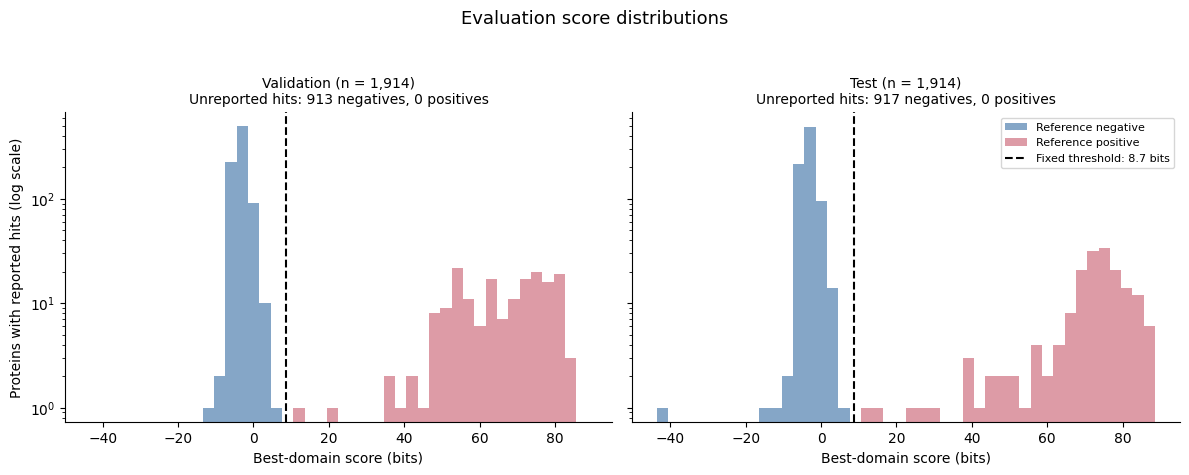

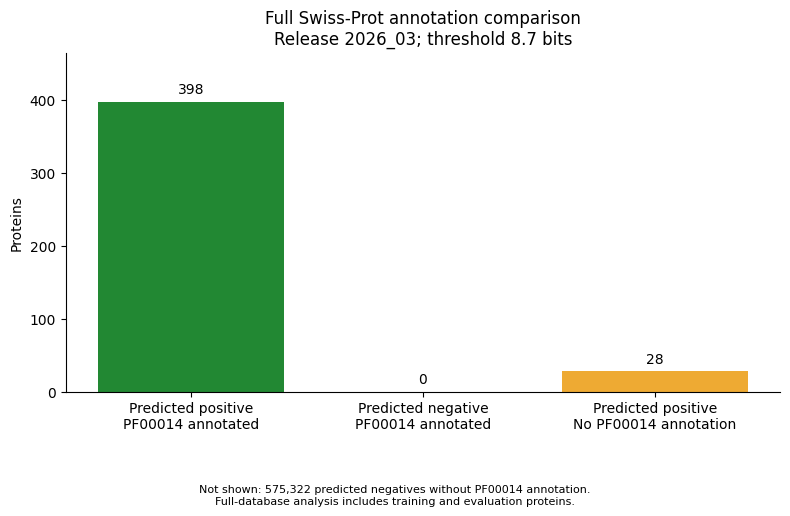

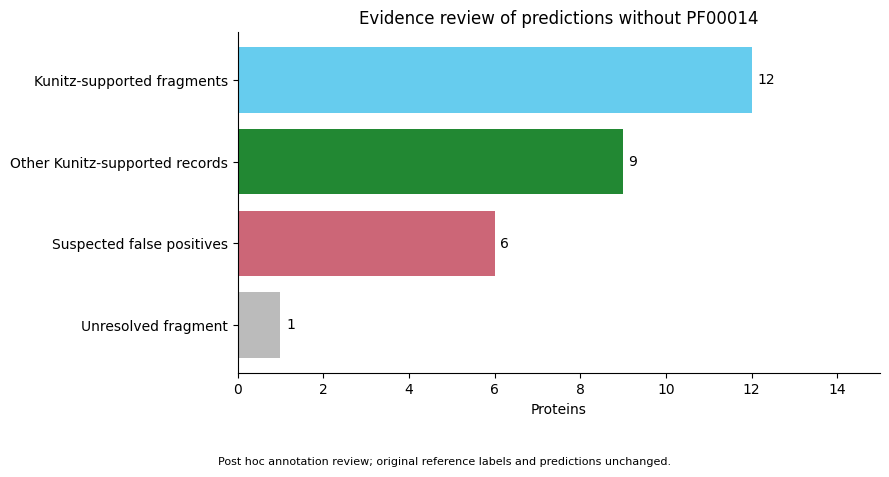


Review category counts:
review_category
Kunitz_supported_fragment    12
Kunitz_supported_other        9
suspected_false_positive      6
unresolved_fragment           1

Figures saved to: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z/report_figures
01_evaluation_score_distributions.png
01_evaluation_score_distributions.pdf
02_full_database_annotation_comparison.png
02_full_database_annotation_comparison.pdf
03_discordant_prediction_review.png
03_discordant_prediction_review.pdf
STEP 59 COMPLETE — Three figures saved as PNG and PDF.


In [145]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("STEP 59 — Create report figures from verified results")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Load verified validation and test scores.
datasets = {}
source_hashes = {}

for name, pointer_file in [
    ("Validation", "results/validation/current_validation.json"),
    ("Test", "results/test/current_test.json"),
]:
    pointer = read_json(PROJECT_DIR / pointer_file)
    path = Path(pointer["scores_path"])

    if sha256_file(path) != pointer["scores_sha256"]:
        raise ValueError(f"{name} score checksum mismatch.")

    data = pd.read_csv(path)
    if data["Entry"].duplicated().any():
        raise ValueError(f"Duplicate accessions in {name} scores.")
    if not data["reference_label"].isin([0, 1]).all():
        raise ValueError(f"Invalid reference labels in {name}.")

    data["best_domain_score_bits"] = pd.to_numeric(
        data["best_domain_score_bits"], errors="raise"
    )

    flags = data["reported_hit"].astype(str).str.lower()
    if not flags.isin(["true", "false"]).all():
        raise ValueError(f"Invalid reported-hit flags in {name}.")

    reported = flags.eq("true")

    if not np.isfinite(
        data.loc[reported, "best_domain_score_bits"]
    ).all():
        raise ValueError(f"Invalid reported scores in {name}.")
    if data.loc[~reported, "best_domain_score_bits"].notna().any():
        raise ValueError(f"Unexpected scores for unreported hits in {name}.")

    datasets[name] = data
    source_hashes[str(path)] = sha256_file(path)

# Verify the decision used for the test.
test_pointer = read_json(
    PROJECT_DIR / "results/test/current_test.json"
)
test_record = read_json(test_pointer["run_record"])
decision_path = Path(test_pointer["threshold_source"])

if sha256_file(decision_path) != test_record["threshold_source_sha256"]:
    raise ValueError("Decision record checksum mismatch.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])
if not np.isfinite(threshold):
    raise ValueError("The threshold must be finite.")
if decision["score_column"] != "best_domain_score_bits":
    raise ValueError("Unexpected decision score.")

split_record = read_json(
    PROJECT_DIR / "data/processed/evaluation_split/split_record.json"
)
if (
    test_record["split_assignments_sha256"]
    != split_record["assignment_sha256"]
):
    raise ValueError("Test results belong to a different split.")

# Load the full-database comparison and interpretation.
scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
scan_record_path = Path(scan_pointer["run_record"])

if sha256_file(scan_record_path) != scan_pointer["run_record_sha256"]:
    raise ValueError("Scan record checksum mismatch.")

scan_record = read_json(scan_record_path)
run_dir = Path(scan_pointer["run_directory"])
comparison_path = run_dir / "annotation_comparison/comparison_summary.json"
comparison = read_json(comparison_path)

if (
    float(comparison["threshold_bits"]) != threshold
    or float(scan_record["threshold_bits"]) != threshold
):
    raise ValueError("Full-database and test thresholds differ.")
if comparison["database_release"] != scan_record["database_release"]:
    raise ValueError("Database releases disagree.")

all_predictions_path = (
    run_dir / "classification/SwissProt_all_predictions.csv"
)
if (
    sha256_file(all_predictions_path)
    != comparison["all_predictions_sha256"]
):
    raise ValueError("The source prediction table has changed.")

interpretation_record_path = (
    run_dir
    / "discordant_domain_review/interpretation/interpretation_record.json"
)
interpretation_record = read_json(interpretation_record_path)
interpretation_path = Path(interpretation_record["output_path"])

if sha256_file(interpretation_path) != interpretation_record["output_sha256"]:
    raise ValueError("Interpretation checksum mismatch.")

interpretation = pd.read_csv(interpretation_path)
if interpretation["Entry"].duplicated().any():
    raise ValueError("Duplicate interpretation accessions.")
if len(interpretation) != comparison["predicted_without_PF00014"]:
    raise ValueError("Annotation comparison and review counts disagree.")
if interpretation["review_category"].isna().any():
    raise ValueError("Missing interpretation categories.")

# Validate category names before generating any figures.
category_labels = {
    "Kunitz_supported_fragment": "Kunitz-supported fragments",
    "Kunitz_supported_other": "Other Kunitz-supported records",
    "suspected_false_positive": "Suspected false positives",
    "unresolved_fragment": "Unresolved fragment",
}
category_counts = interpretation["review_category"].value_counts()

unexpected_categories = (
    set(category_counts.index) - set(category_labels)
)
if unexpected_categories:
    raise ValueError(
        f"Unexpected interpretation categories: {sorted(unexpected_categories)}"
    )

category_values = [
    int(category_counts.get(key, 0))
    for key in category_labels
]
if sum(category_values) != len(interpretation):
    raise ValueError("Interpretation counts do not reconcile.")

output_dir = run_dir / "report_figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.close("all")
plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
})

saved_files = []

def save_figure(fig, name):
    for extension in ["png", "pdf"]:
        path = output_dir / f"{name}.{extension}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        saved_files.append(path)
    plt.show()
    plt.close(fig)

# Figure 1: Only reported hits have numeric scores.
all_reported_scores = pd.concat([
    frame["best_domain_score_bits"].dropna()
    for frame in datasets.values()
])

if all_reported_scores.empty:
    raise ValueError("No reported scores are available for plotting.")

bins = np.linspace(
    all_reported_scores.min() - 1,
    all_reported_scores.max() + 1,
    45,
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.8), sharex=True, sharey=True
)

for ax, (name, data) in zip(axes, datasets.items()):
    missing_counts = {}

    for label, color, legend_label in [
        (0, "#4477AA", "Reference negative"),
        (1, "#CC6677", "Reference positive"),
    ]:
        subset = data.loc[
            data["reference_label"].eq(label),
            "best_domain_score_bits",
        ]
        missing_counts[label] = int(subset.isna().sum())

        ax.hist(
            subset.dropna(),
            bins=bins,
            alpha=0.65,
            color=color,
            label=legend_label,
        )

    ax.axvline(
        threshold,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Fixed threshold: {threshold:g} bits",
    )
    ax.set_yscale("log")
    ax.set_xlabel("Best-domain score (bits)")
    ax.set_title(
        f"{name} (n = {len(data):,})\n"
        f"Unreported hits: {missing_counts[0]} negatives, "
        f"{missing_counts[1]} positives",
        fontsize=10,
    )

axes[0].set_ylabel("Proteins with reported hits (log scale)")
axes[1].legend(fontsize=8)
fig.suptitle("Evaluation score distributions", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(fig, "01_evaluation_score_distributions")

# Figure 2: Annotation agreement is distinct from biological validation.
labels = [
    "Predicted positive\nPF00014 annotated",
    "Predicted negative\nPF00014 annotated",
    "Predicted positive\nNo PF00014 annotation",
]
counts = [
    comparison["predicted_with_PF00014"],
    comparison["PF00014_not_predicted"],
    comparison["predicted_without_PF00014"],
]

fig, ax = plt.subplots(figsize=(8, 5.2))
bars = ax.bar(
    labels,
    counts,
    color=["#228833", "#CC6677", "#EEAA33"],
)
ax.bar_label(bars, padding=4)
ax.set_ylim(0, max(1, max(counts)) * 1.17)
ax.set_ylabel("Proteins")
ax.set_title(
    "Full Swiss-Prot annotation comparison\n"
    f"Release {comparison['database_release']}; "
    f"threshold {threshold:g} bits"
)
fig.text(
    0.5, 0.02,
    f"Not shown: {comparison['not_predicted_without_PF00014']:,} "
    "predicted negatives without PF00014 annotation.\n"
    "Full-database analysis includes training and evaluation proteins.",
    ha="center",
    fontsize=8,
)
fig.tight_layout(rect=(0, 0.13, 1, 1))
save_figure(fig, "02_full_database_annotation_comparison")

# Figure 3: These categories describe a post hoc evidence review.
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(
    list(category_labels.values()),
    category_values,
    color=["#66CCEE", "#228833", "#CC6677", "#BBBBBB"],
)
ax.bar_label(bars, padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(category_values) + 3)
ax.set_xlabel("Proteins")
ax.set_title("Evidence review of predictions without PF00014")
fig.text(
    0.5, 0.02,
    "Post hoc annotation review; original reference labels and predictions unchanged.",
    ha="center",
    fontsize=8,
)
fig.tight_layout(rect=(0, 0.09, 1, 1))
save_figure(fig, "03_discordant_prediction_review")

# Save provenance for the completed figure set.
for path in [
    decision_path,
    comparison_path,
    interpretation_path,
    scan_record_path,
]:
    source_hashes[str(path)] = sha256_file(path)

manifest = {
    "threshold_bits": threshold,
    "source_hashes": source_hashes,
    "files": [
        {"path": str(path), "sha256": sha256_file(path)}
        for path in saved_files
    ],
    "notes": [
        "Histograms exclude unreported hits; counts are given in panel titles.",
        "Histogram counts use a logarithmic vertical axis.",
        "Full-database annotation agreement is not independent test performance.",
        "Evidence-review categories do not replace PF00014 reference labels.",
    ],
}
(output_dir / "figure_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("\nReview category counts:")
print(category_counts.to_string())

print(f"\nFigures saved to: {output_dir}")
for path in saved_files:
    print(path.name)

print("STEP 59 COMPLETE — Three figures saved as PNG and PDF.")

### 10. Exporting figures and report material

The preceding figures summarize score distributions, full-database annotation agreement, and review categories. The following cells generate README and report artifacts from the analysis. These exports support communication of the work; their scientific interpretation should retain the distinction between held-out evaluation and the full-database annotation review.

In [146]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import shutil

import numpy as np
import pandas as pd

print("STEP 61 — Create the project README")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def project_relative(path):
    return Path(path).resolve().relative_to(PROJECT_DIR.resolve()).as_posix()

def calculate_metrics(data, threshold):
    labels = pd.to_numeric(data["reference_label"], errors="raise")
    scores = pd.to_numeric(data["best_domain_score_bits"], errors="raise")

    if not labels.isin([0, 1]).all():
        raise ValueError("Invalid evaluation labels.")

    flags = data["reported_hit"].astype(str).str.lower()
    if not flags.isin(["true", "false"]).all():
        raise ValueError("Invalid reported-hit flags.")

    reported = flags.eq("true")
    if not np.isfinite(scores[reported]).all():
        raise ValueError("Invalid reported scores.")
    if scores[~reported].notna().any():
        raise ValueError("Unexpected scores for unreported hits.")

    predicted = (scores.fillna(-np.inf) >= threshold).astype(int)
    if "predicted_label" in data:
        if not np.array_equal(predicted, data["predicted_label"]):
            raise ValueError("Saved predictions disagree with the fixed rule.")

    tp = int(((labels == 1) & (predicted == 1)).sum())
    fp = int(((labels == 0) & (predicted == 1)).sum())
    tn = int(((labels == 0) & (predicted == 0)).sum())
    fn = int(((labels == 1) & (predicted == 0)).sum())
    denominator = math.sqrt(
        (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
    )
    return {
        "n": len(data),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "F1": 2 * tp / (2 * tp + fp + fn),
        "MCC": (tp * tn - fp * fn) / denominator if denominator else 0.0,
    }

# Verify the frozen test decision and model.
test_pointer = read_json(
    PROJECT_DIR / "results/test/current_test.json"
)
test_record_path = Path(test_pointer["run_record"])
test_record = read_json(test_record_path)
decision_path = Path(test_pointer["threshold_source"])

if sha256_file(decision_path) != test_record["threshold_source_sha256"]:
    raise ValueError("Decision checksum mismatch.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])
model_path = Path(test_record["model_path"])

if sha256_file(model_path) != test_record["model_sha256"]:
    raise ValueError("Model checksum mismatch.")

model_header = {}
for line in model_path.read_text(encoding="utf-8").splitlines():
    parts = line.split(maxsplit=1)
    if len(parts) == 2 and parts[0] in {"NAME", "LENG", "NSEQ"}:
        model_header[parts[0]] = parts[1].strip()

# Load the exact validation scores used for threshold selection.
validation_path = Path(decision["validation_scores_path"])
if sha256_file(validation_path) != decision["validation_scores_sha256"]:
    raise ValueError("Validation score checksum mismatch.")

test_path = Path(test_pointer["scores_path"])
if sha256_file(test_path) != test_pointer["scores_sha256"]:
    raise ValueError("Test score checksum mismatch.")

validation_data = pd.read_csv(validation_path)
test_data = pd.read_csv(test_path)

if set(validation_data["Entry"]) & set(test_data["Entry"]):
    raise ValueError("Validation and test accessions overlap.")

validation_metrics = calculate_metrics(validation_data, threshold)
test_metrics = calculate_metrics(test_data, threshold)

# Verify the full-database analysis.
scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
scan_record_path = Path(scan_pointer["run_record"])

if sha256_file(scan_record_path) != scan_pointer["run_record_sha256"]:
    raise ValueError("Scan record checksum mismatch.")

scan_record = read_json(scan_record_path)
if scan_record["model_sha256"] != test_record["model_sha256"]:
    raise ValueError("Full scan and evaluation models differ.")
if float(scan_record["threshold_bits"]) != threshold:
    raise ValueError("Full scan and evaluation thresholds differ.")

run_dir = Path(scan_pointer["run_directory"])
comparison_path = run_dir / "annotation_comparison/comparison_summary.json"
comparison = read_json(comparison_path)

all_predictions_path = (
    run_dir / "classification/SwissProt_all_predictions.csv"
)
if sha256_file(all_predictions_path) != comparison["all_predictions_sha256"]:
    raise ValueError("Full-database prediction checksum mismatch.")

classification = read_json(
    run_dir / "classification/classification_summary.json"
)
if classification["source_run_record_sha256"] != sha256_file(scan_record_path):
    raise ValueError("Classification belongs to a different scan.")

interpretation_dir = run_dir / "discordant_domain_review/interpretation"
interpretation_record = read_json(
    interpretation_dir / "interpretation_record.json"
)
interpretation_path = Path(interpretation_record["output_path"])

if sha256_file(interpretation_path) != interpretation_record["output_sha256"]:
    raise ValueError("Interpretation checksum mismatch.")

interpretation = pd.read_csv(interpretation_path)
category_counts = interpretation["review_category"].value_counts()

membership = read_json(
    run_dir / "evaluation_membership_audit/membership_summary.json"
)
if membership["interpretation_sha256"] != sha256_file(interpretation_path):
    raise ValueError("Membership audit refers to a different interpretation.")

# Copy verified figures to stable documentation paths.
figure_manifest_path = run_dir / "report_figures/figure_manifest.json"
figure_manifest = read_json(figure_manifest_path)
docs_figures = PROJECT_DIR / "docs/figures"
docs_figures.mkdir(parents=True, exist_ok=True)

for item in figure_manifest["files"]:
    source = Path(item["path"])
    if sha256_file(source) != item["sha256"]:
        raise ValueError(f"Figure checksum mismatch: {source}")
    destination = docs_figures / source.name
    shutil.copy2(source, destination)
    if sha256_file(destination) != item["sha256"]:
        raise ValueError(f"Figure copy checksum mismatch: {destination}")

def metric_row(name, metrics):
    return (
        f"| {name} | {metrics['n']:,} | {metrics['TP']} | "
        f"{metrics['FP']} | {metrics['TN']} | {metrics['FN']} | "
        f"{metrics['sensitivity']:.4f} | {metrics['specificity']:.4f} | "
        f"{metrics['precision']:.4f} | {metrics['F1']:.4f} | "
        f"{metrics['MCC']:.4f} |"
    )

fragment_supported = int(category_counts.get("Kunitz_supported_fragment", 0))
other_supported = int(category_counts.get("Kunitz_supported_other", 0))
suspected = int(category_counts.get("suspected_false_positive", 0))
unresolved = int(category_counts.get("unresolved_fragment", 0))

readme = f"""# Structure-derived Kunitz profile HMM

This project builds a protein profile hidden Markov model from a multiple
structural alignment of Kunitz/BPTI fragments, evaluates a fixed decision
threshold, and searches the complete reviewed UniProtKB/Swiss-Prot database.

## Main results

- Structural seed: {model_header['NSEQ']} fragments.
- Profile length: {model_header['LENG']} match states.
- Decision score: best-domain HMMER bit score.
- Fixed threshold: **score >= {threshold:g} bits**.
- Swiss-Prot release: **{comparison['database_release']}**.
- Full database: **{comparison['database_proteins']:,} proteins**.
- Predicted positive proteins: **{comparison['predicted_positive_proteins']:,}**.
- Reported domains above threshold: **{classification['domains_above_threshold']:,}**.

The full-database analysis includes training and evaluation proteins and is
not an additional independent test.

## Workflow

1. Retrieve experimental PDB entities annotated with Pfam PF00014.
2. Inspect domain ranges, coordinate coverage, experimental methods,
   sequence redundancy, and mutation-related evidence.
3. Extract and validate structural fragments, preserving residue mappings.
4. Align the fragments with MUSTANG and verify sequence preservation.
5. Independently calculate pairwise fitted C-alpha RMSDs on shared columns.
6. Convert the alignment to Stockholm and build the profile using HMMER.
7. Retrieve nonfragment Swiss-Prot evaluation candidates and screen positives
   for overlap and high similarity to training fragments.
8. Sample negative candidates reproducibly, group similar sequences, and
   create separate validation and test sets.
9. Select the bit-score threshold using validation only, then evaluate test
   predictions with the unchanged threshold.
10. Search full Swiss-Prot, including fragments, and compare predictions with
    PF00014 annotations from the same release.
11. Review discordant predictions using domain coverage and UniProt evidence.

## Structural seed and model

The final alignment contains {model_header['NSEQ']} sequences and 53 alignment
columns. One fragment has 52 residues and one alignment gap; the remaining
fragments have 53 residues. Sequence preservation was verified.

Independent pairwise structural fitting used 52 shared alignment columns.
The reported mean RMSD was approximately 0.920 angstrom, with a maximum of
approximately 1.879 angstrom across 78 pairs.

The seed contains X-ray structures and three NMR representatives. Model 1
was used for the selected NMR fragments. Pfam positional ranges define the
extracted segments; these segments need not include every terminal residue
of the biological domain.

The profile is named `{model_header['NAME']}`. The training-sequence search
was a consistency check, not an estimate of independent performance.

## Evaluation design

Positive candidates were reviewed, nonfragment Swiss-Prot proteins with a
PF00014 cross-reference. Negative candidates were reviewed, nonfragment
proteins without that cross-reference. Annotation absence is an operational
negative label, not proof of biological absence.

Training accessions, exact training-segment matches, and flagged close
training matches were excluded from the main positive evaluation pool.
Negative candidates were sampled at a 10:1 negative-to-positive ratio using
random seed 42.

Exact duplicates and accepted local sequence-similarity pairs were connected
into groups before splitting. The local grouping criterion used at least
80% identity and at least 40 paired standard amino-acid positions. MMseqs2
search is heuristic, so this does not establish complete homology independence.

Validation and test have no shared accessions, exact complete sequences, or
defined similarity groups. The split was created before model predictions
were inspected.

The threshold maximizes validation MCC. For tied optimal intervals, the
midpoint of the widest contiguous interval was selected. The chosen interval
was ({decision['optimal_interval']['lower_exclusive']:g},
{decision['optimal_interval']['upper_inclusive']:g}] bits, giving
**{threshold:g} bits**. Unreported hits are classified as negative without
assigning them artificial numeric scores.

## Validation and test results

| Set | Proteins | TP | FP | TN | FN | Sensitivity | Specificity | Precision | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
{metric_row("Validation", validation_metrics)}
{metric_row("Test", test_metrics)}

These results describe agreement with the reference labels in the constructed
evaluation sets. They do not establish perfect performance on arbitrary
proteins or on the full database.

![Validation and test score distributions](docs/figures/01_evaluation_score_distributions.png)

Histograms show reported scores only. Counts of unreported hits are displayed
in the panel titles. The vertical axis uses a logarithmic scale.

## Full Swiss-Prot annotation comparison

| PF00014 reference status | Predicted negative | Predicted positive |
|---|---:|---:|
| No PF00014 cross-reference | {comparison['not_predicted_without_PF00014']:,} | {comparison['predicted_without_PF00014']} |
| PF00014 cross-reference present | {comparison['PF00014_not_predicted']} | {comparison['predicted_with_PF00014']} |

The model detected {comparison['predicted_with_PF00014']} of
{comparison['PF00014_reference_proteins']} annotated proteins.
The fraction of predicted positives carrying PF00014 was
{100 * comparison['fraction_of_predictions_with_PF00014']:.2f}%.

Under the operational PF00014 reference, predictions lacking the
cross-reference count as false positives. Their biological interpretation
requires additional evidence.

![Full-database annotation comparison](docs/figures/02_full_database_annotation_comparison.png)

## Review of predictions without PF00014

| Descriptive evidence category | Proteins |
|---|---:|
| Kunitz-supported fragments | {fragment_supported} |
| Other Kunitz-supported records | {other_supported} |
| Suspected false positives | {suspected} |
| Unresolved fragment | {unresolved} |

Kunitz support here means existing family, domain, or superfamily annotation;
it is not new experimental validation. Superfamily membership does not imply
protease-inhibitory activity.

Some short matches correspond to explicitly annotated Kunitz fragments.
Other partial matches occur in proteins assigned to unrelated families.
Consequently, neither a bit-score threshold nor model-span coverage alone
establishes the presence of a complete biological Kunitz domain.

This was a post hoc descriptive review. Original labels, predictions, the
threshold, and test metrics were not changed.

Among these reviewed candidates, {membership['reviewed_accessions_in_evaluation']}
accessions and {membership['reviewed_sequences_with_exact_evaluation_matches']}
exact full sequences were present in the evaluation sets. This check covers
the reviewed candidates only, not every possible annotation error.

![Review of discordant predictions](docs/figures/03_discordant_prediction_review.png)

## Reproducibility and execution

The analysis was run in Google Colab. Run the project notebook in its
documented step order, or restore a verified project backup before continuing.
The notebook must be saved separately from the `/content/kunitz_project` folder.

The notebook uses Python, Biopython, pandas, NumPy, requests, and Matplotlib,
plus MUSTANG, HMMER, and MMseqs2. Software records are stored in `results/logs/`.
Observed command-line versions were MUSTANG 3.2.4, HMMER 3.4, and
MMseqs2 15-6f452+ds-2.

Timestamped run directories preserve individual outputs. JSON pointer files
identify the selected runs. Checksums bind key inputs and outputs to their
provenance records.

Live database queries may change after a UniProt release update. The archived
release-specific inputs and provenance are required to reproduce this run.
Google Colab runtime storage is temporary; keep verified backups in Drive.

## Selected artifacts

- [Evaluated HMM]({project_relative(model_path)})
- [Frozen decision rule]({project_relative(decision_path)})
- [Validation scores]({project_relative(validation_path)})
- [Test scores]({project_relative(test_path)})
- [Full-database comparison]({project_relative(comparison_path)})
- [Evidence interpretation table]({project_relative(interpretation_path)})
- [Figure provenance]({project_relative(figure_manifest_path)})

## Limitations

- The structural seed is small and its sampling is not taxonomically uniform.
- Pfam-guided seed selection and Pfam-based reference labels introduce
  dependence on existing annotation practices.
- Metadata screening cannot guarantee that every structure represents an
  unmodified natural sequence.
- A single coordinate model represents each selected NMR structure.
- Randomly sampled negatives may underrepresent difficult alternatives.
- Precision depends on the evaluation prevalence and negative sampling.
- Similarity grouping reduces defined overlap but does not eliminate all
  evolutionary relationships.
- The bit-score rule can accept short local matches; no coverage filter was
  retrospectively added to improve reported performance.
- Domain-level predictions were not evaluated against a complete
  domain-coordinate reference set.
- Post hoc annotation review is separate from the frozen evaluation.

## Resources

- [RCSB Protein Data Bank](https://www.rcsb.org/)
- [UniProt](https://www.uniprot.org/)
- [HMMER](http://hmmer.org/)
- [MMseqs2](https://github.com/soedinglab/MMseqs2)

MUSTANG reference: Konagurthu AS, Whisstock JC, Stuckey PJ, Lesk AM.
MUSTANG: a multiple structural alignment algorithm.
Proteins. 2006;64(3):559–574.
"""

# Preserve any existing README before replacing it.
readme_path = PROJECT_DIR / "README.md"
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

if readme_path.exists():
    history_dir = PROJECT_DIR / "docs/readme_history"
    history_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(readme_path, history_dir / f"README_{timestamp}.md")

readme_path.write_text(readme, encoding="utf-8")

docs_dir = PROJECT_DIR / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)
provenance = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "readme_path": str(readme_path),
    "readme_sha256": sha256_file(readme_path),
    "source_files": [
        {"path": str(path), "sha256": sha256_file(path)}
        for path in [
            decision_path,
            model_path,
            validation_path,
            test_path,
            comparison_path,
            interpretation_path,
            figure_manifest_path,
        ]
    ],
}
(docs_dir / "readme_provenance.json").write_text(
    json.dumps(provenance, indent=2), encoding="utf-8"
)

print(f"README saved to: {readme_path}")
print(f"README size: {readme_path.stat().st_size:,} bytes")
print("Figure copies saved to: docs/figures/")
print("STEP 61 COMPLETE — English README created.")

from IPython.display import Markdown, display
display(Markdown(readme))

STEP 61 — Create the project README
README saved to: /content/kunitz_project/README.md
README size: 9,318 bytes
Figure copies saved to: docs/figures/
STEP 61 COMPLETE — English README created.


# Structure-derived Kunitz profile HMM

This project builds a protein profile hidden Markov model from a multiple
structural alignment of Kunitz/BPTI fragments, evaluates a fixed decision
threshold, and searches the complete reviewed UniProtKB/Swiss-Prot database.

## Main results

- Structural seed: 13 fragments.
- Profile length: 53 match states.
- Decision score: best-domain HMMER bit score.
- Fixed threshold: **score >= 8.7 bits**.
- Swiss-Prot release: **2026_03**.
- Full database: **575,748 proteins**.
- Predicted positive proteins: **426**.
- Reported domains above threshold: **514**.

The full-database analysis includes training and evaluation proteins and is
not an additional independent test.

## Workflow

1. Retrieve experimental PDB entities annotated with Pfam PF00014.
2. Inspect domain ranges, coordinate coverage, experimental methods,
   sequence redundancy, and mutation-related evidence.
3. Extract and validate structural fragments, preserving residue mappings.
4. Align the fragments with MUSTANG and verify sequence preservation.
5. Independently calculate pairwise fitted C-alpha RMSDs on shared columns.
6. Convert the alignment to Stockholm and build the profile using HMMER.
7. Retrieve nonfragment Swiss-Prot evaluation candidates and screen positives
   for overlap and high similarity to training fragments.
8. Sample negative candidates reproducibly, group similar sequences, and
   create separate validation and test sets.
9. Select the bit-score threshold using validation only, then evaluate test
   predictions with the unchanged threshold.
10. Search full Swiss-Prot, including fragments, and compare predictions with
    PF00014 annotations from the same release.
11. Review discordant predictions using domain coverage and UniProt evidence.

## Structural seed and model

The final alignment contains 13 sequences and 53 alignment
columns. One fragment has 52 residues and one alignment gap; the remaining
fragments have 53 residues. Sequence preservation was verified.

Independent pairwise structural fitting used 52 shared alignment columns.
The reported mean RMSD was approximately 0.920 angstrom, with a maximum of
approximately 1.879 angstrom across 78 pairs.

The seed contains X-ray structures and three NMR representatives. Model 1
was used for the selected NMR fragments. Pfam positional ranges define the
extracted segments; these segments need not include every terminal residue
of the biological domain.

The profile is named `Kunitz_structural_seed_v1`. The training-sequence search
was a consistency check, not an estimate of independent performance.

## Evaluation design

Positive candidates were reviewed, nonfragment Swiss-Prot proteins with a
PF00014 cross-reference. Negative candidates were reviewed, nonfragment
proteins without that cross-reference. Annotation absence is an operational
negative label, not proof of biological absence.

Training accessions, exact training-segment matches, and flagged close
training matches were excluded from the main positive evaluation pool.
Negative candidates were sampled at a 10:1 negative-to-positive ratio using
random seed 42.

Exact duplicates and accepted local sequence-similarity pairs were connected
into groups before splitting. The local grouping criterion used at least
80% identity and at least 40 paired standard amino-acid positions. MMseqs2
search is heuristic, so this does not establish complete homology independence.

Validation and test have no shared accessions, exact complete sequences, or
defined similarity groups. The split was created before model predictions
were inspected.

The threshold maximizes validation MCC. For tied optimal intervals, the
midpoint of the widest contiguous interval was selected. The chosen interval
was (6.1,
11.3] bits, giving
**8.7 bits**. Unreported hits are classified as negative without
assigning them artificial numeric scores.

## Validation and test results

| Set | Proteins | TP | FP | TN | FN | Sensitivity | Specificity | Precision | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Validation | 1,914 | 174 | 0 | 1740 | 0 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| Test | 1,914 | 174 | 0 | 1740 | 0 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |

These results describe agreement with the reference labels in the constructed
evaluation sets. They do not establish perfect performance on arbitrary
proteins or on the full database.

![Validation and test score distributions](docs/figures/01_evaluation_score_distributions.png)

Histograms show reported scores only. Counts of unreported hits are displayed
in the panel titles. The vertical axis uses a logarithmic scale.

## Full Swiss-Prot annotation comparison

| PF00014 reference status | Predicted negative | Predicted positive |
|---|---:|---:|
| No PF00014 cross-reference | 575,322 | 28 |
| PF00014 cross-reference present | 0 | 398 |

The model detected 398 of
398 annotated proteins.
The fraction of predicted positives carrying PF00014 was
93.43%.

Under the operational PF00014 reference, predictions lacking the
cross-reference count as false positives. Their biological interpretation
requires additional evidence.

![Full-database annotation comparison](docs/figures/02_full_database_annotation_comparison.png)

## Review of predictions without PF00014

| Descriptive evidence category | Proteins |
|---|---:|
| Kunitz-supported fragments | 12 |
| Other Kunitz-supported records | 9 |
| Suspected false positives | 6 |
| Unresolved fragment | 1 |

Kunitz support here means existing family, domain, or superfamily annotation;
it is not new experimental validation. Superfamily membership does not imply
protease-inhibitory activity.

Some short matches correspond to explicitly annotated Kunitz fragments.
Other partial matches occur in proteins assigned to unrelated families.
Consequently, neither a bit-score threshold nor model-span coverage alone
establishes the presence of a complete biological Kunitz domain.

This was a post hoc descriptive review. Original labels, predictions, the
threshold, and test metrics were not changed.

Among these reviewed candidates, 0
accessions and 0
exact full sequences were present in the evaluation sets. This check covers
the reviewed candidates only, not every possible annotation error.

![Review of discordant predictions](docs/figures/03_discordant_prediction_review.png)

## Reproducibility and execution

The analysis was run in Google Colab. Run the project notebook in its
documented step order, or restore a verified project backup before continuing.
The notebook must be saved separately from the `/content/kunitz_project` folder.

The notebook uses Python, Biopython, pandas, NumPy, requests, and Matplotlib,
plus MUSTANG, HMMER, and MMseqs2. Software records are stored in `results/logs/`.
Observed command-line versions were MUSTANG 3.2.4, HMMER 3.4, and
MMseqs2 15-6f452+ds-2.

Timestamped run directories preserve individual outputs. JSON pointer files
identify the selected runs. Checksums bind key inputs and outputs to their
provenance records.

Live database queries may change after a UniProt release update. The archived
release-specific inputs and provenance are required to reproduce this run.
Google Colab runtime storage is temporary; keep verified backups in Drive.

## Selected artifacts

- [Evaluated HMM](results/hmm/build_20261107T212501_925161Z/kunitz_initial.hmm)
- [Frozen decision rule](results/test/20261107T212942_643707Z/fixed_threshold.json)
- [Validation scores](results/validation/20261107T212941_588852Z/validation_scores.csv)
- [Test scores](results/test/20261107T212942_643707Z/test_scores.csv)
- [Full-database comparison](results/swissprot_scan/20261107T212956_904384Z/annotation_comparison/comparison_summary.json)
- [Evidence interpretation table](results/swissprot_scan/20261107T212956_904384Z/discordant_domain_review/interpretation/discordant_prediction_interpretation.csv)
- [Figure provenance](results/swissprot_scan/20261107T212956_904384Z/report_figures/figure_manifest.json)

## Limitations

- The structural seed is small and its sampling is not taxonomically uniform.
- Pfam-guided seed selection and Pfam-based reference labels introduce
  dependence on existing annotation practices.
- Metadata screening cannot guarantee that every structure represents an
  unmodified natural sequence.
- A single coordinate model represents each selected NMR structure.
- Randomly sampled negatives may underrepresent difficult alternatives.
- Precision depends on the evaluation prevalence and negative sampling.
- Similarity grouping reduces defined overlap but does not eliminate all
  evolutionary relationships.
- The bit-score rule can accept short local matches; no coverage filter was
  retrospectively added to improve reported performance.
- Domain-level predictions were not evaluated against a complete
  domain-coordinate reference set.
- Post hoc annotation review is separate from the frozen evaluation.

## Resources

- [RCSB Protein Data Bank](https://www.rcsb.org/)
- [UniProt](https://www.uniprot.org/)
- [HMMER](http://hmmer.org/)
- [MMseqs2](https://github.com/soedinglab/MMseqs2)

MUSTANG reference: Konagurthu AS, Whisstock JC, Stuckey PJ, Lesk AM.
MUSTANG: a multiple structural alignment algorithm.
Proteins. 2006;64(3):559–574.


In [147]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil

import pandas as pd
from IPython.display import Markdown, display

print("STEP 62 — Create the scientific report draft")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the README and the source files used to generate it.
readme_record = read_json(PROJECT_DIR / "docs/readme_provenance.json")
readme_path = Path(readme_record["readme_path"])

if sha256_file(readme_path) != readme_record["readme_sha256"]:
    raise ValueError("README changed after its provenance was recorded.")

source_paths = []
for item in readme_record["source_files"]:
    path = Path(item["path"])
    if sha256_file(path) != item["sha256"]:
        raise ValueError(f"Source checksum mismatch: {path}")
    source_paths.append(path)

def unique_source(filename):
    matches = [path for path in source_paths if path.name == filename]
    if len(matches) != 1:
        raise ValueError(f"Expected one verified source named {filename}.")
    return matches[0]

decision = read_json(unique_source("fixed_threshold.json"))
comparison = read_json(unique_source("comparison_summary.json"))
interpretation = pd.read_csv(
    unique_source("discordant_prediction_interpretation.csv")
)
validation = pd.read_csv(unique_source("validation_scores.csv"))
test = pd.read_csv(unique_source("test_scores.csv"))

threshold = float(decision["threshold_bits"])

def confusion_counts(data):
    if data["Entry"].duplicated().any():
        raise ValueError("Duplicate evaluation accessions.")

    labels = pd.to_numeric(data["reference_label"], errors="raise")
    values = pd.to_numeric(data["best_domain_score_bits"], errors="raise")
    if not labels.isin([0, 1]).all():
        raise ValueError("Invalid reference labels.")

    predicted = values.fillna(float("-inf")).ge(threshold)
    return {
        "n": len(data),
        "positive": int(labels.eq(1).sum()),
        "negative": int(labels.eq(0).sum()),
        "TP": int((predicted & labels.eq(1)).sum()),
        "FP": int((predicted & labels.eq(0)).sum()),
        "TN": int((~predicted & labels.eq(0)).sum()),
        "FN": int((~predicted & labels.eq(1)).sum()),
    }

val = confusion_counts(validation)
tst = confusion_counts(test)

# Guard statements specific to the currently reviewed results.
if any(result["FP"] or result["FN"] for result in [val, tst]):
    raise ValueError(
        "Evaluation results differ from the reviewed analysis. "
        "Revise the report narrative before continuing."
    )

categories = interpretation["review_category"].value_counts()
supported_fragments = int(categories.get("Kunitz_supported_fragment", 0))
supported_other = int(categories.get("Kunitz_supported_other", 0))
suspected = int(categories.get("suspected_false_positive", 0))
unresolved = int(categories.get("unresolved_fragment", 0))
supported_total = supported_fragments + supported_other

reference_count = int(comparison["PF00014_reference_proteins"])
detected_count = int(comparison["predicted_with_PF00014"])
discordant_count = int(comparison["predicted_without_PF00014"])
predicted_count = int(comparison["predicted_positive_proteins"])
database_count = int(comparison["database_proteins"])
release = comparison["database_release"]

if detected_count != reference_count:
    raise ValueError("Reference detection changed; revise the report narrative.")

readme = readme_path.read_text(encoding="utf-8")

def readme_section(title):
    marker = f"## {title}\n"
    if marker not in readme:
        raise ValueError(f"Missing README section: {title}")
    return readme.split(marker, 1)[1].split("\n## ", 1)[0].strip()

abstract = f"""**Motivation:** Detecting Kunitz-related proteins requires distinguishing
family similarity from short local matches and incomplete annotations.

**Methods:** A profile HMM was built from 13 structurally aligned fragments.
A grouped validation/test design was used, with a best-domain threshold
selected using validation only. The fixed model was then applied to Swiss-Prot.

**Results:** At {threshold:g} bits, the test set yielded {tst['TP']} true positives,
{tst['TN']} true negatives, and no errors relative to PF00014-based labels.
The full scan identified {predicted_count} proteins, including all
{reference_count} PF00014-annotated entries and {discordant_count} additional candidates.
Annotation review supported Kunitz relationships for {supported_total} additional
candidates; {suspected} were suspected false positives and {unresolved} remained unresolved.

**Conclusion:** The model recovered the annotated reference set, but local
matches and annotation incompleteness complicate interpretation.
Independent test performance and post hoc biological review must be reported separately."""

report = f"""# A structure-derived profile HMM for detecting Kunitz-related proteins in Swiss-Prot

*Scientific report draft — author and course details to be added.*

## Abstract

{abstract}

## 1. Introduction

Kunitz/BPTI-related proteins provide a case study for protein-family detection
using structural information and profile hidden Markov models. In this project,
Pfam PF00014 annotations were used to identify structural candidates and to
construct an operational sequence-level reference set.

The objective was to build a profile from a multiple structural alignment,
evaluate a fixed classification rule on held-out proteins, and apply the model
to the complete reviewed Swiss-Prot database. A further objective was to
investigate predictions that lacked the PF00014 cross-reference.

The target of the analysis was family-related sequence similarity. A predicted
Kunitz relationship does not, by itself, establish protease-inhibitory activity
or the presence of a complete biological domain.

## 2. Materials and methods

### 2.1. Structural seed construction

Experimental PDB candidates annotated with PF00014 were inspected for domain
ranges, sequence redundancy, coordinate completeness, experimental method,
and mutation-related evidence. The initial search returned 165 protein
entities from 162 PDB entries.

Candidate selection considered X-ray resolution, usable C-alpha coordinates,
sequence symbols, and redundancy. NMR structures were reviewed separately.
Metadata-based mutation screening was supplemented by inspection of selected
structure descriptions and sequence differences. Two engineered BPTI variants
were excluded during manual review.

The final seed contained 13 fragments. Selected NMR fragments used coordinate
model 1. Residue mappings and exported sequences were checked against source
records. The extracted ranges corresponded to Pfam-derived segments rather
than necessarily including every terminal residue of a complete domain.

### 2.2. Structural alignment and profile construction

MUSTANG generated the multiple structural alignment [1]. The alignment
contained 53 columns, with one gap in a 52-residue fragment. Input sequences
were preserved. Independent pairwise C-alpha fitting used 52 shared alignment
columns and produced 78 comparisons.

The verified alignment was converted to Stockholm format and used to build
a 53-match-state profile with HMMER. Searches against the seed sequences were
treated as consistency checks, not as independent performance evaluation.

### 2.3. Evaluation data and similarity controls

Reviewed, nonfragment Swiss-Prot proteins with PF00014 cross-references served
as positive candidates. Proteins lacking the cross-reference formed the
operational negative pool. Training accessions and exact training-segment
matches were removed from the positive evaluation candidates. Additional
close training matches were screened before the evaluation split.

The resulting pool contained 348 positives and 3,480 sampled negatives.
Negative sampling used seed 42. Exact duplicates and accepted local sequence
matches were connected into similarity groups using MMseqs2 results. The
grouping criterion required at least 80% identity and 40 paired standard
amino-acid positions.

Groups were allocated to validation and test without shared accessions,
exact complete sequences, or defined similarity groups. Each subset contained
174 positives and 1,740 negatives. Heuristic similarity searching does not
guarantee absence of all evolutionary relationships.

### 2.4. Threshold selection and independent test

The decision score was the best-domain HMMER bit score. Validation MCC was
used to choose a threshold. A tied optimum was resolved using the midpoint
of the widest contiguous optimal interval, yielding {threshold:g} bits.
Proteins with scores at or above this threshold were classified as positive;
proteins without reported hits were classified as negative.

The threshold was frozen before test evaluation. Searches used the recorded
HMMER settings, including disabling heuristic acceleration with `--max`.
Broad reporting limits were distinct from the classification threshold.

### 2.5. Full-database search and evidence review

The same model and fixed decision threshold were applied to
{database_count:,} Swiss-Prot proteins from release {release}, including
fragments. Database sequences and annotation records were checked for release
and sequence consistency.

Predictions were compared with the complete set of reviewed PF00014-annotated
proteins. Discordant predictions were examined using model-span coverage,
fragment annotations, domain features, family comments, and InterPro
cross-references. Model-span coverage was calculated as
`(hmm_end - hmm_start + 1) / model_length`; it does not count individually
matched nongap positions.

This evidence review was descriptive and post hoc. It did not change the
reference labels, prediction rule, or reported test results.

## 3. Results

### 3.1. Structural alignment

The 13-fragment alignment preserved all input sequences. The independently
calculated mean pairwise fitted RMSD was approximately 0.920 angstrom, and
the maximum was approximately 1.879 angstrom across the shared positions.
These values describe similarity within the selected seed.

### 3.2. Validation and test classification

| Subset | Proteins | TP | FP | TN | FN |
|---|---:|---:|---:|---:|---:|
| Validation | {val['n']} | {val['TP']} | {val['FP']} | {val['TN']} | {val['FN']} |
| Test | {tst['n']} | {tst['TP']} | {tst['FP']} | {tst['TN']} | {tst['FN']} |

Sensitivity, specificity, precision, F1, and MCC were all 1.00 on these
constructed subsets. These are results relative to the operational reference
labels, not evidence of error-free detection in arbitrary databases.

![Evaluation score distributions](../docs/figures/01_evaluation_score_distributions.png)

*Figure 1. Best-domain score distributions for reported validation and test
hits. The dashed line marks the fixed threshold. The vertical axis is
logarithmic; unreported-hit counts appear in the panel titles.*

### 3.3. Full Swiss-Prot scan

The model predicted {predicted_count} positive proteins, including all
{reference_count} entries with PF00014 annotations. Another {discordant_count}
predicted proteins lacked that cross-reference. The proportion of predictions
with PF00014 annotations was
{100 * comparison['fraction_of_predictions_with_PF00014']:.2f}%.

![Full-database annotation comparison](../docs/figures/02_full_database_annotation_comparison.png)

*Figure 2. Agreement with the PF00014 reference across Swiss-Prot.
This scan includes training and evaluation proteins and is not a second
independent test.*

### 3.4. Discordant prediction review

| Evidence category | Proteins |
|---|---:|
| Kunitz-supported fragments | {supported_fragments} |
| Other Kunitz-supported records | {supported_other} |
| Suspected false positives | {suspected} |
| Unresolved fragment | {unresolved} |

Several short sequences had explicit fragment and Kunitz-related annotations.
Other candidates had domain or superfamily evidence despite lacking PF00014.
Conversely, six partial matches occurred in proteins assigned to other
families, making spurious local similarity a plausible explanation. These
six cases were classified as suspected, rather than proven, biological false
positives. One short toxin fragment remained unresolved.

None of the 28 reviewed accessions, or their exact full sequences, appeared
in the validation/test sets. This check was limited to these reviewed cases.

![Discordant prediction review](../docs/figures/03_discordant_prediction_review.png)

*Figure 3. Descriptive evidence categories for predictions lacking PF00014.
These categories do not replace the original reference labels.*

## 4. Discussion

The independent test results show that the selected score rule separated the
sampled reference classes. However, randomly sampled negatives can be easier
to distinguish than biologically related alternatives. Perfect results on
this dataset therefore do not establish universal specificity.

The full-database analysis revealed two distinct issues: short local matches
can pass a score-only rule, and the absence of a Pfam cross-reference can
disagree with other existing Kunitz-related annotations. Consequently,
annotation-defined false positives should be distinguished from biological
false positives.

The evidence does not support retrospectively imposing a blanket coverage
cutoff: some low-coverage predictions represent explicitly annotated Kunitz
fragments. Any revised score-and-coverage rule would require a separate
development and evaluation design, rather than tuning on the observed test
or full-database outcomes.

Additional limitations are listed below.

{readme_section("Limitations")}

## 5. Conclusions

A profile derived from structural alignment recovered the complete
PF00014-annotated Swiss-Prot reference set and showed perfect agreement with
the sampled test labels at a fixed threshold of {threshold:g} bits.
Full-database review nevertheless identified plausible spurious matches and
annotation discrepancies.

The appropriate conclusion is that the model is useful for identifying
Kunitz-related candidates under the documented conditions. Completeness of
domains, biological function, and discordant cases require additional
evidence.

## 6. Data and reproducibility

The project README documents execution, selected artifacts, software records,
and limitations. Raw inputs, timestamped runs, checksums, and evidence tables
are retained within the project directory.

The analysis notebook must be preserved separately from temporary Colab
runtime files. This draft and its figures should be included in the next
verified backup.

## References and data resources

1. Konagurthu AS, Whisstock JC, Stuckey PJ, Lesk AM. MUSTANG: a multiple
   structural alignment algorithm. Proteins. 2006;64(3):559–574.
2. RCSB Protein Data Bank: https://www.rcsb.org/
3. UniProtKB/Swiss-Prot, release {release}: https://www.uniprot.org/
4. HMMER documentation and software: http://hmmer.org/
5. MMseqs2 documentation and software: https://github.com/soedinglab/MMseqs2

*Before submission, adapt reference formatting to the course requirements
and add any required software-method citations.*
"""

report_dir = PROJECT_DIR / "report"
report_dir.mkdir(parents=True, exist_ok=True)
report_path = report_dir / "scientific_report_draft.md"

if report_path.exists():
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    history_dir = report_dir / "history"
    history_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(report_path, history_dir / f"draft_{timestamp}.md")

report_path.write_text(report, encoding="utf-8")

# Verify local figure links before publishing the draft.
figure_names = [
    "01_evaluation_score_distributions.png",
    "02_full_database_annotation_comparison.png",
    "03_discordant_prediction_review.png",
]
for name in figure_names:
    if not (PROJECT_DIR / "docs/figures" / name).is_file():
        raise FileNotFoundError(f"Missing report figure: {name}")

provenance = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "report_path": str(report_path),
    "report_sha256": sha256_file(report_path),
    "readme_sha256": sha256_file(readme_path),
    "abstract_word_count_approximate": len(abstract.split()),
    "status": "Draft; author details and submission formatting pending",
    "source_files": readme_record["source_files"],
}
(report_dir / "report_provenance.json").write_text(
    json.dumps(provenance, indent=2), encoding="utf-8"
)

print(f"Report saved to: {report_path}")
print(f"Approximate abstract word count: {len(abstract.split())}")
print("STEP 62 COMPLETE — Scientific report draft created.")
display(Markdown(abstract))

STEP 62 — Create the scientific report draft
Report saved to: /content/kunitz_project/report/scientific_report_draft.md
Approximate abstract word count: 130
STEP 62 COMPLETE — Scientific report draft created.


**Motivation:** Detecting Kunitz-related proteins requires distinguishing
family similarity from short local matches and incomplete annotations.

**Methods:** A profile HMM was built from 13 structurally aligned fragments.
A grouped validation/test design was used, with a best-domain threshold
selected using validation only. The fixed model was then applied to Swiss-Prot.

**Results:** At 8.7 bits, the test set yielded 174 true positives,
1740 true negatives, and no errors relative to PF00014-based labels.
The full scan identified 426 proteins, including all
398 PF00014-annotated entries and 28 additional candidates.
Annotation review supported Kunitz relationships for 21 additional
candidates; 6 were suspected false positives and 1 remained unresolved.

**Conclusion:** The model recovered the annotated reference set, but local
matches and annotation incompleteness complicate interpretation.
Independent test performance and post hoc biological review must be reported separately.

### 11. Assessing similarity-related limitations

The next analyses are **post hoc diagnostics**. They examine the original split and training relationships without rebuilding the HMM, changing labels, or selecting a new threshold.

At the original 80% grouping rule, there are no accepted cross-split pairs. Lowering the identity criterion to 60% or 40% yields 2,427 and 21,328 cross-split pairs, respectively, in the reported local-match data. At 40%, one connected component contains **343 of the 348 positives**. Transitive grouping can connect many proteins even when not every pair exceeds the threshold.

The original split therefore supports an evaluation under an explicit redundancy-control rule, rather than a claim of homology-free validation/test separation. A stricter prospective benchmark would require a newly designed split and evaluation; these diagnostics do not create a new untouched test set.

In [148]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd

print("STEP 63 — Audit cross-split similarity without changing the split")

PROJECT_DIR = Path("/content/kunitz_project")
SPLIT_DIR = PROJECT_DIR / "data/processed/evaluation_split"

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the frozen split.
assignment_path = SPLIT_DIR / "split_assignments.csv"
split_record = read_json(SPLIT_DIR / "split_record.json")

if sha256_file(assignment_path) != split_record["assignment_sha256"]:
    raise ValueError("Split assignment checksum mismatch.")

assignments = pd.read_csv(assignment_path)
if assignments["Entry"].duplicated().any():
    raise ValueError("Duplicate evaluation accessions.")
if not assignments["split"].isin(["validation", "test"]).all():
    raise ValueError("Unexpected split values.")
if not assignments["reference_label"].isin([0, 1]).all():
    raise ValueError("Invalid reference labels.")

# Verify metadata membership and recover original full sequences.
frames = []
for split_name in ["validation", "test"]:
    frame = pd.read_csv(SPLIT_DIR / f"{split_name}_metadata.csv")
    columns = ["Entry", "reference_label", "similarity_group"]

    expected = (
        assignments.loc[assignments["split"].eq(split_name), columns]
        .sort_values("Entry").reset_index(drop=True)
    )
    actual = frame[columns].sort_values("Entry").reset_index(drop=True)
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False)

    frames.append(frame[["Entry", "Sequence"]])

sequences = pd.concat(frames, ignore_index=True)
if sequences["Entry"].duplicated().any():
    raise ValueError("Repeated accessions across evaluation subsets.")

sequence_map = sequences.set_index("Entry")["Sequence"].to_dict()
label_map = assignments.set_index("Entry")["reference_label"].to_dict()
split_map = assignments.set_index("Entry")["split"].to_dict()
ids = sorted(sequence_map)

# Verify the original all-versus-all search.
pointer = read_json(PROJECT_DIR / "results/similarity/current_search.json")
search_record = read_json(pointer["search_record"])
hits_path = Path(pointer["hits_path"])

if sha256_file(hits_path) != pointer["hits_sha256"]:
    raise ValueError("MMseqs2 result checksum mismatch.")

source_path = Path(search_record["source_table"])
if sha256_file(source_path) != search_record["source_sha256"]:
    raise ValueError("The MMseqs2 source table has changed.")

source = pd.read_csv(source_path)
if source["Entry"].duplicated().any():
    raise ValueError("Duplicate search-source accessions.")
if dict(zip(source["Entry"], source["Sequence"])) != sequence_map:
    raise ValueError("Search sequences and evaluation sequences differ.")

# These columns match the STEP 43 output format.
columns = [
    "query", "target", "fident", "alnlen",
    "qstart", "qend", "qlen",
    "tstart", "tend", "tlen",
    "evalue", "bits", "qaln", "taln",
]

standard = set("ACDEFGHIKLMNPQRSTVWY")
minimum_standard_pairs = 40
pair_records = {}

print("Inspecting reported local alignments...")

for chunk in pd.read_csv(
    hits_path, sep="\t", names=columns, header=None,
    dtype=str, keep_default_na=False, chunksize=25000,
):
    for row in chunk.itertuples(index=False):
        query, target = row.query, row.target
        if query not in sequence_map or target not in sequence_map:
            raise ValueError("Unexpected accession in similarity results.")
        if query == target:
            continue

        qa, ta = row.qaln.upper(), row.taln.upper()
        if not qa or len(qa) != len(ta):
            raise ValueError("Invalid aligned sequence strings.")
        if len(qa) != int(row.alnlen):
            raise ValueError("Alignment length and strings disagree.")

        paired = sum(a in standard and b in standard for a, b in zip(qa, ta))
        if paired < minimum_standard_pairs:
            continue

        matches = sum(
            a == b and a in standard
            for a, b in zip(qa, ta)
        )
        identity = matches / len(qa)
        if identity < 0.40:
            continue

        qstart, qend = int(row.qstart), int(row.qend)
        tstart, tend = int(row.tstart), int(row.tend)
        qlen, tlen = int(row.qlen), int(row.tlen)

        if qlen != len(sequence_map[query]) or tlen != len(sequence_map[target]):
            raise ValueError("Search sequence lengths disagree with metadata.")
        if not (1 <= qstart <= qend <= qlen and 1 <= tstart <= tend <= tlen):
            raise ValueError("Invalid local alignment coordinates.")

        # Canonicalize the pair while retaining its alignment coordinates.
        if query < target:
            a, b = query, target
            a_start, a_end, a_len = qstart, qend, qlen
            b_start, b_end, b_len = tstart, tend, tlen
        else:
            a, b = target, query
            a_start, a_end, a_len = tstart, tend, tlen
            b_start, b_end, b_len = qstart, qend, qlen

        candidate = {
            "accession_a": a,
            "accession_b": b,
            "identity_fraction": identity,
            "standard_paired_positions": paired,
            "alignment_columns": len(qa),
            "a_start": a_start,
            "a_end": a_end,
            "b_start": b_start,
            "b_end": b_end,
            "a_full_sequence_span_percent": 100 * (a_end - a_start + 1) / a_len,
            "b_full_sequence_span_percent": 100 * (b_end - b_start + 1) / b_len,
            "split_a": split_map[a],
            "split_b": split_map[b],
            "label_a": int(label_map[a]),
            "label_b": int(label_map[b]),
            "crosses_current_split": split_map[a] != split_map[b],
        }

        key = (a, b)
        previous = pair_records.get(key)
        if previous is None or (
            identity, paired
        ) > (
            previous["identity_fraction"],
            previous["standard_paired_positions"],
        ):
            pair_records[key] = candidate

if not pair_records:
    raise ValueError("No qualifying pairs found; inspect search inputs.")

pairs = pd.DataFrame(pair_records.values())
summary_rows = []

# Reconstruct hypothetical connected components, always joining exact duplicates.
for cutoff in [0.40, 0.60, 0.80]:
    parent = {accession: accession for accession in ids}
    size = {accession: 1 for accession in ids}

    def find(accession):
        while parent[accession] != accession:
            parent[accession] = parent[parent[accession]]
            accession = parent[accession]
        return accession

    def union(a, b):
        a, b = find(a), find(b)
        if a == b:
            return
        if size[a] < size[b]:
            a, b = b, a
        parent[b] = a
        size[a] += size[b]

    first_for_sequence = {}
    for accession in ids:
        sequence = sequence_map[accession]
        if sequence in first_for_sequence:
            union(accession, first_for_sequence[sequence])
        else:
            first_for_sequence[sequence] = accession

    accepted = pairs.loc[pairs["identity_fraction"].ge(cutoff)]
    for row in accepted.itertuples(index=False):
        union(row.accession_a, row.accession_b)

    groups = pd.DataFrame({
        "Entry": ids,
        "component": [find(accession) for accession in ids],
        "label": [label_map[accession] for accession in ids],
        "split": [split_map[accession] for accession in ids],
    })
    grouped = groups.groupby("component").agg(
        proteins=("Entry", "size"),
        positives=("label", "sum"),
        split_count=("split", "nunique"),
    )
    mixed = grouped["positives"].gt(0) & (
        grouped["positives"] < grouped["proteins"]
    )
    cross = accepted.loc[accepted["crosses_current_split"]]
    cross_positive = cross.loc[
        cross["label_a"].eq(1) & cross["label_b"].eq(1)
    ]

    summary_rows.append({
        "identity_threshold_percent": int(cutoff * 100),
        "accepted_unique_pairs": len(accepted),
        "cross_split_pairs": len(cross),
        "cross_split_positive_pairs": len(cross_positive),
        "hypothetical_groups": len(grouped),
        "groups_containing_positives": int(grouped["positives"].gt(0).sum()),
        "largest_group_proteins": int(grouped["proteins"].max()),
        "largest_group_positive_count": int(grouped["positives"].max()),
        "mixed_label_groups": int(mixed.sum()),
        "components_spanning_current_split": int(
            grouped["split_count"].gt(1).sum()
        ),
    })

summary = pd.DataFrame(summary_rows)
cross_pairs = pairs.loc[pairs["crosses_current_split"]].copy()
cross_pairs = cross_pairs.sort_values(
    ["identity_fraction", "standard_paired_positions"],
    ascending=[False, False],
)
cross_pairs["identity_percent"] = 100 * cross_pairs["identity_fraction"]

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = PROJECT_DIR / "results/robustness" / f"split_audit_{timestamp}"
output_dir.mkdir(parents=True, exist_ok=False)

summary.to_csv(output_dir / "grouping_sensitivity_summary.csv", index=False)
pairs.to_csv(output_dir / "qualifying_reported_pairs.csv", index=False)
cross_pairs.to_csv(output_dir / "cross_split_pairs.csv", index=False)

settings = {
    "analysis": "Descriptive sensitivity audit of the existing split",
    "identity_thresholds": [0.40, 0.60, 0.80],
    "minimum_standard_pairs": minimum_standard_pairs,
    "identity_definition": "Standard identical pairs divided by alignment columns",
    "pair_selection": "Highest identity qualifying reported alignment per unordered pair",
    "exact_full_sequences_always_connected": True,
    "source_hits": str(hits_path),
    "source_hits_sha256": sha256_file(hits_path),
    "split_assignments_sha256": sha256_file(assignment_path),
    "original_split_changed": False,
    "model_or_threshold_changed": False,
    "limitations": [
        "Uses existing heuristic search results; unreported relationships are unknown.",
        "Local matches have not yet been mapped to Kunitz domain coordinates.",
        "This stage does not measure similarity to HMM training fragments.",
    ],
}
(output_dir / "audit_settings.json").write_text(
    json.dumps(settings, indent=2), encoding="utf-8"
)

print("\nGrouping sensitivity summary:")
print(summary.to_string(index=False))

print("\nHighest-identity cross-split positive pairs:")
positive_cross = cross_pairs.loc[
    cross_pairs["label_a"].eq(1) & cross_pairs["label_b"].eq(1)
]
print(positive_cross[
    [
        "accession_a", "accession_b", "identity_percent",
        "standard_paired_positions", "a_start", "a_end",
        "b_start", "b_end",
    ]
].head(20).round(2).to_string(index=False))

baseline = summary.loc[
    summary["identity_threshold_percent"].eq(80)
].iloc[0]
if baseline["cross_split_pairs"] > 0:
    print(
        "\nREVIEW REQUIRED: Reported pairs meeting the 80% criterion cross "
        "the current split. Compare this audit with STEP 44 before proceeding."
    )

print(f"\nAudit saved to: {output_dir}")
print("STEP 63 COMPLETE — Diagnostic results saved; original analysis unchanged.")

STEP 63 — Audit cross-split similarity without changing the split
Inspecting reported local alignments...

Grouping sensitivity summary:
 identity_threshold_percent  accepted_unique_pairs  cross_split_pairs  cross_split_positive_pairs  hypothetical_groups  groups_containing_positives  largest_group_proteins  largest_group_positive_count  mixed_label_groups  components_spanning_current_split
                         40                  43304              21328                       20420                 2513                            5                     350                           343                   1                                277
                         60                   7673               2427                        2251                 3213                           60                     222                           222                   0                                105
                         80                   1484                  0                       

In [149]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd
from Bio import AlignIO
from Bio.Align import PairwiseAligner, substitution_matrices

print("STEP 64 — Audit evaluation-positive similarity to HMM training")

PROJECT_DIR = Path("/content/kunitz_project")
SPLIT_DIR = PROJECT_DIR / "data/processed/evaluation_split"

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Recover the alignment used to build the evaluated model.
test_pointer = read_json(
    PROJECT_DIR / "results/test/current_test.json"
)
test_record = read_json(test_pointer["run_record"])
model_path = Path(test_record["model_path"])

if sha256_file(model_path) != test_record["model_sha256"]:
    raise ValueError("Evaluated model checksum mismatch.")

build_record = read_json(model_path.parent / "build_record.json")
if build_record["model_sha256"] != test_record["model_sha256"]:
    raise ValueError("Build and evaluation models differ.")

alignment_path = Path(build_record["input_alignment"])
if sha256_file(alignment_path) != build_record["input_sha256"]:
    raise ValueError("Training alignment checksum mismatch.")

alignment = AlignIO.read(alignment_path, "stockholm")
training = {
    record.id: str(record.seq).replace("-", "").replace(".", "").upper()
    for record in alignment
}
if len(training) != len(alignment):
    raise ValueError("Duplicate training sequence identifiers.")

standard = set("ACDEFGHIKLMNPQRSTVWY")
if any(not sequence or set(sequence) - standard for sequence in training.values()):
    raise ValueError("Unexpected symbols in training fragments.")

# Verify evaluation membership against the frozen split.
assignment_path = SPLIT_DIR / "split_assignments.csv"
split_record = read_json(SPLIT_DIR / "split_record.json")
assignment_hash = sha256_file(assignment_path)

if assignment_hash != split_record["assignment_sha256"]:
    raise ValueError("Split checksum mismatch.")
if assignment_hash != test_record["split_assignments_sha256"]:
    raise ValueError("The evaluated test used a different split.")

assignments = pd.read_csv(assignment_path)
if assignments["Entry"].duplicated().any():
    raise ValueError("Duplicate split accessions.")

positive_frames = []
metadata_hashes = {}

for split_name in ["validation", "test"]:
    path = SPLIT_DIR / f"{split_name}_metadata.csv"
    frame = pd.read_csv(path)

    columns = ["Entry", "reference_label", "similarity_group"]
    expected = (
        assignments.loc[assignments["split"].eq(split_name), columns]
        .sort_values("Entry").reset_index(drop=True)
    )
    actual = frame[columns].sort_values("Entry").reset_index(drop=True)
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False)

    positives = frame.loc[
        frame["reference_label"].eq(1), ["Entry", "Sequence"]
    ].copy()
    positives["split"] = split_name
    positive_frames.append(positives)
    metadata_hashes[str(path)] = sha256_file(path)

positives = pd.concat(positive_frames, ignore_index=True)
if positives["Entry"].duplicated().any():
    raise ValueError("Positive accessions overlap across subsets.")

# Match the documented local alignment scoring scheme.
aligner = PairwiseAligner()
aligner.mode = "local"
matrix = substitution_matrices.load("BLOSUM62")
aligner.substitution_matrix = matrix
aligner.open_gap_score = -10.0
aligner.extend_gap_score = -0.5

MIN_SEED_COVERAGE = 0.90
supported_symbols = set(matrix.alphabet)

rows = []

print(f"Training fragments: {len(training)}")
print(f"Evaluation positives: {len(positives)}")

for index, protein in enumerate(positives.itertuples(index=False), start=1):
    target = str(protein.Sequence).upper()

    # Avoid introducing an undocumented residue conversion.
    unsupported = set(target) - supported_symbols
    if unsupported:
        raise ValueError(
            f"Unsupported BLOSUM62 symbols in {protein.Entry}: "
            f"{sorted(unsupported)}"
        )

    for seed_id, seed in sorted(training.items()):
        alignments = aligner.align(seed, target)
        try:
            match = next(iter(alignments))
        except StopIteration:
            rows.append({
                "Entry": protein.Entry,
                "split": protein.split,
                "training_seed_id": seed_id,
                "alignment_score": 0.0,
                "identity_percent": np.nan,
                "seed_coverage_percent": 0.0,
                "coverage_qualified": False,
                "alignment_columns": 0,
                "paired_positions": 0,
                "target_start": np.nan,
                "target_end": np.nan,
            })
            continue

        seed_indices, target_indices = match.indices
        paired = (seed_indices >= 0) & (target_indices >= 0)
        paired_count = int(paired.sum())

        identical_standard = sum(
            seed[int(i)] == target[int(j)] and seed[int(i)] in standard
            for i, j in zip(seed_indices[paired], target_indices[paired])
        )

        alignment_columns = len(seed_indices)
        seed_coverage = paired_count / len(seed)
        target_positions = target_indices[target_indices >= 0]

        rows.append({
            "Entry": protein.Entry,
            "split": protein.split,
            "training_seed_id": seed_id,
            "alignment_score": float(match.score),
            "identity_percent": 100 * identical_standard / alignment_columns,
            "seed_coverage_percent": 100 * seed_coverage,
            "coverage_qualified": seed_coverage >= MIN_SEED_COVERAGE,
            "alignment_columns": alignment_columns,
            "paired_positions": paired_count,
            "target_start": int(target_positions.min()) + 1,
            "target_end": int(target_positions.max()) + 1,
        })

    if index % 50 == 0 or index == len(positives):
        print(f"Compared {index}/{len(positives)} proteins")

pairs = pd.DataFrame(rows)

if len(pairs) != len(positives) * len(training):
    raise ValueError("Pairwise comparison count mismatch.")

# Select the maximum identity among coverage-qualified local alignments.
qualified = pairs.loc[pairs["coverage_qualified"]].sort_values(
    [
        "Entry", "identity_percent", "seed_coverage_percent",
        "alignment_score", "training_seed_id",
    ],
    ascending=[True, False, False, False, True],
)
nearest = qualified.drop_duplicates("Entry")

audit = positives[["Entry", "split"]].merge(
    nearest.drop(columns="split"),
    on="Entry",
    how="left",
    validate="one_to_one",
)
audit["has_coverage_qualified_match"] = audit["training_seed_id"].notna()

# Retain the highest-scoring local match as supplementary information.
best_score = (
    pairs.sort_values(
        ["Entry", "alignment_score", "training_seed_id"],
        ascending=[True, False, True],
    )
    .drop_duplicates("Entry")
    [["Entry", "training_seed_id", "identity_percent", "seed_coverage_percent"]]
    .rename(columns={
        "training_seed_id": "best_score_seed_id",
        "identity_percent": "best_score_identity_percent",
        "seed_coverage_percent": "best_score_seed_coverage_percent",
    })
)
audit = audit.merge(best_score, on="Entry", validate="one_to_one")

# These bins describe the audit; they do not redefine the evaluation sets.
def identity_band(row):
    if not row["has_coverage_qualified_match"]:
        return "No coverage-qualified local match"
    identity = row["identity_percent"]
    if identity < 40:
        return "<40%"
    if identity < 60:
        return "40–<60%"
    if identity < 80:
        return "60–<80%"
    if identity < 90:
        return "80–<90%"
    return ">=90%"

audit["training_identity_band"] = audit.apply(identity_band, axis=1)
band_order = [
    "<40%", "40–<60%", "60–<80%", "80–<90%", ">=90%",
    "No coverage-qualified local match",
]
summary = pd.crosstab(
    audit["training_identity_band"], audit["split"]
).reindex(index=band_order, columns=["validation", "test"], fill_value=0)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = PROJECT_DIR / "results/robustness" / f"training_audit_{timestamp}"
output_dir.mkdir(parents=True, exist_ok=False)

pairs_path = output_dir / "all_training_positive_alignments.csv"
audit_path = output_dir / "positive_training_similarity_audit.csv"
pairs.to_csv(pairs_path, index=False)
audit.to_csv(audit_path, index=False)
summary.to_csv(output_dir / "training_identity_band_counts.csv")

settings = {
    "training_alignment": str(alignment_path),
    "training_alignment_sha256": sha256_file(alignment_path),
    "model_sha256": test_record["model_sha256"],
    "split_assignments_sha256": assignment_hash,
    "metadata_hashes": metadata_hashes,
    "alignment_mode": "local",
    "substitution_matrix": "BLOSUM62",
    "gap_open_score": -10.0,
    "gap_extension_score": -0.5,
    "minimum_paired_seed_coverage": MIN_SEED_COVERAGE,
    "identity_definition": (
        "Identical standard residues divided by all local alignment columns"
    ),
    "selection": (
        "Maximum identity among seed comparisons with >=90% paired seed coverage"
    ),
    "alignment_ties": "First optimal local alignment returned by Biopython",
    "limitations": [
        "Missing coverage-qualified matches do not establish remote homology.",
        "Local alignment coordinates are not independently verified domain boundaries.",
        "This is a descriptive post hoc audit, not a new held-out evaluation.",
    ],
    "original_analysis_changed": False,
    "audit_path": str(audit_path),
    "audit_sha256": sha256_file(audit_path),
}
record_path = output_dir / "audit_settings.json"
record_path.write_text(json.dumps(settings, indent=2), encoding="utf-8")

(PROJECT_DIR / "results/robustness/current_training_audit.json").write_text(
    json.dumps({
        "record_path": str(record_path),
        "record_sha256": sha256_file(record_path),
        "audit_path": str(audit_path),
        "audit_sha256": sha256_file(audit_path),
    }, indent=2),
    encoding="utf-8",
)

print("\nMaximum training identity among coverage-qualified matches:")
print(summary.to_string())

print("\nHighest-identity test positives:")
display_columns = [
    "Entry", "training_seed_id", "identity_percent",
    "seed_coverage_percent", "target_start", "target_end",
]
print(
    audit.loc[
        audit["split"].eq("test") & audit["has_coverage_qualified_match"],
        display_columns,
    ]
    .sort_values("identity_percent", ascending=False)
    .head(15)
    .round(2)
    .to_string(index=False)
)

print(
    "\nProteins without coverage-qualified matches:",
    int((~audit["has_coverage_qualified_match"]).sum()),
)
print(f"Audit saved to: {output_dir}")
print("STEP 64 COMPLETE — Training similarity audited; no data or model changed.")

STEP 64 — Audit evaluation-positive similarity to HMM training
Training fragments: 13
Evaluation positives: 348
Compared 50/348 proteins
Compared 100/348 proteins
Compared 150/348 proteins
Compared 200/348 proteins
Compared 250/348 proteins
Compared 300/348 proteins
Compared 348/348 proteins

Maximum training identity among coverage-qualified matches:
split                              validation  test
training_identity_band                             
<40%                                        6     9
40–<60%                                   153   156
60–<80%                                     6     7
80–<90%                                     9     2
>=90%                                       0     0
No coverage-qualified local match           0     0

Highest-identity test positives:
 Entry training_seed_id  identity_percent  seed_coverage_percent  target_start  target_end
Q8R0S6      REVISED_025             88.46                  98.11           363         414
P0C5J5      RE

#### Detection across similarity to the structural training seed

Among test positives, the maximum training identity in coverage-qualified local matches falls below 40% for 9 proteins, in 40–<60% for 156, in 60–<80% for 7, and in 80–<90% for 2. None reaches 90%.

All four populated bands have recall 1.0 at the unchanged threshold. Thus, **165/174 test positives** have less than 60% identity under this audit, showing that the positive results are not restricted to near-identical training fragments. However, the analysis uses a particular local alignment and coverage definition, and it does not establish general remote-homology performance.

This is a positive-only recall analysis; it cannot estimate band-specific precision or specificity. Some original similarity groups span multiple bands, so per-band group counts must not be added as independent observations.

In [150]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd

print("STEP 65 — Summarize test-positive detection by training similarity")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the training-similarity audit.
audit_pointer = read_json(
    PROJECT_DIR / "results/robustness/current_training_audit.json"
)
audit_record_path = Path(audit_pointer["record_path"])
audit_path = Path(audit_pointer["audit_path"])

if sha256_file(audit_record_path) != audit_pointer["record_sha256"]:
    raise ValueError("Training audit record checksum mismatch.")
if sha256_file(audit_path) != audit_pointer["audit_sha256"]:
    raise ValueError("Training audit table checksum mismatch.")

audit_record = read_json(audit_record_path)
audit = pd.read_csv(audit_path)

if audit["Entry"].duplicated().any():
    raise ValueError("Duplicate training-audit accessions.")

# Verify the frozen test results and decision.
test_pointer = read_json(
    PROJECT_DIR / "results/test/current_test.json"
)
test_path = Path(test_pointer["scores_path"])
test_record = read_json(test_pointer["run_record"])

if sha256_file(test_path) != test_pointer["scores_sha256"]:
    raise ValueError("Test score checksum mismatch.")
if audit_record["model_sha256"] != test_record["model_sha256"]:
    raise ValueError("Training audit and test used different models.")

decision_path = Path(test_pointer["threshold_source"])
if sha256_file(decision_path) != test_record["threshold_source_sha256"]:
    raise ValueError("Fixed decision checksum mismatch.")

decision = read_json(decision_path)
threshold = float(decision["threshold_bits"])
if decision["score_column"] != "best_domain_score_bits":
    raise ValueError("Unexpected decision score.")

# Verify the original split and its similarity-group assignments.
assignment_path = (
    PROJECT_DIR / "data/processed/evaluation_split/split_assignments.csv"
)
assignment_hash = sha256_file(assignment_path)

if assignment_hash != test_record["split_assignments_sha256"]:
    raise ValueError("Test split checksum mismatch.")
if assignment_hash != audit_record["split_assignments_sha256"]:
    raise ValueError("Training audit used a different split.")

assignments = pd.read_csv(assignment_path)
test = pd.read_csv(test_path)

if assignments["Entry"].duplicated().any() or test["Entry"].duplicated().any():
    raise ValueError("Duplicate accessions.")

expected_test = assignments.loc[
    assignments["split"].eq("test"),
    ["Entry", "reference_label", "similarity_group"],
]
actual_test = test[["Entry", "reference_label", "similarity_group"]]

pd.testing.assert_frame_equal(
    actual_test.sort_values("Entry").reset_index(drop=True),
    expected_test.sort_values("Entry").reset_index(drop=True),
    check_dtype=False,
)

test["best_domain_score_bits"] = pd.to_numeric(
    test["best_domain_score_bits"], errors="raise"
)
flags = test["reported_hit"].astype(str).str.lower()
if not flags.isin(["true", "false"]).all():
    raise ValueError("Invalid reported-hit flags.")

reported = flags.eq("true")
if not np.isfinite(
    test.loc[reported, "best_domain_score_bits"]
).all():
    raise ValueError("Invalid reported scores.")
if test.loc[~reported, "best_domain_score_bits"].notna().any():
    raise ValueError("Unexpected scores for unreported hits.")

expected_predictions = (
    test["best_domain_score_bits"].fillna(-np.inf) >= threshold
).astype(int)

if not np.array_equal(expected_predictions, test["predicted_label"]):
    raise ValueError("Test predictions disagree with the fixed threshold.")

# Restrict the analysis to reference-positive test proteins.
positive_test = test.loc[test["reference_label"].eq(1)].copy()
test_audit = audit.loc[audit["split"].eq("test")].copy()

if set(positive_test["Entry"]) != set(test_audit["Entry"]):
    raise ValueError("Test positives and training-audit membership disagree.")

details = positive_test[
    ["Entry", "similarity_group", "best_domain_score_bits", "predicted_label"]
].merge(
    test_audit[
        [
            "Entry", "training_identity_band", "training_seed_id",
            "identity_percent", "seed_coverage_percent",
        ]
    ],
    on="Entry",
    how="left",
    validate="one_to_one",
)

band_order = [
    "<40%",
    "40–<60%",
    "60–<80%",
    "80–<90%",
    ">=90%",
    "No coverage-qualified local match",
]
if not details["training_identity_band"].isin(band_order).all():
    raise ValueError("Unexpected similarity-band values.")

rows = []
for band in band_order:
    subset = details.loc[details["training_identity_band"].eq(band)]
    count = len(subset)
    detected = int(subset["predicted_label"].eq(1).sum())

    rows.append({
        "training_identity_band": band,
        "test_positive_proteins": count,
        "distinct_original_80pct_groups": subset["similarity_group"].nunique(),
        "detected": detected,
        "missed": count - detected,
        "recall": detected / count if count else np.nan,
        "minimum_reported_score_bits": (
            subset["best_domain_score_bits"].min() if count else np.nan
        ),
    })

summary = pd.DataFrame(rows)

# A group can contribute proteins to more than one identity band.
group_band_counts = (
    details.groupby("similarity_group")["training_identity_band"].nunique()
)
groups_spanning_bands = int(group_band_counts.gt(1).sum())

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = (
    PROJECT_DIR / "results/robustness"
    / f"test_similarity_summary_{timestamp}"
)
output_dir.mkdir(parents=True, exist_ok=False)

summary_path = output_dir / "test_recall_by_training_similarity.csv"
details_path = output_dir / "test_positive_similarity_details.csv"
summary.to_csv(summary_path, index=False)
details.to_csv(details_path, index=False)

record = {
    "analysis_type": "Post hoc descriptive analysis of the original test",
    "threshold_bits": threshold,
    "test_positive_count": len(details),
    "distinct_original_80pct_groups": details["similarity_group"].nunique(),
    "original_groups_spanning_multiple_bands": groups_spanning_bands,
    "source_test_scores_sha256": sha256_file(test_path),
    "source_training_audit_sha256": sha256_file(audit_path),
    "split_assignments_sha256": assignment_hash,
    "summary_path": str(summary_path),
    "summary_sha256": sha256_file(summary_path),
    "notes": [
        "Only reference-positive test proteins are included.",
        "Precision and specificity are not estimated for these subsets.",
        "Empty bands have undefined recall, not zero recall.",
        "Group counts refer to the original 80% grouping.",
        "Group counts across bands are not necessarily additive.",
        "No claim of independent evolutionary lineages is made.",
        "The split, model, threshold, and predictions remain unchanged.",
    ],
}
(output_dir / "summary_record.json").write_text(
    json.dumps(record, indent=2), encoding="utf-8"
)

print(f"Fixed threshold: {threshold:.4f} bits")
print(f"Test positives: {len(details)}")
print(
    "Distinct original 80% groups:",
    details["similarity_group"].nunique(),
)

print("\nDetection by training-similarity band:")
print(summary.round(4).to_string(index=False, na_rep="N/A"))

print(f"\nOriginal groups spanning multiple bands: {groups_spanning_bands}")
print("Group counts across bands must not be summed as independent groups.")
print(f"Results saved to: {output_dir}")
print("STEP 65 COMPLETE — Descriptive summary saved; original analysis unchanged.")

STEP 65 — Summarize test-positive detection by training similarity
Fixed threshold: 8.7000 bits
Test positives: 174
Distinct original 80% groups: 65

Detection by training-similarity band:
           training_identity_band  test_positive_proteins  distinct_original_80pct_groups  detected  missed  recall  minimum_reported_score_bits
                             <40%                       9                               9         9       0     1.0                         11.2
                          40–<60%                     156                              51       156       0     1.0                         39.3
                          60–<80%                       7                               5         7       0     1.0                         73.7
                          80–<90%                       2                               1         2       0     1.0                         79.4
                            >=90%                       0                             

In [151]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re
import shutil

import pandas as pd

print("STEP 66 — Update documentation with similarity-audit findings")

PROJECT_DIR = Path("/content/kunitz_project")
ROBUSTNESS_DIR = PROJECT_DIR / "results/robustness"

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def newest_record(pattern):
    paths = sorted(ROBUSTNESS_DIR.glob(pattern))
    if not paths:
        raise FileNotFoundError(f"No record found for: {pattern}")
    return paths[-1]

# Verify the current split.
assignment_path = (
    PROJECT_DIR / "data/processed/evaluation_split/split_assignments.csv"
)
split_record = read_json(
    PROJECT_DIR / "data/processed/evaluation_split/split_record.json"
)
assignment_hash = sha256_file(assignment_path)

if assignment_hash != split_record["assignment_sha256"]:
    raise ValueError("Split checksum mismatch.")

# Load the recorded STEP 63 audit.
split_audit_record_path = newest_record("split_audit_*/audit_settings.json")
split_audit_record = read_json(split_audit_record_path)

if split_audit_record["split_assignments_sha256"] != assignment_hash:
    raise ValueError("STEP 63 refers to a different split.")
if (
    sha256_file(split_audit_record["source_hits"])
    != split_audit_record["source_hits_sha256"]
):
    raise ValueError("STEP 63 source alignments have changed.")

split_summary_path = (
    split_audit_record_path.parent / "grouping_sensitivity_summary.csv"
)
split_summary = pd.read_csv(split_summary_path).set_index(
    "identity_threshold_percent"
)

for cutoff in [40, 60, 80]:
    if cutoff not in split_summary.index:
        raise ValueError(f"Missing grouping audit threshold: {cutoff}")

# Verify STEP 64.
training_pointer = read_json(
    ROBUSTNESS_DIR / "current_training_audit.json"
)
training_record_path = Path(training_pointer["record_path"])
training_audit_path = Path(training_pointer["audit_path"])

if sha256_file(training_record_path) != training_pointer["record_sha256"]:
    raise ValueError("Training audit record checksum mismatch.")
if sha256_file(training_audit_path) != training_pointer["audit_sha256"]:
    raise ValueError("Training audit table checksum mismatch.")

training_record = read_json(training_record_path)
if training_record["split_assignments_sha256"] != assignment_hash:
    raise ValueError("STEP 64 refers to a different split.")

# Verify STEP 65.
summary_record_path = newest_record(
    "test_similarity_summary_*/summary_record.json"
)
summary_record = read_json(summary_record_path)
summary_path = Path(summary_record["summary_path"])

if sha256_file(summary_path) != summary_record["summary_sha256"]:
    raise ValueError("STEP 65 summary checksum mismatch.")
if summary_record["split_assignments_sha256"] != assignment_hash:
    raise ValueError("STEP 65 refers to a different split.")
if (
    summary_record["source_training_audit_sha256"]
    != sha256_file(training_audit_path)
):
    raise ValueError("STEP 65 used a different training audit.")

test_pointer = read_json(
    PROJECT_DIR / "results/test/current_test.json"
)
test_scores_path = Path(test_pointer["scores_path"])
test_scores_hash = sha256_file(test_scores_path)

if test_scores_hash != test_pointer["scores_sha256"]:
    raise ValueError("Test score checksum mismatch.")
if test_scores_hash != summary_record["source_test_scores_sha256"]:
    raise ValueError("STEP 65 used different test scores.")

bands = pd.read_csv(summary_path, keep_default_na=False)
numeric_columns = [
    "test_positive_proteins",
    "distinct_original_80pct_groups",
    "detected",
    "missed",
]
for column in numeric_columns:
    bands[column] = pd.to_numeric(bands[column], errors="raise")

lower_similarity = bands.loc[
    bands["training_identity_band"].isin(["<40%", "40–<60%"])
]
low_count = int(lower_similarity["test_positive_proteins"].sum())
low_detected = int(lower_similarity["detected"].sum())

r40 = split_summary.loc[40]
r60 = split_summary.loc[60]
r80 = split_summary.loc[80]

# Do not publish the intended wording if the original grouping check fails.
if int(r80["cross_split_pairs"]) != 0:
    raise ValueError("The 80% grouping audit requires review before documentation.")

table_rows = []
for row in bands.itertuples(index=False):
    n = int(row.test_positive_proteins)
    recall = f"{int(row.detected) / n:.3f}" if n else "N/A"
    minimum = (
        f"{float(row.minimum_reported_score_bits):.1f}"
        if n and str(row.minimum_reported_score_bits) != ""
        else "N/A"
    )
    table_rows.append(
        f"| {row.training_identity_band} | {n} | "
        f"{int(row.distinct_original_80pct_groups)} | "
        f"{int(row.detected)} | {int(row.missed)} | {recall} | {minimum} |"
    )

addendum = f"""## Additional similarity audit and scope of generalization

After the original evaluation, we performed descriptive audits of
validation–test similarity and similarity to the HMM training fragments.
The model, threshold, reference labels, and original split were unchanged.
These analyses are post hoc and do not constitute a new untouched test.

### Similarity across the original validation/test split

The audit reproduced zero cross-split pairs meeting the original 80%
identity criterion with at least 40 paired standard residues. Thus, the
implemented split respected its stated grouping rule.

However, it found {int(r60['cross_split_positive_pairs']):,} cross-split
positive pairs at a 60% threshold and
{int(r40['cross_split_positive_pairs']):,} at a 40% threshold, under the
same minimum paired-length requirement.

Hypothetical connected-component grouping at 60% produced a component
containing {int(r60['largest_group_positive_count'])} positives. At 40%,
the largest positive count within a component was
{int(r40['largest_group_positive_count'])}. These connected components
include transitive relationships; their members need not all meet the
pairwise threshold directly.

These findings limit claims of evolutionary independence between validation
and test. The original evaluation is best described as a held-out test with
80%-identity grouping, not as an evolutionarily independent benchmark.
Local matches in this audit have not all been mapped to Kunitz boundaries.

### Similarity to the training fragments

For each evaluation-positive protein, local BLOSUM62 alignments were
calculated against the 13 training fragments, using gap opening and extension
scores of -10 and -0.5. Maximum identity was reported among comparisons with
at least 90% paired coverage of the training fragment. Identity counted
standard identical residues divided by all local alignment columns.

| Training-identity band | Test positives | Original 80% groups | Detected | Missed | Recall | Minimum reported score (bits) |
|---|---:|---:|---:|---:|---:|---:|
{chr(10).join(table_rows)}

The model detected {low_detected} of {low_count} test positives with
less than 60% identity under this coverage-qualified comparison.
This indicates that detection was not limited to near-identical training
matches. It does not establish a general remote-homology detection rate.

The test positives occupy
{int(summary_record['distinct_original_80pct_groups'])} original similarity
groups. Group counts across rows are not additive because
{int(summary_record['original_groups_spanning_multiple_bands'])} group(s)
span more than one band. These groups are not asserted to be independent
evolutionary lineages.

Only reference-positive test proteins are included in this table.
Consequently, recall is reported; precision and specificity are not estimated
for these subsets. Empty bands have undefined recall.

### Consequences for interpretation

The original test metrics remain valid descriptions of agreement with the
operational labels in the selected split. They do not demonstrate complete
evolutionary independence or universal performance.

A stricter grouping strategy would require a separately documented
evaluation design. Neither the grouping threshold nor the classification
threshold was retrospectively changed to improve the reported results.
"""

docs_dir = PROJECT_DIR / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)
addendum_path = docs_dir / "similarity_audit_addendum.md"
addendum_path.write_text(addendum, encoding="utf-8")

# Preserve existing documents and update only known wording.
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
history_dir = docs_dir / "documentation_history" / timestamp
history_dir.mkdir(parents=True, exist_ok=False)

start_marker = "<!-- SIMILARITY_AUDIT_START -->"
end_marker = "<!-- SIMILARITY_AUDIT_END -->"
block = f"{start_marker}\n\n{addendum}\n\n{end_marker}\n"

replacements = {
    "## Validation and test results":
        "## Validation and held-out test results",
    "### 2.4. Threshold selection and independent test":
        "### 2.4. Threshold selection and held-out test",
    "The independent test results show":
        "The held-out test results show",
    "Independent test performance and post hoc biological review":
        "Held-out test performance and post hoc biological review",
}

updated = []
missing = []

for path in [
    PROJECT_DIR / "README.md",
    PROJECT_DIR / "report/scientific_report_draft.md",
]:
    if not path.is_file():
        missing.append(str(path))
        continue

    before_hash = sha256_file(path)
    relative = path.relative_to(PROJECT_DIR)
    backup_path = history_dir / relative
    backup_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, backup_path)

    text = path.read_text(encoding="utf-8")

    # Replace the prior generated addendum if this cell is rerun.
    text = re.sub(
        re.escape(start_marker) + r".*?" + re.escape(end_marker),
        "",
        text,
        flags=re.DOTALL,
    )
    for old, new in replacements.items():
        text = text.replace(old, new)

    insertion_markers = [
        "## References and data resources",
        "## Resources",
    ]
    insertion = next(
        (marker for marker in insertion_markers if marker in text),
        None,
    )
    if insertion:
        text = text.replace(insertion, block + "\n" + insertion, 1)
    else:
        text = text.rstrip() + "\n\n" + block

    path.write_text(text, encoding="utf-8")
    updated.append({
        "path": str(path),
        "previous_sha256": before_hash,
        "updated_sha256": sha256_file(path),
        "backup_path": str(backup_path),
    })

# Refresh document checksums while retaining the prior provenance records.
provenance_pairs = [
    (
        PROJECT_DIR / "README.md",
        docs_dir / "readme_provenance.json",
        "readme_sha256",
    ),
    (
        PROJECT_DIR / "report/scientific_report_draft.md",
        PROJECT_DIR / "report/report_provenance.json",
        "report_sha256",
    ),
]

audit_sources = [
    split_audit_record_path,
    split_summary_path,
    training_record_path,
    training_audit_path,
    summary_record_path,
    summary_path,
]

for document_path, provenance_path, checksum_key in provenance_pairs:
    if not document_path.is_file() or not provenance_path.is_file():
        continue

    backup_path = history_dir / provenance_path.relative_to(PROJECT_DIR)
    backup_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(provenance_path, backup_path)

    provenance = read_json(provenance_path)
    provenance[checksum_key] = sha256_file(document_path)
    provenance["similarity_audit_update_utc"] = (
        datetime.now(timezone.utc).isoformat()
    )
    provenance["similarity_audit_sources"] = [
        {"path": str(path), "sha256": sha256_file(path)}
        for path in audit_sources
    ]
    provenance_path.write_text(
        json.dumps(provenance, indent=2), encoding="utf-8"
    )

update_record = {
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "updated_documents": updated,
    "documents_not_present": missing,
    "addendum_path": str(addendum_path),
    "addendum_sha256": sha256_file(addendum_path),
    "original_model_split_and_predictions_changed": False,
    "sources": [
        {"path": str(path), "sha256": sha256_file(path)}
        for path in audit_sources
    ],
}
record_path = docs_dir / f"similarity_documentation_update_{timestamp}.json"
record_path.write_text(
    json.dumps(update_record, indent=2), encoding="utf-8"
)

print(f"Standalone addendum: {addendum_path}")
for item in updated:
    print(f"Updated: {item['path']}")
for path in missing:
    print(f"Not present; no document created: {path}")

print(f"Previous versions preserved in: {history_dir}")
print(f"Update provenance: {record_path}")
print("STEP 66 COMPLETE — Documentation updated; analysis unchanged.")

from IPython.display import Markdown, display
display(Markdown(addendum))

STEP 66 — Update documentation with similarity-audit findings
Standalone addendum: /content/kunitz_project/docs/similarity_audit_addendum.md
Updated: /content/kunitz_project/README.md
Updated: /content/kunitz_project/report/scientific_report_draft.md
Previous versions preserved in: /content/kunitz_project/docs/documentation_history/20261107T213423_810290Z
Update provenance: /content/kunitz_project/docs/similarity_documentation_update_20261107T213423_810290Z.json
STEP 66 COMPLETE — Documentation updated; analysis unchanged.


## Additional similarity audit and scope of generalization

After the original evaluation, we performed descriptive audits of
validation–test similarity and similarity to the HMM training fragments.
The model, threshold, reference labels, and original split were unchanged.
These analyses are post hoc and do not constitute a new untouched test.

### Similarity across the original validation/test split

The audit reproduced zero cross-split pairs meeting the original 80%
identity criterion with at least 40 paired standard residues. Thus, the
implemented split respected its stated grouping rule.

However, it found 2,251 cross-split
positive pairs at a 60% threshold and
20,420 at a 40% threshold, under the
same minimum paired-length requirement.

Hypothetical connected-component grouping at 60% produced a component
containing 222 positives. At 40%,
the largest positive count within a component was
343. These connected components
include transitive relationships; their members need not all meet the
pairwise threshold directly.

These findings limit claims of evolutionary independence between validation
and test. The original evaluation is best described as a held-out test with
80%-identity grouping, not as an evolutionarily independent benchmark.
Local matches in this audit have not all been mapped to Kunitz boundaries.

### Similarity to the training fragments

For each evaluation-positive protein, local BLOSUM62 alignments were
calculated against the 13 training fragments, using gap opening and extension
scores of -10 and -0.5. Maximum identity was reported among comparisons with
at least 90% paired coverage of the training fragment. Identity counted
standard identical residues divided by all local alignment columns.

| Training-identity band | Test positives | Original 80% groups | Detected | Missed | Recall | Minimum reported score (bits) |
|---|---:|---:|---:|---:|---:|---:|
| <40% | 9 | 9 | 9 | 0 | 1.000 | 11.2 |
| 40–<60% | 156 | 51 | 156 | 0 | 1.000 | 39.3 |
| 60–<80% | 7 | 5 | 7 | 0 | 1.000 | 73.7 |
| 80–<90% | 2 | 1 | 2 | 0 | 1.000 | 79.4 |
| >=90% | 0 | 0 | 0 | 0 | N/A | N/A |
| No coverage-qualified local match | 0 | 0 | 0 | 0 | N/A | N/A |

The model detected 165 of 165 test positives with
less than 60% identity under this coverage-qualified comparison.
This indicates that detection was not limited to near-identical training
matches. It does not establish a general remote-homology detection rate.

The test positives occupy
65 original similarity
groups. Group counts across rows are not additive because
1 group(s)
span more than one band. These groups are not asserted to be independent
evolutionary lineages.

Only reference-positive test proteins are included in this table.
Consequently, recall is reported; precision and specificity are not estimated
for these subsets. Empty bands have undefined recall.

### Consequences for interpretation

The original test metrics remain valid descriptions of agreement with the
operational labels in the selected split. They do not demonstrate complete
evolutionary independence or universal performance.

A stricter grouping strategy would require a separately documented
evaluation design. Neither the grouping threshold nor the classification
threshold was retrospectively changed to improve the reported results.


### 12. Taxonomic distribution and fragment status

Taxonomy and sequence flags are retrieved for all 426 predicted proteins. Compound flags are parsed by their components: `Fragment,Precursor` includes an explicit fragment flag. After this correction, **43 predictions are explicitly flagged as fragments**: 30 PF00014-annotated and 13 without PF00014.

Fragment status describes the deposited sequence. Absence of an explicit fragment flag should not be treated as independent proof of sequence completeness. Predictions and scores remain unchanged by the metadata correction.

In [152]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd
import requests
from Bio import SeqIO
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

print("STEP 67 — Retrieve taxonomy and fragment metadata for predicted proteins")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify the current scan and predicted-positive table.
pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
scan_record_path = Path(pointer["run_record"])
if sha256_file(scan_record_path) != pointer["run_record_sha256"]:
    raise ValueError("Scan record checksum mismatch.")

scan_record = read_json(scan_record_path)
run_dir = Path(pointer["run_directory"])
expected_release = scan_record["database_release"]

classification = read_json(
    run_dir / "classification/classification_summary.json"
)
predictions_path = Path(classification["predictions_path"])

if sha256_file(predictions_path) != classification["predictions_sha256"]:
    raise ValueError("Prediction table checksum mismatch.")
if classification["source_run_record_sha256"] != sha256_file(scan_record_path):
    raise ValueError("Classification belongs to a different scan.")

predictions = pd.read_csv(predictions_path)
if predictions["Entry"].duplicated().any():
    raise ValueError("Duplicate predicted accessions.")

candidate_ids = sorted(predictions["Entry"])
candidate_set = set(candidate_ids)

# Verify the reference used to distinguish annotation-supported predictions.
reference_pointer = read_json(
    PROJECT_DIR / "data/processed/current_PF00014_full_reference.json"
)
reference_path = Path(reference_pointer["reference_path"])
reference_record_path = Path(reference_pointer["record_path"])

if sha256_file(reference_path) != reference_pointer["reference_sha256"]:
    raise ValueError("Reference table checksum mismatch.")
if sha256_file(reference_record_path) != reference_pointer["record_sha256"]:
    raise ValueError("Reference record checksum mismatch.")

reference_record = read_json(reference_record_path)
if (
    reference_record["database_sha256"] != scan_record["database_sha256"]
    or reference_record["uniprot_release"] != expected_release
):
    raise ValueError("Reference and scan databases differ.")

reference_ids = set(pd.read_csv(reference_path)["Entry"])

# Recover exact predicted sequences from the scanned database.
database_path = Path(scan_record["database_path"])
if sha256_file(database_path) != scan_record["database_sha256"]:
    raise ValueError("Scanned database checksum mismatch.")

expected_sequences = {}
for protein in SeqIO.parse(database_path, "fasta"):
    parts = protein.id.split("|")
    if len(parts) != 3 or parts[0] != "sp":
        raise ValueError(f"Unexpected FASTA identifier: {protein.id}")
    if parts[1] in candidate_set:
        expected_sequences[parts[1]] = str(protein.seq)

if set(expected_sequences) != candidate_set:
    raise ValueError("Some predicted proteins are absent from the database.")

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = run_dir / "distribution" / f"metadata_{timestamp}"
raw_dir = output_dir / "raw"
raw_dir.mkdir(parents=True, exist_ok=False)

session = requests.Session()
session.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=4,
            backoff_factor=2,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
    ),
)

batch_size = 50
metadata_rows = []
request_records = []

# Retrieve JSON in accession batches, following pagination if necessary.
for batch_start in range(0, len(candidate_ids), batch_size):
    batch = candidate_ids[batch_start:batch_start + batch_size]
    batch_set = set(batch)
    batch_seen = set()
    batch_number = batch_start // batch_size + 1

    query = "(reviewed:true) AND (" + " OR ".join(
        f"accession:{accession}" for accession in batch
    ) + ")"

    url = "https://rest.uniprot.org/uniprotkb/search"
    params = {"query": query, "format": "json", "size": 500}
    page_number = 0
    visited_urls = set()

    while url:
        response = snapshot_get(url, params=params, timeout=(30, 180))
        response.raise_for_status()

        if response.url in visited_urls:
            raise ValueError("Repeated pagination URL.")
        visited_urls.add(response.url)

        release = response.headers.get("X-UniProt-Release")
        if release != expected_release:
            raise ValueError(
                f"Release mismatch: expected {expected_release}, received {release}."
            )

        page_number += 1
        raw_path = raw_dir / f"batch_{batch_number:03d}_page_{page_number:03d}.json"
        raw_path.write_bytes(response.content)

        request_records.append({
            "url": response.url,
            "uniprot_release": release,
            "raw_path": str(raw_path),
            "raw_sha256": sha256_file(raw_path),
        })

        payload = response.json()
        if "results" not in payload:
            raise ValueError("Unexpected UniProt JSON response.")

        for entry in payload["results"]:
            accession = entry.get("primaryAccession")
            if accession not in batch_set or accession in batch_seen:
                raise ValueError(f"Unexpected or duplicate accession: {accession}")
            batch_seen.add(accession)

            if entry.get("entryType") != "UniProtKB reviewed (Swiss-Prot)":
                raise ValueError(f"Unexpected entry type: {accession}")

            sequence = entry.get("sequence", {}).get("value")
            if sequence != expected_sequences[accession]:
                raise ValueError(f"Sequence mismatch: {accession}")

            pfam_ids = {
                item.get("id")
                for item in entry.get("uniProtKBCrossReferences", [])
                if item.get("database") == "Pfam"
            }
            has_pf00014 = "PF00014" in pfam_ids
            if has_pf00014 != (accession in reference_ids):
                raise ValueError(f"PF00014 reference mismatch: {accession}")

            organism = entry.get("organism", {})
            taxon_id = organism.get("taxonId")
            scientific_name = organism.get("scientificName", "")
            lineage = organism.get("lineage", [])

            if taxon_id is None or not scientific_name:
                raise ValueError(f"Missing organism information: {accession}")
            if not isinstance(lineage, list):
                raise ValueError(f"Unexpected lineage format: {accession}")

            description = entry.get("proteinDescription", {})
            flag = description.get("flag")

            if flag in {"Fragment", "Fragments"}:
                fragment_status = "explicit_fragment"
            elif flag is None:
                fragment_status = "not_explicitly_flagged"
            else:
                fragment_status = f"other_flag:{flag}"

            name = (
                description.get("recommendedName", {})
                .get("fullName", {}).get("value", "")
            )
            if not name:
                name = " | ".join(
                    item.get("fullName", {}).get("value", "")
                    for item in description.get("submissionNames", [])
                )

            metadata_rows.append({
                "Entry": accession,
                "uniprot_entry_name": entry.get("uniProtkbId", ""),
                "protein_name": name,
                "taxon_id": int(taxon_id),
                "scientific_name": scientific_name,
                "lineage_json": json.dumps(lineage, ensure_ascii=False),
                "protein_description_flag": flag or "",
                "fragment_annotation_status": fragment_status,
                "has_PF00014_annotation": has_pf00014,
                "annotation_group": (
                    "PF00014_annotated"
                    if has_pf00014 else "without_PF00014"
                ),
            })

        url = response.links.get("next", {}).get("url")
        params = None

    if batch_seen != batch_set:
        raise ValueError(
            f"Missing batch accessions: {sorted(batch_set - batch_seen)}"
        )

    print(f"Verified {min(batch_start + batch_size, len(candidate_ids))}"
          f"/{len(candidate_ids)} proteins")

metadata = pd.DataFrame(metadata_rows)
if metadata["Entry"].duplicated().any():
    raise ValueError("Duplicate metadata accessions.")
if set(metadata["Entry"]) != candidate_set:
    raise ValueError("Final metadata accession mismatch.")

combined = predictions.merge(
    metadata, on="Entry", how="left", validate="one_to_one"
)

# Attach the existing descriptive review without changing reference labels.
interpretation_dir = run_dir / "discordant_domain_review/interpretation"
interpretation_record = read_json(
    interpretation_dir / "interpretation_record.json"
)
interpretation_path = Path(interpretation_record["output_path"])
if sha256_file(interpretation_path) != interpretation_record["output_sha256"]:
    raise ValueError("Interpretation checksum mismatch.")

interpretation = pd.read_csv(interpretation_path)
expected_discordant = candidate_set - reference_ids
if set(interpretation["Entry"]) != expected_discordant:
    raise ValueError("Interpretation and discordant prediction sets differ.")

combined = combined.merge(
    interpretation[["Entry", "review_category"]],
    on="Entry", how="left", validate="one_to_one",
)
combined.loc[
    combined["has_PF00014_annotation"], "review_category"
] = "PF00014_reference"

table_path = output_dir / "predicted_protein_distribution_metadata.csv"
combined.to_csv(table_path, index=False)

record = {
    "uniprot_release": expected_release,
    "predicted_protein_count": len(combined),
    "predictions_sha256": sha256_file(predictions_path),
    "reference_sha256": sha256_file(reference_path),
    "interpretation_sha256": sha256_file(interpretation_path),
    "all_sequences_match_scanned_database": True,
    "PF00014_annotations_match_reference": True,
    "table_path": str(table_path),
    "table_sha256": sha256_file(table_path),
    "retrieval_records": request_records,
    "predictions_changed": False,
    "note": (
        "Counts describe predicted proteins, not organism-level prevalence. "
        "Absence of an explicit fragment flag is not independently verified completeness."
    ),
}
record_path = output_dir / "metadata_record.json"
record_path.write_text(
    json.dumps(record, indent=2), encoding="utf-8"
)

(run_dir / "distribution/current_metadata.json").write_text(
    json.dumps({
        "record_path": str(record_path),
        "record_sha256": sha256_file(record_path),
        "table_path": str(table_path),
        "table_sha256": sha256_file(table_path),
    }, indent=2),
    encoding="utf-8",
)

print(f"\nUniProt release: {expected_release}")
print(f"Verified predicted proteins: {len(combined)}")

print("\nAnnotation-group summary:")
print(combined.groupby("annotation_group").agg(
    proteins=("Entry", "size"),
    distinct_taxon_ids=("taxon_id", "nunique"),
).to_string())

print("\nFragment annotation counts:")
print(pd.crosstab(
    combined["annotation_group"],
    combined["fragment_annotation_status"],
).to_string())

print(f"\nMetadata saved to: {table_path}")
print("STEP 67 COMPLETE — Distribution metadata verified; predictions unchanged.")

STEP 67 — Retrieve taxonomy and fragment metadata for predicted proteins
Verified 50/426 proteins
Verified 100/426 proteins
Verified 150/426 proteins
Verified 200/426 proteins
Verified 250/426 proteins
Verified 300/426 proteins
Verified 350/426 proteins
Verified 400/426 proteins
Verified 426/426 proteins

UniProt release: 2026_03
Verified predicted proteins: 426

Annotation-group summary:
                   proteins  distinct_taxon_ids
annotation_group                               
PF00014_annotated       398                 123
without_PF00014          28                  19

Fragment annotation counts:
fragment_annotation_status  explicit_fragment  not_explicitly_flagged  other_flag:Fragment,Precursor  other_flag:Precursor
annotation_group                                                                                                          
PF00014_annotated                          15                      75                             15                   293
without_PF00014   

In [153]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd

print("STEP 68 — Correct compound fragment flags")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
run_dir = Path(scan_pointer["run_directory"])
pointer_path = run_dir / "distribution/current_metadata.json"
pointer = read_json(pointer_path)

source_record_path = Path(pointer["record_path"])
source_path = Path(pointer["table_path"])

if sha256_file(source_record_path) != pointer["record_sha256"]:
    raise ValueError("Metadata record checksum mismatch.")
if sha256_file(source_path) != pointer["table_sha256"]:
    raise ValueError("Metadata table checksum mismatch.")

source_record = read_json(source_record_path)
table = pd.read_csv(source_path, keep_default_na=False)

if table["Entry"].duplicated().any():
    raise ValueError("Duplicate accessions.")

# Interpret comma-separated annotation flags independently.
def flag_tokens(value):
    return {
        token.strip().casefold()
        for token in str(value).split(",")
        if token.strip()
    }

tokens = table["protein_description_flag"].map(flag_tokens)
table["is_explicit_fragment"] = tokens.map(
    lambda values: bool(values & {"fragment", "fragments"})
)
table["is_precursor_flagged"] = tokens.map(
    lambda values: "precursor" in values
)

def corrected_status(row):
    if row["is_explicit_fragment"]:
        return "explicit_fragment"
    if not row["protein_description_flag"].strip():
        return "not_explicitly_flagged"
    return f"other_flag:{row['protein_description_flag']}"

table["fragment_annotation_status"] = table.apply(
    corrected_status, axis=1
)

# Check fragment membership against the verified earlier reference sets.
reference_pointer = read_json(
    PROJECT_DIR / "data/processed/current_PF00014_full_reference.json"
)
reference_record_path = Path(reference_pointer["record_path"])
reference_path = Path(reference_pointer["reference_path"])

if sha256_file(reference_record_path) != reference_pointer["record_sha256"]:
    raise ValueError("Reference record checksum mismatch.")
if sha256_file(reference_path) != reference_pointer["reference_sha256"]:
    raise ValueError("Reference table checksum mismatch.")

reference_record = read_json(reference_record_path)
if reference_record["uniprot_release"] != source_record["uniprot_release"]:
    raise ValueError("Metadata and reference releases differ.")

previous_path = Path(reference_record["previous_reference_path"])
if sha256_file(previous_path) != reference_record["previous_reference_sha256"]:
    raise ValueError("Earlier nonfragment reference checksum mismatch.")

full_reference = pd.read_csv(reference_path)
previous_reference = pd.read_csv(previous_path)

full_ids = set(full_reference["Entry"])
previous_ids = set(previous_reference["Entry"])
if not previous_ids.issubset(full_ids):
    raise ValueError("Earlier reference is not a subset of the full reference.")

annotated = table.loc[
    table["annotation_group"].eq("PF00014_annotated")
]

# Compare only accessions represented in the prediction metadata.
observed_fragment_ids = set(
    annotated.loc[annotated["is_explicit_fragment"], "Entry"]
)
expected_fragment_ids = (
    (full_ids - previous_ids) & set(annotated["Entry"])
)

if observed_fragment_ids != expected_fragment_ids:
    raise ValueError(
        "Fragment flags disagree with the earlier nonfragment query. "
        f"Unexpected: {sorted(observed_fragment_ids - expected_fragment_ids)}; "
        f"Missing: {sorted(expected_fragment_ids - observed_fragment_ids)}"
    )

# Preserve the source files and publish a corrected metadata version.
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = run_dir / "distribution" / f"metadata_corrected_{timestamp}"
output_dir.mkdir(parents=True, exist_ok=False)

table_path = output_dir / "predicted_protein_distribution_metadata.csv"
table.to_csv(table_path, index=False)

record = dict(source_record)
record.update({
    "table_path": str(table_path),
    "table_sha256": sha256_file(table_path),
    "corrected_at_utc": datetime.now(timezone.utc).isoformat(),
    "correction": (
        "Parse comma-separated flags so Fragment,Precursor is recognized "
        "as both fragment and precursor."
    ),
    "source_metadata_path": str(source_path),
    "source_metadata_sha256": sha256_file(source_path),
    "source_metadata_record": str(source_record_path),
    "fragment_reference_consistency_verified": True,
    "predictions_changed": False,
})

record_path = output_dir / "metadata_record.json"
record_path.write_text(
    json.dumps(record, indent=2), encoding="utf-8"
)
pointer_path.write_text(
    json.dumps({
        "record_path": str(record_path),
        "record_sha256": sha256_file(record_path),
        "table_path": str(table_path),
        "table_sha256": sha256_file(table_path),
    }, indent=2),
    encoding="utf-8",
)

print("\nCorrected fragment annotation counts:")
print(pd.crosstab(
    table["annotation_group"],
    table["fragment_annotation_status"],
).to_string())

print(f"\nTotal explicitly flagged fragments: {int(table['is_explicit_fragment'].sum())}")
print(f"PF00014-annotated fragments: {len(observed_fragment_ids)}")
print("Consistency with the earlier nonfragment reference: OK")
print(f"Corrected metadata: {table_path}")
print("STEP 68 COMPLETE — Compound flags corrected; predictions unchanged.")

STEP 68 — Correct compound fragment flags

Corrected fragment annotation counts:
fragment_annotation_status  explicit_fragment  not_explicitly_flagged  other_flag:Precursor
annotation_group                                                                           
PF00014_annotated                          30                      75                   293
without_PF00014                            13                       9                     6

Total explicitly flagged fragments: 43
PF00014-annotated fragments: 30
Consistency with the earlier nonfragment reference: OK
Corrected metadata: /content/kunitz_project/results/swissprot_scan/20261107T212956_904384Z/distribution/metadata_corrected_20261107T213427_876118Z/predicted_protein_distribution_metadata.csv
STEP 68 COMPLETE — Compound flags corrected; predictions unchanged.


STEP 69 — Summarize predicted Kunitz distribution


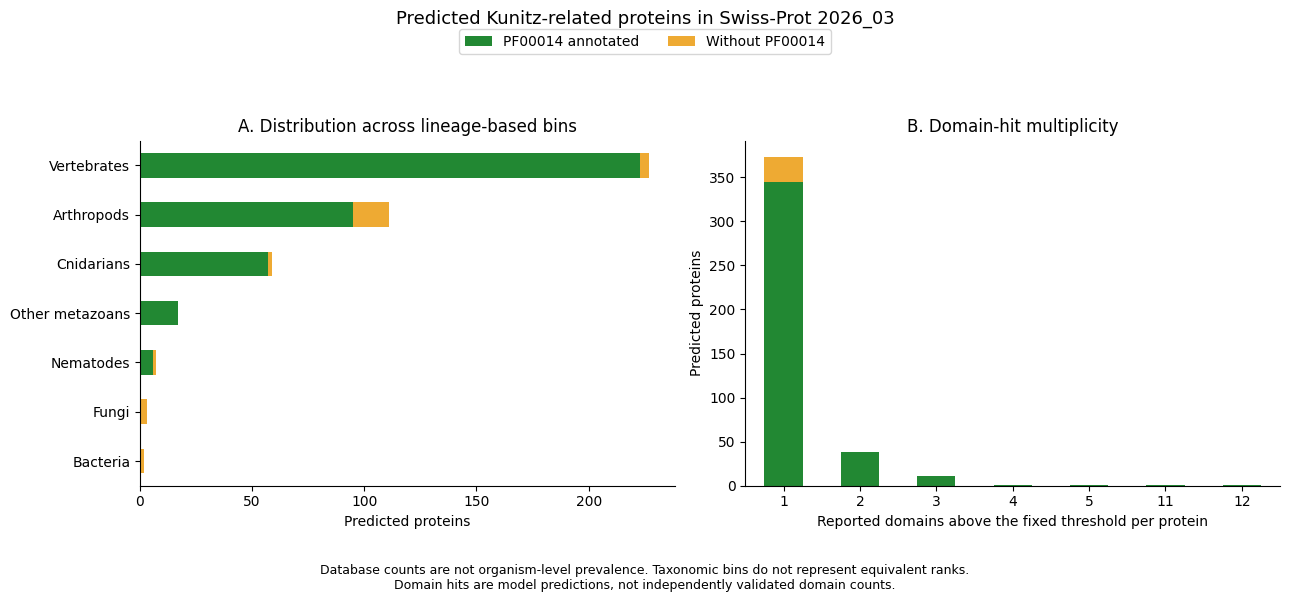


Taxonomic-bin counts:
annotation_group  PF00014_annotated  without_PF00014  total
taxonomic_bin                                              
Vertebrates                     223                4    227
Arthropods                       95               16    111
Cnidarians                       57                2     59
Other metazoans                  17                0     17
Nematodes                         6                1      7
Fungi                             0                3      3
Bacteria                          0                2      2

Reported domains per protein:
annotation_group         PF00014_annotated  without_PF00014
domains_above_threshold                                    
1                                      345               28
2                                       38                0
3                                       11                0
4                                        1                0
5                                        1    

In [154]:
from pathlib import Path
import hashlib
import json

import pandas as pd
import matplotlib.pyplot as plt

print("STEP 69 — Summarize predicted Kunitz distribution")

PROJECT_DIR = Path("/content/kunitz_project")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

scan_pointer = read_json(
    PROJECT_DIR / "results/swissprot_scan/current_scan.json"
)
run_dir = Path(scan_pointer["run_directory"])
pointer_path = run_dir / "distribution/current_metadata.json"
pointer = read_json(pointer_path)

record_path = Path(pointer["record_path"])
table_path = Path(pointer["table_path"])

if sha256_file(record_path) != pointer["record_sha256"]:
    raise ValueError("Metadata record checksum mismatch.")
if sha256_file(table_path) != pointer["table_sha256"]:
    raise ValueError("Metadata table checksum mismatch.")

record = read_json(record_path)
if not record.get("fragment_reference_consistency_verified", False):
    raise ValueError("Run STEP 68 before this summary.")

data = pd.read_csv(table_path, keep_default_na=False)
if data["Entry"].duplicated().any():
    raise ValueError("Duplicate predicted accessions.")

groups = ["PF00014_annotated", "without_PF00014"]
if not data["annotation_group"].isin(groups).all():
    raise ValueError("Unexpected annotation group.")

fragment_flags = data["is_explicit_fragment"].astype(str).str.lower()
if not fragment_flags.isin(["true", "false"]).all():
    raise ValueError("Invalid fragment flags.")
data["is_explicit_fragment"] = fragment_flags.eq("true")

data["domains_above_threshold"] = pd.to_numeric(
    data["domains_above_threshold"], errors="raise"
)
if (
    data["domains_above_threshold"].lt(1).any()
    or data["domains_above_threshold"].mod(1).ne(0).any()
):
    raise ValueError("Invalid above-threshold domain counts.")

# Use mutually exclusive descriptive bins, not equal taxonomic ranks.
def taxonomy_bin(lineage_json):
    lineage = set(json.loads(lineage_json))

    if "Viruses" in lineage:
        return "Viruses"
    if "Bacteria" in lineage:
        return "Bacteria"
    if "Archaea" in lineage:
        return "Archaea"

    if "Eukaryota" in lineage:
        if "Metazoa" in lineage:
            if "Vertebrata" in lineage:
                return "Vertebrates"
            if "Arthropoda" in lineage:
                return "Arthropods"
            if "Nematoda" in lineage:
                return "Nematodes"
            if "Cnidaria" in lineage:
                return "Cnidarians"
            return "Other metazoans"

        if "Fungi" in lineage:
            return "Fungi"
        if "Viridiplantae" in lineage:
            return "Green plants"
        return "Other eukaryotes"

    return "Unresolved lineage"

data["taxonomic_bin"] = data["lineage_json"].map(taxonomy_bin)
data["fragment_group"] = data["is_explicit_fragment"].map({
    True: "Explicit fragment",
    False: "Not explicitly fragment-flagged",
})

taxonomy = pd.crosstab(
    data["taxonomic_bin"], data["annotation_group"]
).reindex(columns=groups, fill_value=0)
taxonomy["total"] = taxonomy.sum(axis=1)
taxonomy = taxonomy.sort_values("total", ascending=False)

organisms = (
    data.groupby(
        ["annotation_group", "taxon_id", "scientific_name"],
        dropna=False,
    )
    .agg(
        predicted_proteins=("Entry", "size"),
        explicit_fragments=("is_explicit_fragment", "sum"),
        reported_domains_above_threshold=("domains_above_threshold", "sum"),
    )
    .reset_index()
    .sort_values(
        ["annotation_group", "predicted_proteins", "scientific_name"],
        ascending=[True, False, True],
    )
)

domain_counts = pd.crosstab(
    data["domains_above_threshold"], data["annotation_group"]
).reindex(columns=groups, fill_value=0).sort_index()

fragment_counts = pd.crosstab(
    data["fragment_group"], data["annotation_group"]
).reindex(columns=groups, fill_value=0)

classification = read_json(
    run_dir / "classification/classification_summary.json"
)

if len(data) != classification["predicted_positive_proteins"]:
    raise ValueError("Protein count disagrees with classification.")
if int(data["domains_above_threshold"].sum()) != classification["domains_above_threshold"]:
    raise ValueError("Domain count disagrees with classification.")
if int(taxonomy["total"].sum()) != len(data):
    raise ValueError("Taxonomic counts do not reconcile.")

output_dir = run_dir / "distribution/summary"
output_dir.mkdir(parents=True, exist_ok=True)

data.to_csv(output_dir / "predictions_with_taxonomic_bins.csv", index=False)
taxonomy.to_csv(output_dir / "taxonomic_bin_counts.csv")
organisms.to_csv(output_dir / "organism_counts.csv", index=False)
domain_counts.to_csv(output_dir / "domains_per_protein_counts.csv")
fragment_counts.to_csv(output_dir / "fragment_counts.csv")

# Produce one figure with taxonomy and domain multiplicity panels.
colors = ["#228833", "#EEAA33"]
legend_labels = ["PF00014 annotated", "Without PF00014"]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

taxonomy_plot = taxonomy[groups].iloc[::-1]
taxonomy_plot.plot.barh(
    stacked=True, color=colors, ax=axes[0], legend=False
)
axes[0].set_xlabel("Predicted proteins")
axes[0].set_ylabel("")
axes[0].set_title("A. Distribution across lineage-based bins")

domain_counts.plot.bar(
    stacked=True, color=colors, ax=axes[1], legend=False, rot=0
)
axes[1].set_xlabel("Reported domains above the fixed threshold per protein")
axes[1].set_ylabel("Predicted proteins")
axes[1].set_title("B. Domain-hit multiplicity")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

handles, _ = axes[1].get_legend_handles_labels()
fig.legend(
    handles, legend_labels,
    loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.96),
)
fig.suptitle(
    f"Predicted Kunitz-related proteins in Swiss-Prot {record['uniprot_release']}",
    fontsize=13,
)
fig.text(
    0.5, 0.015,
    "Database counts are not organism-level prevalence. "
    "Taxonomic bins do not represent equivalent ranks.\n"
    "Domain hits are model predictions, not independently validated domain counts.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.09, 1, 0.88))

figure_paths = []
for extension in ["png", "pdf"]:
    path = output_dir / f"04_predicted_protein_distribution.{extension}"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    figure_paths.append(path)

plt.show()
plt.close(fig)

summary_record = {
    "source_metadata": str(table_path),
    "source_metadata_sha256": sha256_file(table_path),
    "uniprot_release": record["uniprot_release"],
    "predicted_proteins": len(data),
    "explicit_fragments": int(data["is_explicit_fragment"].sum()),
    "distinct_taxon_ids_overall": int(data["taxon_id"].nunique()),
    "reported_domains_above_threshold": int(
        data["domains_above_threshold"].sum()
    ),
    "proteins_with_multiple_domains_above_threshold": int(
        data["domains_above_threshold"].gt(1).sum()
    ),
    "unresolved_lineage_proteins": int(
        data["taxonomic_bin"].eq("Unresolved lineage").sum()
    ),
    "taxonomy_binning": (
        "Mutually exclusive lineage-based descriptive bins; "
        "not equivalent taxonomic ranks."
    ),
    "interpretation_limits": [
        "Protein counts reflect Swiss-Prot sampling and curation.",
        "Taxon IDs may distinguish strains; counts are not necessarily species counts.",
        "Domain multiplicity describes above-threshold HMMER hits.",
        "Predictions without PF00014 remain separate.",
    ],
    "files": [
        {"path": str(path), "sha256": sha256_file(path)}
        for path in [
            output_dir / "predictions_with_taxonomic_bins.csv",
            output_dir / "taxonomic_bin_counts.csv",
            output_dir / "organism_counts.csv",
            output_dir / "domains_per_protein_counts.csv",
            output_dir / "fragment_counts.csv",
            *figure_paths,
        ]
    ],
}
(output_dir / "distribution_summary_record.json").write_text(
    json.dumps(summary_record, indent=2), encoding="utf-8"
)

print("\nTaxonomic-bin counts:")
print(taxonomy.to_string())

print("\nReported domains per protein:")
print(domain_counts.to_string())

print("\nFragment counts:")
print(fragment_counts.to_string())

for group in groups:
    print(f"\nTop 10 organism records — {group}:")
    print(
        organisms.loc[organisms["annotation_group"].eq(group)]
        .head(10)
        .to_string(index=False)
    )

print(
    "\nUnresolved-lineage proteins:",
    summary_record["unresolved_lineage_proteins"],
)
print(f"Results saved to: {output_dir}")


# Synchronize report artifacts with the verified distribution results.
import re
import shutil
from datetime import datetime, timezone


def sync_distribution_documents(project_dir, summary_dir, summary):
    project_dir, summary_dir = Path(project_dir), Path(summary_dir)
    documents = [
        (project_dir / 'README.md', project_dir / 'docs/readme_provenance.json', 'readme_sha256', 'docs/figures/04_predicted_protein_distribution.png'),
        (project_dir / 'report/scientific_report_draft.md', project_dir / 'report/report_provenance.json', 'report_sha256', '../docs/figures/04_predicted_protein_distribution.png'),
    ]
    for document, _, _, _ in documents:
        if not document.is_file():
            raise FileNotFoundError(f'Generate the report and README before STEP 69: {document}')
    # Validate every recorded input before modifying documents.
    for item in summary['files']:
        if sha256_file(item['path']) != item['sha256']:
            raise ValueError(f"Distribution artifact checksum mismatch: {item['path']}")
    tax = pd.read_csv(summary_dir / 'taxonomic_bin_counts.csv', keep_default_na=False)
    domains = pd.read_csv(summary_dir / 'domains_per_protein_counts.csv', keep_default_na=False)
    fragments = pd.read_csv(summary_dir / 'fragment_counts.csv', keep_default_na=False)
    if int(tax['total'].sum()) != summary['predicted_proteins']:
        raise ValueError('Report taxonomic totals do not match the distribution summary.')

    def markdown_table(frame):
        def escape(value):
            return str(value).replace('|', '\\|').replace('\n', ' ')
        return '\n'.join([
            '| ' + ' | '.join(map(escape, frame.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |',
            *['| ' + ' | '.join(map(escape, row)) + ' |' for row in frame.itertuples(index=False, name=None)],
        ])

    section = (
        '## Taxonomic distribution, fragments, and domain multiplicity\n\n'
        f"The Swiss-Prot {summary['uniprot_release']} scan contains "
        f"{summary['predicted_proteins']:,} predicted proteins. The following tables "
        'separate PF00014-annotated proteins from predictions without that annotation.\n\n'
        '### Taxonomic distribution\n\n' + markdown_table(tax) + '\n\n'
        'The bins are mutually exclusive lineage-based categories, not equivalent taxonomic ranks. '
        'Counts reflect database sampling and curation, not natural prevalence. '
        'Predictions without PF00014 require the separate evidence review; fungal and bacterial '
        'predictions must not be interpreted as confirmed expansion of the family.\n\n'
        '### Fragment status\n\n'
        f"There are {summary['explicit_fragments']:,} explicitly fragment-flagged predictions. "
        'Compound flags such as Fragment,Precursor are counted as fragments. '
        'Absence of a fragment flag does not independently establish completeness.\n\n'
        + markdown_table(fragments) + '\n\n'
        '### Domain-hit multiplicity\n\n'
        f"The scan reports {summary['reported_domains_above_threshold']:,} domains above the fixed "
        f"threshold, with {summary['proteins_with_multiple_domains_above_threshold']:,} proteins "
        'having more than one such hit. These are HMMER predictions, not independently '
        'validated domain architectures.\n\n' + markdown_table(domains) + '\n\n'
        '![Taxonomic distribution and domain-hit multiplicity]({figure})\n\n'
        '*Distribution of predicted proteins and above-threshold domain hits, with PF00014 '
        'annotation groups shown separately. The model, decision threshold, evaluation labels, '
        'and reported test metrics are unchanged.*\n'
    )
    start, end = '<!-- DISTRIBUTION_RESULTS_START -->', '<!-- DISTRIBUTION_RESULTS_END -->'
    prepared = []
    for document, provenance_path, checksum_key, figure_link in documents:
        original = document.read_text(encoding='utf-8')
        if original.count(start) != original.count(end) or original.count(start) > 1:
            raise ValueError(f'Malformed distribution section in {document}')
        text = re.sub(re.escape(start) + r'.*?' + re.escape(end), '', original, flags=re.DOTALL)
        block = start + '\n' + section.replace('{figure}', figure_link) + end + '\n'
        marker = next((m for m in ['## References and data resources', '## Resources'] if m in text), None)
        updated = text.replace(marker, block + '\n' + marker, 1) if marker else text.rstrip() + '\n\n' + block
        provenance = read_json(provenance_path) if provenance_path.is_file() else None
        prepared.append((document, provenance_path, checksum_key, original, updated, provenance))

    timestamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    history = project_dir / 'docs/history' / ('distribution_' + timestamp)
    figure_dir = project_dir / 'docs/figures'
    figure_dir.mkdir(parents=True, exist_ok=True)
    for ext in ['png', 'pdf']:
        source = summary_dir / ('04_predicted_protein_distribution.' + ext)
        destination = figure_dir / source.name
        if destination.exists():
            backup = history / destination.relative_to(project_dir)
            backup.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(destination, backup)
        shutil.copy2(source, destination)
        if sha256_file(source) != sha256_file(destination):
            raise ValueError('Copied distribution figure checksum mismatch.')
    changes = []
    for document, provenance_path, checksum_key, original, updated, provenance in prepared:
        backup = history / document.relative_to(project_dir)
        backup.parent.mkdir(parents=True, exist_ok=True)
        backup.write_text(original, encoding='utf-8')
        document.write_text(updated, encoding='utf-8')
        if provenance is not None:
            backup_provenance = history / provenance_path.relative_to(project_dir)
            backup_provenance.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(provenance_path, backup_provenance)
            provenance[checksum_key] = sha256_file(document)
            provenance['distribution_update'] = {
                'summary_path': str(summary_dir / 'distribution_summary_record.json'),
                'summary_sha256': sha256_file(summary_dir / 'distribution_summary_record.json'),
                'updated_at_utc': datetime.now(timezone.utc).isoformat(),
            }
            provenance_path.write_text(json.dumps(provenance, indent=2), encoding='utf-8')
        changes.append({'path': str(document), 'sha256': sha256_file(document), 'backup': str(backup)})
        print(f'Distribution results integrated into: {document}')
    update_path = project_dir / 'docs/distribution_documentation_update.json'
    update_path.write_text(json.dumps({'updated_documents': changes, 'source_summary': str(summary_dir / 'distribution_summary_record.json'), 'source_summary_sha256': sha256_file(summary_dir / 'distribution_summary_record.json')}, indent=2), encoding='utf-8')


sync_distribution_documents(PROJECT_DIR, output_dir, summary_record)
print('STEP 69 COMPLETE — Distribution tables, figure, README, and report synchronized.')


### Conclusions

A profile HMM built from 13 structurally aligned Kunitz fragments detects all positive proteins in the recorded held-out test at a validation-selected threshold of 8.7 bits. Applied to complete Swiss-Prot, it identifies 426 proteins, including every one of the 398 PF00014-annotated entries in the release.

The 28 additional predictions require qualified interpretation: 21 have supporting Kunitz evidence, six are suspected false positives, and one remains unresolved. Short fragments and weak partial matches are particularly important when interpreting predictions near the threshold.

The taxonomic analysis records 227 predictions in vertebrates, 111 in arthropods, 59 in cnidarians, 17 in other metazoans, seven in nematodes, three in fungi, and two in bacteria. All 398 PF00014-annotated predictions fall within the metazoan bins in this dataset. The fungal and bacterial predictions belong to the discordant group and must not be interpreted as confirmed family expansion. Database curation and sampling affect these counts; they are not estimates of natural family prevalence.

#### Scope and limitations

- The structural seed is small and reflects the experimentally available and selected domain intervals.
- NMR fragments are represented by one model in the final alignment.
- Reference labels are annotation-based; missing PF00014 annotation does not prove absence of the family.
- The test uses sampled, nonfragment proteins and does not reproduce the full database's composition.
- Similarity grouping limits close-sequence overlap at the chosen rule but leaves lower-identity homologs across the split.
- Post hoc analyses describe robustness and interpretation; they are not independent replication.
- The model predicts family membership rather than biochemical activity or experimentally verified domain boundaries.

#### Software and data resources

- [RCSB Protein Data Bank](https://www.rcsb.org/) — experimental structures and entity metadata.
- [UniProtKB](https://www.uniprot.org/) — Swiss-Prot sequences, annotations, and taxonomy; release 2026_03 in this analysis.
- [Biopython](https://biopython.org/) — sequence and structural data processing.
- MUSTANG 3.2.4 — multiple structural alignment; Konagurthu et al., *Proteins* 64(3):559–574 (2006).
- [HMMER](http://hmmer.org/) 3.4 — profile construction and sequence searches.
- [MMseqs2](https://github.com/soedinglab/MMseqs2) 15-6f452+ds-2 — local sequence-similarity search.

#### Preserve the completed analysis

The final cell creates and verifies a project backup in Google Drive. Save this notebook separately as well: the notebook contains code and displayed results, while the project archive preserves the generated data and analysis files.

In [155]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import shutil
import stat
import zipfile

from google.colab import drive

print("FINAL BACKUP — Create and verify a complete project backup")

PROJECT_DIR = Path("/content/kunitz_project")
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError("The project directory is missing.")

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

drive.mount("/content/drive")
backup_dir = Path("/content/drive/MyDrive/kunitz_project_backups")
backup_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
archive_name = f"kunitz_project_backup_{timestamp}.zip"
local_archive = Path("/content") / archive_name
drive_archive = backup_dir / archive_name
drive_partial = backup_dir / f"{archive_name}.part"

project_root = PROJECT_DIR.resolve()
files = []
links = []
directories_to_store = []

# Preserve symlinks explicitly instead of following them.
for root, directories, filenames in os.walk(
    PROJECT_DIR, followlinks=False
):
    root_path = Path(root)
    directories.sort()
    filenames.sort()

    for name in directories:
        path = root_path / name
        if path.is_symlink():
            links.append(path)
        else:
            directories_to_store.append(path)

    for name in filenames:
        path = root_path / name
        if path.is_symlink():
            links.append(path)
        elif path.is_file():
            files.append(path)

total_bytes = sum(path.stat().st_size for path in files)
if shutil.disk_usage("/content").free < total_bytes + 100 * 1024**2:
    raise RuntimeError("Insufficient local disk space to create the archive.")

print(f"Regular files: {len(files):,}")
print(f"Symbolic links: {len(links):,}")
print(f"Source file size: {total_bytes / 1024**2:.2f} MiB")

file_records = []
link_records = []

with zipfile.ZipFile(
    local_archive,
    mode="x",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True,
) as archive:

    for path in directories_to_store:
        member = (
            Path(PROJECT_DIR.name) / path.relative_to(PROJECT_DIR)
        ).as_posix() + "/"
        archive.writestr(member, b"")

    for index, path in enumerate(files, start=1):
        relative = path.relative_to(PROJECT_DIR).as_posix()
        source_hash = sha256_file(path)
        archive.write(path, arcname=f"{PROJECT_DIR.name}/{relative}")

        file_records.append({
            "relative_path": relative,
            "size_bytes": path.stat().st_size,
            "sha256": source_hash,
        })

        if index % 500 == 0:
            print(f"Archived {index:,}/{len(files):,} files")

    for path in links:
        relative = path.relative_to(PROJECT_DIR).as_posix()
        target = os.readlink(path)
        target_bytes = os.fsencode(target)

        info = zipfile.ZipInfo(f"{PROJECT_DIR.name}/{relative}")
        info.create_system = 3
        info.external_attr = (stat.S_IFLNK | 0o777) << 16
        info.compress_type = zipfile.ZIP_DEFLATED
        archive.writestr(info, target_bytes)

        try:
            resolved = path.resolve(strict=True)
            target_status = (
                "inside_project"
                if resolved.is_relative_to(project_root)
                else "outside_project"
            )
        except (OSError, RuntimeError):
            target_status = "unresolved_or_broken"

        link_records.append({
            "relative_path": relative,
            "target": target,
            "target_status": target_status,
            "target_text_sha256": hashlib.sha256(target_bytes).hexdigest(),
        })

    manifest = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "original_project_path": str(PROJECT_DIR),
        "files": file_records,
        "symbolic_links": link_records,
        "symlink_policy": (
            "Links are stored as Unix symlinks and listed here. "
            "Linked directories are not traversed. External target contents "
            "are not included. Restore links explicitly from this manifest "
            "if the extraction tool does not preserve symlinks."
        ),
        "notebook_note": "Save the Colab notebook separately.",
    }
    archive.writestr(
        "backup_file_manifest.json",
        json.dumps(manifest, indent=2),
    )

print("Verifying archived files and symbolic links...")

with zipfile.ZipFile(local_archive) as archive:
    damaged = archive.testzip()
    if damaged is not None:
        raise ValueError(f"Archive integrity check failed: {damaged}")

    for item in file_records:
        member = f"{PROJECT_DIR.name}/{item['relative_path']}"
        digest = hashlib.sha256()
        with archive.open(member) as handle:
            for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(chunk)
        if digest.hexdigest() != item["sha256"]:
            raise ValueError(f"Archived file checksum mismatch: {member}")

    for item in link_records:
        member = f"{PROJECT_DIR.name}/{item['relative_path']}"
        if hashlib.sha256(archive.read(member)).hexdigest() != item["target_text_sha256"]:
            raise ValueError(f"Archived link mismatch: {member}")

local_hash = sha256_file(local_archive)

print("Copying archive to Google Drive...")
shutil.copyfile(local_archive, drive_partial)

print("Verifying the Google Drive copy...")
if sha256_file(drive_partial) != local_hash:
    raise ValueError("Google Drive copy checksum mismatch.")

drive_partial.rename(drive_archive)

external_links = [
    item for item in link_records
    if item["target_status"] == "outside_project"
]
unresolved_links = [
    item for item in link_records
    if item["target_status"] == "unresolved_or_broken"
]

receipt = {
    "archive_path": str(drive_archive),
    "archive_sha256": local_hash,
    "regular_files": len(file_records),
    "symbolic_links": len(link_records),
    "external_link_count": len(external_links),
    "unresolved_link_count": len(unresolved_links),
    "archive_and_copy_verified": True,
    "external_target_contents_included": False,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}
receipt_path = backup_dir / f"{archive_name}.verification.json"
receipt_path.write_text(
    json.dumps(receipt, indent=2), encoding="utf-8"
)

local_archive.unlink()

print(f"\nBackup: {drive_archive}")
print(f"Regular files verified: {len(file_records):,}")
print(f"Symbolic links preserved: {len(link_records):,}")
print(f"External links: {len(external_links)}")
print(f"Unresolved or broken links: {len(unresolved_links)}")

for item in external_links + unresolved_links:
    print(f"Link recorded: {item['relative_path']} -> {item['target']}")

print(f"Verification receipt: {receipt_path}")
print("FINAL BACKUP COMPLETE — Project files and link records backed up and verified.")
print("Save the Colab notebook separately.")

FINAL BACKUP — Create and verify a complete project backup
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Regular files: 2,270
Symbolic links: 2
Source file size: 1680.73 MiB
Archived 500/2,270 files
Archived 1,000/2,270 files
Archived 1,500/2,270 files
Archived 2,000/2,270 files
Verifying archived files and symbolic links...
Copying archive to Google Drive...
Verifying the Google Drive copy...

Backup: /content/drive/MyDrive/kunitz_project_backups/kunitz_project_backup_20261107T213430_789701Z.zip
Regular files verified: 2,270
Symbolic links preserved: 2
External links: 0
Unresolved or broken links: 0
Verification receipt: /content/drive/MyDrive/kunitz_project_backups/kunitz_project_backup_20261107T213430_789701Z.zip.verification.json
FINAL BACKUP COMPLETE — Project files and link records backed up and verified.
Save the Colab notebook separately.
